<a href="https://colab.research.google.com/github/BenjaminOrtizO/Estudio/blob/main/Entrega1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#CASE OF STUDY: BEBIDAS MAIPO S.A.
##Parte 1: Calidad y Pronóstico.
###Cargar el repositorio


In [1]:
import os
import base64
import subprocess
from pathlib import Path
from google.colab import userdata

# 1. Configuración
repo = Path("/content/CaseStudy")
url = "https://github.com/BenjaminOrtizO/CaseStudy.git"

# 2. Comprobar si el repositorio ya existe
if repo.exists():

    if not (repo / ".git").is_dir():
        raise RuntimeError(
            "La carpeta CaseStudy existe, pero no es un repositorio Git."
        )

    print("Repositorio existente. Se reutilizará sin actualizar.")

else:

    # 3. Obtener credenciales únicamente cuando se necesita clonar
    token = userdata.get("HolaMundo")

    if not token:
        raise RuntimeError(
            "Configura el secreto HolaMundo en Google Colab."
        )

    credenciales = base64.b64encode(
        f"x-access-token:{token}".encode()
    ).decode()

    # 4. Clonar repositorio privado
    resultado = subprocess.run(
        [
            "git",
            "-c",
            f"http.extraheader=AUTHORIZATION: basic {credenciales}",
            "clone",
            url,
            str(repo)
        ],
        capture_output=True,
        text=True
    )

    if resultado.returncode != 0:
        raise RuntimeError(
            "No se pudo clonar el repositorio privado. "
            "Verifica el token y sus permisos de lectura."
        )

    print("Repositorio clonado correctamente.")

# 5. Establecer directorio de trabajo
os.chdir(repo)

print("Directorio de trabajo:", os.getcwd())

Repositorio existente. Se reutilizará sin actualizar.
Directorio de trabajo: /content/CaseStudy


In [2]:
# Instalar dependencias
%pip install -r requirements.txt

#IMPORTACIONES UTILIZADAS

In [3]:
#Parte A
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
from scipy import stats

#Parte B
import matplotlib.dates as mdates
from statsforecast import StatsForecast
from statsforecast.models import AutoETS
from statsmodels.tsa.statespace.sarimax import SARIMAX # Importar el modelo SARIMA/SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import norm

# Descarga de archivos: solo disponible en Google Colab
try:
    from google.colab import files
except ImportError:
    files = None


###Semilla para reproducibilidad

In [4]:
np.random.seed(42)

###Cargar los datos (Parte A)


In [5]:
# Datos maestros
maestro_sku = pd.read_csv('Datos/maestro_sku.csv')
inventario_inicial = pd.read_csv('Datos/inventario_inicial.csv')

# Demanda y capacidad
ventas_semanal = pd.read_csv('Datos/demanda_semanal.csv', parse_dates=['fecha_lunes'])
capacidad_horizonte = pd.read_csv('Datos/capacidad_horizonte.csv')
compromisos_semana_focal = pd.read_csv('Datos/compromisos_semana_focal.csv')

# Calidad
calidad_atributos = pd.read_csv('Datos/calidad_atributos.csv' , parse_dates=['fecha'])
calidad_llenado = pd.read_csv('Datos/calidad_llenado.csv', parse_dates=['fecha'])
especificaciones_calidad = pd.read_csv('Datos/especificaciones_calidad.csv')

# Configuración
setups_cip = pd.read_csv('Datos/setups_cip.csv')

# Metadatos
with open('Datos/metadatos.json', 'r', encoding='utf-8') as f:
    metadatos = json.load(f)

metadatos #equivalente a print en Jupyter

{'empresa': 'Bebidas del Maipo S.A.',
 'semilla': 20260923,
 'n_semanas_historia': 156,
 'fin_historia': '2026-09-21',
 'horizonte_planificacion': 13,
 'semana_focal_secuenciamiento': 12,
 'fecha_semana_focal': '2026-12-14',
 'n_sku': 9,
 'familias': ['CIT', 'FUN', 'NEC']}

In [6]:
calidad_llenado.head()

,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL
0,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,1,500.86
1,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,2,502.11
2,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,3,503.12
3,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,4,502.60
4,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,5,499.11


In [7]:
calidad_atributos.head()

,fecha,semana_registro,turno,linea,sku,n_inspeccionadas,n_defectuosas,causa_principal
0,2026-07-20,1,A (06-14),L1,FUN-B05,238,1,Envase deformado
1,2026-07-20,1,B (14-22),L1,CIT-L05,182,3,Etiqueta
2,2026-07-21,1,A (06-14),L1,NEC-D05,190,4,Envase deformado
3,2026-07-21,1,B (14-22),L1,CIT-L05,194,3,Nivel de llenado
4,2026-07-22,1,A (06-14),L1,CIT-L05,190,8,Etiqueta


In [8]:
especificaciones_calidad.head()

,formato_L,nominal_mL,LIE_mL,LSE_mL,tolerancia_oiml_mL,limite_legal_inferior_mL
0,0.5,500.0,492.0,508.0,15.0,485.0
1,1.5,1500.0,1485.0,1515.0,22.5,1477.5
2,3.0,3000.0,2975.0,3025.0,45.0,2955.0


In [9]:
maestro_sku.head()

,sku,familia,nombre_familia,sabor,formato_L,botellas_por_caja,litros_por_caja,linea_envasado,tasa_envasado_cajas_h,costo_variable_caja_clp,precio_lista_caja_clp,costo_inventario_caja_semana_clp,penalidad_atraso_caja_semana_clp
0,NEC-D05,NEC,Nectares con pulpa,Durazno,0.5,12,6.0,L1,180,3840,6620,95,1400
1,NEC-D15,NEC,Nectares con pulpa,Durazno,1.5,6,9.0,L2,210,5760,9930,95,1400
2,NEC-D30,NEC,Nectares con pulpa,Durazno,3.0,4,12.0,L2,130,7680,13240,95,1400
3,CIT-L05,CIT,Citricos gasificados,Limon,0.5,12,6.0,L1,180,2820,5320,95,1400
4,CIT-L15,CIT,Citricos gasificados,Limon,1.5,6,9.0,L2,210,4230,7980,95,1400


In [10]:
ventas_semanal.head()

,semana,fecha_lunes,anio_iso,semana_iso,sku,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
0,1,2023-10-02,2023,40,NEC-D05,1209.0,0.0,0,6620,6620
1,2,2023-10-09,2023,41,NEC-D05,1095.0,0.0,0,6620,6620
2,3,2023-10-16,2023,42,NEC-D05,1345.0,0.0,0,6620,6620
3,4,2023-10-23,2023,43,NEC-D05,1888.0,0.0,1,6620,4819
4,5,2023-10-30,2023,44,NEC-D05,991.0,0.0,0,6620,6620


In [11]:
calidad_llenado['fecha'] = pd.to_datetime(calidad_llenado['fecha'])
calidad_atributos['fecha'] = pd.to_datetime(calidad_atributos['fecha'])
ventas_semanal['fecha_lunes'] = pd.to_datetime(ventas_semanal['fecha_lunes'])


In [12]:
# 1. ventas semanales
ventas_semanal = ventas_semanal.sort_values(['semana', 'sku']).reset_index(drop=True)


# 2. Calidad por atributos
orden_turnos = {'A (06-14)': 1, 'B (14-22)': 2, 'C (22-06)': 3}
calidad_atributos['orden_turno'] = calidad_atributos['turno'].map(orden_turnos)
calidad_atributos = calidad_atributos.sort_values(['fecha', 'orden_turno']).reset_index(drop=True)


# 3. Calidad de llenado
calidad_llenado['fecha_hora'] = (calidad_llenado['fecha'] +pd.to_timedelta(calidad_llenado['hora'] + ':00'))

# Corregir madrugada del turno C
condicion = ((calidad_llenado['turno'] == 'C (22-06)') &(calidad_llenado['hora'] < '06:00'))
calidad_llenado.loc[condicion, 'fecha_hora'] += pd.Timedelta(days=1)
calidad_llenado = calidad_llenado.sort_values(['fecha_hora', 'subgrupo', 'n_obs']).reset_index(drop=True)

##Preparación de los datos.


In [13]:
print('TIPO DE DATOS','\n')
print('Llenado \n', calidad_llenado.dtypes)
print('\n\n\n' , '='*300, '\n\n\n')
print('Atributos \n',calidad_atributos.dtypes)
print('\n\n\n' , '='*300, '\n\n\n')
print('Especificaciones \n',especificaciones_calidad.dtypes)
print('\n\n\n' , '='*300, '\n\n\n')
print('Master SKU \n',maestro_sku.dtypes)
print('\n\n\n' , '='*300, '\n\n\n')
print('Ventas \n',ventas_semanal.dtypes)
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')


print('VALORES NULOS','\n')
print("Llenado \nValores nulos en calidad_llenado:\n", calidad_llenado.isnull().sum())
print("Atributos \nValores nulos en calidad_atributos:\n", calidad_atributos.isnull().sum())
print("Especificaciones \nValores nulos en especificaciones_calidad:\n", especificaciones_calidad.isnull().sum())
print("Master SKU \nValores nulos en maestro_sku:\n", maestro_sku.isnull().sum())
print("Ventas Semanal \nValores nulos en ventas_semanal:\n", ventas_semanal.isnull().sum())

print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')


print('VALORES DUPLICADOS', '\n')
print('Llenado',"\nFilas duplicadas en calidad_llenado:", calidad_llenado.duplicated().sum())
print('\n\n\n' , '='*300, '\n\n\n')
print('Atributos',"\nFilas duplicadas en calidad_atributos:", calidad_atributos.duplicated().sum())
print('\n\n\n' , '='*300, '\n\n\n')
print('Especificaciones',"\nFilas duplicadas en especificaciones_calidad:", especificaciones_calidad.duplicated().sum())
print('\n\n\n' , '='*300, '\n\n\n')
print('Master SKU',"\nFilas duplicadas en maestro_sku:", maestro_sku.duplicated().sum())
print('\n\n\n' , '='*300, '\n\n\n')
print('Ventas Semanal',"\nFilas duplicadas en ventas_semanal (ventas):", ventas_semanal.duplicated().sum())




TIPO DE DATOS 

Llenado 
 subgrupo                    int64
fecha              datetime64[ns]
semana_registro             int64
turno                      object
linea                      object
sku                        object
formato_L                 float64
hora                       object
n_obs                       int64
volumen_mL                float64
fecha_hora         datetime64[ns]
dtype: object






Atributos 
 fecha               datetime64[ns]
semana_registro              int64
turno                       object
linea                       object
sku                         object
n_inspeccionadas             int64
n_defectuosas                int64
causa_principal             object
orden_turno                  int64
dtype: object






Especificaciones 
 formato_L                   float64
nominal_mL                  float64
LIE_mL                      float64
LSE_mL                      float64
tolerancia_oiml_mL          float64
limite_legal_inferior_mL    float6

In [14]:
print('Llenado')
calidad_llenado.info()
print('\n\n\n' , '='*300, '\n\n\n')
print(calidad_llenado.describe())
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')

print('Atributos')
calidad_atributos.info()
print('\n\n\n' , '='*300, '\n\n\n')
print(calidad_atributos.describe())
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')

print('Especificaciones')
especificaciones_calidad.info()
print('\n\n\n' , '='*300, '\n\n\n')
print(especificaciones_calidad.describe())
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')

print('Master SKU')
maestro_sku.info()
print('\n\n\n' , '='*300, '\n\n\n')
print(maestro_sku.describe())
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')

print('Ventas Semanal')
ventas_semanal.info()
print('\n\n\n' , '='*300, '\n\n\n')
print(ventas_semanal.describe())
print('\n\n\n' , '='*300, '\n\n\n')
print('\n\n\n' , '='*300, '\n\n\n')



Llenado
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   subgrupo         4200 non-null   int64         
 1   fecha            4200 non-null   datetime64[ns]
 2   semana_registro  4200 non-null   int64         
 3   turno            4200 non-null   object        
 4   linea            4200 non-null   object        
 5   sku              4200 non-null   object        
 6   formato_L        4200 non-null   float64       
 7   hora             4200 non-null   object        
 8   n_obs            4200 non-null   int64         
 9   volumen_mL       4200 non-null   float64       
 10  fecha_hora       4200 non-null   datetime64[ns]
dtypes: datetime64[ns](2), float64(2), int64(3), object(4)
memory usage: 361.1+ KB






          subgrupo                          fecha  semana_registro  \
count  4200.000000                   

### -Como se puede ver solo existen datos faltantes en el dataframe de ventas.

### -En otras palabras, más adelante se debe tomar una decisión respecto a ello.

### -No parece haber valores imposibles.

### -Usar boxplots o revisar si existen valores atípicos usando Rangos IQR


In [15]:
df_auxiliar1 = calidad_llenado.groupby(['formato_L'])
df_auxiliar1['volumen_mL'].describe()

,count,mean,std,min,25%,50%,75%,max
formato_L,,,,,,,,
0.5,1200.0,504.093592,2.605536,495.76,502.2675,504.165,505.940,512.19
1.5,1440.0,1504.601063,5.423900,1488.80,1501.2450,1504.240,1507.535,1525.19
3.0,1560.0,3008.501160,8.808310,2974.20,3002.6025,3008.160,3014.455,3036.85


##A simple vista no parece haber valores imposibles o atípicos.

In [16]:
print("Subgrupos con cantidad distinta de 5:",
      (calidad_llenado.groupby('subgrupo').size() != 5).sum())

Subgrupos con cantidad distinta de 5: 0


In [17]:
calidad_llenado.head()

,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL,fecha_hora
0,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,1,500.86,2026-07-20 06:00:00
1,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,2,502.11,2026-07-20 06:00:00
2,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,3,503.12,2026-07-20 06:00:00
3,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,4,502.60,2026-07-20 06:00:00
4,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,5,499.11,2026-07-20 06:00:00


# Parte A: Control estadístico y capacidad de proceso



## A.0 Validación del sistema de medición (MSA)
####Previo a establecer los límites se debe saber si el instrumento está midiendo de manera apropiada. Para ello se debe realizar un análisis de MSA.

####Sin embargo, la estructura de los datos no permite separar las fuentes de variación necesarias para el análisis R&R. Así, se procede a establecer los límites utilizando las cartas de control.

####En el presente caso los subgrupos están establecidos con un n = 5 botellas, esto tiene sentido en el contexto del problema pues se está midiendo el volumen de llenado de las botellas.

In [18]:
# Agrupación base
calidad_llenado_sg = calidad_llenado.groupby(['linea', 'formato_L', 'subgrupo', 'semana_registro', 'turno'])

# Calcular media y rango en una sola pasada
df_subgrupos = calidad_llenado_sg['volumen_mL'].agg(x_mean_sg = 'mean',rango_sg = lambda x: x.max() - x.min()).reset_index()

#Definir las Fases I y II. Fase I = semana 1 (la clase recomienda al menos 20 a 25 subgrupos).
df_subgrupos['fase'] = np.where(df_subgrupos['semana_registro'] <= 1, 'Fase I', 'Fase II')

print("Dimensión de subgrupos generados:", df_subgrupos.shape)
print("\nNumero de subgrupos en cada fase y formato")
display(df_subgrupos.groupby(['linea', 'formato_L', 'fase']).size().reset_index(name='cantidad_subgrupos'))

# La semana 1 entrega 24, 20 y 40 subgrupos (cumple el mínimo recomendado) y deja el 90 % de los datos para la Fase II.
print('La Fase I (semana 1) cumple el mínimo recomendado de 20 a 25 subgrupos por combinación.')

Dimensión de subgrupos generados: (840, 8)

Numero de subgrupos en cada fase y formato


,linea,formato_L,fase,cantidad_subgrupos
0,L1,0.5,Fase I,24
1,L1,0.5,Fase II,216
2,L2,1.5,Fase I,20
3,L2,1.5,Fase II,268
4,L2,3.0,Fase I,40
5,L2,3.0,Fase II,272


La Fase I (semana 1) cumple el mínimo recomendado de 20 a 25 subgrupos por combinación.


## A.1 Cartas de control X̄–R: Fase I
####Como se vio antes todos los subgrupos tienen 5 valores.
####Así, procedemos a usar las constantes conocidas para n = 5
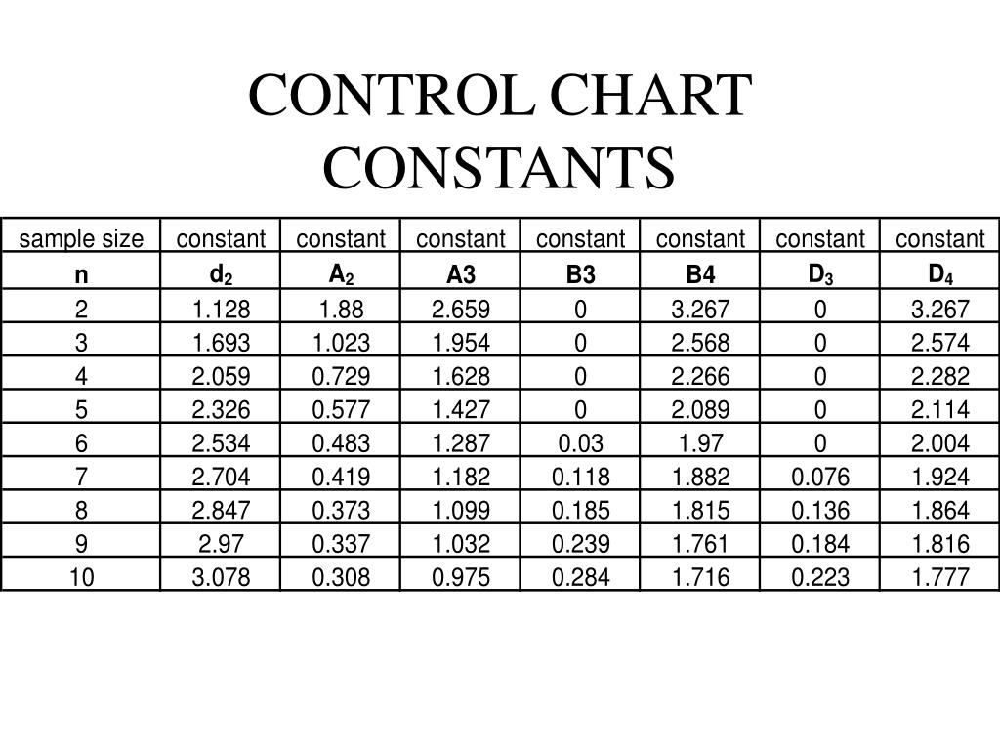

##Fase I: límites de prueba, reglas de decisión y diagnóstico de señales

In [19]:
# 1. Definir las constantes para subgrupos de n=5
A2 = 0.577
D3 = 0.000
D4 = 2.114

# 2. Filtrar solo los datos de la Fase I para calcular la línea base
fase1 = df_subgrupos[df_subgrupos['fase'] == 'Fase I'].copy()

# Diagnóstico de causa asignable (se define después de revisar las señales de la base)
TURNO_CAUSA_FASE1 = 'C (22-06)'

diagnostico_fase1 = []
iteracion = 0

# 3. Calcular límites de prueba, aplicar las reglas de decisión (1 y 4) y diagnosticar cada señal.
# Solo se excluyen del cálculo los subgrupos con causa asignable; se repite hasta que no quede ninguno.
while True:
    iteracion = iteracion + 1

    # Calcular X_doble_barra y R_barra por línea y formato
    df_limites = fase1.groupby(['linea', 'formato_L']).agg(
        x_doble_barra=('x_mean_sg', 'mean'),
        R_barra=('rango_sg', 'mean')
    ).reset_index()

    # Límites de Control para la Carta X-barra y la Carta R
    df_limites['LCS_X'] = df_limites['x_doble_barra'] + A2 * df_limites['R_barra']
    df_limites['LCI_X'] = df_limites['x_doble_barra'] - A2 * df_limites['R_barra']
    df_limites['LC_X'] = df_limites['x_doble_barra']

    df_limites['LCS_R'] = D4 * df_limites['R_barra']
    df_limites['LCI_R'] = D3 * df_limites['R_barra']
    df_limites['LC_R'] = df_limites['R_barra']

    # Aplicar las mismas reglas que en la Fase II
    revision = []

    for (linea, formato), g in fase1.merge(
        df_limites, on=['linea', 'formato_L']
    ).groupby(['linea', 'formato_L']):

        g = g.sort_values('subgrupo').copy()

        # Regla 1: punto fuera de los límites de control
        g['regla_1'] = (
            (g['x_mean_sg'] > g['LCS_X']) |
            (g['x_mean_sg'] < g['LCI_X']) |
            (g['rango_sg'] > g['LCS_R']) |
            (g['rango_sg'] < g['LCI_R'])
        )

        # Regla 4: ocho puntos consecutivos al mismo lado de la línea central
        sobre = (g['x_mean_sg'] > g['x_doble_barra']).astype(int)
        bajo = (g['x_mean_sg'] < g['x_doble_barra']).astype(int)

        g['regla_4'] = (
            (sobre.rolling(8).sum() == 8) |
            (bajo.rolling(8).sum() == 8)
        )

        revision.append(g)

    revision = pd.concat(revision)

    # Identificar las señales
    senales = revision[revision['regla_1'] | revision['regla_4']].copy()

    senales['iteracion'] = iteracion

    senales['decision'] = np.where(senales['turno'] == TURNO_CAUSA_FASE1,'Se excluye (causa asignable: turno C)','Se mantiene (sin causa identificada)')

    diagnostico_fase1.append(senales)

    # Identificar los subgrupos con causa asignable
    con_causa = senales[senales['turno'] == TURNO_CAUSA_FASE1]

    if con_causa.empty:
        break  # No quedan señales con causa asignable

    # Excluir los subgrupos identificados
    fase1 = fase1[
        ~fase1['subgrupo'].isin(con_causa['subgrupo'])].copy()


# 4. Mostrar el diagnóstico de las señales de la Fase I

if any(not df.empty for df in diagnostico_fase1):
    diagnostico_fase1 = pd.concat(diagnostico_fase1).drop_duplicates(['linea', 'formato_L', 'subgrupo'])
    print("Diagnóstico de las señales en la Fase I:")
    display(diagnostico_fase1[['iteracion', 'linea', 'formato_L', 'subgrupo','semana_registro', 'turno','x_mean_sg', 'rango_sg','regla_1', 'regla_4', 'decision']])

else:
    print("No se detectaron señales en la Fase I.")


print("\nSubgrupos que quedan en la base por combinación:")
display(fase1.groupby(['linea', 'formato_L']).size().reset_index(name='subgrupos_base'))


# 5. Mostrar la tabla final con los límites calculados
print("\nLímites de Control establecidos con Fase I (Semana 1, revisada):")
display(df_limites)

Diagnóstico de las señales en la Fase I:


,iteracion,linea,formato_L,subgrupo,semana_registro,turno,x_mean_sg,rango_sg,regla_1,regla_4,decision
24,1,L2,1.5,33,1,C (22-06),1505.642,25.95,True,False,Se excluye (causa asignable: turno C)
51,1,L2,3.0,32,1,B (14-22),3004.786,21.70,False,True,Se mantiene (sin causa identificada)
64,1,L2,3.0,57,1,C (22-06),3023.588,21.08,True,False,Se excluye (causa asignable: turno C)
24,2,L2,1.5,34,1,C (22-06),1510.594,9.48,True,False,Se excluye (causa asignable: turno C)



Subgrupos que quedan en la base por combinación:


,linea,formato_L,subgrupos_base
0,L1,0.5,24
1,L2,1.5,18
2,L2,3.0,39



Límites de Control establecidos con Fase I (Semana 1, revisada):


,linea,formato_L,x_doble_barra,R_barra,LCS_X,LCI_X,LC_X,LCS_R,LCI_R,LC_R
0,L1,0.5,502.476833,4.277917,504.945191,500.008475,502.476833,9.043516,0.0,4.277917
1,L2,1.5,1503.846556,10.281111,1509.778757,1497.914354,1503.846556,21.734269,0.0,10.281111
2,L2,3.0,3008.752974,19.122051,3019.786398,2997.719551,3008.752974,40.424016,0.0,19.122051


# A.2 Fase II: reglas de decisión y causas asignables

In [20]:
# 1. Unir los límites congelados al dataset completo de subgrupos
# Se agrega x_doble_barra: la línea central se necesita para la Regla 4
df_fase2 = pd.merge(df_subgrupos,df_limites[['linea', 'formato_L', 'x_doble_barra','LCS_X', 'LCI_X', 'LCS_R', 'LCI_R']],on=['linea', 'formato_L'],how='left')

# 2. Aplicar la Regla 1 (Punto fuera de los límites de control en la carta X o R)
df_fase2['alerta_X'] = np.where((df_fase2['x_mean_sg'] > df_fase2['LCS_X']) |(df_fase2['x_mean_sg'] < df_fase2['LCI_X']),True, False)

df_fase2['alerta_R'] = np.where((df_fase2['rango_sg'] > df_fase2['LCS_R']) |(df_fase2['rango_sg'] < df_fase2['LCI_R']),True, False)

# 3. Aplicar la Regla 4 (8 puntos consecutivos al mismo lado de la línea central, solo carta X)
grupos = []

for (linea, formato), g in df_fase2[df_fase2['fase'] == 'Fase II'].groupby(['linea', 'formato_L']):
    g = g.sort_values(['semana_registro', 'subgrupo']).copy()
    sobre = (g['x_mean_sg'] > g['x_doble_barra']).astype(int)
    bajo = (g['x_mean_sg'] < g['x_doble_barra']).astype(int)
    g['regla_4'] = ((sobre.rolling(8).sum() == 8) |(bajo.rolling(8).sum() == 8))
    grupos.append(g)

df_fase2 = df_fase2.merge(pd.concat(grupos)[['linea', 'formato_L', 'subgrupo', 'regla_4']],on=['linea', 'formato_L', 'subgrupo'],how='left')

df_fase2['regla_4'] = (df_fase2['regla_4'].astype('boolean').fillna(False).astype(bool))

# Un subgrupo tiene señal si activa cualquiera de las reglas
df_fase2['alerta'] = df_fase2[['alerta_X', 'alerta_R', 'regla_4']].any(axis=1)

# 4. Filtrar para ver SOLO las señales detectadas durante el monitoreo (Fase II)
alertas = df_fase2[(df_fase2['fase'] == 'Fase II') &(df_fase2['alerta'] == True)]

print(f"Total de subgrupos con señal en Fase II (Reglas 1 y 4): {len(alertas)}")

# 5. Resumen de señales por regla y combinación
print("\n\n\nSeñales por regla (un subgrupo puede activar más de una):")
display(df_fase2[df_fase2['fase'] == 'Fase II'].groupby(['linea', 'formato_L'])[['alerta_X', 'regla_4', 'alerta_R', 'alerta']].sum())

# 6. Cruce de las señales con los campos disponibles, para buscar la causa asignable
print("\n\n\nSubgrupos con señal por turno:")

display(alertas.groupby(['linea', 'formato_L', 'turno']).size().unstack(fill_value=0))

print("\n\n\nSubgrupos con señal por semana:")

display(alertas.groupby(['linea', 'formato_L', 'semana_registro']).size().unstack(fill_value=0))

# 7. Comparación por turno: media, rango medio y % de subgrupos con señal en Fase II
resumen_turno = df_fase2.groupby(['linea', 'formato_L', 'turno']).agg(media_x=('x_mean_sg', 'mean'),rango_medio=('rango_sg', 'mean'))

f2 = df_fase2[df_fase2['fase'] == 'Fase II']

resumen_turno['subgrupos_fase2'] = f2.groupby(['linea', 'formato_L', 'turno']).size()

resumen_turno['con_senal'] = f2.groupby(['linea', 'formato_L', 'turno'])['alerta'].sum()

resumen_turno['%_con_senal'] = (resumen_turno['con_senal'] /resumen_turno['subgrupos_fase2'] * 100)

print("\n\n\nComparación por turno:")
display(resumen_turno)

# Mostrar una muestra de las alertas
display(alertas.head(15))

Total de subgrupos con señal en Fase II (Reglas 1 y 4): 165



Señales por regla (un subgrupo puede activar más de una):


alerta_X  regla_4  alerta_R  alerta
linea formato_L                                     
L1    0.5             102      106         3     122
L2    1.5              17        9        13      35
      3.0               1        1         6       8




Subgrupos con señal por turno:


turno            A (06-14)  B (14-22)  C (22-06)
linea formato_L                                 
L1    0.5               59         63          0
L2    1.5                9          1         25
      3.0                0          3          5




Subgrupos con señal por semana:


semana_registro  2   3   4   5   6   7   8   9   10
linea formato_L                                    
L1    0.5         2   2   0   0  23  24  23  24  24
L2    1.5         2  11   3   2   4   3   2   2   6
      3.0         0   1   1   3   1   0   1   1   0




Comparación por turno:


media_x  rango_medio  subgrupos_fase2  \
linea formato_L turno                                                  
L1    0.5       A (06-14)   504.023250     4.847000              108   
                B (14-22)   504.163933     4.754083              108   
L2    1.5       A (06-14)  1503.170556    10.256759               96   
                B (14-22)  1503.616974    10.761184               76   
                C (22-06)  1506.805731    13.936538               96   
      3.0       A (06-14)  3007.395783    19.161957               84   
                B (14-22)  3007.665355    18.523387              104   
                C (22-06)  3010.640063    22.703958               84   

                           con_senal  %_con_senal  
linea formato_L turno                              
L1    0.5       A (06-14)         59    54.629630  
                B (14-22)         63    58.333333  
L2    1.5       A (06-14)          9     9.375000  
                B (14-22)          1     1.315789  
                C (22-06)         25    26.041667  
      3.0       A (06-14)          0     0.000000  
                B (14-22)          3     2.884615  
                C (22-06)          5     5.952381

,linea,formato_L,subgrupo,semana_registro,turno,x_mean_sg,rango_sg,fase,x_doble_barra,LCS_X,LCI_X,LCS_R,LCI_R,alerta_X,alerta_R,regla_4,alerta
31,L1,0.5,92,2,B (14-22),502.946,10.06,Fase II,502.476833,504.945191,500.008475,9.043516,0.0,False,True,True,True
37,L1,0.5,98,2,B (14-22),505.110,5.02,Fase II,502.476833,504.945191,500.008475,9.043516,0.0,True,False,False,True
54,L1,0.5,175,3,B (14-22),503.364,9.27,Fase II,502.476833,504.945191,500.008475,9.043516,0.0,False,True,False,True
65,L1,0.5,186,3,A (06-14),501.172,9.79,Fase II,502.476833,504.945191,500.008475,9.043516,0.0,False,True,False,True
120,L1,0.5,421,6,A (06-14),507.106,4.90,Fase II,502.476833,504.945191,500.008475,9.043516,0.0,True,False,False,True
121,L1,0.5,422,6,A (06-14),506.174,5.16,Fase II,502.476833,504.945191,500.008475,9.043516,0.0,True,False,False,True
123,L1,0.5,424,6,A (06-14),505.794,4.43,Fase II,502.476833,504.945191,500.008475,9.043516,0.0,True,False,False,True
124,L1,0.5,425,6,B (14-22),506.274,4.38,Fase II,502.476833,504.945191,500.008475,9.043516,0.0,True,False,False,True
125,L1,0.5,426,6,B (14-22),505.430,4.96,Fase II,502.476833,504.945191,500.008475,9.043516,0.0,True,False,False,True
126,L1,0.5,427,6,B (14-22),506.920,4.06,Fase II,502.476833,504.945191,500.008475,9.043516,0.0,True,False,False,True


##Cartas X̄–R con las señales de la Fase II (figuras del informe)

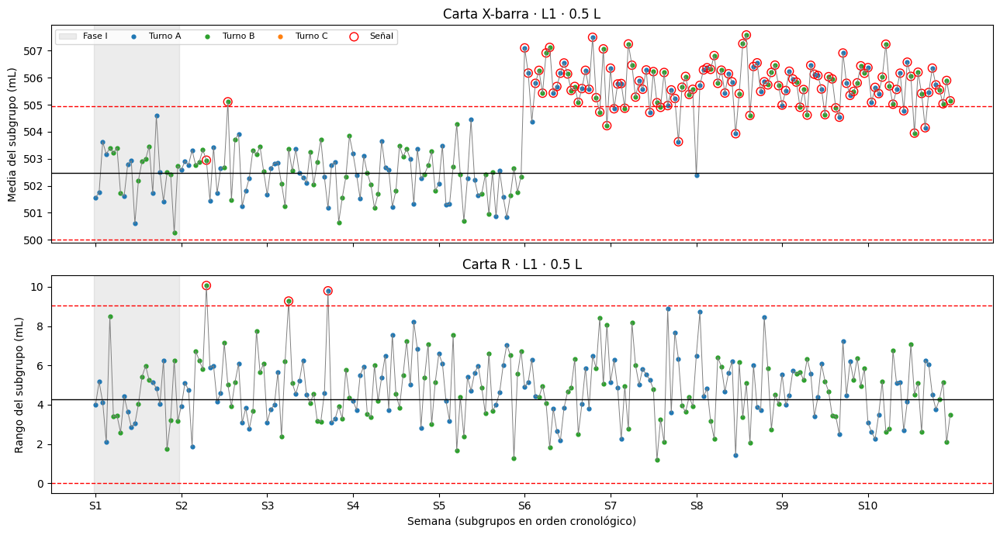

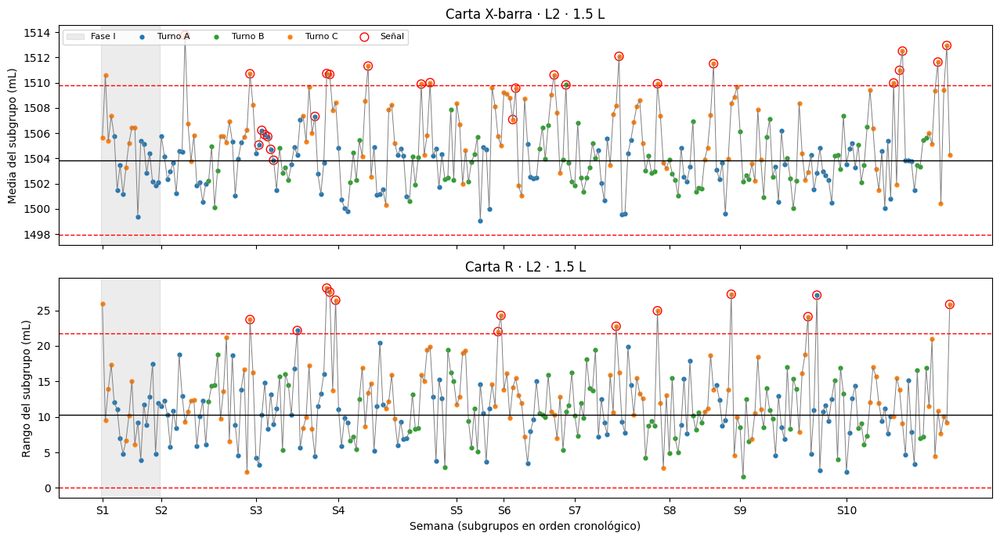

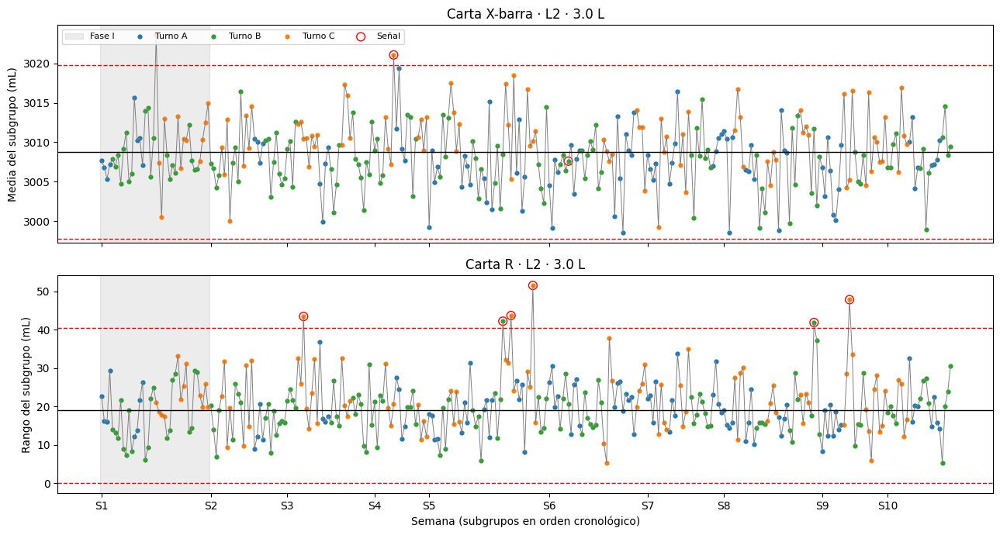

In [21]:
# GRÁFICOS PARA EL INFORME: Cartas X-R con turnos y señales (reglas 1 y 4)
colores_turno = {'A (06-14)': 'tab:blue', 'B (14-22)': 'tab:green', 'C (22-06)': 'tab:orange'}

for (linea, formato), g in df_fase2.groupby(['linea', 'formato_L']):
    g = g.sort_values('subgrupo').reset_index(drop=True)   # orden cronológico
    lim = df_limites[(df_limites['linea'] == linea) & (df_limites['formato_L'] == formato)].iloc[0]
    n_fase1 = (g['fase'] == 'Fase I').sum()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

    # Carta X-barra
    ax1.axvspan(-0.5, n_fase1 - 0.5, color='grey', alpha=0.15, label='Fase I')
    ax1.plot(g.index, g['x_mean_sg'], color='grey', linewidth=0.7)
    for turno, color in colores_turno.items():
        t = g[g['turno'] == turno]
        ax1.scatter(t.index, t['x_mean_sg'], s=12, color=color, label=f'Turno {turno[0]}')
    senal_x = g[g[['alerta_X', 'regla_4']].any(axis=1) & (g['fase'] == 'Fase II')]
    ax1.scatter(senal_x.index, senal_x['x_mean_sg'], s=60, facecolors='none', edgecolors='red', label='Señal')
    ax1.axhline(lim['x_doble_barra'], color='black', linewidth=1)
    ax1.axhline(lim['LCS_X'], color='red', linestyle='--', linewidth=1)
    ax1.axhline(lim['LCI_X'], color='red', linestyle='--', linewidth=1)
    ax1.set_ylabel('Media del subgrupo (mL)')
    ax1.set_title(f'Carta X-barra · {linea} · {formato} L')
    ax1.legend(loc='upper left', fontsize=8, ncol=6)

    # Carta R
    ax2.axvspan(-0.5, n_fase1 - 0.5, color='grey', alpha=0.15)
    ax2.plot(g.index, g['rango_sg'], color='grey', linewidth=0.7)
    for turno, color in colores_turno.items():
        t = g[g['turno'] == turno]
        ax2.scatter(t.index, t['rango_sg'], s=12, color=color)
    senal_r = g[g['alerta_R'] & (g['fase'] == 'Fase II')]
    ax2.scatter(senal_r.index, senal_r['rango_sg'], s=60, facecolors='none', edgecolors='red')
    ax2.axhline(lim['R_barra'], color='black', linewidth=1)
    ax2.axhline(lim['LCS_R'], color='red', linestyle='--', linewidth=1)
    ax2.axhline(lim['LCI_R'], color='red', linestyle='--', linewidth=1)
    ax2.set_ylabel('Rango del subgrupo (mL)')
    ax2.set_title(f'Carta R · {linea} · {formato} L')

    # Eje x marcado por semana
    inicio_semana = g.groupby('semana_registro').head(1)
    ax2.set_xticks(inicio_semana.index)
    ax2.set_xticklabels([f'S{s}' for s in inicio_semana['semana_registro']])
    ax2.set_xlabel('Semana (subgrupos en orden cronológico)')

    plt.tight_layout()
    plt.savefig(f'carta_XR_{linea}_{formato}L.png', dpi=150, bbox_inches='tight')
    plt.show()

## A.3 Capacidad de proceso y cumplimiento legal (OIML R87)

In [22]:
# Constante d2 para n=5
d2 = 2.326

# Clasificación del estado del proceso (según las señales de la Fase II, celda anterior)
# L1 (0.5L): desde la semana 6 prácticamente todos los subgrupos tienen señal, en ambos turnos
#            -> corrimiento de nivel (causa asignable), no un proceso estable
# L2: el turno C concentra la mayoría de las señales -> causa asignable del turno
SEMANA_CORRIMIENTO_L1 = 6
TURNO_ASIGNABLE_L2 = 'C (22-06)'

# 1. Unimos los datos crudos individuales con sus especificaciones
df_crudo_esp = pd.merge(calidad_llenado, especificaciones_calidad, on='formato_L', how='left')

# 2. Marcamos cada botella como "estable" o "causa asignable"
df_crudo_esp['estado'] = 'estable'
df_crudo_esp.loc[(df_crudo_esp['linea'] == 'L1') &
                 (df_crudo_esp['semana_registro'] >= SEMANA_CORRIMIENTO_L1), 'estado'] = 'causa asignable: corrimiento L1'
df_crudo_esp.loc[(df_crudo_esp['linea'] == 'L2') &
                 (df_crudo_esp['turno'] == TURNO_ASIGNABLE_L2), 'estado'] = 'causa asignable: turno C'


# 3. Función maestra para calcular capacidad
def calcular_capacidad(grupo):
    LIE = grupo['LIE_mL'].iloc[0]
    LSE = grupo['LSE_mL'].iloc[0]
    nominal = grupo['nominal_mL'].iloc[0]
    limite_legal = grupo['limite_legal_inferior_mL'].iloc[0]

    mu = grupo['volumen_mL'].mean()
    sigma_lt = grupo['volumen_mL'].std(ddof=1)

    rangos = grupo.groupby('subgrupo')['volumen_mL'].apply(lambda x: x.max() - x.min())
    r_barra = rangos.mean()
    sigma_st = r_barra / d2

    Cp = (LSE - LIE) / (6 * sigma_st)
    Cpk = min((LSE - mu) / (3 * sigma_st), (mu - LIE) / (3 * sigma_st))

    Pp = (LSE - LIE) / (6 * sigma_lt)
    Ppk = min((LSE - mu) / (3 * sigma_lt), (mu - LIE) / (3 * sigma_lt))

    # Fuera de especificación (observado)
    porcentaje_bajo_LIE = (grupo['volumen_mL'] < LIE).mean() * 100
    porcentaje_sobre_LSE = (grupo['volumen_mL'] > LSE).mean() * 100

    # Cumplimiento legal OIML R87: (i) ninguna botella bajo el límite legal y (ii) media >= nominal
    botellas_ilegales = (grupo['volumen_mL'] < limite_legal).sum()
    porcentaje_ilegal = (botellas_ilegales / len(grupo)) * 100

    # Normalidad (supuesto de los índices): test de Shapiro-Wilk (p > 0.05 -> no se rechaza normalidad)
    p_normalidad = stats.shapiro(grupo['volumen_mL']).pvalue

    return pd.Series({
        'n botellas': len(grupo),
        'Media (mu)': mu,
        'Sobrellenado (mL)': mu - nominal,
        'Cp': Cp,
        'Cpk': Cpk,
        'Pp': Pp,
        'Ppk': Ppk,
        '% Bajo LIE': porcentaje_bajo_LIE,
        '% Sobre LSE': porcentaje_sobre_LSE,
        '% Bajo Legal (OIML)': porcentaje_ilegal,
        'Media >= Nominal (OIML)': mu >= nominal,
        'p Shapiro (normalidad)': p_normalidad
    })


# 4. Capacidad Global (10 semanas, todos los datos; referencial porque mezcla causas asignables)
print("\n--- CAPACIDAD GLOBAL (10 semanas, incluye causas asignables) ---")
capacidad_global = df_crudo_esp.groupby(['linea', 'formato_L']).apply(calcular_capacidad, include_groups=False).reset_index()
display(capacidad_global)

# 5. Capacidad Desagregada por Turno (10 semanas)
print("\n--- CAPACIDAD DESAGREGADA POR TURNO ---")
capacidad_turno = df_crudo_esp.groupby(['linea', 'formato_L', 'turno']).apply(calcular_capacidad, include_groups=False).reset_index()
display(capacidad_turno)

# 6. Efecto de cada causa asignable (estable vs. causa asignable)
print("\n--- CAPACIDAD POR ESTADO DEL PROCESO ---")
capacidad_estado = df_crudo_esp.groupby(['linea', 'formato_L', 'estado']).apply(calcular_capacidad, include_groups=False).reset_index()
display(capacidad_estado)



--- CAPACIDAD GLOBAL (10 semanas, incluye causas asignables) ---


,linea,formato_L,n botellas,Media (mu),Sobrellenado (mL),Cp,Cpk,Pp,Ppk,% Bajo LIE,% Sobre LSE,% Bajo Legal (OIML),Media >= Nominal (OIML),p Shapiro (normalidad)
0,L1,0.5,1200,504.093592,4.093592,1.292076,0.630922,1.023462,0.499757,0.000000,6.750000,0.0,True,1.336564e-02
1,L2,1.5,1440,1504.601063,4.601063,0.992433,0.688016,0.921846,0.639081,0.000000,4.236111,0.0,True,1.128300e-08
2,L2,3.0,1560,3008.501160,8.501160,0.969263,0.639669,0.946076,0.624366,0.064103,3.397436,0.0,True,4.237732e-01



--- CAPACIDAD DESAGREGADA POR TURNO ---


,linea,formato_L,turno,n botellas,Media (mu),Sobrellenado (mL),Cp,Cpk,Pp,Ppk,% Bajo LIE,% Sobre LSE,% Bajo Legal (OIML),Media >= Nominal (OIML),p Shapiro (normalidad)
0,L1,0.5,A (06-14),600,504.023250,4.023250,1.279692,0.636127,1.016007,0.505051,0.000000,6.833333,0.0,True,0.152157
1,L1,0.5,B (14-22),600,504.163933,4.163933,1.304703,0.625616,1.030974,0.494361,0.000000,6.666667,0.0,True,0.189223
2,L2,1.5,A (06-14),540,1503.170556,3.170556,1.133886,0.894216,1.129700,0.890915,0.000000,0.740741,0.0,True,0.019251
3,L2,1.5,B (14-22),380,1503.616974,3.616974,1.080736,0.820136,1.106257,0.839503,0.000000,1.052632,0.0,True,0.020627
4,L2,1.5,C (22-06),520,1506.805731,6.805731,0.834497,0.455873,0.804802,0.439651,0.000000,10.192308,0.0,True,0.682936
5,L2,3.0,A (06-14),460,3007.395783,7.395783,1.011553,0.712304,0.994311,0.700163,0.000000,1.304348,0.0,True,0.914127
6,L2,3.0,B (14-22),620,3007.665355,7.665355,1.046425,0.725576,1.046343,0.725520,0.000000,1.451613,0.0,True,0.480937
7,L2,3.0,C (22-06),480,3010.640063,10.640063,0.853742,0.490388,0.847953,0.487062,0.208333,7.916667,0.0,True,0.550379



--- CAPACIDAD POR ESTADO DEL PROCESO ---


,linea,formato_L,estado,n botellas,Media (mu),Sobrellenado (mL),Cp,Cpk,Pp,Ppk,% Bajo LIE,% Sobre LSE,% Bajo Legal (OIML),Media >= Nominal (OIML),p Shapiro (normalidad)
0,L1,0.5,causa asignable: corrimiento L1,600,505.719767,5.719767,1.309224,0.373167,1.322416,0.376927,0.000000,13.166667,0.0,True,0.329796
1,L1,0.5,estable,600,502.467417,2.467417,1.275372,0.882013,1.297355,0.897216,0.000000,0.333333,0.0,True,0.511330
2,L2,1.5,causa asignable: turno C,520,1506.805731,6.805731,0.834497,0.455873,0.804802,0.439651,0.000000,10.192308,0.0,True,0.682936
3,L2,1.5,estable,920,1503.354946,3.354946,1.111312,0.862753,1.119094,0.868794,0.000000,0.869565,0.0,True,0.002500
4,L2,3.0,causa asignable: turno C,480,3010.640063,10.640063,0.853742,0.490388,0.847953,0.487062,0.208333,7.916667,0.0,True,0.550379
5,L2,3.0,estable,1080,3007.550537,7.550537,1.031282,0.719813,1.023547,0.714414,0.000000,1.388889,0.0,True,0.460726


## A.4 Carta p y análisis de Pareto

In [23]:

# 1. Cálculos para la Carta P (una carta por línea, porque la Entrega 2 necesita la merma de cada línea)
# Se usa carta p y no np porque el tamaño inspeccionado (n) cambia en cada turno.
# Para ser consistentes con las cartas X-R, p_barra se calcula con la Fase I (semana 1) y se congela.
calidad_atributos['fase'] = np.where(calidad_atributos['semana_registro'] <= 1, 'Fase I', 'Fase II')

fase1_p = calidad_atributos[calidad_atributos['fase'] == 'Fase I'].groupby('linea')[['n_defectuosas', 'n_inspeccionadas']].sum()
p_barra_linea = fase1_p['n_defectuosas'] / fase1_p['n_inspeccionadas']
calidad_atributos['p_barra'] = calidad_atributos['linea'].map(p_barra_linea)

# Proporción individual por turno
calidad_atributos['proporcion_p'] = calidad_atributos['n_defectuosas'] / calidad_atributos['n_inspeccionadas']

# Límites de Control Variables (ya que n varía, el límite depende del n de cada turno)
calidad_atributos['LCS_p'] = calidad_atributos['p_barra'] + 3 * np.sqrt((calidad_atributos['p_barra'] * (1 - calidad_atributos['p_barra'])) / calidad_atributos['n_inspeccionadas'])
calidad_atributos['LCI_p'] = calidad_atributos['p_barra'] - 3 * np.sqrt((calidad_atributos['p_barra'] * (1 - calidad_atributos['p_barra'])) / calidad_atributos['n_inspeccionadas'])
calidad_atributos['LCI_p'] = calidad_atributos['LCI_p'].clip(lower=0) # El límite inferior no puede ser negativo

print("Línea Central por línea (p_barra de Fase I):")
display(p_barra_linea.rename('p_barra').reset_index())

# 2. Señales de la carta p (Regla 1: turno fuera de los límites)
calidad_atributos['alerta_p'] = (calidad_atributos['proporcion_p'] > calidad_atributos['LCS_p']) | (calidad_atributos['proporcion_p'] < calidad_atributos['LCI_p'])
alertas_p = calidad_atributos[calidad_atributos['alerta_p']]

print(f"\nTurnos fuera de control en la carta p: {len(alertas_p)}")
display(alertas_p[['linea', 'fecha', 'semana_registro', 'turno', 'sku', 'n_inspeccionadas', 'n_defectuosas', 'proporcion_p', 'LCS_p', 'causa_principal']])

# 3. Análisis de Pareto de Causas de Defecto
# Se excluye 'Sin defectos' porque no es una causa (son turnos con 0 defectuosas)
def tabla_pareto(df):
    tabla = df[df['causa_principal'] != 'Sin defectos'].groupby('causa_principal')['n_defectuosas'].sum().reset_index()
    tabla = tabla.sort_values(by='n_defectuosas', ascending=False).reset_index(drop=True)
    tabla['porcentaje'] = (tabla['n_defectuosas'] / tabla['n_defectuosas'].sum()) * 100
    tabla['acumulado_%'] = tabla['porcentaje'].cumsum()
    return tabla

df_pareto = tabla_pareto(calidad_atributos)
print("\n--- TABLA PARA DIAGRAMA DE PARETO (10 semanas) ---")
display(df_pareto)

# Pareto sin los turnos fuera de control, para ver si el orden depende de un evento puntual
df_pareto_sin_alertas = tabla_pareto(calidad_atributos[~calidad_atributos['alerta_p']])
print("\n--- PARETO SIN LOS TURNOS FUERA DE CONTROL ---")
display(df_pareto_sin_alertas)


Línea Central por línea (p_barra de Fase I):


,linea,p_barra
0,L1,0.019525
1,L2,0.027931



Turnos fuera de control en la carta p: 12


,linea,fecha,semana_registro,turno,sku,n_inspeccionadas,n_defectuosas,proporcion_p,LCS_p,causa_principal
120,L2,2026-08-27,6,A (06-14),FUN-B30,198,18,0.090909,0.063062,Nivel de llenado
148,L2,2026-09-07,8,A (06-14),CIT-L30,198,15,0.075758,0.063062,Etiqueta
151,L2,2026-09-07,8,C (22-06),NEC-D30,234,18,0.076923,0.060247,Etiqueta
155,L2,2026-09-08,8,B (14-22),FUN-B15,246,20,0.081301,0.059449,Etiqueta
156,L2,2026-09-08,8,C (22-06),FUN-B15,237,21,0.088608,0.060041,Etiqueta
158,L2,2026-09-09,8,A (06-14),CIT-L30,236,20,0.084746,0.060109,Sello/tapa
161,L2,2026-09-09,8,C (22-06),CIT-L30,231,21,0.090909,0.060456,Etiqueta
162,L2,2026-09-10,8,A (06-14),NEC-D30,225,23,0.102222,0.060887,Nivel de llenado
163,L2,2026-09-10,8,B (14-22),CIT-L30,258,17,0.065891,0.058707,Etiqueta
164,L2,2026-09-10,8,C (22-06),NEC-D30,241,26,0.107884,0.059774,Sello/tapa



--- TABLA PARA DIAGRAMA DE PARETO (10 semanas) ---


,causa_principal,n_defectuosas,porcentaje,acumulado_%
0,Etiqueta,440,34.509804,34.509804
1,Sello/tapa,344,26.980392,61.490196
2,Nivel de llenado,324,25.411765,86.901961
3,Envase deformado,92,7.215686,94.117647
4,Cuerpo extranio,75,5.882353,100.000000



--- PARETO SIN LOS TURNOS FUERA DE CONTROL ---


,causa_principal,n_defectuosas,porcentaje,acumulado_%
0,Sello/tapa,298,28.598848,28.598848
1,Etiqueta,294,28.214971,56.813820
2,Nivel de llenado,283,27.159309,83.973129
3,Envase deformado,92,8.829175,92.802303
4,Cuerpo extranio,75,7.197697,100.000000


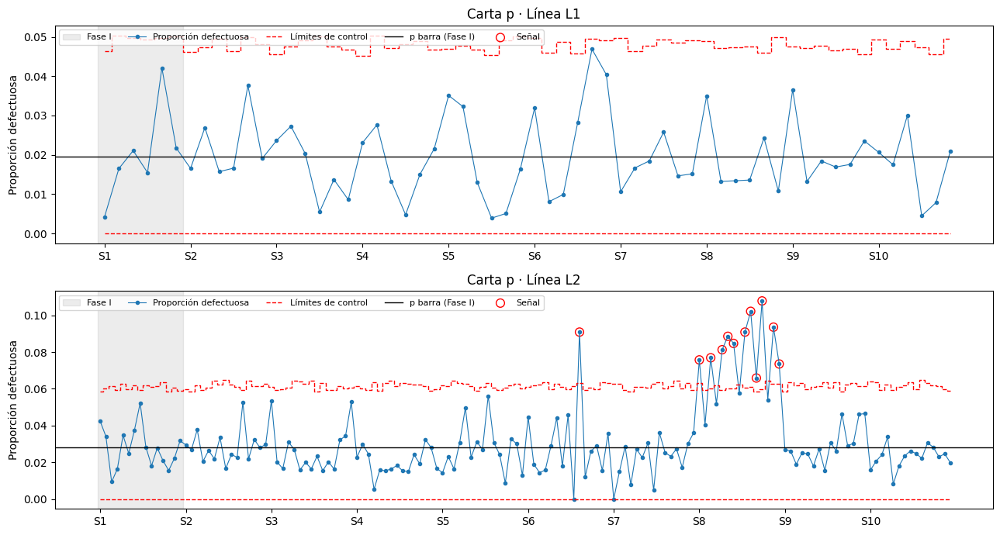

In [24]:

# --- 2. CARTA P POR LÍNEA ---
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for ax, (linea, g) in zip(axes, calidad_atributos.groupby('linea')):
    g = g.sort_values(['fecha', 'turno']).reset_index(drop=True)
    n_fase1 = (g['fase'] == 'Fase I').sum()

    ax.axvspan(-0.5, n_fase1 - 0.5, color='grey', alpha=0.15, label='Fase I')
    ax.plot(g.index, g['proporcion_p'], marker='o', markersize=3, linewidth=0.8, label='Proporción defectuosa')
    ax.step(g.index, g['LCS_p'], where='mid', color='red', linestyle='--', linewidth=1, label='Límites de control')
    ax.step(g.index, g['LCI_p'], where='mid', color='red', linestyle='--', linewidth=1)
    ax.axhline(g['p_barra'].iloc[0], color='black', linewidth=1, label='p barra (Fase I)')
    senal = g[g['alerta_p']]
    ax.scatter(senal.index, senal['proporcion_p'], s=60, facecolors='none', edgecolors='red', label='Señal')

    inicio_semana = g.groupby('semana_registro').head(1)
    ax.set_xticks(inicio_semana.index)
    ax.set_xticklabels([f'S{s}' for s in inicio_semana['semana_registro']])
    ax.set_ylabel('Proporción defectuosa')
    ax.set_title(f'Carta p · Línea {linea}')
    ax.legend(loc='upper left', fontsize=8, ncol=5)

plt.tight_layout()
plt.savefig('carta_p_por_linea.png', dpi=150, bbox_inches='tight')
plt.show()






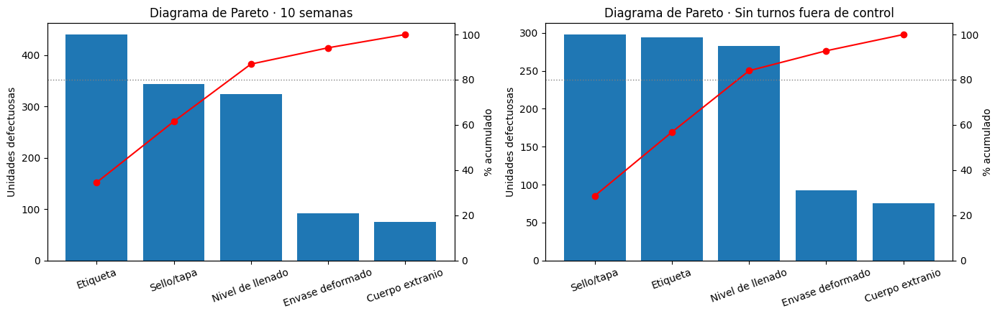

In [25]:
# DIAGRAMA DE PARETO (10 semanas y sin turnos fuera de control), guardado como .png para el informe
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (tabla, titulo) in zip(axes, [(df_pareto, '10 semanas'),
                                      (df_pareto_sin_alertas, 'Sin turnos fuera de control')]):
    ax.bar(tabla['causa_principal'], tabla['n_defectuosas'], color='tab:blue')
    ax.set_ylabel('Unidades defectuosas')
    ax.tick_params(axis='x', rotation=20)

    ax2 = ax.twinx()
    ax2.plot(tabla['causa_principal'], tabla['acumulado_%'], color='red', marker='o')
    ax2.axhline(80, color='grey', linestyle=':', linewidth=1)
    ax2.set_ylim(0, 105)
    ax2.set_ylabel('% acumulado')
    ax.set_title(f'Diagrama de Pareto · {titulo}')

plt.tight_layout()
plt.savefig('pareto_causas.png', dpi=150, bbox_inches='tight')
plt.show()

## A.5 Cuantificación económica del sobrellenado

In [26]:
# --- 1. COSTO VARIABLE POR LITRO POR SKU ---
maestro_sku['costo_por_litro'] = maestro_sku['costo_variable_caja_clp'] / maestro_sku['litros_por_caja']

# --- 2. VOLUMEN DE VENTAS ANUAL (último año = últimas 52 semanas) ---
# Se usa el año más reciente (y no el promedio de 3 años) porque representa mejor el volumen actual.
ventas_ultimo_anio = ventas_semanal[ventas_semanal['semana'] > ventas_semanal['semana'].max() - 52].copy()

# Anomalías de los datos de ventas: faltantes y valores > 5 veces la mediana del SKU (error de registro).
# La mediana se calcula solo con semanas con venta, porque FUN-B30 es intermitente (muchas semanas en 0).
mediana_sku = ventas_ultimo_anio.groupby('sku')['ventas_cajas'].transform(lambda x: x[x > 0].median())
anomalia = ventas_ultimo_anio['ventas_cajas'].isna() | (ventas_ultimo_anio['ventas_cajas'] > 5 * mediana_sku)

print("Registros de ventas anómalos en el último año (se imputan con la media del SKU sin anomalías):")
display(ventas_ultimo_anio.loc[anomalia, ['semana', 'sku', 'ventas_cajas', 'promocion']].assign(mediana_sku=mediana_sku[anomalia]))

media_limpia = ventas_ultimo_anio[~anomalia].groupby('sku')['ventas_cajas'].mean()
ventas_ultimo_anio.loc[anomalia, 'ventas_cajas'] = ventas_ultimo_anio.loc[anomalia, 'sku'].map(media_limpia)

ventas_anuales = ventas_ultimo_anio.groupby('sku')['ventas_cajas'].sum().reset_index()

# Cruzar con el maestro para obtener formato, línea y botellas por caja
ventas_anuales = pd.merge(ventas_anuales, maestro_sku[['sku', 'linea_envasado', 'formato_L', 'botellas_por_caja', 'costo_por_litro']], on='sku', how='left')
ventas_anuales.rename(columns={'linea_envasado': 'linea'}, inplace=True)
ventas_anuales['volumen_anual_botellas'] = ventas_anuales['ventas_cajas'] * ventas_anuales['botellas_por_caja']

# --- 3. SOBRELLENADO POR BOTELLA ---
# Escenario actual: estado vigente de cada línea. En L1 se usan las semanas desde el corrimiento
# (nadie lo ha corregido, así que es lo que la planta está regalando hoy); en L2, las 10 semanas.
datos_actuales = df_crudo_esp[~((df_crudo_esp['linea'] == 'L1') &
                                (df_crudo_esp['semana_registro'] < SEMANA_CORRIMIENTO_L1))]

medias_reales = datos_actuales.groupby(['linea', 'formato_L'])['volumen_mL'].mean().reset_index(name='Media actual')

print("\nMedia de llenado por línea y formato (mL):")
display(medias_reales)

# Cruzamos las ventas con las medias reales
df_eco_total = pd.merge(ventas_anuales, medias_reales, on=['linea', 'formato_L'], how='inner')

# Exceso regalado en mL por botella (Media real - Volumen Nominal)
df_eco_total['exceso_mL_botella'] = df_eco_total['Media actual'] - (df_eco_total['formato_L'] * 1000)

# Litros totales regalados al año por SKU
df_eco_total['litros_regalados_anual'] = (df_eco_total['exceso_mL_botella'] * df_eco_total['volumen_anual_botellas']) / 1000

# Pérdida económica en CLP al año por SKU
df_eco_total['perdida_CLP_anual'] = df_eco_total['litros_regalados_anual'] * df_eco_total['costo_por_litro']

# --- 5. RESUMEN DE RESULTADOS ---
display(df_eco_total[['sku', 'linea', 'formato_L', 'volumen_anual_botellas', 'exceso_mL_botella', 'litros_regalados_anual', 'perdida_CLP_anual']])

total_litros = df_eco_total['litros_regalados_anual'].sum()
total_clp = df_eco_total['perdida_CLP_anual'].sum()

print(f"\nIMPACTO FINANCIERO ANUAL TOTAL POR SOBRELLENADO (escenario actual):")
print(f"Total de líquido regalado (L1 + L2): {total_litros:,.0f} Litros/Año")
print(f"Costo asumido por la empresa: ${total_clp:,.0f} CLP/Año")

print("\nPérdida por línea y formato:")
display(df_eco_total.groupby(['linea', 'formato_L'])[['litros_regalados_anual', 'perdida_CLP_anual']].sum())

# --- 4. SOBRELLENADO POR TURNO ---
# Se compara el exceso por botella de cada turno. No se reparte la pérdida en CLP por turno
# porque los datos no indican cuánto produce cada turno.
por_turno = datos_actuales.groupby(['linea', 'formato_L', 'turno'])['volumen_mL'].mean().reset_index(name='media_turno')
por_turno['exceso_mL_botella'] = por_turno['media_turno'] - por_turno['formato_L'] * 1000

print("\n--- SOBRELLENADO POR TURNO (mL por botella, escenario actual) ---")
display(por_turno)


Registros de ventas anómalos en el último año (se imputan con la media del SKU sin anomalías):


,semana,sku,ventas_cajas,promocion,mediana_sku
1053,118,CIT-L05,32916.0,0,1848.0



Media de llenado por línea y formato (mL):


,linea,formato_L,Media actual
0,L1,0.5,505.719767
1,L2,1.5,1504.601062
2,L2,3.0,3008.501160


,sku,linea,formato_L,volumen_anual_botellas,exceso_mL_botella,litros_regalados_anual,perdida_CLP_anual
0,CIT-L05,L1,0.5,1225952.0,5.719767,7012.159385,3.295715e+06
1,CIT-L15,L2,1.5,689730.0,4.601062,3173.490838,1.491541e+06
2,CIT-L30,L2,3.0,90052.0,8.501160,765.546483,3.598068e+05
3,FUN-B05,L1,0.5,1547952.0,5.719767,8853.924251,7.171679e+06
4,FUN-B15,L2,1.5,544374.0,4.601062,2504.698797,2.028806e+06
5,FUN-B30,L2,3.0,30320.0,8.501160,257.755179,2.087817e+05
6,NEC-D05,L1,0.5,950796.0,5.719767,5438.331268,3.480532e+06
7,NEC-D15,L2,1.5,839976.0,4.601062,3864.782074,2.473461e+06
8,NEC-D30,L2,3.0,129436.0,8.501160,1100.356179,7.042280e+05



IMPACTO FINANCIERO ANUAL TOTAL POR SOBRELLENADO (escenario actual):
Total de líquido regalado (L1 + L2): 32,971 Litros/Año
Costo asumido por la empresa: $21,214,549 CLP/Año

Pérdida por línea y formato:


litros_regalados_anual  perdida_CLP_anual
linea formato_L                                           
L1    0.5                  21304.414903       1.394793e+07
L2    1.5                   9542.971710       5.993807e+06
      3.0                   2123.657841       1.272816e+06


--- SOBRELLENADO POR TURNO (mL por botella, escenario actual) ---


,linea,formato_L,turno,media_turno,exceso_mL_botella
0,L1,0.5,A (06-14),505.669267,5.669267
1,L1,0.5,B (14-22),505.770267,5.770267
2,L2,1.5,A (06-14),1503.170556,3.170556
3,L2,1.5,B (14-22),1503.616974,3.616974
4,L2,1.5,C (22-06),1506.805731,6.805731
5,L2,3.0,A (06-14),3007.395783,7.395783
6,L2,3.0,B (14-22),3007.665355,7.665355
7,L2,3.0,C (22-06),3010.640063,10.640063


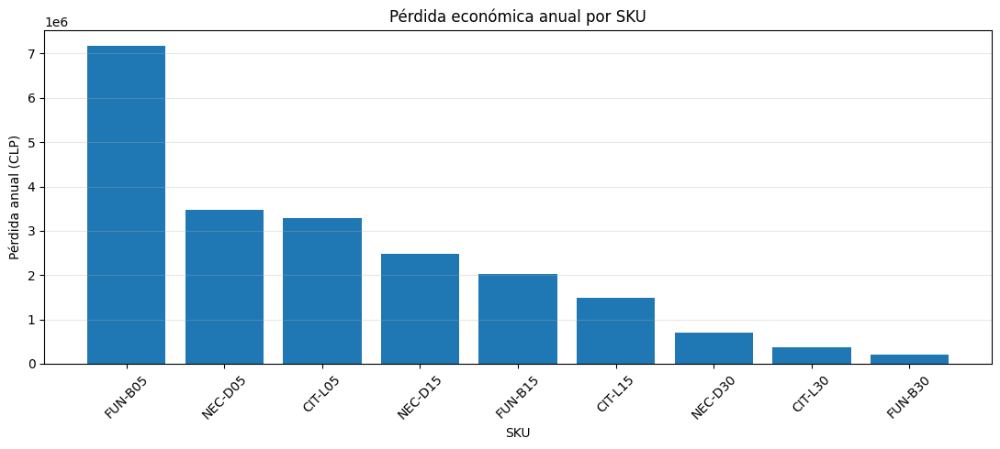

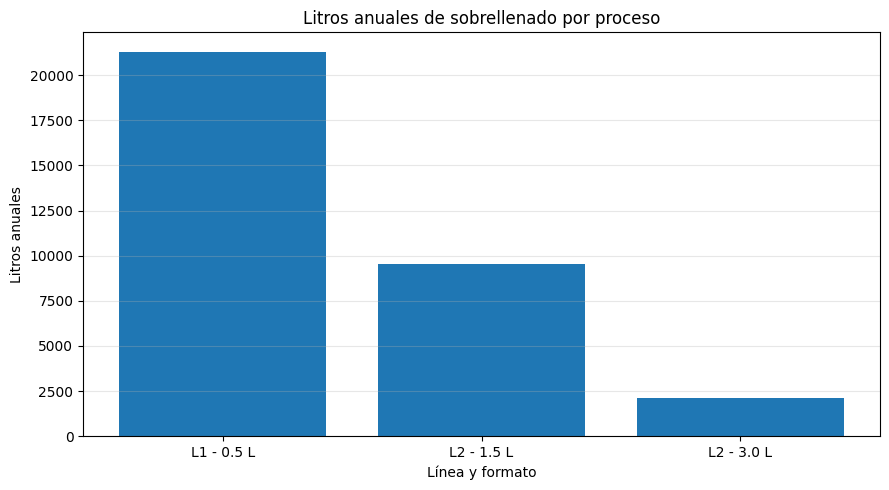

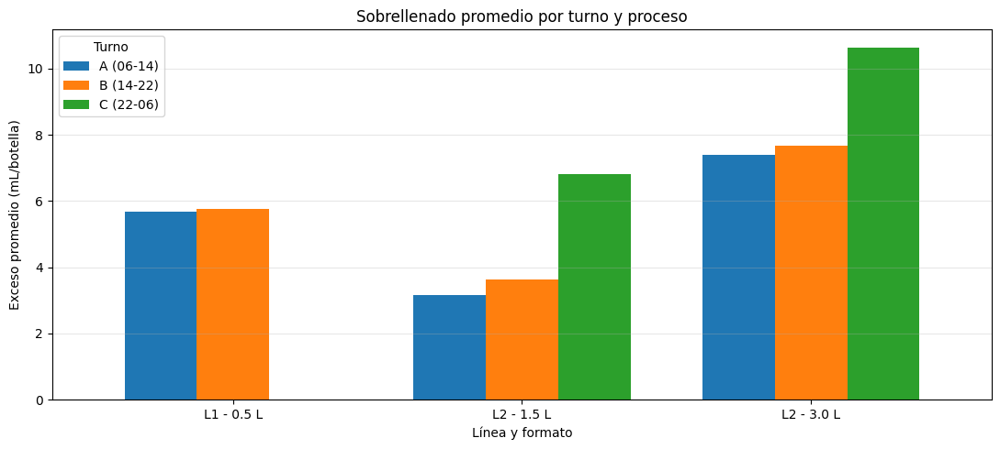

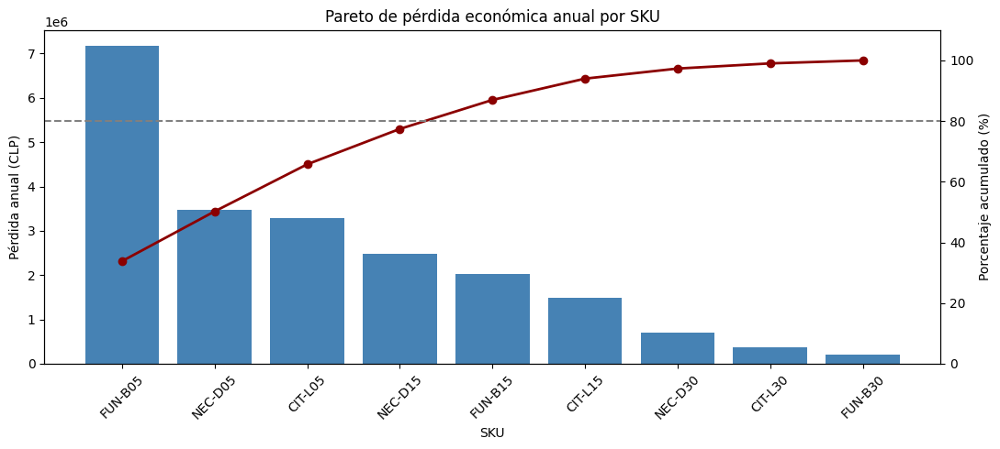

In [27]:
# 1. Pérdida económica anual asociada a cada SKU
datos_sku = df_eco_total.sort_values('perdida_CLP_anual', ascending=False)

plt.figure(figsize=(11, 5))
plt.bar(datos_sku['sku'], datos_sku['perdida_CLP_anual'])
plt.title('Pérdida económica anual por SKU')
plt.xlabel('SKU')
plt.ylabel('Pérdida anual (CLP)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Litros regalados por línea y formato
datos_linea = (
    df_eco_total
    .groupby(['linea', 'formato_L'])['litros_regalados_anual']
    .sum()
    .reset_index()
)

datos_linea['proceso'] = (
    datos_linea['linea'] + ' - ' +
    datos_linea['formato_L'].astype(str) + ' L'
)

plt.figure(figsize=(9, 5))
plt.bar(datos_linea['proceso'], datos_linea['litros_regalados_anual'])
plt.title('Litros anuales de sobrellenado por proceso')
plt.xlabel('Línea y formato')
plt.ylabel('Litros anuales')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# 3. Sobrellenado promedio por turno
datos_turno = por_turno.copy()

datos_turno['proceso'] = (
    datos_turno['linea'] + ' - ' +
    datos_turno['formato_L'].astype(str) + ' L'
)

tabla_turnos = datos_turno.pivot(
    index='proceso',
    columns='turno',
    values='exceso_mL_botella'
)

tabla_turnos.plot(
    kind='bar',
    figsize=(11, 5),
    width=0.75
)

plt.title('Sobrellenado promedio por turno y proceso')
plt.xlabel('Línea y formato')
plt.ylabel('Exceso promedio (mL/botella)')
plt.xticks(rotation=0)
plt.legend(title='Turno')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# 4. Pareto de pérdida económica anual por SKU
pareto_economico = (
    df_eco_total
    .groupby('sku')['perdida_CLP_anual']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

pareto_economico['porcentaje_acumulado'] = (
    pareto_economico['perdida_CLP_anual'].cumsum()
    / pareto_economico['perdida_CLP_anual'].sum()
    * 100
)

fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.bar(
    pareto_economico['sku'],
    pareto_economico['perdida_CLP_anual'],
    color='steelblue'
)

ax1.set_title('Pareto de pérdida económica anual por SKU')
ax1.set_xlabel('SKU')
ax1.set_ylabel('Pérdida anual (CLP)')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()

ax2.plot(
    pareto_economico['sku'],
    pareto_economico['porcentaje_acumulado'],
    color='darkred',
    marker='o',
    linewidth=2
)

ax2.axhline(80, color='gray', linestyle='--')
ax2.set_ylabel('Porcentaje acumulado (%)')
ax2.set_ylim(0, 110)

plt.tight_layout()
plt.show()


# Parte B: Pronóstico de demanda


In [28]:
# Revisar las dimensiones y la estructura del conjunto de datos de ventas
print("Dimensiones del dataset:", ventas_semanal.shape)

ventas_semanal.info()

# Ordenar los datos por SKU y fecha para mantener la secuencia cronológica de cada producto
ventas_semanal = ventas_semanal.sort_values(
    ["sku", "fecha_lunes"]
).reset_index(drop=True)

Dimensiones del dataset: (1404, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1404 entries, 0 to 1403
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   semana               1404 non-null   int64         
 1   fecha_lunes          1404 non-null   datetime64[ns]
 2   anio_iso             1404 non-null   int64         
 3   semana_iso           1404 non-null   int64         
 4   sku                  1404 non-null   object        
 5   ventas_cajas         1401 non-null   float64       
 6   dias_sin_stock       1401 non-null   float64       
 7   promocion            1404 non-null   int64         
 8   precio_lista_clp     1404 non-null   int64         
 9   precio_efectivo_clp  1404 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(6), object(1)
memory usage: 109.8+ KB


#Revisión Básica

In [29]:
# Revisar cantidad de SKU y número de observaciones por producto
print("Cantidad de SKU:", ventas_semanal["sku"].nunique())

print("\nFilas por SKU:")
print(ventas_semanal["sku"].value_counts())

# Revisar valores faltantes por columna
print("\nValores faltantes por columna:")
print(ventas_semanal.isna().sum())

# Verificar si existen registros duplicados para un mismo SKU y fecha
duplicados = ventas_semanal.duplicated(
    subset=["sku", "fecha_lunes"]
).sum()

print("\nDuplicados por SKU y fecha:", duplicados)

# Revisar el período temporal cubierto por los datos
print("\nFecha inicial:", ventas_semanal["fecha_lunes"].min())
print("Fecha final:", ventas_semanal["fecha_lunes"].max())

Cantidad de SKU: 9

Filas por SKU:
sku
CIT-L05    156
CIT-L15    156
CIT-L30    156
FUN-B05    156
FUN-B15    156
FUN-B30    156
NEC-D05    156
NEC-D15    156
NEC-D30    156
Name: count, dtype: int64

Valores faltantes por columna:
semana                 0
fecha_lunes            0
anio_iso               0
semana_iso             0
sku                    0
ventas_cajas           3
dias_sin_stock         3
promocion              0
precio_lista_clp       0
precio_efectivo_clp    0
dtype: int64

Duplicados por SKU y fecha: 0

Fecha inicial: 2023-10-02 00:00:00
Fecha final: 2026-09-21 00:00:00


#Crear jerarquía de Productos

In [30]:
# Agregar la familia correspondiente a cada SKU para construir la jerarquía de productos
ventas_semanal = ventas_semanal.merge(
    maestro_sku[["sku", "familia"]],
    on="sku",
    how="left"
)

# Comprobar la relación entre cada SKU y su familia
ventas_semanal[["sku", "familia"]].drop_duplicates()

,sku,familia
0,CIT-L05,CIT
156,CIT-L15,CIT
312,CIT-L30,CIT
468,FUN-B05,FUN
624,FUN-B15,FUN
780,FUN-B30,FUN
936,NEC-D05,NEC
1092,NEC-D15,NEC
1248,NEC-D30,NEC


#Pronóstico de productos

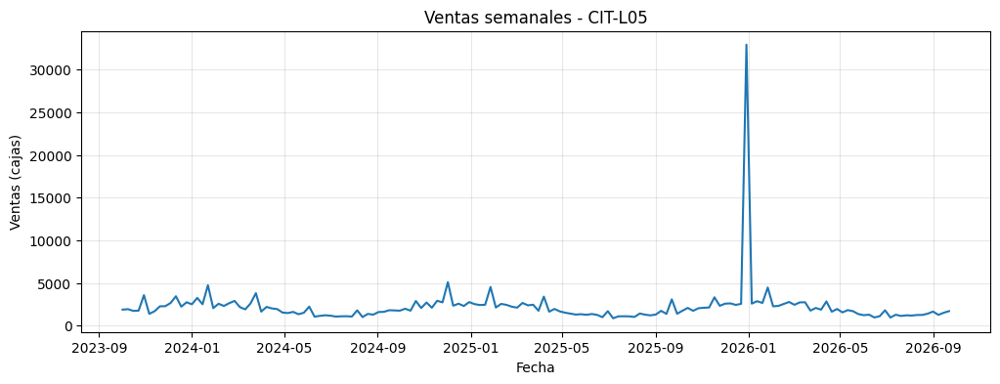

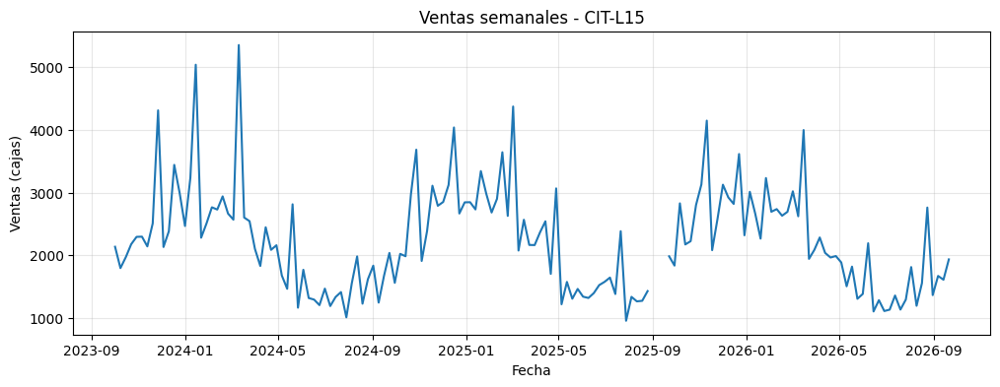

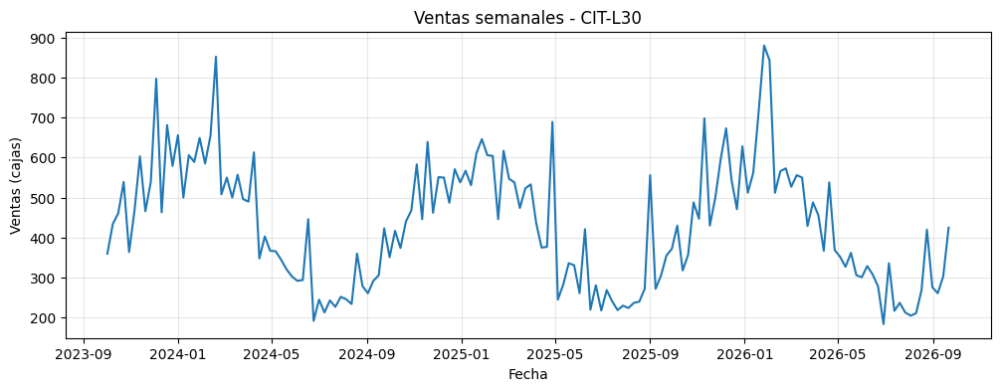

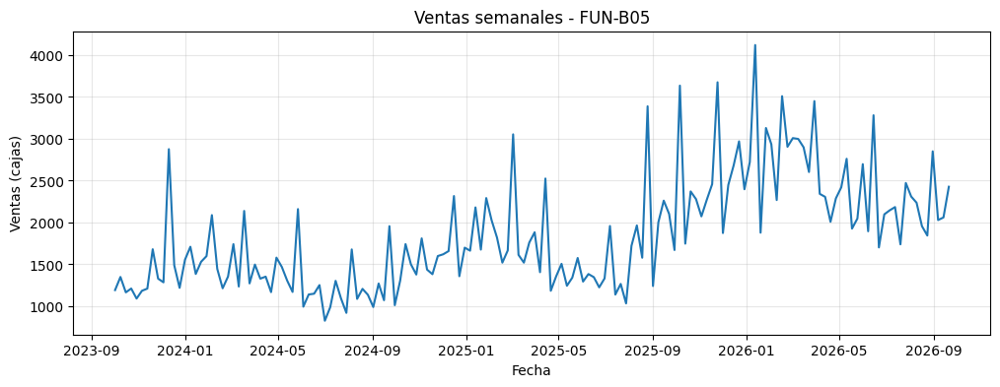

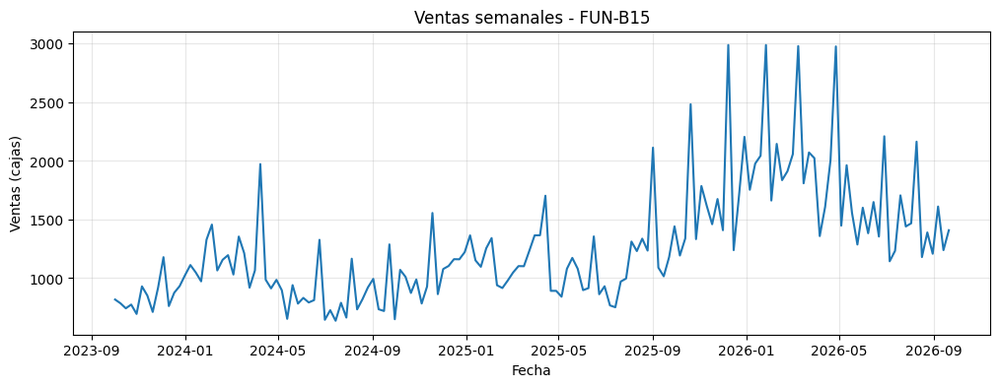

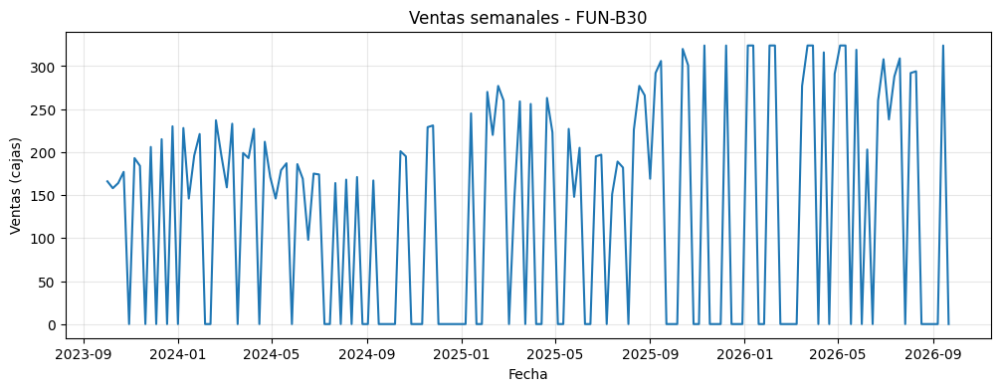

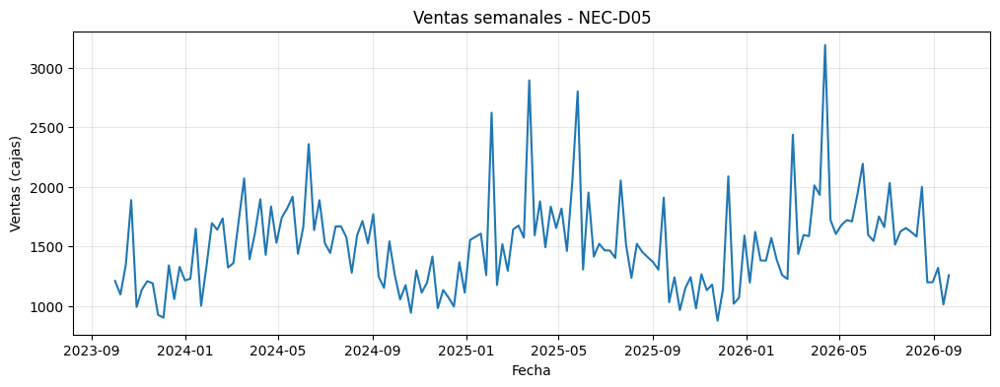

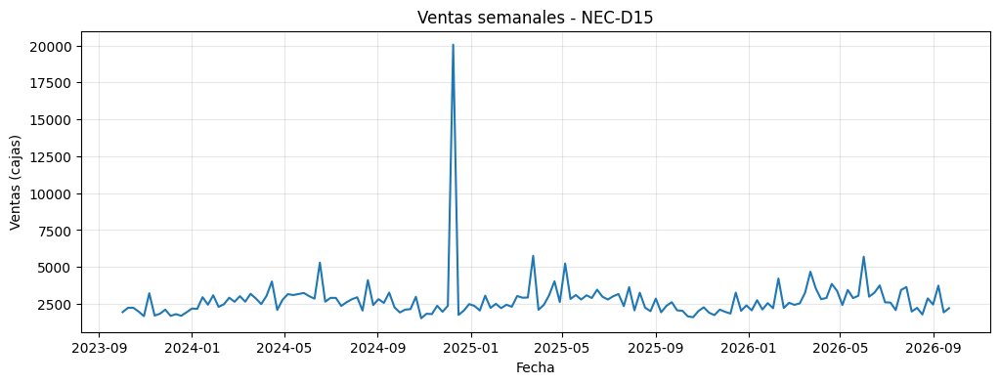

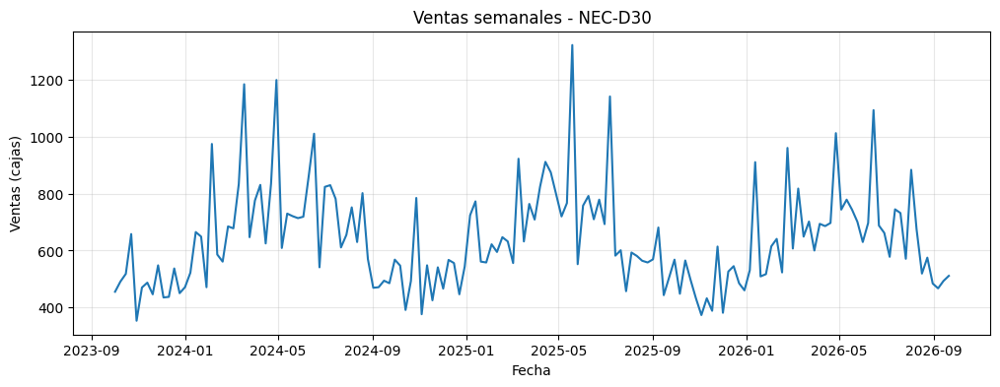

In [31]:
# Graficar la evolución semanal de las ventas para cada SKU
for sku in ventas_semanal["sku"].unique():

    datos = ventas_semanal[ventas_semanal["sku"] == sku]

    plt.figure(figsize=(12, 4))
    plt.plot(datos["fecha_lunes"], datos["ventas_cajas"])

    plt.title(f"Ventas semanales - {sku}")
    plt.xlabel("Fecha")
    plt.ylabel("Ventas (cajas)")
    plt.grid(alpha=0.3)

    plt.show()

#Datos faltantes

In [32]:
# Identificar las filas que contienen al menos un valor faltante
faltantes = ventas_semanal[ventas_semanal.isna().any(axis=1)]

print(faltantes)

     semana fecha_lunes  anio_iso  semana_iso      sku  ventas_cajas  \
256     101  2025-09-01      2025          36  CIT-L15           NaN   
257     102  2025-09-08      2025          37  CIT-L15           NaN   
258     103  2025-09-15      2025          38  CIT-L15           NaN   

     dias_sin_stock  promocion  precio_lista_clp  precio_efectivo_clp familia  
256             NaN          0              7980                 7980     CIT  
257             NaN          1              7980                 6433     CIT  
258             NaN          0              7980                 7980     CIT  


#Datos atípicos

In [33]:
# Lista para almacenar los valores atípicos detectados en cada SKU
lista_outliers = []

# Analizar cada SKU por separado
for sku, grupo in ventas_semanal.groupby("sku"):

    # Calcular el primer y tercer cuartil de las ventas
    Q1 = grupo["ventas_cajas"].quantile(0.25)
    Q3 = grupo["ventas_cajas"].quantile(0.75)

    # Calcular el rango intercuartílico
    IQR = Q3 - Q1

    # Definir los límites para identificar posibles valores atípicos
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    # Identificar observaciones fuera de los límites
    outliers_sku = grupo[
        (grupo["ventas_cajas"] < limite_inferior) |
        (grupo["ventas_cajas"] > limite_superior)
    ].copy()

    # Guardar los límites utilizados para cada SKU
    outliers_sku["limite_inferior"] = limite_inferior
    outliers_sku["limite_superior"] = limite_superior

    lista_outliers.append(outliers_sku)

# Unir los valores atípicos detectados en todos los SKU
outliers = pd.concat(lista_outliers, ignore_index=True)

# Mostrar variables que pueden ayudar a interpretar el origen de los valores atípicos
display(
    outliers[
        [
            "fecha_lunes",
            "sku",
            "ventas_cajas",
            "promocion",
            "precio_lista_clp",
            "precio_efectivo_clp",
            "dias_sin_stock",
            "limite_inferior",
            "limite_superior"
        ]
    ]
)
# Contar la cantidad total de valores atípicos detectados
print("Cantidad de outliers detectados:", len(outliers))

,fecha_lunes,sku,ventas_cajas,promocion,precio_lista_clp,precio_efectivo_clp,dias_sin_stock,limite_inferior,limite_superior
0,2024-01-22,CIT-L05,4738.0,1,5320,4263,0.0,-314.875,4200.125
1,2024-12-02,CIT-L05,5097.0,1,5320,4006,0.0,-314.875,4200.125
2,2025-01-27,CIT-L05,4533.0,1,5320,4254,0.0,-314.875,4200.125
3,2025-12-29,CIT-L05,32916.0,0,5320,5320,0.0,-314.875,4200.125
4,2026-01-26,CIT-L05,4470.0,1,5320,4392,0.0,-314.875,4200.125
5,2024-01-15,CIT-L15,5038.0,1,7980,6163,0.0,-203.000,4493.000
6,2024-03-11,CIT-L15,5352.0,1,7980,6576,0.0,-203.000,4493.000
7,2025-11-24,FUN-B05,3675.0,1,9920,8342,0.0,-86.625,3672.375
8,2026-01-12,FUN-B05,4120.0,1,9920,6962,0.0,-86.625,3672.375
9,2025-10-20,FUN-B15,2483.0,1,14880,10911,0.0,134.125,2229.125


Cantidad de outliers detectados: 31


In [34]:
outliers.shape

(31, 13)

#Revisar intermitencia

In [35]:
# Evaluar la intermitencia de las ventas mediante la proporción de semanas con ventas iguales a cero
intermitencia = (
    ventas_semanal
    .groupby("sku")
    .agg(
        total_semanas=("sku", "size"),
        semanas_cero=("ventas_cajas", lambda x: (x == 0).sum())
    )
)

# Calcular el porcentaje de semanas sin ventas para cada SKU
intermitencia["porcentaje_ceros"] = (
    100 * intermitencia["semanas_cero"] /
    intermitencia["total_semanas"]
)

# Mostrar primero los SKU con mayor proporción de semanas sin ventas
display(
    intermitencia.sort_values(
        "porcentaje_ceros",
        ascending=False
    )
)

,total_semanas,semanas_cero,porcentaje_ceros
sku,,,
FUN-B30,156,69,44.230769
CIT-L05,156,0,0.000000
CIT-L15,156,0,0.000000
FUN-B05,156,0,0.000000
CIT-L30,156,0,0.000000
FUN-B15,156,0,0.000000
NEC-D05,156,0,0.000000
NEC-D15,156,0,0.000000
NEC-D30,156,0,0.000000


In [36]:
# Revisar si las semanas con ventas cero de FUN-B30 coinciden con períodos sin stock
ceros_fun_b30 = ventas_semanal[
    (ventas_semanal["sku"] == "FUN-B30") &
    (ventas_semanal["ventas_cajas"] == 0)
].copy()

print("Cantidad de semanas con ventas cero:")
print(len(ceros_fun_b30))

print("\nDías sin stock asociados a esas semanas:")
display(
    ceros_fun_b30["dias_sin_stock"]
    .value_counts(dropna=False)
    .sort_index()
)

Cantidad de semanas con ventas cero:
69

Días sin stock asociados a esas semanas:


,count
dias_sin_stock,
0.0,69


In [37]:
# Revisar el detalle de las semanas con ventas cero de FUN-B30
display(
    ceros_fun_b30[
        [
            "fecha_lunes",
            "ventas_cajas",
            "dias_sin_stock",
            "promocion"
        ]
    ]
)

,fecha_lunes,ventas_cajas,dias_sin_stock,promocion
784,2023-10-30,0.0,0.0,0
787,2023-11-20,0.0,0.0,0
789,2023-12-04,0.0,0.0,0
791,2023-12-18,0.0,0.0,0
793,2024-01-01,0.0,0.0,0
...,...,...,...,...
930,2026-08-17,0.0,0.0,0
931,2026-08-24,0.0,0.0,1
932,2026-08-31,0.0,0.0,0
933,2026-09-07,0.0,0.0,0


#Reconstruir la demanda censurada por quiebres de stock

In [38]:
# Reconstruir una estimación de la demanda cuando hubo días sin stock

# Calcular cuántos días de la semana hubo disponibilidad del producto
ventas_semanal["dias_con_stock"] = (
    7 - ventas_semanal["dias_sin_stock"]
)

# Calcular el factor de corrección por censura
ventas_semanal["factor_censura"] = (
    7 / ventas_semanal["dias_con_stock"]
)

# Estimar la demanda semanal suponiendo que la demanda se distribuye
# aproximadamente de forma uniforme durante los días de la semana
ventas_semanal["demanda_estimada"] = (
    ventas_semanal["ventas_cajas"] *
    ventas_semanal["factor_censura"]
)

# Calcular la demanda que potencialmente no se observó por falta de stock
ventas_semanal["demanda_no_observada"] = (
    ventas_semanal["demanda_estimada"] -
    ventas_semanal["ventas_cajas"]
)

In [39]:
# Mostrar únicamente las semanas en que la demanda fue corregida por falta de stock
display(
    ventas_semanal.loc[
        ventas_semanal["dias_sin_stock"] > 0,
        [
            "fecha_lunes",
            "sku",
            "ventas_cajas",
            "dias_sin_stock",
            "dias_con_stock",
            "factor_censura",
            "demanda_estimada",
            "demanda_no_observada"
        ]
    ]
)

,fecha_lunes,sku,ventas_cajas,dias_sin_stock,dias_con_stock,factor_censura,demanda_estimada,demanda_no_observada
103,2025-09-22,CIT-L05,3078.0,1.0,6.0,1.166667,3591.000000,513.000000
738,2025-12-08,FUN-B15,2988.0,1.0,6.0,1.166667,3486.000000,498.000000
745,2026-01-26,FUN-B15,2988.0,1.0,6.0,1.166667,3486.000000,498.000000
781,2023-10-09,FUN-B30,158.0,2.0,5.0,1.400000,221.200000,63.200000
782,2023-10-16,FUN-B30,164.0,1.0,6.0,1.166667,191.333333,27.333333
783,2023-10-23,FUN-B30,177.0,1.0,6.0,1.166667,206.500000,29.500000
785,2023-11-06,FUN-B30,193.0,4.0,3.0,2.333333,450.333333,257.333333
786,2023-11-13,FUN-B30,184.0,1.0,6.0,1.166667,214.666667,30.666667
788,2023-11-27,FUN-B30,206.0,4.0,3.0,2.333333,480.666667,274.666667
790,2023-12-11,FUN-B30,215.0,3.0,4.0,1.750000,376.250000,161.250000


In [40]:
# Resumir el impacto de los quiebres de stock para cada SKU
resumen_stockout = (
    ventas_semanal.loc[
        ventas_semanal["dias_sin_stock"] > 0
    ]
    .groupby("sku")
    .agg(
        semanas_con_stockout=(
            "dias_sin_stock",
            "count"
        ),
        dias_sin_stock_total=(
            "dias_sin_stock",
            "sum"
        ),
        demanda_no_observada_total=(
            "demanda_no_observada",
            "sum"
        )
    )
    .sort_values(
        "dias_sin_stock_total",
        ascending=False
    )
)

display(resumen_stockout)

,semanas_con_stockout,dias_sin_stock_total,demanda_no_observada_total
sku,,,
FUN-B30,55,139.0,9868.3
FUN-B15,2,2.0,996.0
CIT-L05,1,1.0,513.0


In [41]:
# Identificar registros donde aún no se pudo calcular la demanda estimada
faltantes_demanda = ventas_semanal.loc[
    ventas_semanal["demanda_estimada"].isna(),
    [
        "fecha_lunes",
        "sku",
        "ventas_cajas",
        "dias_sin_stock",
        "promocion",
        "precio_lista_clp",
        "precio_efectivo_clp"
    ]
]

display(faltantes_demanda)

,fecha_lunes,sku,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
256,2025-09-01,CIT-L15,NaN,NaN,0,7980,7980
257,2025-09-08,CIT-L15,NaN,NaN,1,7980,6433
258,2025-09-15,CIT-L15,NaN,NaN,0,7980,7980


In [42]:
# Calcular el porcentaje de descuento aplicado respecto al precio de lista
ventas_semanal["descuento_pct"] = (
    1 -
    ventas_semanal["precio_efectivo_clp"] /
    ventas_semanal["precio_lista_clp"]
) * 100

# Comparar el descuento promedio entre semanas con y sin promoción
ventas_semanal.groupby("promocion")["descuento_pct"].mean()

,descuento_pct
promocion,
0,0.00000
1,22.89342


In [43]:
# Verificar que, cuando no hubo quiebre de stock, la demanda estimada sea igual a las ventas observadas
print(
    (
        ventas_semanal.loc[
            ventas_semanal["dias_sin_stock"] == 0,
            "demanda_estimada"
        ]
        ==
        ventas_semanal.loc[
            ventas_semanal["dias_sin_stock"] == 0,
            "ventas_cajas"
        ]
    ).all()
)

# Verificar que, cuando hubo quiebre de stock y ventas positivas,
# la demanda estimada sea mayor que las ventas observadas
mask = (
    (ventas_semanal["dias_sin_stock"] > 0) &
    (ventas_semanal["ventas_cajas"] > 0)
)

print(
    (
        ventas_semanal.loc[mask, "demanda_estimada"]
        >
        ventas_semanal.loc[mask, "ventas_cajas"]
    ).all()
)

True
True


In [44]:
ventas_semanal["descuento_pct"] = (
    1 -
    ventas_semanal["precio_efectivo_clp"] /
    ventas_semanal["precio_lista_clp"]
)
ventas_semanal["descuento_pct"]

,descuento_pct
0,0.000000
1,0.000000
2,0.000000
3,0.000000
4,0.271241
...,...
1399,0.000000
1400,0.000000
1401,0.000000
1402,0.000000


In [45]:
# Contar la cantidad de semanas con y sin promoción para cada SKU
promociones_por_sku = (
    ventas_semanal
    .groupby(["sku", "promocion"])
    .size()
    .reset_index(name="cantidad_semanas")
)

display(promociones_por_sku)

,sku,promocion,cantidad_semanas
0,CIT-L05,0,139
1,CIT-L05,1,17
2,CIT-L15,0,140
3,CIT-L15,1,16
4,CIT-L30,0,139
5,CIT-L30,1,17
6,FUN-B05,0,139
7,FUN-B05,1,17
8,FUN-B15,0,138
9,FUN-B15,1,18


Si se quiere usar la promoción como variable exógena en un modelo SARIMAX, es necesario conocer o suponer los valores de promoción para las 13 semanas futuras. Si esa información no está disponible, no conviene utilizarla como regresor en el pronóstico final.

In [46]:
# Comparar las ventas observadas entre semanas con y sin promoción
resumen_promo_ventas = (
    ventas_semanal
    .groupby(["sku", "promocion"])["ventas_cajas"]
    .agg(
        cantidad="count",
        promedio="mean",
        mediana="median"
    )
    .reset_index()
)

display(resumen_promo_ventas)

,sku,promocion,cantidad,promedio,mediana
0,CIT-L05,0,139,2079.028777,1761.0
1,CIT-L05,1,17,3197.882353,3321.0
2,CIT-L15,0,138,2084.079710,2080.0
3,CIT-L15,1,15,3583.866667,3684.0
4,CIT-L30,0,139,413.755396,417.0
5,CIT-L30,1,17,578.411765,556.0
6,FUN-B05,0,139,1729.143885,1599.0
7,FUN-B05,1,17,2773.352941,2850.0
8,FUN-B15,0,138,1177.507246,1099.5
9,FUN-B15,1,18,1958.222222,1838.0


In [47]:
# Comparar la demanda estimada entre semanas con y sin promoción
resumen_promo = (
    ventas_semanal
    .groupby(["sku", "promocion"])["demanda_estimada"]
    .agg(
        cantidad="count",
        promedio="mean",
        mediana="median"
    )
    .reset_index()
)

display(resumen_promo)

,sku,promocion,cantidad,promedio,mediana
0,CIT-L05,0,139,2079.028777,1761.0
1,CIT-L05,1,17,3228.058824,3403.0
2,CIT-L15,0,138,2084.079710,2080.0
3,CIT-L15,1,15,3583.866667,3684.0
4,CIT-L30,0,139,413.755396,417.0
5,CIT-L30,1,17,578.411765,556.0
6,FUN-B05,0,139,1729.143885,1599.0
7,FUN-B05,1,17,2773.352941,2850.0
8,FUN-B15,0,138,1177.507246,1099.5
9,FUN-B15,1,18,2013.555556,1838.0


In [48]:
# Comparar el descuento aplicado entre semanas con y sin promoción
resumen_descuento = (
    ventas_semanal
    .groupby(["sku", "promocion"])["descuento_pct"]
    .agg(
        promedio_descuento="mean",
        mediana_descuento="median"
    )
    .reset_index()
)

display(resumen_descuento)

,sku,promocion,promedio_descuento,mediana_descuento
0,CIT-L05,0,0.000000,0.000000
1,CIT-L05,1,0.230307,0.239474
2,CIT-L15,0,0.000000,0.000000
3,CIT-L15,1,0.206947,0.193985
4,CIT-L30,0,0.000000,0.000000
5,CIT-L30,1,0.233309,0.242951
6,FUN-B05,0,0.000000,0.000000
7,FUN-B05,1,0.229536,0.231754
8,FUN-B15,0,0.000000,0.000000
9,FUN-B15,1,0.223648,0.227554


#Repetir diagnostico utilizando la demanda estimada

In [49]:
# Comparar las ventas observadas con la demanda estimada después de corregir la censura
display(
    ventas_semanal[
        [
            "fecha_lunes",
            "sku",
            "ventas_cajas",
            "dias_sin_stock",
            "demanda_estimada"
        ]
    ].head(20)
)

,fecha_lunes,sku,ventas_cajas,dias_sin_stock,demanda_estimada
0,2023-10-02,CIT-L05,1878.0,0.0,1878.0
1,2023-10-09,CIT-L05,1933.0,0.0,1933.0
2,2023-10-16,CIT-L05,1731.0,0.0,1731.0
3,2023-10-23,CIT-L05,1761.0,0.0,1761.0
4,2023-10-30,CIT-L05,3572.0,0.0,3572.0
5,2023-11-06,CIT-L05,1383.0,0.0,1383.0
6,2023-11-13,CIT-L05,1692.0,0.0,1692.0
7,2023-11-20,CIT-L05,2267.0,0.0,2267.0
8,2023-11-27,CIT-L05,2285.0,0.0,2285.0
9,2023-12-04,CIT-L05,2653.0,0.0,2653.0


In [50]:
# Mostrar únicamente las semanas en que la demanda estimada fue corregida por quiebre de stock
display(
    ventas_semanal.loc[
        ventas_semanal["dias_sin_stock"] > 0,
        [
            "fecha_lunes",
            "sku",
            "ventas_cajas",
            "dias_sin_stock",
            "demanda_estimada"
        ]
    ]
)

,fecha_lunes,sku,ventas_cajas,dias_sin_stock,demanda_estimada
103,2025-09-22,CIT-L05,3078.0,1.0,3591.000000
738,2025-12-08,FUN-B15,2988.0,1.0,3486.000000
745,2026-01-26,FUN-B15,2988.0,1.0,3486.000000
781,2023-10-09,FUN-B30,158.0,2.0,221.200000
782,2023-10-16,FUN-B30,164.0,1.0,191.333333
783,2023-10-23,FUN-B30,177.0,1.0,206.500000
785,2023-11-06,FUN-B30,193.0,4.0,450.333333
786,2023-11-13,FUN-B30,184.0,1.0,214.666667
788,2023-11-27,FUN-B30,206.0,4.0,480.666667
790,2023-12-11,FUN-B30,215.0,3.0,376.250000


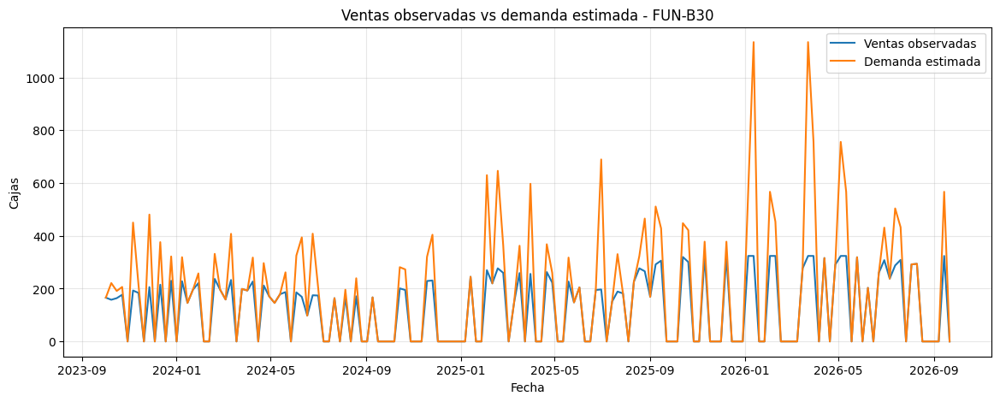

In [51]:
# Comparar las ventas observadas con la demanda estimada para FUN-B30
sku_elegido = "FUN-B30"

datos_sku = ventas_semanal[
    ventas_semanal["sku"] == sku_elegido
]

plt.figure(figsize=(14, 5))

plt.plot(
    datos_sku["fecha_lunes"],
    datos_sku["ventas_cajas"],
    label="Ventas observadas"
)

plt.plot(
    datos_sku["fecha_lunes"],
    datos_sku["demanda_estimada"],
    label="Demanda estimada"
)

plt.title(f"Ventas observadas vs demanda estimada - {sku_elegido}")
plt.xlabel("Fecha")
plt.ylabel("Cajas")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

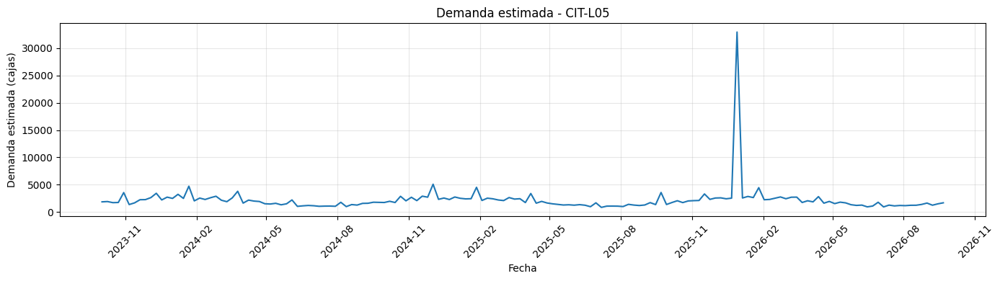

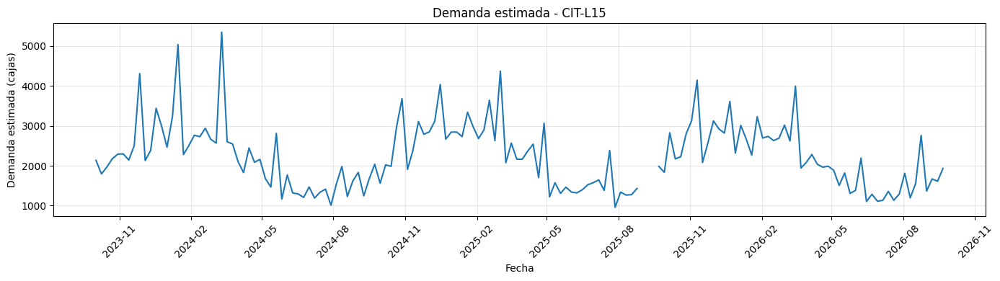

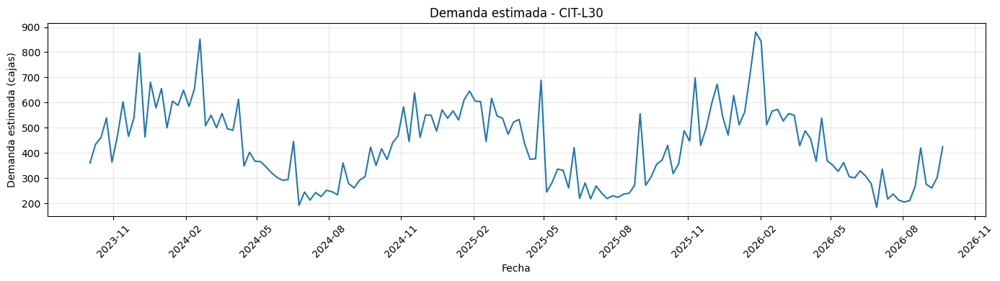

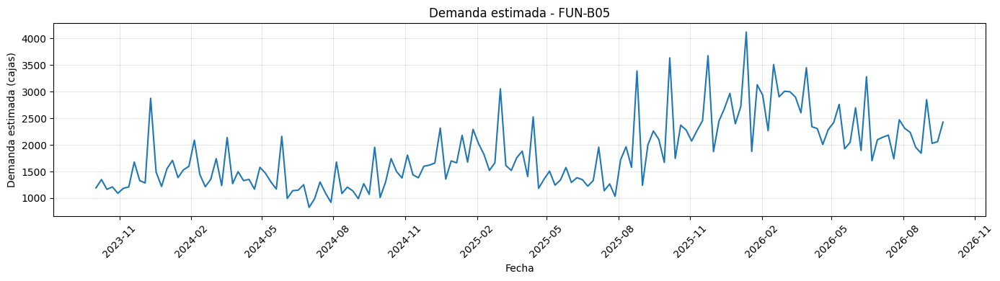

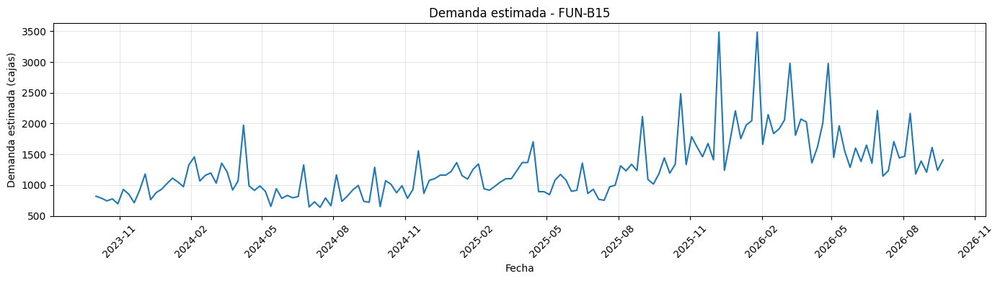

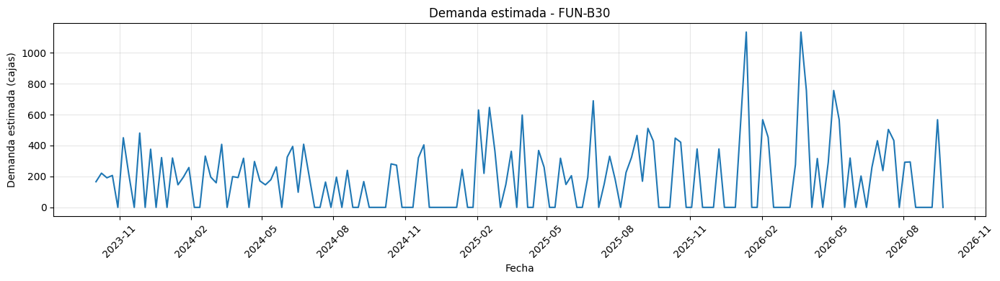

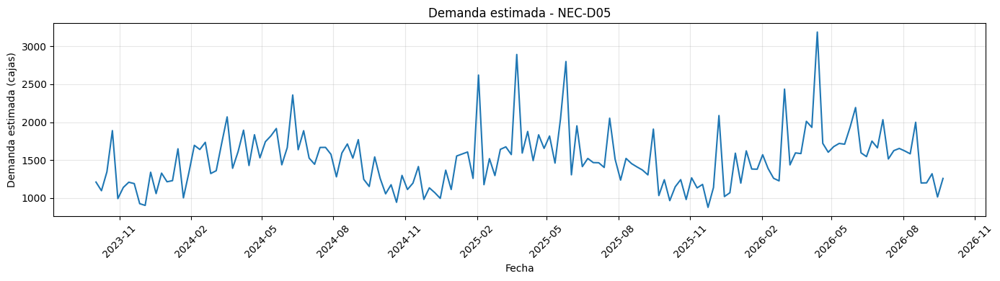

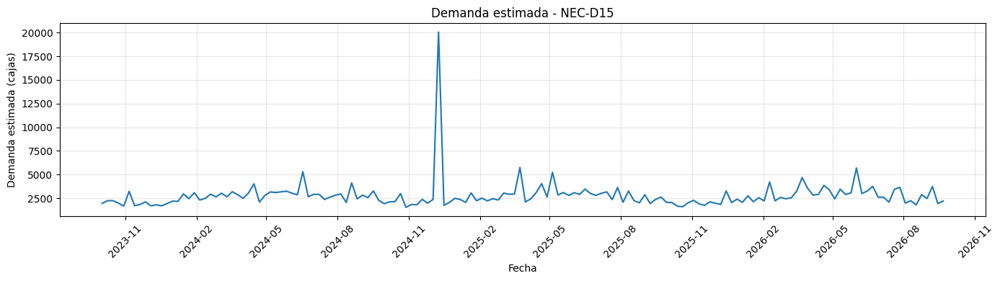

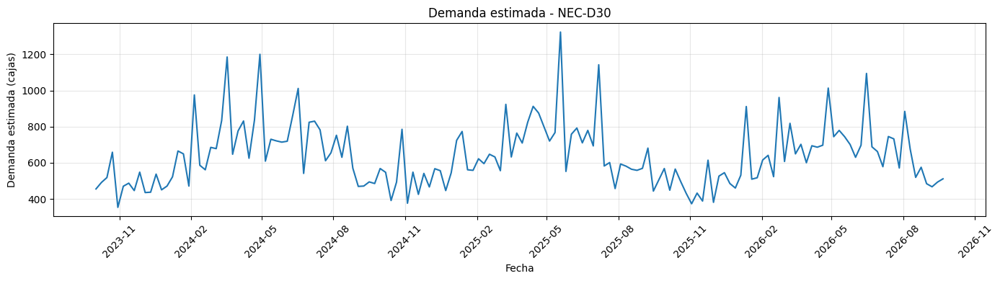

In [52]:
# Graficar la demanda estimada de cada SKU con fechas legibles
for sku in ventas_semanal["sku"].unique():

    datos_sku = ventas_semanal[
        ventas_semanal["sku"] == sku
    ]

    fig, ax = plt.subplots(figsize=(14, 4))

    ax.plot(
        datos_sku["fecha_lunes"],
        datos_sku["demanda_estimada"]
    )

    ax.set_title(f"Demanda estimada - {sku}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Demanda estimada (cajas)")

    # Mostrar una marca en el eje temporal cada 3 meses
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=3)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    ax.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [53]:
# Revisar una observación específica de FUN-B30
display(
    ventas_semanal.loc[
        (ventas_semanal["sku"] == "FUN-B30") &
        (ventas_semanal["ventas_cajas"] == 324),
        [
            "fecha_lunes",
            "ventas_cajas",
            "dias_sin_stock",
            "promocion",
            "precio_efectivo_clp"
        ]
    ]
)

,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_efectivo_clp
890,2025-11-10,324.0,1.0,0,19840
894,2025-12-08,324.0,1.0,0,19840
898,2026-01-05,324.0,3.0,0,19840
899,2026-01-12,324.0,5.0,1,15133
902,2026-02-02,324.0,3.0,0,19840
903,2026-02-09,324.0,2.0,0,19840
909,2026-03-23,324.0,5.0,0,19840
910,2026-03-30,324.0,4.0,0,19840
915,2026-05-04,324.0,4.0,1,16582
916,2026-05-11,324.0,3.0,0,19840


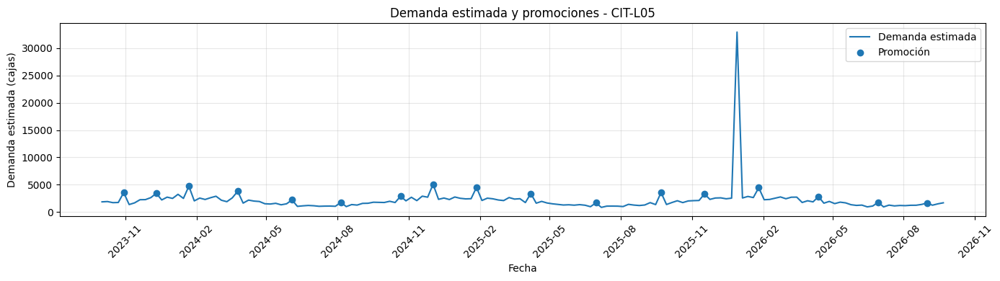

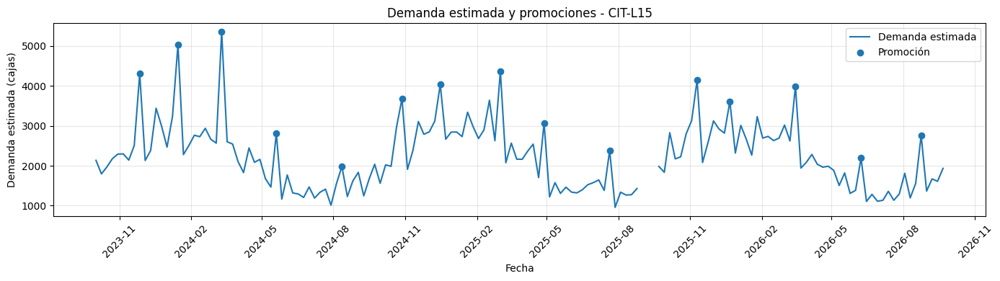

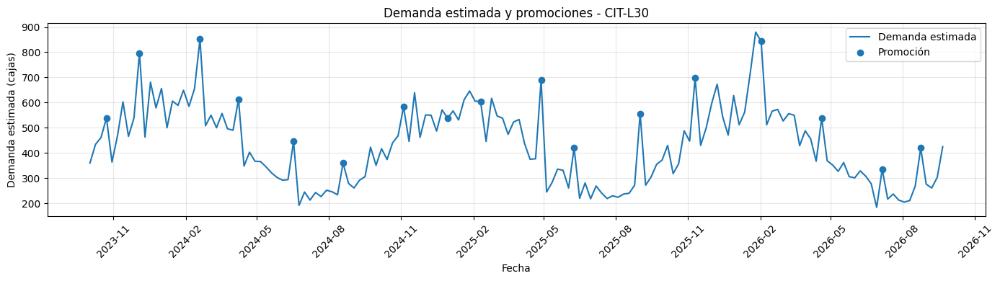

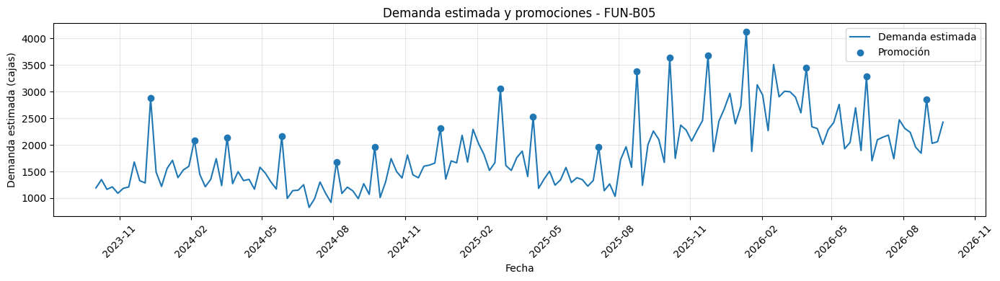

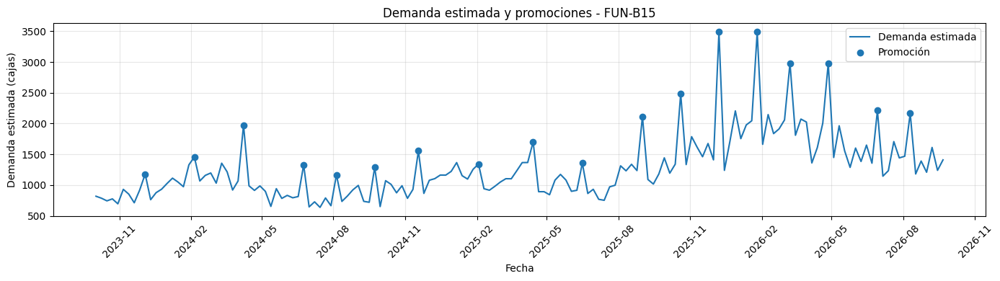

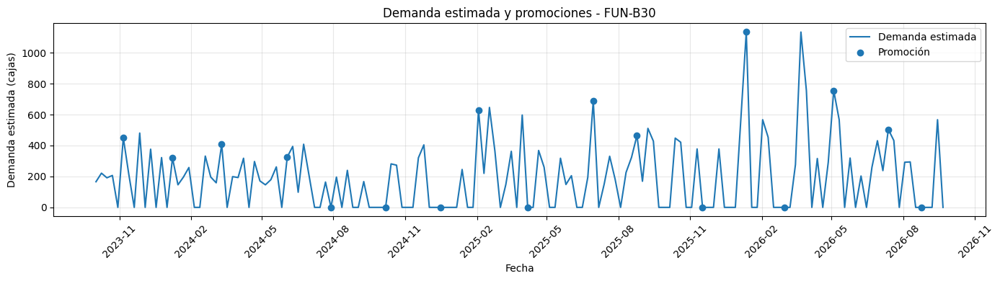

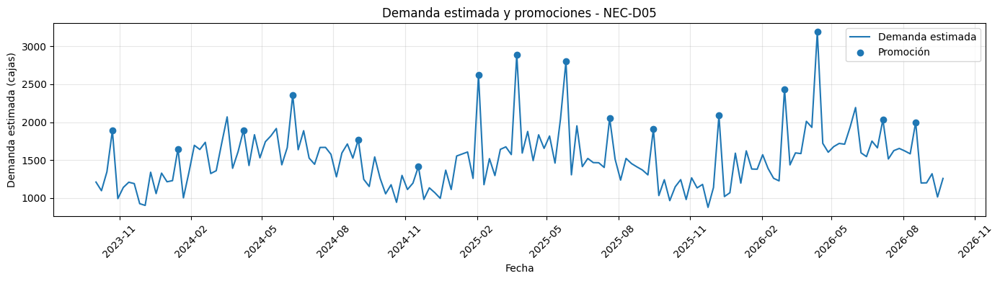

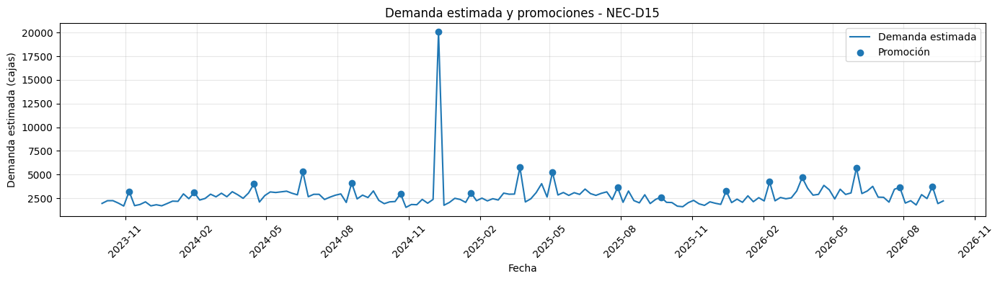

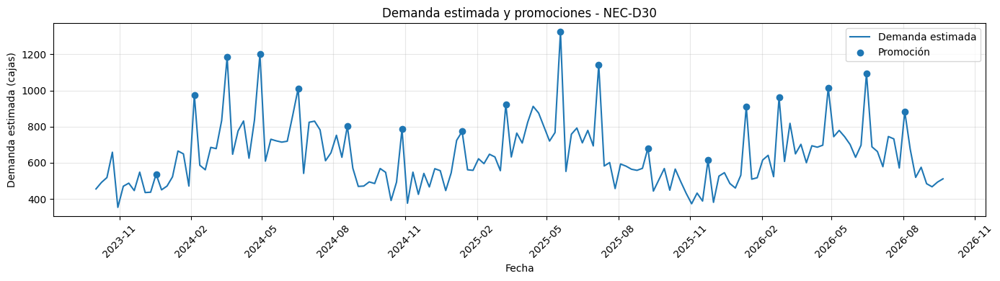

In [54]:
# Graficar la demanda estimada e identificar las semanas con promoción
for sku in ventas_semanal["sku"].unique():

    datos_sku = ventas_semanal[
        ventas_semanal["sku"] == sku
    ]

    promociones = datos_sku[
        datos_sku["promocion"] == 1
    ]

    fig, ax = plt.subplots(figsize=(14, 4))

    # Graficar la serie completa de demanda estimada
    ax.plot(
        datos_sku["fecha_lunes"],
        datos_sku["demanda_estimada"],
        label="Demanda estimada"
    )

    # Marcar las semanas en que hubo promoción
    ax.scatter(
        promociones["fecha_lunes"],
        promociones["demanda_estimada"],
        label="Promoción",
        zorder=3
    )

    ax.set_title(f"Demanda estimada y promociones - {sku}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Demanda estimada (cajas)")

    # Mostrar una marca temporal cada 3 meses
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=3)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    ax.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

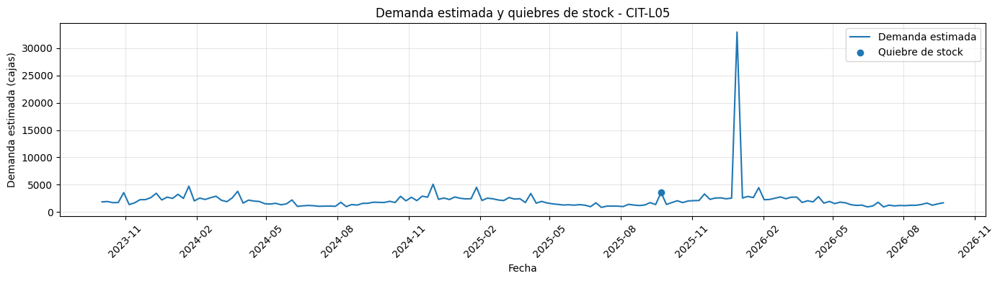

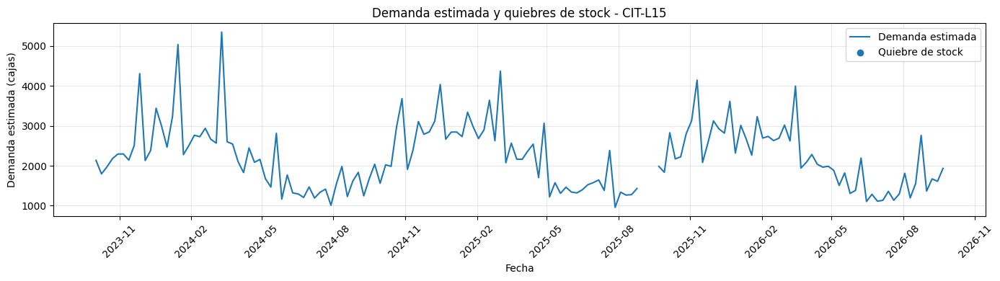

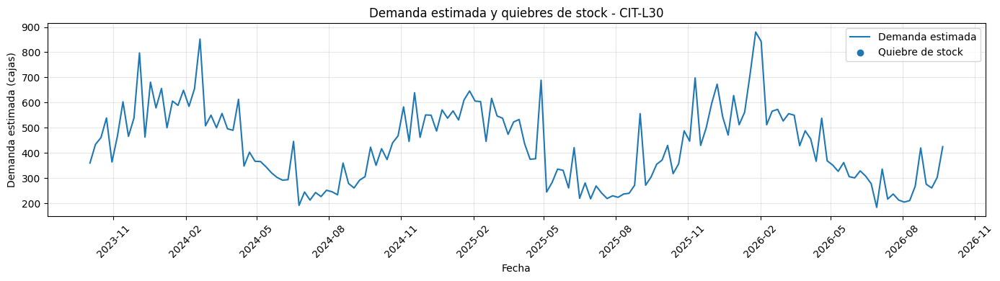

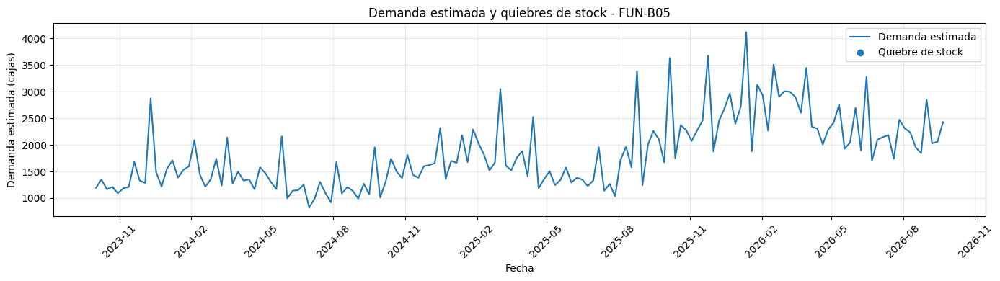

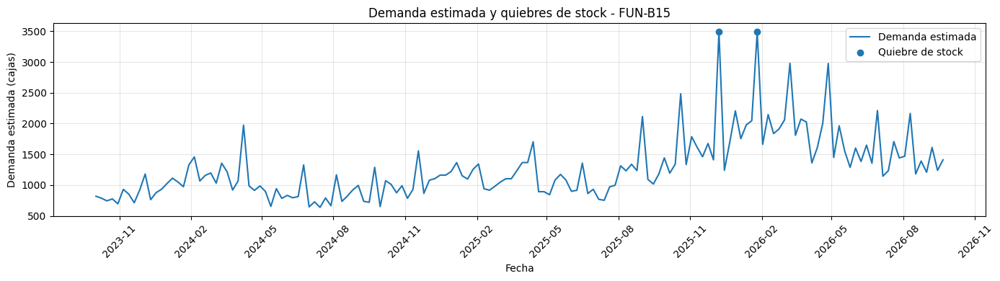

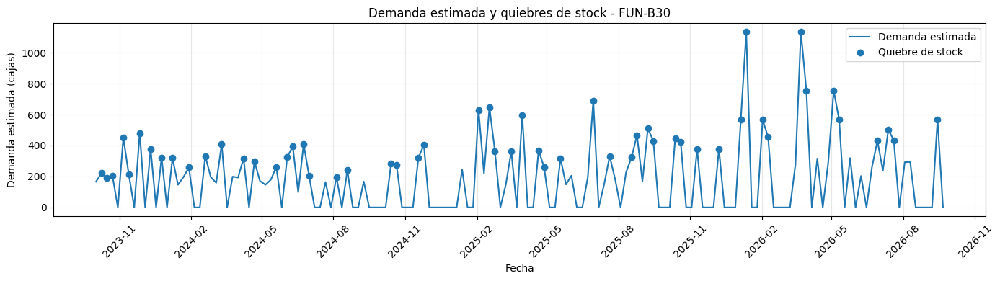

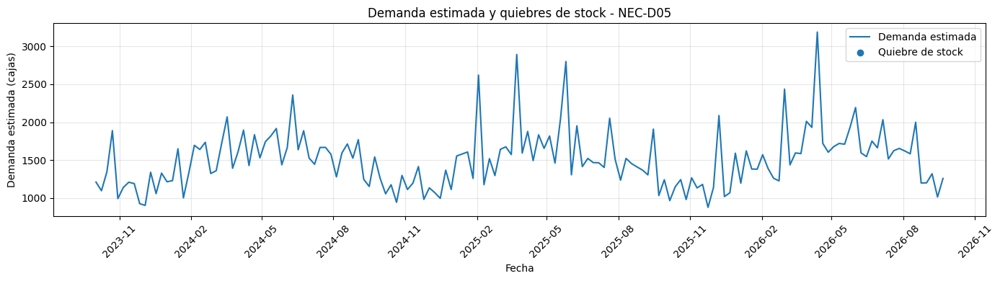

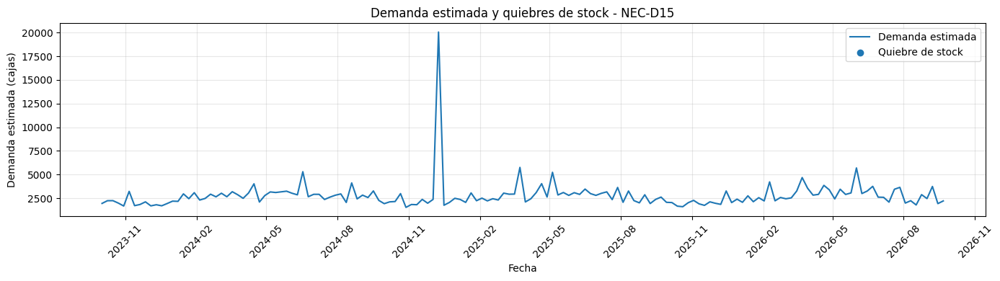

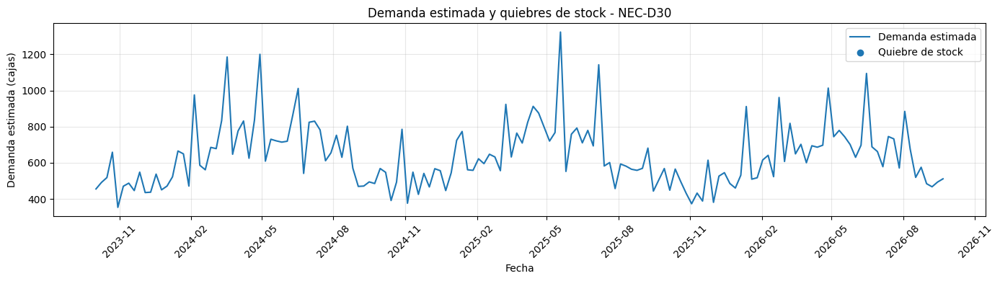

In [55]:
# Graficar la demanda estimada e identificar las semanas con quiebre de stock
for sku in ventas_semanal["sku"].unique():

    datos_sku = ventas_semanal[
        ventas_semanal["sku"] == sku
    ]

    stockout = datos_sku[
        datos_sku["dias_sin_stock"] > 0
    ]

    fig, ax = plt.subplots(figsize=(14, 4))

    # Graficar la serie completa de demanda estimada
    ax.plot(
        datos_sku["fecha_lunes"],
        datos_sku["demanda_estimada"],
        label="Demanda estimada"
    )

    # Marcar las semanas en que hubo quiebre de stock
    ax.scatter(
        stockout["fecha_lunes"],
        stockout["demanda_estimada"],
        label="Quiebre de stock",
        zorder=3
    )

    ax.set_title(f"Demanda estimada y quiebres de stock - {sku}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Demanda estimada (cajas)")

    # Mostrar una marca temporal cada 3 meses
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=3)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    ax.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [56]:
# Revisar los ceros de FUN-B30 después de reconstruir la demanda

ceros_fun_b30 = ventas_semanal[
    (ventas_semanal["sku"] == "FUN-B30") &
    (ventas_semanal["ventas_cajas"] == 0)
].copy()

print("Cantidad de semanas con ventas cero:")
print(len(ceros_fun_b30))

print("\nDías sin stock asociados a esas semanas:")
print(
    ceros_fun_b30["dias_sin_stock"]
    .value_counts(dropna=False)
    .sort_index()
)

display(
    ceros_fun_b30[
        [
            "fecha_lunes",
            "ventas_cajas",
            "dias_sin_stock",
            "promocion",
            "demanda_estimada"
        ]
    ]
)

Cantidad de semanas con ventas cero:
69

Días sin stock asociados a esas semanas:
dias_sin_stock
0.0    69
Name: count, dtype: int64


,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,demanda_estimada
784,2023-10-30,0.0,0.0,0,0.0
787,2023-11-20,0.0,0.0,0,0.0
789,2023-12-04,0.0,0.0,0,0.0
791,2023-12-18,0.0,0.0,0,0.0
793,2024-01-01,0.0,0.0,0,0.0
...,...,...,...,...,...
930,2026-08-17,0.0,0.0,0,0.0
931,2026-08-24,0.0,0.0,1,0.0
932,2026-08-31,0.0,0.0,0,0.0
933,2026-09-07,0.0,0.0,0,0.0


#Buscar estacionalidad

In [57]:
# Calcular la demanda estimada promedio por semana del año para cada SKU
estacionalidad_sku = (
    ventas_semanal
    .groupby(["sku", "semana_iso"])["demanda_estimada"]
    .mean()
    .reset_index()
)

display(estacionalidad_sku.head())

,sku,semana_iso,demanda_estimada
0,CIT-L05,1,12728.666667
1,CIT-L05,2,2787.666667
2,CIT-L05,3,2597.666667
3,CIT-L05,4,3283.333333
4,CIT-L05,5,3685.666667


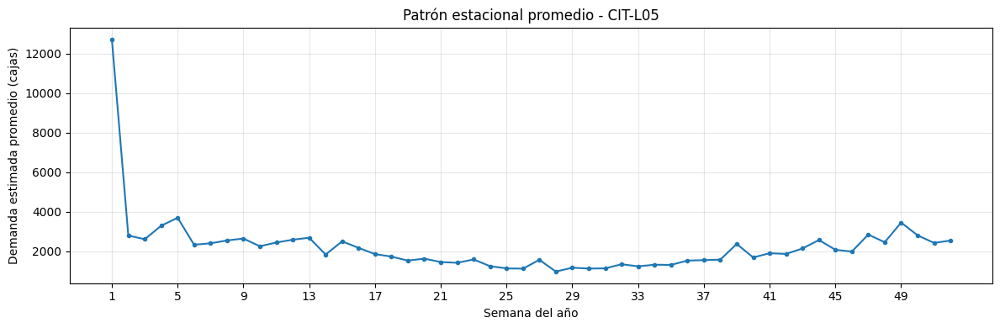

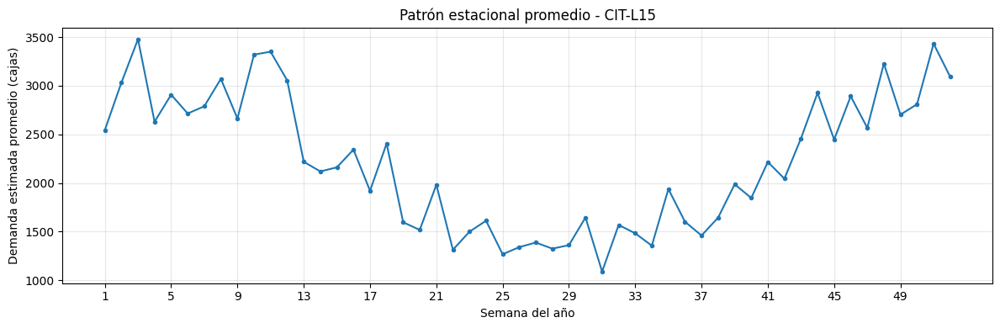

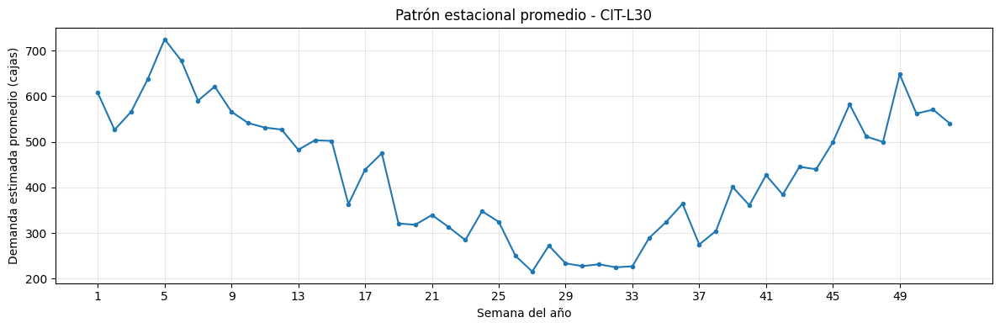

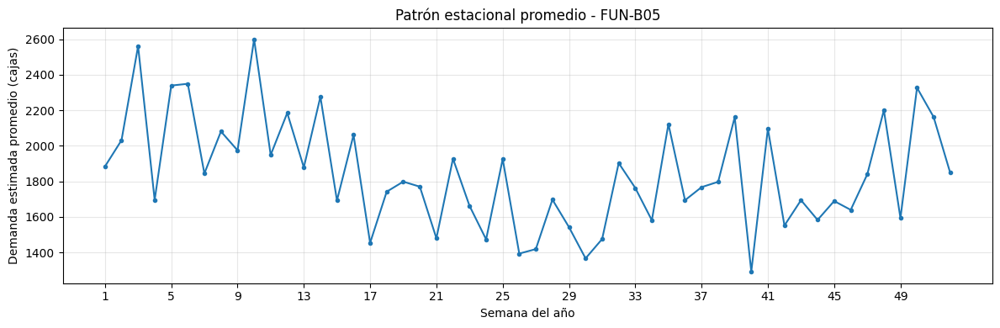

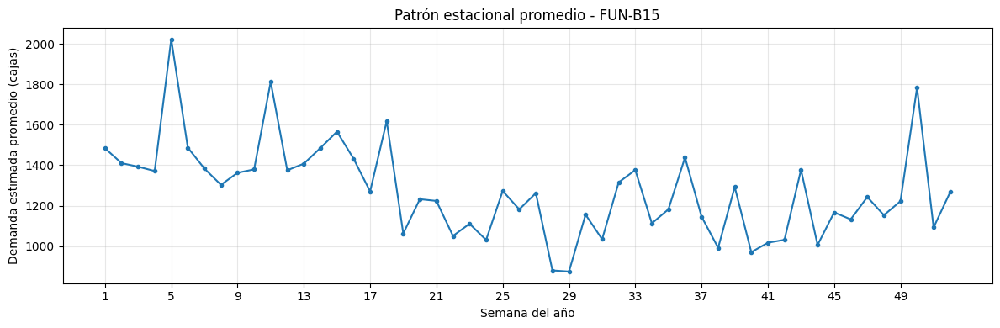

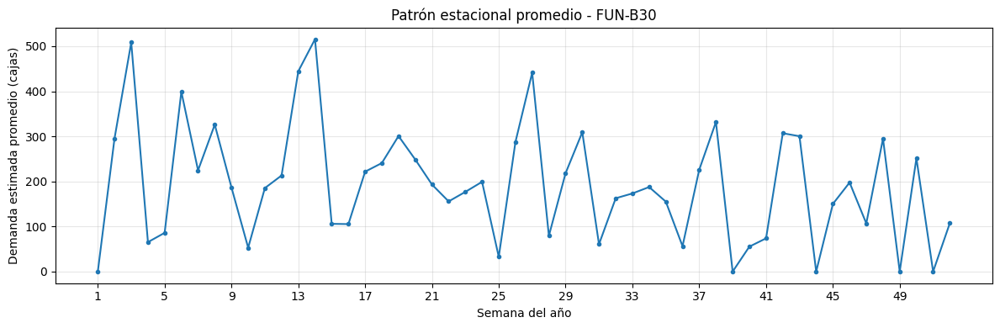

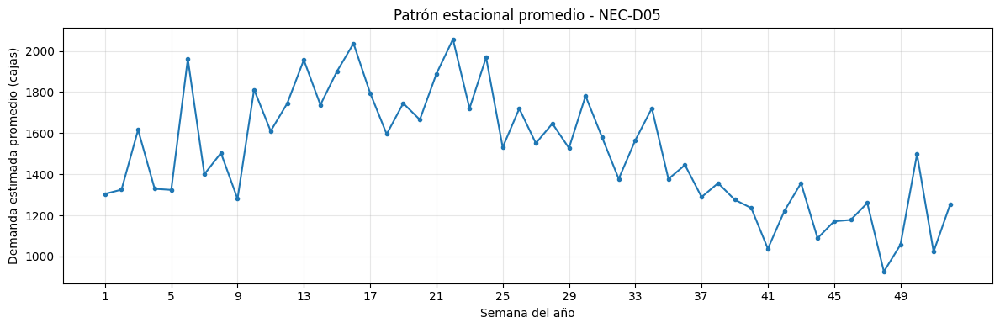

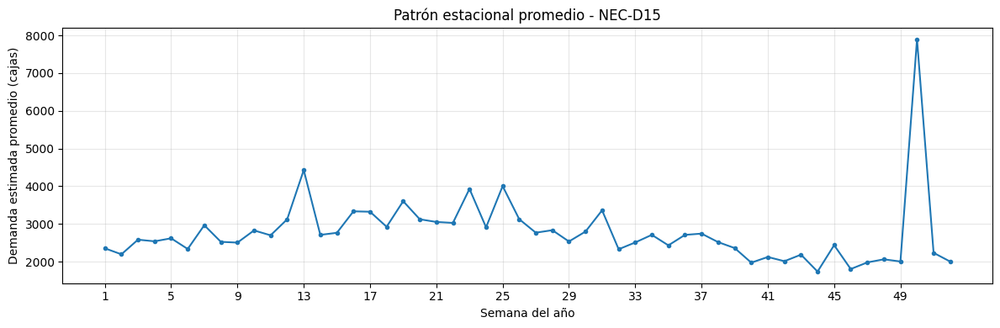

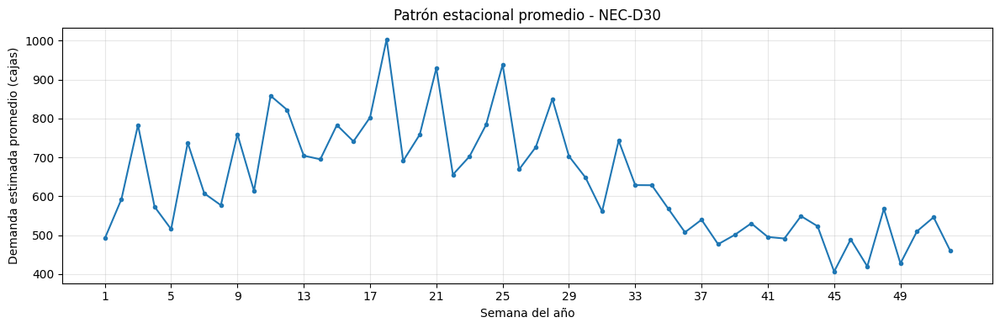

In [58]:
# Graficar el patrón estacional promedio de cada SKU
for sku in ventas_semanal["sku"].unique():

    datos_estacionales = estacionalidad_sku[
        estacionalidad_sku["sku"] == sku
    ].sort_values("semana_iso")

    plt.figure(figsize=(12, 4))

    plt.plot(
        datos_estacionales["semana_iso"],
        datos_estacionales["demanda_estimada"],
        marker="o",
        markersize=3
    )

    plt.title(f"Patrón estacional promedio - {sku}")
    plt.xlabel("Semana del año")
    plt.ylabel("Demanda estimada promedio (cajas)")

    # Mostrar una marca cada 4 semanas
    plt.xticks(range(1, 53, 4))

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

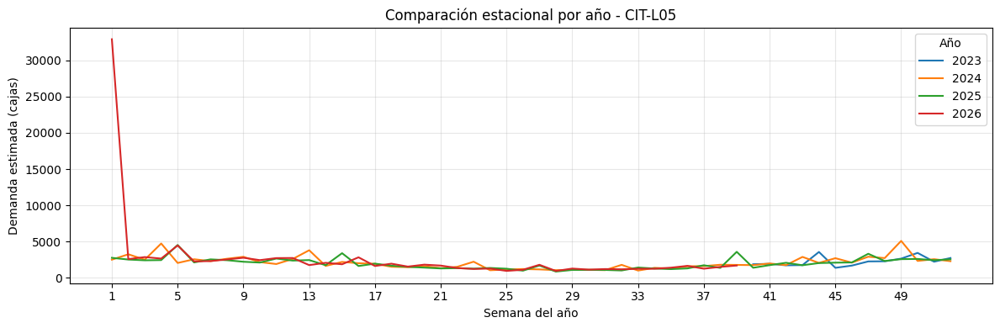

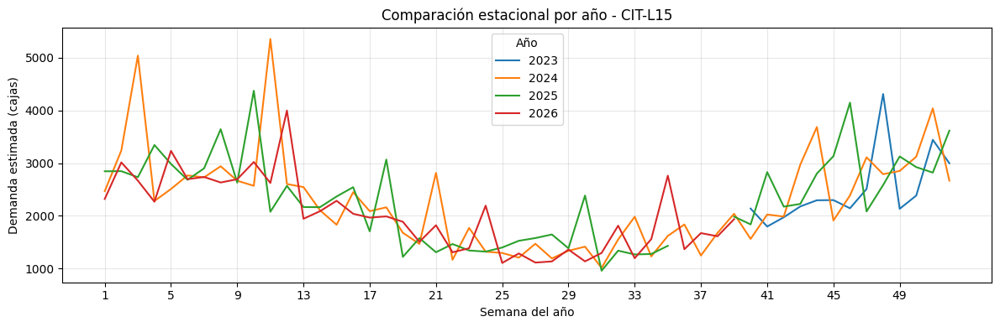

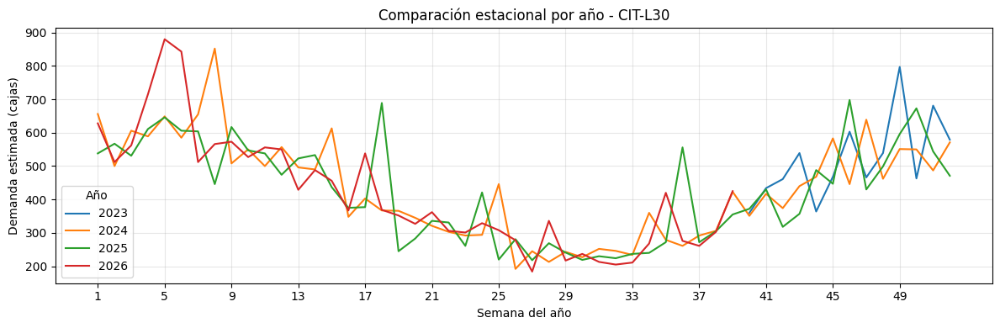

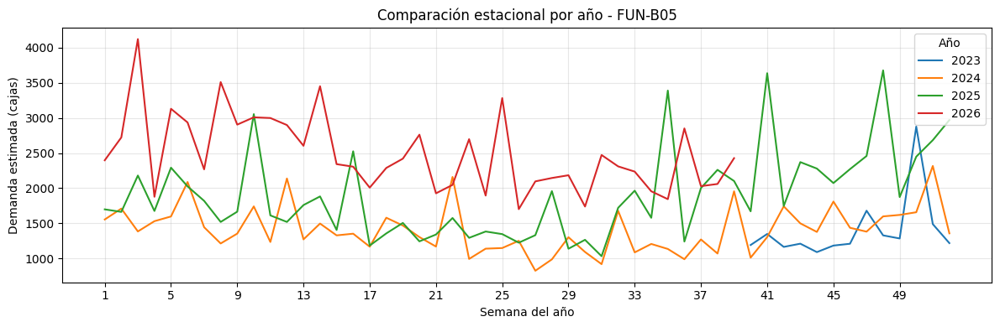

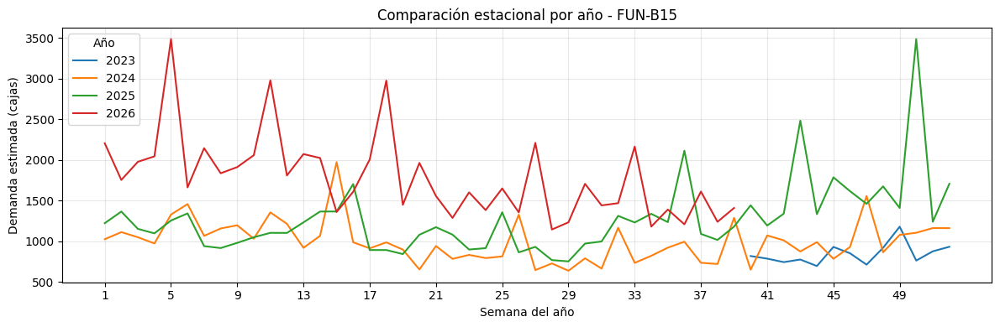

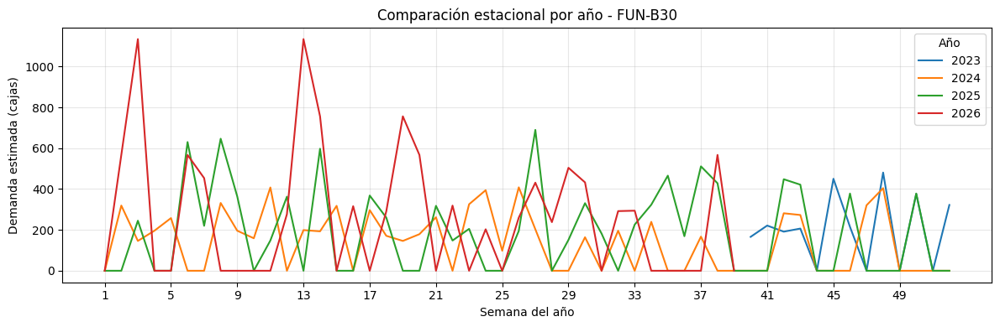

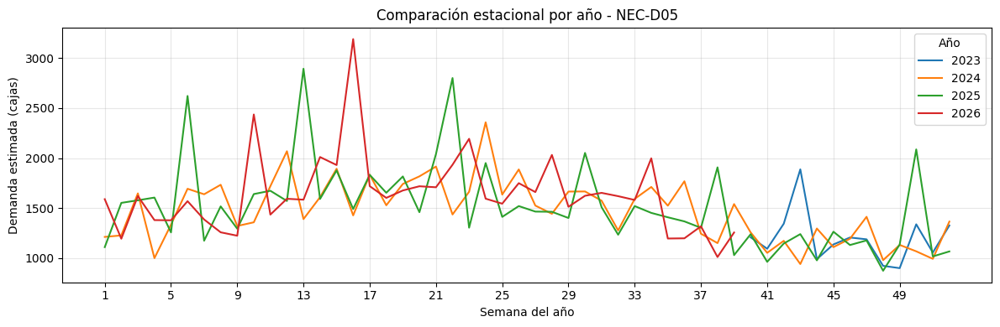

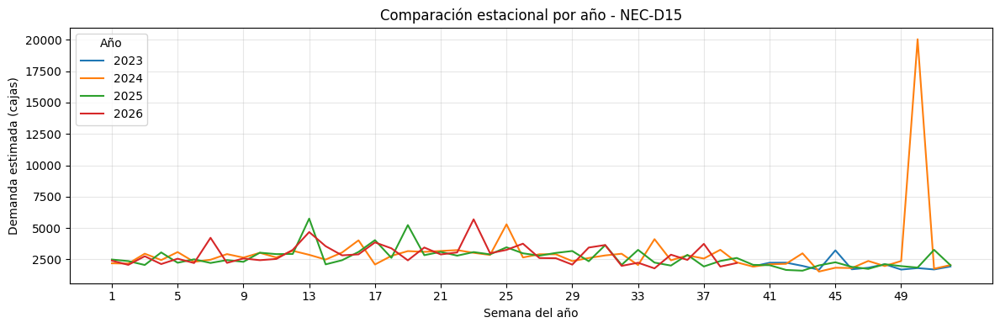

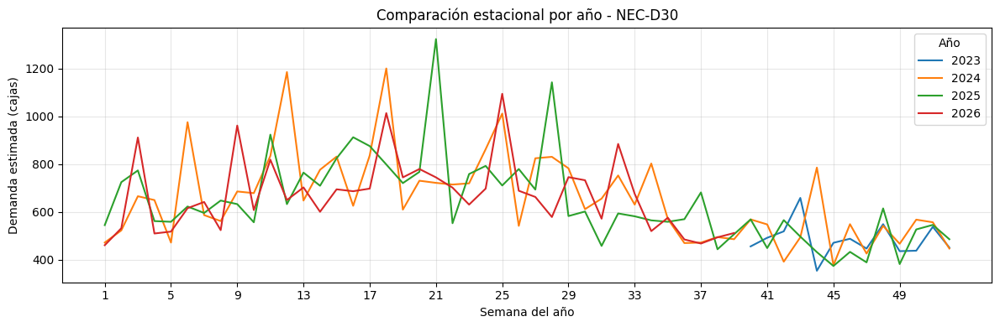

In [59]:
# Comparar el patrón estacional de cada año para cada SKU
for sku in ventas_semanal["sku"].unique():

    datos_sku = ventas_semanal[
        ventas_semanal["sku"] == sku
    ]

    plt.figure(figsize=(12, 4))

    for anio in sorted(datos_sku["anio_iso"].unique()):

        datos_anio = (
            datos_sku[
                datos_sku["anio_iso"] == anio
            ]
            .sort_values("semana_iso")
        )

        plt.plot(
            datos_anio["semana_iso"],
            datos_anio["demanda_estimada"],
            label=str(anio)
        )

    plt.title(f"Comparación estacional por año - {sku}")
    plt.xlabel("Semana del año")
    plt.ylabel("Demanda estimada (cajas)")

    # Mostrar una marca cada 4 semanas
    plt.xticks(range(1, 53, 4))

    plt.legend(title="Año")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [60]:
# Agregar la demanda estimada semanal a nivel de familia
demanda_familia = (
    ventas_semanal
    .groupby(
        ["fecha_lunes", "anio_iso", "semana_iso", "familia"],
        as_index=False
    )["demanda_estimada"]
    .sum(min_count=3)
)

display(demanda_familia.head())

,fecha_lunes,anio_iso,semana_iso,familia,demanda_estimada
0,2023-10-02,2023,40,CIT,4375.0
1,2023-10-02,2023,40,FUN,2176.0
2,2023-10-02,2023,40,NEC,3607.0
3,2023-10-09,2023,41,CIT,4164.0
4,2023-10-09,2023,41,FUN,2356.2


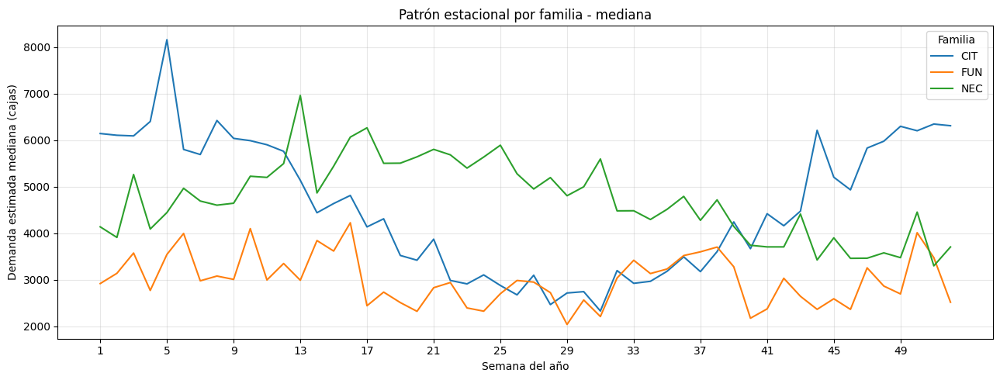

In [61]:
# Calcular un patrón estacional robusto por familia usando la mediana
estacionalidad_familia_mediana = (
    demanda_familia
    .groupby(["familia", "semana_iso"])["demanda_estimada"]
    .median()
    .reset_index()
)

plt.figure(figsize=(13, 5))

for familia in estacionalidad_familia_mediana["familia"].unique():

    datos_familia = (
        estacionalidad_familia_mediana[
            estacionalidad_familia_mediana["familia"] == familia
        ]
        .sort_values("semana_iso")
    )

    plt.plot(
        datos_familia["semana_iso"],
        datos_familia["demanda_estimada"],
        label=familia
    )

plt.title("Patrón estacional por familia - mediana")
plt.xlabel("Semana del año")
plt.ylabel("Demanda estimada mediana (cajas)")

# Mostrar una marca cada 4 semanas
plt.xticks(range(1, 53, 4))

plt.legend(title="Familia")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

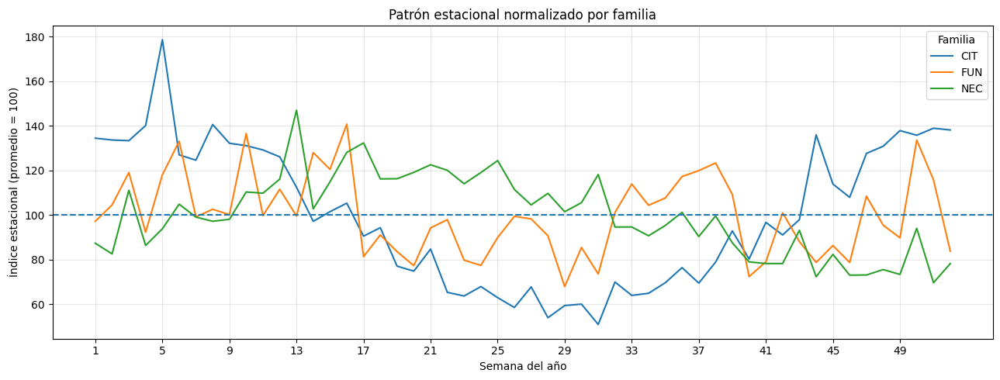

In [62]:
# Normalizar las familias para comparar únicamente la forma de su patrón estacional
patron_normalizado = estacionalidad_familia_mediana.copy()

# Convertir la demanda de cada familia en un índice con promedio igual a 100
patron_normalizado["indice_estacional"] = (
    patron_normalizado
    .groupby("familia")["demanda_estimada"]
    .transform(lambda x: 100 * x / x.mean())
)

plt.figure(figsize=(13, 5))

for familia in patron_normalizado["familia"].unique():

    datos_familia = (
        patron_normalizado[
            patron_normalizado["familia"] == familia
        ]
        .sort_values("semana_iso")
    )

    plt.plot(
        datos_familia["semana_iso"],
        datos_familia["indice_estacional"],
        label=familia
    )

# Línea de referencia: valor promedio de cada familia
plt.axhline(100, linestyle="--")

plt.title("Patrón estacional normalizado por familia")
plt.xlabel("Semana del año")
plt.ylabel("Índice estacional (promedio = 100)")

# Mostrar una marca cada 4 semanas
plt.xticks(range(1, 53, 4))

plt.legend(title="Familia")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

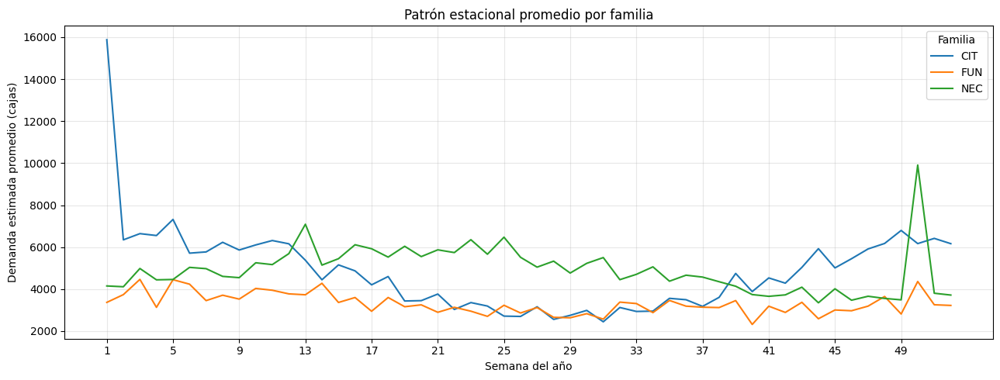

In [63]:
# Calcular el patrón estacional promedio por familia
estacionalidad_familia = (
    demanda_familia
    .groupby(["familia", "semana_iso"])["demanda_estimada"]
    .mean()
    .reset_index()
)
# Graficar el patrón estacional promedio por familia
plt.figure(figsize=(13, 5))

for familia in estacionalidad_familia["familia"].unique():

    datos_familia = (
        estacionalidad_familia[
            estacionalidad_familia["familia"] == familia
        ]
        .sort_values("semana_iso")
    )

    plt.plot(
        datos_familia["semana_iso"],
        datos_familia["demanda_estimada"],
        label=familia
    )

plt.title("Patrón estacional promedio por familia")
plt.xlabel("Semana del año")
plt.ylabel("Demanda estimada promedio (cajas)")

# Mostrar una marca cada 4 semanas
plt.xticks(range(1, 53, 4))

plt.legend(title="Familia")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [64]:
# Medir la similitud entre la demanda actual y la observada 52 semanas antes
correlaciones_52 = []

for sku, grupo in ventas_semanal.groupby("sku"):

    serie = (
        grupo
        .sort_values("fecha_lunes")["demanda_estimada"]
    )

    correlacion = serie.corr(serie.shift(52))

    correlaciones_52.append({
        "sku": sku,
        "correlacion_lag_52": correlacion
    })

correlaciones_52 = pd.DataFrame(correlaciones_52)

# Mostrar primero los SKU con mayor correlación anual
display(
    correlaciones_52.sort_values(
        "correlacion_lag_52",
        ascending=False
    )
)

,sku,correlacion_lag_52
2,CIT-L30,0.703141
1,CIT-L15,0.553160
8,NEC-D30,0.433377
6,NEC-D05,0.320283
3,FUN-B05,0.310661
0,CIT-L05,0.229825
4,FUN-B15,0.208424
5,FUN-B30,0.074094
7,NEC-D15,-0.032981


#Tendencia y quiebres estructurales

In [65]:
# Calcular una mediana móvil de 13 semanas para suavizar la demanda estimada
ventas_semanal["mediana_movil_13"] = (
    ventas_semanal
    .groupby("sku")["demanda_estimada"]
    .transform(
        lambda x: x.rolling(
            window=13,
            min_periods=6
        ).median()
    )
)

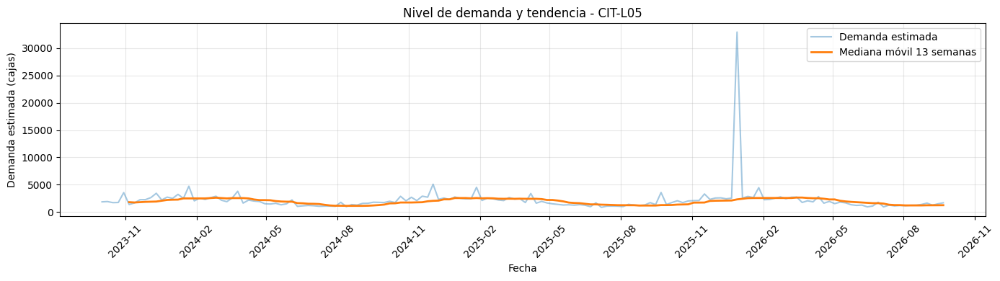

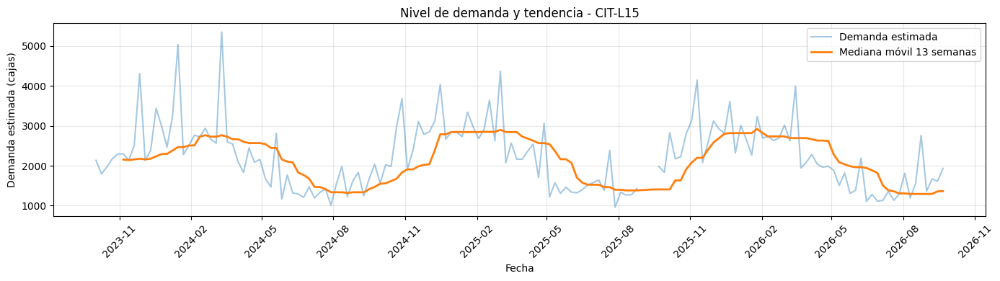

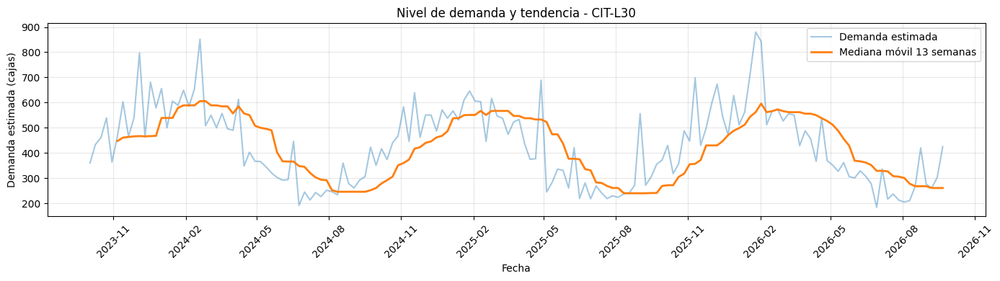

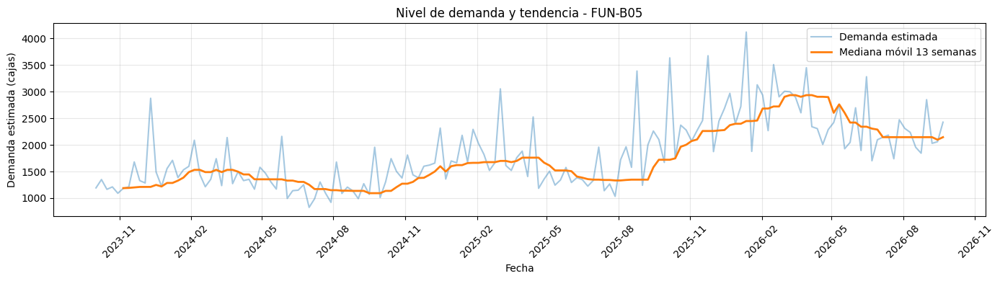

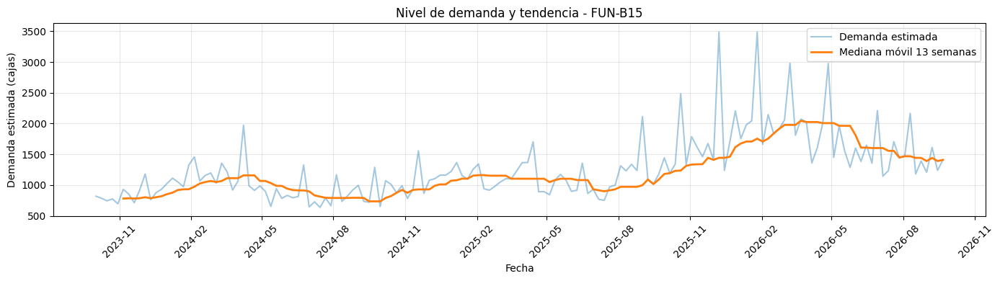

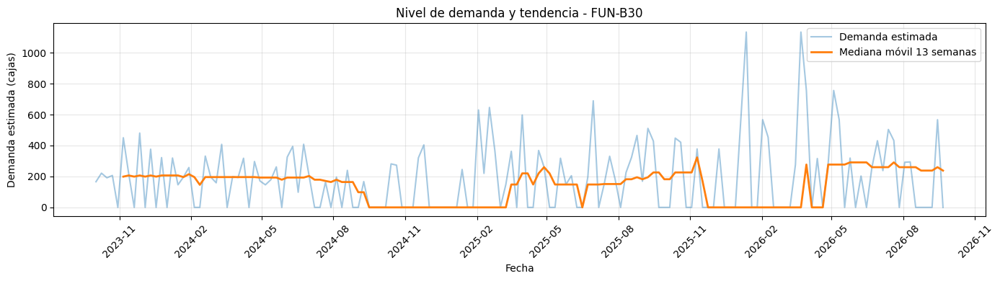

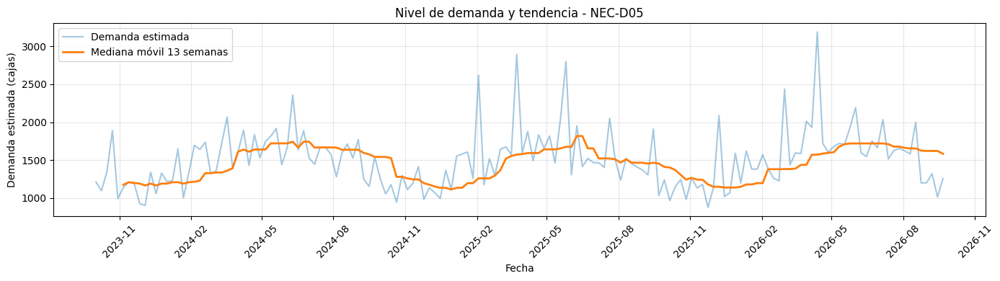

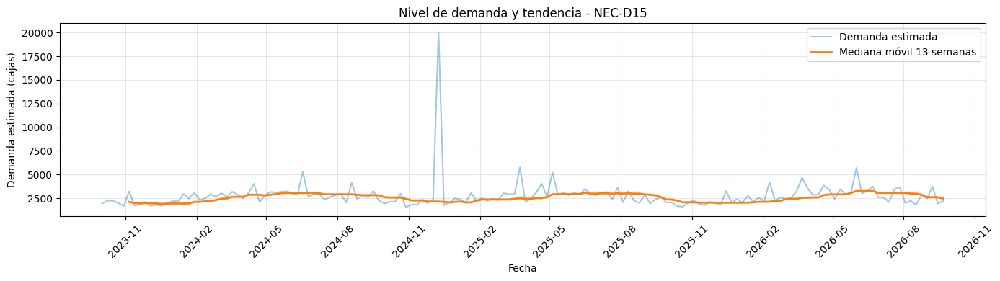

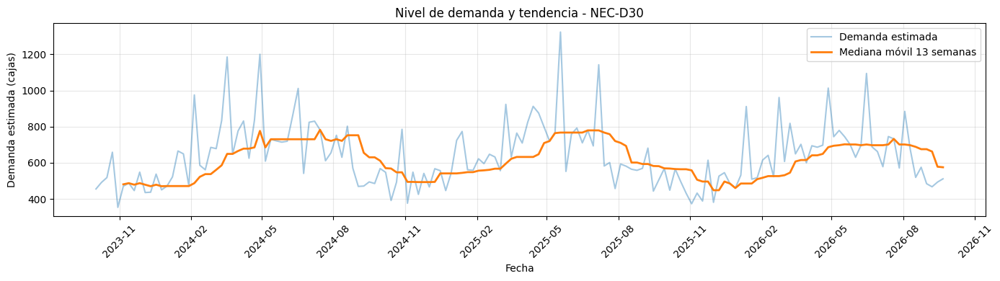

In [66]:
# Graficar la demanda estimada junto con su tendencia suavizada de 13 semanas
for sku in ventas_semanal["sku"].unique():

    datos_sku = ventas_semanal[
        ventas_semanal["sku"] == sku
    ]

    fig, ax = plt.subplots(figsize=(14, 4))

    # Serie original de demanda estimada
    ax.plot(
        datos_sku["fecha_lunes"],
        datos_sku["demanda_estimada"],
        alpha=0.4,
        label="Demanda estimada"
    )

    # Tendencia suavizada mediante mediana móvil
    ax.plot(
        datos_sku["fecha_lunes"],
        datos_sku["mediana_movil_13"],
        linewidth=2,
        label="Mediana móvil 13 semanas"
    )

    ax.set_title(f"Nivel de demanda y tendencia - {sku}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Demanda estimada (cajas)")

    # Mostrar una marca temporal cada 3 meses
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=3)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    ax.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [67]:
# Crear bloques consecutivos de 52 semanas para cada SKU
ventas_semanal["bloque_52"] = (
    ventas_semanal
    .groupby("sku")
    .cumcount() // 52 + 1
)

# Resumir el nivel de demanda de cada SKU en bloques consecutivos de 52 semanas
resumen_bloques = (
    ventas_semanal
    .groupby(["sku", "bloque_52"])["demanda_estimada"]
    .agg(
        promedio="mean",
        mediana="median",
        minimo="min",
        maximo="max",
        observaciones="count"
    )
    .reset_index()
)

display(resumen_bloques)

,sku,bloque_52,promedio,mediana,minimo,maximo,observaciones
0,CIT-L05,1,2004.423077,1843.0,1008.0,4738.000000,52
1,CIT-L05,2,2048.423077,1970.5,866.0,5097.000000,52
2,CIT-L05,3,2559.884615,1848.0,952.0,32916.000000,52
3,CIT-L15,1,2216.480769,2135.0,1012.0,5352.000000,52
4,CIT-L15,2,2268.346939,2166.0,958.0,4372.000000,49
5,CIT-L15,3,2210.673077,2131.0,1106.0,4147.000000,52
6,CIT-L30,1,438.807692,440.0,192.0,852.000000,52
7,CIT-L30,2,423.346154,438.5,218.0,689.000000,52
8,CIT-L30,3,432.942308,427.0,184.0,880.000000,52
9,FUN-B05,1,1377.653846,1278.5,826.0,2876.000000,52


In [68]:
# Comparar la mediana de demanda entre los tres bloques de 52 semanas
medianas_bloques = (
    resumen_bloques
    .pivot(
        index="sku",
        columns="bloque_52",
        values="mediana"
    )
)

# Renombrar las columnas para facilitar su interpretación
medianas_bloques.columns = [
    "bloque_1",
    "bloque_2",
    "bloque_3"
]

# Calcular el cambio porcentual de la mediana entre el bloque 1 y el bloque 2
medianas_bloques["cambio_1_a_2_pct"] = (
    100 *
    (
        medianas_bloques["bloque_2"] -
        medianas_bloques["bloque_1"]
    )
    /
    medianas_bloques["bloque_1"]
)

# Calcular el cambio porcentual de la mediana entre el bloque 2 y el bloque 3
medianas_bloques["cambio_2_a_3_pct"] = (
    100 *
    (
        medianas_bloques["bloque_3"] -
        medianas_bloques["bloque_2"]
    )
    /
    medianas_bloques["bloque_2"]
)

display(medianas_bloques)

,bloque_1,bloque_2,bloque_3,cambio_1_a_2_pct,cambio_2_a_3_pct
sku,,,,,
CIT-L05,1843.0,1970.5,1848.0,6.918068,-6.216696
CIT-L15,2135.0,2166.0,2131.0,1.451991,-1.615882
CIT-L30,440.0,438.5,427.0,-0.340909,-2.622577
FUN-B05,1278.5,1589.0,2356.5,24.286273,48.300818
FUN-B15,919.5,1080.5,1632.5,17.509516,51.087460
FUN-B30,175.0,149.5,0.0,-14.571429,-100.000000
NEC-D05,1525.5,1456.5,1557.5,-4.523107,6.934432
NEC-D15,2645.0,2494.0,2493.5,-5.708885,-0.020048
NEC-D30,627.5,594.0,603.5,-5.338645,1.599327


#Cerrar diagnósticos y anomalías

In [69]:
# Crear banderas de diagnóstico para identificar anomalías en cada observación

# Calcular Q1 y Q3 de ventas para cada SKU
Q1 = ventas_semanal.groupby("sku")["ventas_cajas"].transform(
    lambda x: x.quantile(0.25)
)

Q3 = ventas_semanal.groupby("sku")["ventas_cajas"].transform(
    lambda x: x.quantile(0.75)
)

# Calcular el rango intercuartílico
IQR = Q3 - Q1

# Definir límites IQR para cada observación según su SKU
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar valores atípicos según el criterio IQR
ventas_semanal["es_outlier_iqr"] = (
    (ventas_semanal["ventas_cajas"] < limite_inferior) |
    (ventas_semanal["ventas_cajas"] > limite_superior)
)

# Identificar observaciones con demanda estimada faltante
ventas_semanal["es_faltante"] = (
    ventas_semanal["demanda_estimada"].isna()
)

# Identificar semanas con quiebre de stock
ventas_semanal["es_stockout"] = (
    ventas_semanal["dias_sin_stock"] > 0
)

# Identificar semanas con promoción
ventas_semanal["es_promocion"] = (
    ventas_semanal["promocion"] == 1
)

# Identificar semanas con ventas iguales a cero
ventas_semanal["es_cero"] = (
    ventas_semanal["ventas_cajas"] == 0
)

print("Cantidad de outliers IQR:")
print(ventas_semanal["es_outlier_iqr"].sum())

Cantidad de outliers IQR:
31


In [70]:
# Revisar el descuento porcentual calculado
ventas_semanal[
    [
        "precio_lista_clp",
        "precio_efectivo_clp",
        "descuento_pct"
    ]
].head()

,precio_lista_clp,precio_efectivo_clp,descuento_pct
0,5320,5320,0.000000
1,5320,5320,0.000000
2,5320,5320,0.000000
3,5320,5320,0.000000
4,5320,3877,0.271241


In [71]:
# Revisar los valores atípicos junto con posibles factores que puedan explicarlos
revision_outliers = ventas_semanal.loc[
    ventas_semanal["es_outlier_iqr"],
    [
        "fecha_lunes",
        "sku",
        "ventas_cajas",
        "demanda_estimada",
        "promocion",
        "descuento_pct",
        "dias_sin_stock",
        "es_stockout"
    ]
].sort_values(
    ["sku", "fecha_lunes"]
)

display(revision_outliers)

,fecha_lunes,sku,ventas_cajas,demanda_estimada,promocion,descuento_pct,dias_sin_stock,es_stockout
16,2024-01-22,CIT-L05,4738.0,4738.0,1,0.198684,0.0,False
61,2024-12-02,CIT-L05,5097.0,5097.0,1,0.246992,0.0,False
69,2025-01-27,CIT-L05,4533.0,4533.0,1,0.200376,0.0,False
117,2025-12-29,CIT-L05,32916.0,32916.0,0,0.000000,0.0,False
121,2026-01-26,CIT-L05,4470.0,4470.0,1,0.174436,0.0,False
171,2024-01-15,CIT-L15,5038.0,5038.0,1,0.227694,0.0,False
179,2024-03-11,CIT-L15,5352.0,5352.0,1,0.175940,0.0,False
580,2025-11-24,FUN-B05,3675.0,3675.0,1,0.159073,0.0,False
587,2026-01-12,FUN-B05,4120.0,4120.0,1,0.298185,0.0,False
731,2025-10-20,FUN-B15,2483.0,2483.0,1,0.266734,0.0,False


In [72]:
# Clasificar los outliers según si coinciden con promoción y/o quiebre de stock
resumen_outliers = (
    ventas_semanal.loc[
        ventas_semanal["es_outlier_iqr"]
    ]
    .groupby(
        ["es_promocion", "es_stockout"]
    )
    .size()
    .reset_index(name="cantidad")
)

display(resumen_outliers)

,es_promocion,es_stockout,cantidad
0,False,False,1
1,True,False,28
2,True,True,2


In [73]:
# Comparar cada observación con la mediana de demanda de su propio SKU
ventas_semanal["mediana_sku"] = (
    ventas_semanal
    .groupby("sku")["demanda_estimada"]
    .transform("median")
)

# Calcular cuántas veces la demanda estimada supera o representa la mediana de su SKU
ventas_semanal["factor_vs_mediana"] = np.where(
    ventas_semanal["mediana_sku"] > 0,
    ventas_semanal["demanda_estimada"] /
    ventas_semanal["mediana_sku"],
    np.nan
)

# Revisar los outliers ordenados según su distancia relativa respecto a la mediana
display(
    ventas_semanal.loc[
        ventas_semanal["es_outlier_iqr"],
        [
            "fecha_lunes",
            "sku",
            "demanda_estimada",
            "mediana_sku",
            "factor_vs_mediana",
            "promocion",
            "descuento_pct",
            "dias_sin_stock"
        ]
    ]
    .sort_values(
        "factor_vs_mediana",
        ascending=False
    )
)

,fecha_lunes,sku,demanda_estimada,mediana_sku,factor_vs_mediana,promocion,descuento_pct,dias_sin_stock
117,2025-12-29,CIT-L05,32916.0,1876.0,17.545842,0,0.000000,0.0
1154,2024-12-09,NEC-D15,20052.0,2558.0,7.838937,1,0.177241,0.0
745,2026-01-26,FUN-B15,3486.0,1164.0,2.994845,1,0.247043,1.0
738,2025-12-08,FUN-B15,3486.0,1164.0,2.994845,1,0.163575,1.0
61,2024-12-02,CIT-L05,5097.0,1876.0,2.716951,1,0.246992,0.0
751,2026-03-09,FUN-B15,2979.0,1164.0,2.559278,1,0.215390,0.0
758,2026-04-27,FUN-B15,2976.0,1164.0,2.556701,1,0.150739,0.0
16,2024-01-22,CIT-L05,4738.0,1876.0,2.525586,1,0.198684,0.0
179,2024-03-11,CIT-L15,5352.0,2143.0,2.497434,1,0.175940,0.0
587,2026-01-12,FUN-B05,4120.0,1679.0,2.453842,1,0.298185,0.0


In [74]:
# Marcar un outlier extremo que no presenta una explicación observable
ventas_semanal["outlier_extremo_sin_explicacion"] = (
    (ventas_semanal["sku"] == "CIT-L05") &
    (ventas_semanal["fecha_lunes"] == pd.Timestamp("2025-12-29"))
)

# Revisar las características de la observación identificada
display(
    ventas_semanal.loc[
        ventas_semanal["outlier_extremo_sin_explicacion"],
        [
            "fecha_lunes",
            "sku",
            "ventas_cajas",
            "demanda_estimada",
            "promocion",
            "descuento_pct",
            "dias_sin_stock",
            "factor_vs_mediana"
        ]
    ]
)

,fecha_lunes,sku,ventas_cajas,demanda_estimada,promocion,descuento_pct,dias_sin_stock,factor_vs_mediana
117,2025-12-29,CIT-L05,32916.0,32916.0,0,0.0,0.0,17.545842


In [75]:
# Marcar las observaciones pertenecientes a la serie identificada como intermitente
ventas_semanal["serie_intermitente"] = (
    ventas_semanal["sku"] == "FUN-B30"
)

In [76]:
# Resumir los principales indicadores de diagnóstico para cada SKU
diagnostico_sku = (
    ventas_semanal
    .groupby("sku")
    .agg(
        semanas=("sku", "size"),
        faltantes=("es_faltante", "sum"),
        outliers=("es_outlier_iqr", "sum"),
        promociones=("es_promocion", "sum"),
        semanas_stockout=("es_stockout", "sum"),
        semanas_cero=("es_cero", "sum")
    )
)

# Calcular el porcentaje de semanas con ventas iguales a cero
diagnostico_sku["porcentaje_ceros"] = (
    100 *
    diagnostico_sku["semanas_cero"] /
    diagnostico_sku["semanas"]
)

display(diagnostico_sku)

,semanas,faltantes,outliers,promociones,semanas_stockout,semanas_cero,porcentaje_ceros
sku,,,,,,,
CIT-L05,156,0,5,17,1,0,0.000000
CIT-L15,156,3,2,16,0,0,0.000000
CIT-L30,156,0,0,17,0,0,0.000000
FUN-B05,156,0,2,17,0,0,0.000000
FUN-B15,156,0,5,18,2,0,0.000000
FUN-B30,156,0,0,17,55,69,44.230769
NEC-D05,156,0,6,16,0,0,0.000000
NEC-D15,156,0,6,18,0,0,0.000000
NEC-D30,156,0,5,18,0,0,0.000000


In [77]:

diagnostico_cualitativo = pd.DataFrame({

    "sku": [
        "CIT-L05",
        "CIT-L15",
        "CIT-L30",
        "FUN-B05",
        "FUN-B15",
        "FUN-B30",
        "NEC-D05",
        "NEC-D15",
        "NEC-D30"
    ],

    "estacionalidad": [
        "Débil / distorsionada por outlier extremo",
        "Clara",
        "Fuerte",
        "Débil-moderada",
        "Débil",
        "No clara",
        "Moderada",
        "No clara / distorsionada por peak promocional",
        "Moderada"
    ],

    "tendencia": [
        "No",
        "No",
        "No",
        "Creciente",
        "Creciente",
        "No interpretable por intermitencia",
        "No",
        "No",
        "No"
    ],

    "observacion_principal": [
        "Outlier extremo sin explicación observable",
        "3 datos faltantes",
        "Estacionalidad anual marcada",
        "Aumento importante de nivel",
        "Aumento importante de nivel",
        "Alta intermitencia y stockouts",
        "Outliers asociados a promociones",
        "Peak promocional extremo",
        "Outliers asociados a promociones"
    ]
})

display(diagnostico_cualitativo)

,sku,estacionalidad,tendencia,observacion_principal
0,CIT-L05,Débil / distorsionada por outlier extremo,No,Outlier extremo sin explicación observable
1,CIT-L15,Clara,No,3 datos faltantes
2,CIT-L30,Fuerte,No,Estacionalidad anual marcada
3,FUN-B05,Débil-moderada,Creciente,Aumento importante de nivel
4,FUN-B15,Débil,Creciente,Aumento importante de nivel
5,FUN-B30,No clara,No interpretable por intermitencia,Alta intermitencia y stockouts
6,NEC-D05,Moderada,No,Outliers asociados a promociones
7,NEC-D15,No clara / distorsionada por peak promocional,No,Peak promocional extremo
8,NEC-D30,Moderada,No,Outliers asociados a promociones


In [78]:
# Tabla final de diagnóstico por SKU
diagnostico_final = (
    diagnostico_sku
    .reset_index()
    .merge(
        diagnostico_cualitativo,
        on="sku",
        how="left"
    )
)

display(diagnostico_final)

,sku,semanas,faltantes,outliers,promociones,semanas_stockout,semanas_cero,porcentaje_ceros,estacionalidad,tendencia,observacion_principal
0,CIT-L05,156,0,5,17,1,0,0.000000,Débil / distorsionada por outlier extremo,No,Outlier extremo sin explicación observable
1,CIT-L15,156,3,2,16,0,0,0.000000,Clara,No,3 datos faltantes
2,CIT-L30,156,0,0,17,0,0,0.000000,Fuerte,No,Estacionalidad anual marcada
3,FUN-B05,156,0,2,17,0,0,0.000000,Débil-moderada,Creciente,Aumento importante de nivel
4,FUN-B15,156,0,5,18,2,0,0.000000,Débil,Creciente,Aumento importante de nivel
5,FUN-B30,156,0,0,17,55,69,44.230769,No clara,No interpretable por intermitencia,Alta intermitencia y stockouts
6,NEC-D05,156,0,6,16,0,0,0.000000,Moderada,No,Outliers asociados a promociones
7,NEC-D15,156,0,6,18,0,0,0.000000,No clara / distorsionada por peak promocional,No,Peak promocional extremo
8,NEC-D30,156,0,5,18,0,0,0.000000,Moderada,No,Outliers asociados a promociones


In [79]:
# PASO 13.11: TABLA DE DECISIONES

decisiones = pd.DataFrame({

    "problema": [
        "3 datos faltantes de CIT-L15",
        "Quiebres de stock",
        "Outliers asociados a promoción",
        "Outliers con promoción y stockout",
        "Outlier CIT-L05 del 2025-12-29",
        "Intermitencia de FUN-B30",
        "Tendencia de FUN-B05 y FUN-B15"
    ],

    "como_se_detecto": [
        "Valores NaN consecutivos",
        "dias_sin_stock > 0",
        "IQR y promocion = 1",
        "IQR, promocion = 1 y dias_sin_stock > 0",
        "IQR; 17.5 veces la mediana; sin promoción ni stockout",
        "69 semanas con ventas cero (44.23 %)",
        "Mediana móvil y comparación de bloques de 52 semanas"
    ],

    "tratamiento": [
        "Mantener NaN por ahora; imputar usando solo información del entrenamiento",
        "Utilizar demanda_estimada corregida por días con stock",
        "Conservar porque pueden representar demanda promocional real",
        "Conservar el efecto promocional y utilizar demanda_estimada corregida",
        "Mantener identificado y realizar análisis de sensibilidad",
        "Revisar ceros frente a stockouts; conservar como ceros aquellos no explicados por falta de stock y considerar la serie como intermitente.",
        "Conservar los datos y utilizar modelos capaces de capturar tendencia"
    ]
})
decisiones.loc[
    decisiones["problema"] == "Intermitencia de FUN-B30",
    "tratamiento"
] = (
    "Conservar las 69 semanas con ventas cero, ya que ninguna coincide "
    "con quiebre de stock; tratar FUN-B30 como serie intermitente"
)
pd.set_option("display.max_colwidth", None)
display(decisiones)

,problema,como_se_detecto,tratamiento
0,3 datos faltantes de CIT-L15,Valores NaN consecutivos,Mantener NaN por ahora; imputar usando solo información del entrenamiento
1,Quiebres de stock,dias_sin_stock > 0,Utilizar demanda_estimada corregida por días con stock
2,Outliers asociados a promoción,IQR y promocion = 1,Conservar porque pueden representar demanda promocional real
3,Outliers con promoción y stockout,"IQR, promocion = 1 y dias_sin_stock > 0",Conservar el efecto promocional y utilizar demanda_estimada corregida
4,Outlier CIT-L05 del 2025-12-29,IQR; 17.5 veces la mediana; sin promoción ni stockout,Mantener identificado y realizar análisis de sensibilidad
5,Intermitencia de FUN-B30,69 semanas con ventas cero (44.23 %),"Conservar las 69 semanas con ventas cero, ya que ninguna coincide con quiebre de stock; tratar FUN-B30 como serie intermitente"
6,Tendencia de FUN-B05 y FUN-B15,Mediana móvil y comparación de bloques de 52 semanas,Conservar los datos y utilizar modelos capaces de capturar tendencia


In [80]:
# Cruzar semanas con ventas cero y quiebres de stock en FUN-B30

fun_b30 = ventas_semanal[
    ventas_semanal["sku"] == "FUN-B30"
].copy()

tabla_ceros_stockout = pd.crosstab(
    fun_b30["es_cero"],
    fun_b30["es_stockout"],
    margins=True
)

display(tabla_ceros_stockout)

# Mostrar semanas de FUN-B30 donde hubo ventas cero y quiebre de stock simultáneamente
display(
    ventas_semanal.loc[
        (ventas_semanal["sku"] == "FUN-B30") &
        (ventas_semanal["ventas_cajas"] == 0) &
        (ventas_semanal["dias_sin_stock"] > 0),
        [
            "fecha_lunes",
            "ventas_cajas",
            "dias_sin_stock",
            "demanda_estimada",
            "promocion"
        ]
    ]
)

es_stockout,False,True,All
es_cero,,,
False,32,55,87
True,69,0,69
All,101,55,156


,fecha_lunes,ventas_cajas,dias_sin_stock,demanda_estimada,promocion


#Preparar serie para modelar

In [81]:
# Crear la base que se utilizará para el modelado
base_modelado = (
    ventas_semanal
    .copy()
    .sort_values(["sku", "fecha_lunes"])
    .reset_index(drop=True)
)

print("Dimensiones de la base de modelado:", base_modelado.shape)


# Función para imputar valores faltantes utilizando únicamente
# información disponible en el conjunto de entrenamiento
def imputar_faltantes_train(train):

    train = (
        train
        .copy()
        .sort_values(["sku", "fecha_lunes"])
        .reset_index(drop=True)
    )

    # Crear la variable que utilizarán los modelos de pronóstico
    train["y_modelo"] = train["demanda_estimada"].astype(float)

    # Identificar posteriormente qué observaciones fueron imputadas
    train["fue_imputado"] = False

    # Obtener la demanda del mismo SKU observada 52 semanas antes
    train["lag_52"] = (
        train
        .groupby("sku")["y_modelo"]
        .shift(52)
    )

    # Identificar valores faltantes que disponen de información
    # correspondiente a 52 semanas atrás
    mask_faltante = (
        train["y_modelo"].isna() &
        train["lag_52"].notna()
    )

    # Imputar los faltantes utilizando el valor de 52 semanas atrás
    train.loc[
        mask_faltante,
        "y_modelo"
    ] = train.loc[
        mask_faltante,
        "lag_52"
    ]

    # Marcar las observaciones que fueron imputadas
    train.loc[
        mask_faltante,
        "fue_imputado"
    ] = True

    return train

Dimensiones de la base de modelado: (1404, 27)


In [82]:
# Probar la función de imputación sobre la base completa
prueba_imputacion = imputar_faltantes_train(
    base_modelado
)

# Mostrar únicamente las observaciones que fueron imputadas
display(
    prueba_imputacion.loc[
        prueba_imputacion["fue_imputado"],
        [
            "fecha_lunes",
            "sku",
            "demanda_estimada",
            "lag_52",
            "y_modelo",
            "promocion"
        ]
    ]
)

# Comparar la cantidad de faltantes antes y después de la imputación
print(
    "Faltantes originales:",
    base_modelado["demanda_estimada"].isna().sum()
)

print(
    "Faltantes después de imputar:",
    prueba_imputacion["y_modelo"].isna().sum()
)

,fecha_lunes,sku,demanda_estimada,lag_52,y_modelo,promocion
256,2025-09-01,CIT-L15,NaN,1836.0,1836.0,0
257,2025-09-08,CIT-L15,NaN,1247.0,1247.0,1
258,2025-09-15,CIT-L15,NaN,1675.0,1675.0,0


Faltantes originales: 3
Faltantes después de imputar: 0


In [83]:
# Tratar el outlier extremo de CIT-L05 únicamente en el escenario robusto
def tratar_outlier_extremo_train(train):

    train = train.copy()

    fecha_outlier = pd.Timestamp("2025-12-29")
    sku_outlier = "CIT-L05"

    # Identificar la observación extrema dentro del conjunto de entrenamiento
    mask_outlier = (
        (train["sku"] == sku_outlier) &
        (train["fecha_lunes"] == fecha_outlier)
    )

    # Si el outlier aún no forma parte del train, no se realiza ningún ajuste
    if not mask_outlier.any():
        return train

    # Buscar observaciones equivalentes de 52 y 104 semanas antes
    fechas_referencia = [
        fecha_outlier - pd.Timedelta(weeks=52),
        fecha_outlier - pd.Timedelta(weeks=104)
    ]

    valores_historicos = train.loc[
        (train["sku"] == sku_outlier) &
        (train["fecha_lunes"].isin(fechas_referencia)),
        "y_modelo"
    ].dropna()

    # Reemplazar el outlier por la mediana de sus referencias históricas
    if len(valores_historicos) > 0:

        valor_robusto = valores_historicos.median()

        train.loc[
            mask_outlier,
            "y_modelo"
        ] = valor_robusto

    return train

In [84]:
# Preparar el conjunto de entrenamiento antes de ajustar los modelos
def preparar_train(
    train,
    corregir_outlier_extremo=False
):

    # Imputar los valores faltantes utilizando solo información pasada
    train_preparado = imputar_faltantes_train(train)

    # Corregir opcionalmente el outlier extremo de CIT-L05
    if corregir_outlier_extremo:

        train_preparado = tratar_outlier_extremo_train(
            train_preparado
        )

    return train_preparado

In [85]:
# Comparar el valor del outlier de CIT-L05 entre el escenario original y el robusto

# Escenario original: mantiene el outlier sin corregir
escenario_original = preparar_train(
    base_modelado,
    corregir_outlier_extremo=False
)

# Escenario robusto: reemplaza el outlier por una referencia histórica
escenario_robusto = preparar_train(
    base_modelado,
    corregir_outlier_extremo=True
)

# Comparar el valor utilizado por los modelos en ambos escenarios
comparacion_outlier = pd.DataFrame({

    "escenario": [
        "Original",
        "Robusto"
    ],

    "valor": [
        escenario_original.loc[
            (escenario_original["sku"] == "CIT-L05") &
            (
                escenario_original["fecha_lunes"]
                == pd.Timestamp("2025-12-29")
            ),
            "y_modelo"
        ].iloc[0],

        escenario_robusto.loc[
            (escenario_robusto["sku"] == "CIT-L05") &
            (
                escenario_robusto["fecha_lunes"]
                == pd.Timestamp("2025-12-29")
            ),
            "y_modelo"
        ].iloc[0]
    ]
})

display(comparacion_outlier)

,escenario,valor
0,Original,32916.0
1,Robusto,2635.0


In [86]:
# Comprobar que los outliers asociados a promociones se mantienen sin cambios
display(
    escenario_robusto.loc[
        (escenario_robusto["sku"] == "NEC-D15") &
        (
            escenario_robusto["fecha_lunes"]
            == pd.Timestamp("2024-12-09")
        ),
        [
            "fecha_lunes",
            "sku",
            "demanda_estimada",
            "y_modelo",
            "promocion"
        ]
    ]
)

,fecha_lunes,sku,demanda_estimada,y_modelo,promocion
1154,2024-12-09,NEC-D15,20052.0,20052.0,1


In [87]:
# Comprobar que los ceros de FUN-B30 se mantienen sin cambios

print(
    "Ceros FUN-B30 antes:",
    (
        base_modelado.loc[
            base_modelado["sku"] == "FUN-B30",
            "demanda_estimada"
        ] == 0
    ).sum()
)

print(
    "Ceros FUN-B30 después:",
    (
        escenario_original.loc[
            escenario_original["sku"] == "FUN-B30",
            "y_modelo"
        ] == 0
    ).sum()
)

Ceros FUN-B30 antes: 69
Ceros FUN-B30 después: 69


In [88]:
# Revisar los valores históricos utilizados como referencia para tratar el outlier de CIT-L05
fecha_outlier = pd.Timestamp("2025-12-29")

fechas_referencia = [
    fecha_outlier - pd.Timedelta(weeks=52),
    fecha_outlier - pd.Timedelta(weeks=104)
]

display(
    base_modelado.loc[
        (base_modelado["sku"] == "CIT-L05") &
        (base_modelado["fecha_lunes"].isin(fechas_referencia)),
        [
            "fecha_lunes",
            "sku",
            "demanda_estimada",
            "promocion"
        ]
    ]
)

,fecha_lunes,sku,demanda_estimada,promocion
13,2024-01-01,CIT-L05,2507.0,0
65,2024-12-30,CIT-L05,2763.0,0


#Definir la validación temporal

In [89]:
# Definir las ventanas de validación temporal

# Obtener todas las fechas semanales disponibles en orden cronológico
fechas = pd.DatetimeIndex(
    sorted(base_modelado["fecha_lunes"].unique())
)

# Parámetros de la validación rolling-origin
h = 13            # Horizonte de pronóstico: 13 semanas
n_ventanas = 8    # Número de ventanas de validación
paso = 5          # Semanas que avanza el origen entre cada ventana

# Calcular el tamaño del primer conjunto de entrenamiento
train_inicial = (
    len(fechas)
    - h
    - paso * (n_ventanas - 1)
)

print("Total de semanas:", len(fechas))
print("Horizonte:", h)
print("Número de ventanas:", n_ventanas)
print("Paso entre ventanas:", paso)
print("Semanas iniciales de entrenamiento:", train_inicial)

Total de semanas: 156
Horizonte: 13
Número de ventanas: 8
Paso entre ventanas: 5
Semanas iniciales de entrenamiento: 108


In [90]:
# Construir la tabla con las ventanas de validación temporal

ventanas = []

for i in range(n_ventanas):

    # Número de semanas utilizadas para entrenamiento en cada fold
    n_train = train_inicial + i * paso

    # Fechas correspondientes al conjunto de entrenamiento y prueba
    fechas_train = fechas[:n_train]
    fechas_test = fechas[n_train:n_train + h]

    # Guardar la información de cada ventana
    ventanas.append({
        "fold": i + 1,
        "n_train_semanas": n_train,
        "inicio_train": fechas_train[0],
        "fin_train": fechas_train[-1],
        "inicio_test": fechas_test[0],
        "fin_test": fechas_test[-1],
        "n_test_semanas": len(fechas_test)
    })

# Convertir la información de las ventanas en una tabla
ventanas_df = pd.DataFrame(ventanas)

display(ventanas_df)

,fold,n_train_semanas,inicio_train,fin_train,inicio_test,fin_test,n_test_semanas
0,1,108,2023-10-02,2025-10-20,2025-10-27,2026-01-19,13
1,2,113,2023-10-02,2025-11-24,2025-12-01,2026-02-23,13
2,3,118,2023-10-02,2025-12-29,2026-01-05,2026-03-30,13
3,4,123,2023-10-02,2026-02-02,2026-02-09,2026-05-04,13
4,5,128,2023-10-02,2026-03-09,2026-03-16,2026-06-08,13
5,6,133,2023-10-02,2026-04-13,2026-04-20,2026-07-13,13
6,7,138,2023-10-02,2026-05-18,2026-05-25,2026-08-17,13
7,8,143,2023-10-02,2026-06-22,2026-06-29,2026-09-21,13


In [91]:
# Error de registro detectado en el diagnóstico: CIT-L05, semana 2025-12-29 (32.916 cajas, 17,5 veces su mediana,
# sin promoción ni quiebre de stock). Se reemplaza por la mediana de la misma semana en los dos años anteriores.
# Se calcula solo con datos del pasado, por lo que no genera fuga de información.
fecha_error = pd.Timestamp("2025-12-29")
sku_error = "CIT-L05"

valor_corregido = base_modelado.loc[
    (base_modelado["sku"] == sku_error) &
    (base_modelado["fecha_lunes"].isin([
        fecha_error - pd.Timedelta(weeks=52),
        fecha_error - pd.Timedelta(weeks=104)
    ])),
    "demanda_estimada"
].median()

print("Valor corregido para CIT-L05 (2025-12-29):", valor_corregido)


# Función para obtener los conjuntos de entrenamiento y prueba de cada fold
def obtener_fold(
    numero_fold,
    corregir_outlier_extremo=False
):

    # Obtener la información correspondiente al fold seleccionado
    info = ventanas_df.loc[
        ventanas_df["fold"] == numero_fold
    ].iloc[0]

    n_train = int(info["n_train_semanas"])

    # Definir las fechas de entrenamiento y prueba
    fechas_train = fechas[:n_train]
    fechas_test = fechas[n_train:n_train + h]

    # Construir el conjunto de entrenamiento
    train = base_modelado.loc[
        base_modelado["fecha_lunes"].isin(fechas_train)
    ].copy()

    # Construir el conjunto de prueba
    test = base_modelado.loc[
        base_modelado["fecha_lunes"].isin(fechas_test)
    ].copy()

    # Corregir el error de registro también en el valor real de prueba,
    # para no evaluar los modelos contra un dato erróneo
    mask_error = (
        (test["sku"] == sku_error) &
        (test["fecha_lunes"] == fecha_error)
    )

    test.loc[
        mask_error,
        "demanda_estimada"
    ] = valor_corregido

    # Preparar únicamente el conjunto de entrenamiento
    train = preparar_train(
        train,
        corregir_outlier_extremo=corregir_outlier_extremo
    )

    # Asignar a cada semana del test su horizonte de pronóstico: 1,...,13
    mapa_horizonte = {
        fecha: i + 1
        for i, fecha in enumerate(fechas_test)
    }

    test["horizonte"] = (
        test["fecha_lunes"]
        .map(mapa_horizonte)
    )

    return train, test

Valor corregido para CIT-L05 (2025-12-29): 2635.0


In [92]:
# Comprobar que el primer fold se construye correctamente
train_1, test_1 = obtener_fold(
    numero_fold=1,
    corregir_outlier_extremo=False
)

print("Semanas train:", train_1["fecha_lunes"].nunique())
print("Semanas test:", test_1["fecha_lunes"].nunique())

print("Filas train:", len(train_1))
print("Filas test:", len(test_1))

print(
    "Horizontes test:",
    sorted(test_1["horizonte"].unique())
)

Semanas train: 108
Semanas test: 13
Filas train: 972
Filas test: 117
Horizontes test: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]


In [93]:
# Comprobar automáticamente la construcción de los 8 folds de validación

revision_folds = []

for fold in range(1, n_ventanas + 1):

    # Obtener los conjuntos de entrenamiento y prueba del fold
    train_fold, test_fold = obtener_fold(
        numero_fold=fold,
        corregir_outlier_extremo=False
    )

    # Guardar las principales comprobaciones
    revision_folds.append({
        "fold": fold,
        "semanas_train": train_fold["fecha_lunes"].nunique(),
        "semanas_test": test_fold["fecha_lunes"].nunique(),
        "filas_train": len(train_fold),
        "filas_test": len(test_fold),
        "faltantes_train": train_fold["y_modelo"].isna().sum(),
        "faltantes_test": test_fold["demanda_estimada"].isna().sum(),
        "h_min": test_fold["horizonte"].min(),
        "h_max": test_fold["horizonte"].max()
    })

# Convertir los resultados en una tabla de revisión
revision_folds = pd.DataFrame(revision_folds)

display(revision_folds)

,fold,semanas_train,semanas_test,filas_train,filas_test,faltantes_train,faltantes_test,h_min,h_max
0,1,108,13,972,117,0,0,1,13
1,2,113,13,1017,117,0,0,1,13
2,3,118,13,1062,117,0,0,1,13
3,4,123,13,1107,117,0,0,1,13
4,5,128,13,1152,117,0,0,1,13
5,6,133,13,1197,117,0,0,1,13
6,7,138,13,1242,117,0,0,1,13
7,8,143,13,1287,117,0,0,1,13


In [94]:
# Comprobar en qué folds aparece el outlier extremo de CIT-L05

fecha_outlier = pd.Timestamp("2025-12-29")

ubicacion_outlier = []

for fold in range(1, n_ventanas + 1):

    train_fold, test_fold = obtener_fold(
        numero_fold=fold,
        corregir_outlier_extremo=False
    )

    # Verificar si la fecha del outlier pertenece al train o al test
    esta_train = train_fold["fecha_lunes"].eq(fecha_outlier).any()
    esta_test = test_fold["fecha_lunes"].eq(fecha_outlier).any()

    ubicacion_outlier.append({
        "fold": fold,
        "outlier_en_train": esta_train,
        "outlier_en_test": esta_test
    })

ubicacion_outlier = pd.DataFrame(ubicacion_outlier)

display(ubicacion_outlier)

,fold,outlier_en_train,outlier_en_test
0,1,False,True
1,2,False,True
2,3,True,False
3,4,True,False
4,5,True,False
5,6,True,False
6,7,True,False
7,8,True,False


#Benchmarks

In [95]:
# Generar pronósticos de benchmark para todos los folds y SKU
def generar_benchmarks(corregir_outlier_extremo=False):

    resultados = []

    # Recorrer las ventanas de validación
    for fold in range(1, n_ventanas + 1):

        # Obtener train y test del fold
        train_fold, test_fold = obtener_fold(
            numero_fold=fold,
            corregir_outlier_extremo=corregir_outlier_extremo
        )

        # Generar pronósticos para cada SKU
        for sku in base_modelado["sku"].unique():

            train_sku = (
                train_fold[
                    train_fold["sku"] == sku
                ]
                .sort_values("fecha_lunes")
                .copy()
            )

            test_sku = (
                test_fold[
                    test_fold["sku"] == sku
                ]
                .sort_values("fecha_lunes")
                .copy()
            )

            # Serie disponible para el modelo
            y_train = train_sku["y_modelo"]

            # -------------------------
            # 1. Naive
            # -------------------------
            ultimo_valor = y_train.iloc[-1]

            # -------------------------
            # 2. Drift
            # -------------------------
            primer_valor = y_train.iloc[0]
            n = len(y_train)

            pendiente = (
                (ultimo_valor - primer_valor)
                / (n - 1)
            )

            # Serie indexada por fecha para aplicar Seasonal Naive
            serie_train = (
                train_sku
                .set_index("fecha_lunes")["y_modelo"]
            )

            # Pronosticar las 13 semanas del test
            for _, fila in test_sku.iterrows():

                fecha = fila["fecha_lunes"]
                h_actual = int(fila["horizonte"])

                # Naive: repetir el último valor observado
                pred_naive = ultimo_valor

                # Drift: prolongar la tendencia entre
                # el primer y último valor del train
                pred_drift = (
                    ultimo_valor
                    + h_actual * pendiente
                )

                # Seasonal Naive:
                # utilizar el valor de la misma semana 52 semanas antes
                fecha_ref = (
                    fecha
                    - pd.Timedelta(weeks=52)
                )

                pred_seasonal = serie_train.get(
                    fecha_ref,
                    np.nan
                )

                # Guardar resultados
                resultados.append({
                    "fold": fold,
                    "sku": sku,
                    "fecha_lunes": fecha,
                    "horizonte": h_actual,
                    "y_real": fila["demanda_estimada"],
                    "Naive": pred_naive,
                    "SeasonalNaive": pred_seasonal,
                    "Drift": pred_drift
                })

    return pd.DataFrame(resultados)

In [96]:
# Generar los pronósticos benchmark para el escenario original
pred_bench_original = generar_benchmarks(
    corregir_outlier_extremo=False
)

# Revisar las primeras predicciones generadas
display(pred_bench_original.head(15))

# Comprobar la cantidad total de observaciones pronosticadas
print("Filas:", len(pred_bench_original))

,fold,sku,fecha_lunes,horizonte,y_real,Naive,SeasonalNaive,Drift
0,1,CIT-L05,2025-10-27,1,2042.0,1740.0,2063.0,1738.710280
1,1,CIT-L05,2025-11-03,2,2097.0,1740.0,2713.0,1737.420561
2,1,CIT-L05,2025-11-10,3,2126.0,1740.0,2102.0,1736.130841
3,1,CIT-L05,2025-11-17,4,3321.0,1740.0,2916.0,1734.841121
4,1,CIT-L05,2025-11-24,5,2326.0,1740.0,2729.0,1733.551402
5,1,CIT-L05,2025-12-01,6,2579.0,1740.0,5097.0,1732.261682
6,1,CIT-L05,2025-12-08,7,2609.0,1740.0,2336.0,1730.971963
7,1,CIT-L05,2025-12-15,8,2435.0,1740.0,2575.0,1729.682243
8,1,CIT-L05,2025-12-22,9,2555.0,1740.0,2301.0,1728.392523
9,1,CIT-L05,2025-12-29,10,2635.0,1740.0,2763.0,1727.102804


Filas: 936


In [97]:
# Comprobar que Seasonal Naive tenga pronósticos para todas las observaciones
print(
    "NaN en SeasonalNaive:",
    pred_bench_original["SeasonalNaive"].isna().sum()
)

NaN en SeasonalNaive: 0


In [98]:
# Revisar los pronósticos benchmark del fold 1 para CIT-L30
display(
    pred_bench_original.loc[
        (pred_bench_original["fold"] == 1) &
        (pred_bench_original["sku"] == "CIT-L30"),
        [
            "fecha_lunes",
            "horizonte",
            "y_real",
            "Naive",
            "SeasonalNaive",
            "Drift"
        ]
    ]
)

,fecha_lunes,horizonte,y_real,Naive,SeasonalNaive,Drift
26,2025-10-27,1,488.0,357.0,468.0,356.971963
27,2025-11-03,2,447.0,357.0,583.0,356.943925
28,2025-11-10,3,698.0,357.0,446.0,356.915888
29,2025-11-17,4,430.0,357.0,639.0,356.887850
30,2025-11-24,5,499.0,357.0,462.0,356.859813
31,2025-12-01,6,596.0,357.0,551.0,356.831776
32,2025-12-08,7,673.0,357.0,550.0,356.803738
33,2025-12-15,8,544.0,357.0,487.0,356.775701
34,2025-12-22,9,471.0,357.0,571.0,356.747664
35,2025-12-29,10,628.0,357.0,538.0,356.719626


In [99]:
# Función para calcular WAPE
def calcular_wape(y_real, y_pred):

    # Utilizar únicamente observaciones donde existen
    # tanto el valor real como el pronóstico
    mask = y_real.notna() & y_pred.notna()

    y_real = y_real[mask]
    y_pred = y_pred[mask]

    denominador = np.abs(y_real).sum()

    # Evitar división por cero
    if denominador == 0:
        return np.nan

    return (
        np.abs(y_real - y_pred).sum()
        / denominador
        * 100
    )


# Modelos benchmark que serán evaluados
modelos_benchmark = [
    "Naive",
    "SeasonalNaive",
    "Drift"
]

resultados_wape = []

# Calcular WAPE global para cada SKU y modelo
for sku, grupo in pred_bench_original.groupby("sku"):

    for modelo in modelos_benchmark:

        wape = calcular_wape(
            grupo["y_real"],
            grupo[modelo]
        )

        resultados_wape.append({
            "sku": sku,
            "modelo": modelo,
            "WAPE": wape
        })

# Convertir los resultados en una tabla
wape_benchmarks = pd.DataFrame(
    resultados_wape
)

display(wape_benchmarks)

,sku,modelo,WAPE
0,CIT-L05,Naive,218.670179
1,CIT-L05,SeasonalNaive,16.240152
2,CIT-L05,Drift,231.047116
3,CIT-L15,Naive,24.108521
4,CIT-L15,SeasonalNaive,22.717722
5,CIT-L15,Drift,24.300302
6,CIT-L30,Naive,34.118781
7,CIT-L30,SeasonalNaive,17.952873
8,CIT-L30,Drift,35.339526
9,FUN-B05,Naive,21.594192


In [100]:
# Organizar el WAPE de los benchmarks en una tabla comparativa
tabla_wape = (
    wape_benchmarks
    .pivot(
        index="sku",
        columns="modelo",
        values="WAPE"
    )
    .round(2)
)

display(tabla_wape)

modelo,Drift,Naive,SeasonalNaive
sku,,,
CIT-L05,231.05,218.67,16.24
CIT-L15,24.30,24.11,22.72
CIT-L30,35.34,34.12,17.95
FUN-B05,22.54,21.59,35.75
FUN-B15,30.80,29.15,41.27
FUN-B30,110.87,108.19,98.82
NEC-D05,30.05,28.97,22.50
NEC-D15,26.69,26.45,35.72
NEC-D30,19.76,19.20,20.39


In [101]:
# Identificar el benchmark con menor WAPE para cada SKU
mejor_benchmark_cv = (
    wape_benchmarks
    .loc[
        wape_benchmarks
        .groupby("sku")["WAPE"]
        .idxmin()
    ]
    .sort_values("sku")
    .reset_index(drop=True)
)

display(mejor_benchmark_cv)

,sku,modelo,WAPE
0,CIT-L05,SeasonalNaive,16.240152
1,CIT-L15,SeasonalNaive,22.717722
2,CIT-L30,SeasonalNaive,17.952873
3,FUN-B05,Naive,21.594192
4,FUN-B15,Naive,29.145598
5,FUN-B30,SeasonalNaive,98.820383
6,NEC-D05,SeasonalNaive,22.503232
7,NEC-D15,Naive,26.445907
8,NEC-D30,Naive,19.204862


In [102]:
# Evaluar la sensibilidad de los benchmarks al tratamiento del outlier de CIT-L05

# Generar los pronósticos utilizando el escenario robusto
pred_bench_robusto = generar_benchmarks(
    corregir_outlier_extremo=True
)

comparacion_sensibilidad = []

# Comparar escenario original y robusto
for escenario, datos in [
    ("Original", pred_bench_original),
    ("Robusto", pred_bench_robusto)
]:

    # Analizar únicamente CIT-L05
    datos_cit = datos[
        datos["sku"] == "CIT-L05"
    ]

    # Calcular WAPE para cada benchmark
    for modelo in modelos_benchmark:

        wape = calcular_wape(
            datos_cit["y_real"],
            datos_cit[modelo]
        )

        comparacion_sensibilidad.append({
            "escenario": escenario,
            "modelo": modelo,
            "WAPE": wape
        })

# Crear tabla comparativa
comparacion_sensibilidad = pd.DataFrame(
    comparacion_sensibilidad
)

comparacion_sensibilidad["WAPE"] = (
    comparacion_sensibilidad["WAPE"].round(2)
)

display(comparacion_sensibilidad)

,escenario,modelo,WAPE
0,Original,Naive,218.67
1,Original,SeasonalNaive,16.24
2,Original,Drift,231.05
3,Robusto,Naive,31.44
4,Robusto,SeasonalNaive,16.24
5,Robusto,Drift,32.23


In [103]:
# Comparar el efecto del tratamiento del outlier de CIT-L05 en el fold 3

# Pronósticos del escenario original
original_fold3 = pred_bench_original.loc[
    (pred_bench_original["fold"] == 3) &
    (pred_bench_original["sku"] == "CIT-L05"),
    [
        "fecha_lunes",
        "horizonte",
        "y_real",
        "Naive",
        "SeasonalNaive",
        "Drift"
    ]
].copy()

# Pronósticos del escenario robusto
robusto_fold3 = pred_bench_robusto.loc[
    (pred_bench_robusto["fold"] == 3) &
    (pred_bench_robusto["sku"] == "CIT-L05"),
    [
        "fecha_lunes",
        "Naive",
        "SeasonalNaive",
        "Drift"
    ]
].copy()

# Comparar ambos escenarios semana a semana
comparacion_fold3 = original_fold3.merge(
    robusto_fold3,
    on="fecha_lunes",
    suffixes=("_original", "_robusto")
)

display(comparacion_fold3)

,fecha_lunes,horizonte,y_real,Naive_original,SeasonalNaive_original,Drift_original,Naive_robusto,SeasonalNaive_robusto,Drift_robusto
0,2026-01-05,1,2584.0,32916.0,2526.0,33181.282051,2635.0,2526.0,2641.470085
1,2026-01-12,2,2866.0,32916.0,2420.0,33446.564103,2635.0,2420.0,2647.940171
2,2026-01-19,3,2661.0,32916.0,2451.0,33711.846154,2635.0,2451.0,2654.410256
3,2026-01-26,4,4470.0,32916.0,4533.0,33977.128205,2635.0,4533.0,2660.880342
4,2026-02-02,5,2266.0,32916.0,2128.0,34242.410256,2635.0,2128.0,2667.350427
5,2026-02-09,6,2316.0,32916.0,2550.0,34507.692308,2635.0,2550.0,2673.820513
6,2026-02-16,7,2541.0,32916.0,2435.0,34772.974359,2635.0,2435.0,2680.290598
7,2026-02-23,8,2775.0,32916.0,2221.0,35038.256410,2635.0,2221.0,2686.760684
8,2026-03-02,9,2445.0,32916.0,2111.0,35303.538462,2635.0,2111.0,2693.230769
9,2026-03-09,10,2726.0,32916.0,2663.0,35568.820513,2635.0,2663.0,2699.700855


#ETS

In [104]:
# Generar pronósticos ETS para todos los folds y SKU
def generar_ets(corregir_outlier_extremo=True):

    resultados = []

    # Recorrer las ventanas de validación
    for fold in range(1, n_ventanas + 1):

        print(f"Procesando fold {fold}...")

        # Obtener train y test del fold
        train_fold, test_fold = obtener_fold(
            numero_fold=fold,
            corregir_outlier_extremo=corregir_outlier_extremo
        )

        # Preparar los datos en el formato requerido por StatsForecast:
        # unique_id = serie, ds = fecha, y = variable a pronosticar
        df_train_ets = (
            train_fold[
                ["sku", "fecha_lunes", "y_modelo"]
            ]
            .rename(
                columns={
                    "sku": "unique_id",
                    "fecha_lunes": "ds",
                    "y_modelo": "y"
                }
            )
            .sort_values(["unique_id", "ds"])
            .copy()
        )

        # Crear el modelo ETS con estacionalidad anual de 52 semanas
        sf = StatsForecast(
            models=[
                AutoETS(
                    season_length=52
                )
            ],
            freq="W-MON",
            n_jobs=-1
        )

        # Ajustar el modelo utilizando únicamente el entrenamiento
        sf.fit(df_train_ets)

        # Pronosticar las siguientes h semanas
        pronostico = sf.predict(h=h)

        # Renombrar columnas para mantener la estructura del análisis
        pronostico = pronostico.rename(
            columns={
                "unique_id": "sku",
                "ds": "fecha_lunes",
                "AutoETS": "ETS"
            }
        )

        # Obtener los valores reales del conjunto de prueba
        test_real = test_fold[
            [
                "sku",
                "fecha_lunes",
                "horizonte",
                "demanda_estimada"
            ]
        ].rename(
            columns={
                "demanda_estimada": "y_real"
            }
        )

        # Unir los pronósticos con los valores reales
        resultado_fold = test_real.merge(
            pronostico[
                ["sku", "fecha_lunes", "ETS"]
            ],
            on=["sku", "fecha_lunes"],
            how="left"
        )

        resultado_fold["fold"] = fold

        resultados.append(resultado_fold)

    return pd.concat(
        resultados,
        ignore_index=True
    )

In [105]:
# Generar los pronósticos ETS para el escenario original
pred_ets = generar_ets(
    corregir_outlier_extremo=True
)

display(pred_ets.head(20))

print("Filas:", len(pred_ets))

Procesando fold 1...
Procesando fold 2...
Procesando fold 3...
Procesando fold 4...
Procesando fold 5...
Procesando fold 6...
Procesando fold 7...
Procesando fold 8...


,sku,fecha_lunes,horizonte,y_real,ETS,fold
0,CIT-L05,2025-10-27,1,2042.0,1861.575678,1
1,CIT-L05,2025-11-03,2,2097.0,1861.575678,1
2,CIT-L05,2025-11-10,3,2126.0,1861.575678,1
3,CIT-L05,2025-11-17,4,3321.0,1861.575678,1
4,CIT-L05,2025-11-24,5,2326.0,1861.575678,1
5,CIT-L05,2025-12-01,6,2579.0,1861.575678,1
6,CIT-L05,2025-12-08,7,2609.0,1861.575678,1
7,CIT-L05,2025-12-15,8,2435.0,1861.575678,1
8,CIT-L05,2025-12-22,9,2555.0,1861.575678,1
9,CIT-L05,2025-12-29,10,2635.0,1861.575678,1


Filas: 936


In [106]:
# Comprobar que los pronósticos ETS se generaron correctamente

print("Cantidad de predicciones:")
print(len(pred_ets))

print("\nNaN en ETS:")
print(pred_ets["ETS"].isna().sum())

print("\nHorizonte mínimo:")
print(pred_ets["horizonte"].min())

print("\nHorizonte máximo:")
print(pred_ets["horizonte"].max())

Cantidad de predicciones:
936

NaN en ETS:
0

Horizonte mínimo:
1

Horizonte máximo:
13


In [107]:
# Comprobar si ETS genera pronósticos negativos
print(
    "Cantidad de pronósticos ETS negativos:",
    (pred_ets["ETS"] < 0).sum()
)

Cantidad de pronósticos ETS negativos: 0


In [108]:
# Calcular el WAPE de ETS para cada SKU

resultados_ets = []

for sku, grupo in pred_ets.groupby("sku"):

    wape = calcular_wape(
        grupo["y_real"],
        grupo["ETS"]
    )

    resultados_ets.append({
        "sku": sku,
        "WAPE_ETS": wape
    })

# Crear tabla con los resultados de ETS
wape_ets = pd.DataFrame(resultados_ets)

wape_ets["WAPE_ETS"] = wape_ets["WAPE_ETS"].round(2)

display(wape_ets)

,sku,WAPE_ETS
0,CIT-L05,28.92
1,CIT-L15,24.52
2,CIT-L30,32.25
3,FUN-B05,18.48
4,FUN-B15,23.60
5,FUN-B30,93.24
6,NEC-D05,19.73
7,NEC-D15,39.64
8,NEC-D30,19.27


In [109]:
# Comparar ETS con el mejor benchmark de cada SKU

comparacion_ets = (
    mejor_benchmark_cv
    .rename(
        columns={
            "modelo": "benchmark",
            "WAPE": "WAPE_benchmark"
        }
    )
    .merge(
        wape_ets,
        on="sku",
        how="left"
    )
)

# Diferencia de WAPE entre ETS y el mejor benchmark
comparacion_ets["diferencia_WAPE"] = (
    comparacion_ets["WAPE_ETS"]
    - comparacion_ets["WAPE_benchmark"]
)

# Identificar si ETS supera al benchmark
comparacion_ets["gana_ETS"] = (
    comparacion_ets["WAPE_ETS"]
    < comparacion_ets["WAPE_benchmark"]
)

# Indicar el modelo ganador para cada SKU
comparacion_ets["modelo_ganador"] = np.where(
    comparacion_ets["gana_ETS"],
    "ETS",
    comparacion_ets["benchmark"]
)

display(
    comparacion_ets.round(2)
)

,sku,benchmark,WAPE_benchmark,WAPE_ETS,diferencia_WAPE,gana_ETS,modelo_ganador
0,CIT-L05,SeasonalNaive,16.24,28.92,12.68,False,SeasonalNaive
1,CIT-L15,SeasonalNaive,22.72,24.52,1.80,False,SeasonalNaive
2,CIT-L30,SeasonalNaive,17.95,32.25,14.30,False,SeasonalNaive
3,FUN-B05,Naive,21.59,18.48,-3.11,True,ETS
4,FUN-B15,Naive,29.15,23.60,-5.55,True,ETS
5,FUN-B30,SeasonalNaive,98.82,93.24,-5.58,True,ETS
6,NEC-D05,SeasonalNaive,22.50,19.73,-2.77,True,ETS
7,NEC-D15,Naive,26.45,39.64,13.19,False,Naive
8,NEC-D30,Naive,19.20,19.27,0.07,False,Naive


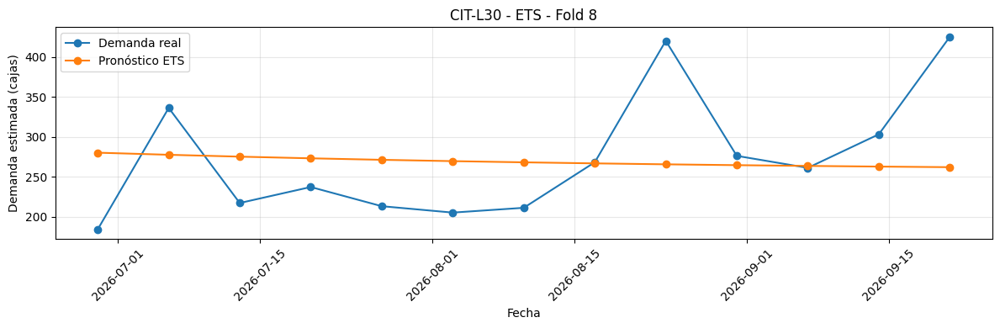

In [110]:
# Comparar visualmente el pronóstico ETS con la demanda real
# para CIT-L30 en el fold 8

ejemplo_ets = pred_ets.loc[
    (pred_ets["sku"] == "CIT-L30") &
    (pred_ets["fold"] == 8)
].sort_values("fecha_lunes")

plt.figure(figsize=(12, 4))

plt.plot(
    ejemplo_ets["fecha_lunes"],
    ejemplo_ets["y_real"],
    marker="o",
    label="Demanda real"
)

plt.plot(
    ejemplo_ets["fecha_lunes"],
    ejemplo_ets["ETS"],
    marker="o",
    label="Pronóstico ETS"
)

plt.title("CIT-L30 - ETS - Fold 8")
plt.xlabel("Fecha")
plt.ylabel("Demanda estimada (cajas)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [111]:
# Comparar la sensibilidad de ETS al tratamiento del outlier de CIT-L05

# Escenario original
pred_ets_original = generar_ets(
    corregir_outlier_extremo=False
)

# Escenario robusto
pred_ets_robusto = generar_ets(
    corregir_outlier_extremo=True
)

# Seleccionar únicamente CIT-L05
cit_ets_original = pred_ets_original[
    pred_ets_original["sku"] == "CIT-L05"
]

cit_ets_robusto = pred_ets_robusto[
    pred_ets_robusto["sku"] == "CIT-L05"
]

# Calcular WAPE en ambos escenarios
wape_cit_ets_original = calcular_wape(
    cit_ets_original["y_real"],
    cit_ets_original["ETS"]
)

wape_cit_ets_robusto = calcular_wape(
    cit_ets_robusto["y_real"],
    cit_ets_robusto["ETS"]
)

# Crear tabla comparativa
comparacion_ets_outlier = pd.DataFrame({
    "escenario": ["Original", "Robusto"],
    "WAPE_ETS": [
        wape_cit_ets_original,
        wape_cit_ets_robusto
    ]
})

display(comparacion_ets_outlier.round(2))

Procesando fold 1...
Procesando fold 2...
Procesando fold 3...
Procesando fold 4...
Procesando fold 5...
Procesando fold 6...
Procesando fold 7...
Procesando fold 8...
Procesando fold 1...
Procesando fold 2...
Procesando fold 3...
Procesando fold 4...
Procesando fold 5...
Procesando fold 6...
Procesando fold 7...
Procesando fold 8...


,escenario,WAPE_ETS
0,Original,81.04
1,Robusto,28.92


#SARIMA/SARIMAX

In [112]:



# Definir el orden de diferenciación regular (d)
# y estacional (D) para cada SKU
diferenciacion_sarima = {
    "CIT-L05": {"d": 0, "D": 1},
    "CIT-L15": {"d": 0, "D": 1},
    "CIT-L30": {"d": 0, "D": 1},

    "FUN-B05": {"d": 1, "D": 0},
    "FUN-B15": {"d": 1, "D": 0},
    "FUN-B30": {"d": 0, "D": 0},

    "NEC-D05": {"d": 0, "D": 1},
    "NEC-D15": {"d": 0, "D": 0},
    "NEC-D30": {"d": 0, "D": 1}
}

In [113]:
# Obtener el primer fold para realizar el diagnóstico previo de SARIMA

train_diag, test_diag = obtener_fold(
    numero_fold=1,
    corregir_outlier_extremo=True
)

In [114]:
# Aplicar las diferencias requeridas para el diagnóstico SARIMA
def diferenciar_para_sarima(serie, d, D, m=52):

    serie_diff = serie.copy()

    # Aplicar diferencia regular si d = 1
    if d == 1:
        serie_diff = serie_diff.diff()

    # Aplicar diferencia estacional de m semanas si D = 1
    if D == 1:
        serie_diff = serie_diff.diff(m)

    # Eliminar valores faltantes generados por las diferencias
    return serie_diff.dropna()

In [115]:
# Aplicar las diferencias requeridas para el diagnóstico SARIMA
def diferenciar_para_sarima(serie, d, D, m=52):

    serie_diff = serie.copy()

    # Aplicar diferencia regular si d = 1
    if d == 1:
        serie_diff = serie_diff.diff()

    # Aplicar diferencia estacional de m semanas si D = 1
    if D == 1:
        serie_diff = serie_diff.diff(m)

    # Eliminar valores faltantes generados por las diferencias
    return serie_diff.dropna()

In [116]:


# Graficar ACF y PACF de la serie diferenciada para cada SKU
def graficar_acf_pacf_sku(sku):

    # Seleccionar y ordenar la serie del SKU
    datos = (
        train_diag[
            train_diag["sku"] == sku
        ]
        .sort_values("fecha_lunes")
    )

    serie = datos["y_modelo"]

    # Obtener los órdenes de diferenciación definidos para el SKU
    d = diferenciacion_sarima[sku]["d"]
    D = diferenciacion_sarima[sku]["D"]

    # Aplicar las diferencias correspondientes
    serie_diff = diferenciar_para_sarima(
        serie,
        d=d,
        D=D,
        m=52
    )

    print(
        f"{sku} | d={d} | D={D} | "
        f"observaciones después de diferenciar={len(serie_diff)}"
    )

    # ACF: apoyo para identificar posibles términos MA (q)
    fig, ax = plt.subplots(figsize=(12, 4))

    plot_acf(
        serie_diff,
        lags=min(26, len(serie_diff) // 2 - 1),
        ax=ax
    )

    ax.set_title(f"ACF - {sku}")
    plt.tight_layout()
    plt.show()

    # PACF: apoyo para identificar posibles términos AR (p)
    fig, ax = plt.subplots(figsize=(12, 4))

    plot_pacf(
        serie_diff,
        lags=min(20, len(serie_diff) // 2 - 1),
        ax=ax,
        method="ywm"
    )

    ax.set_title(f"PACF - {sku}")
    plt.tight_layout()
    plt.show()

CIT-L05 | d=0 | D=1 | observaciones después de diferenciar=56


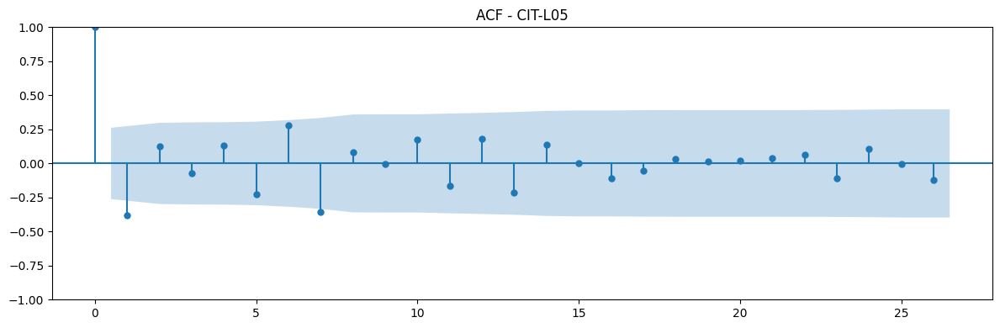

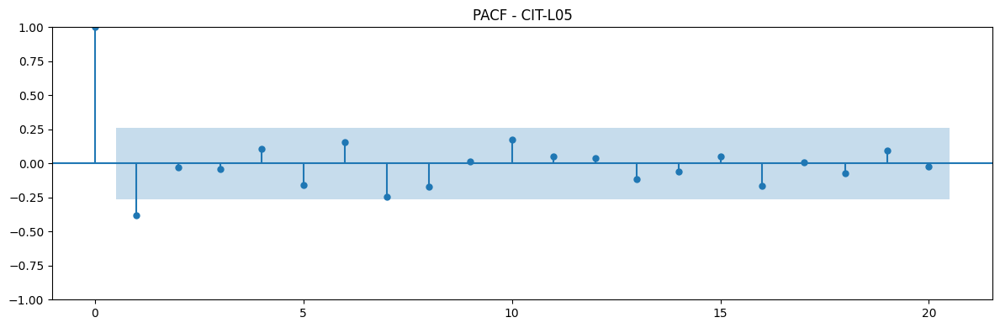

CIT-L15 | d=0 | D=1 | observaciones después de diferenciar=56


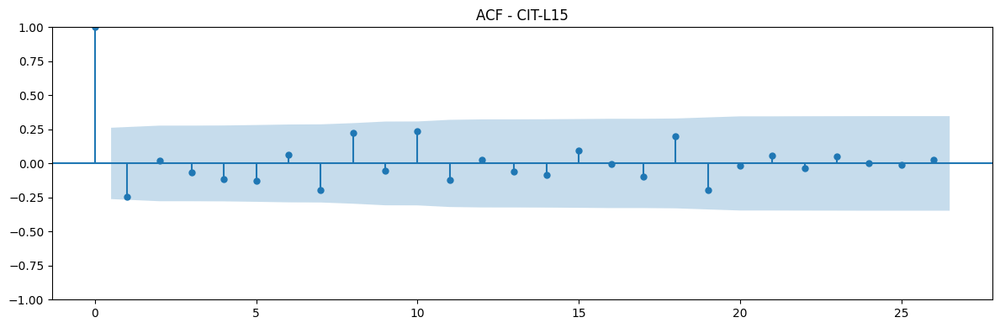

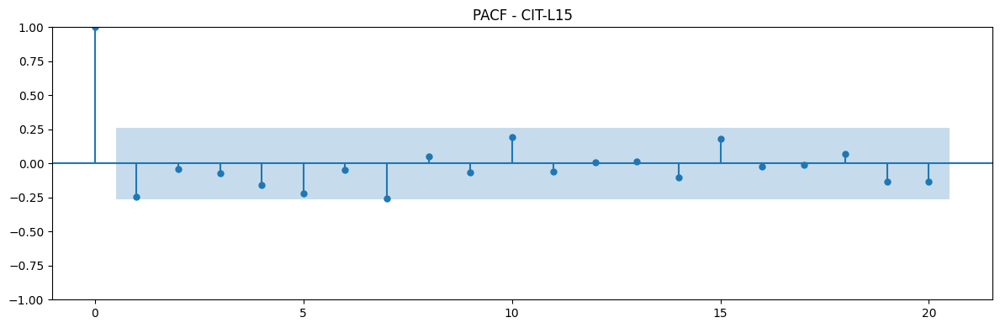

CIT-L30 | d=0 | D=1 | observaciones después de diferenciar=56


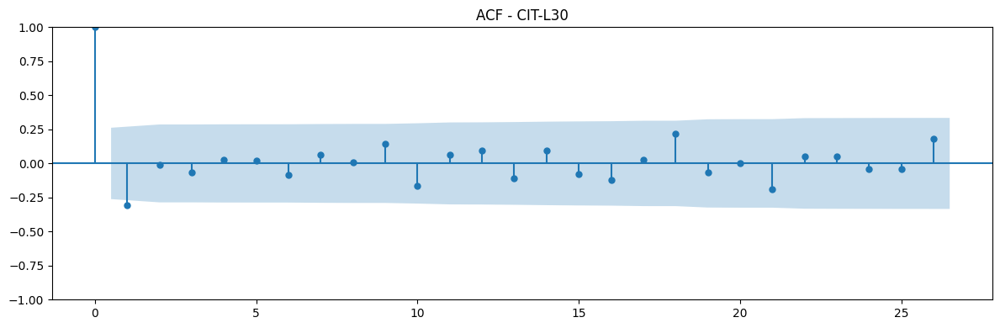

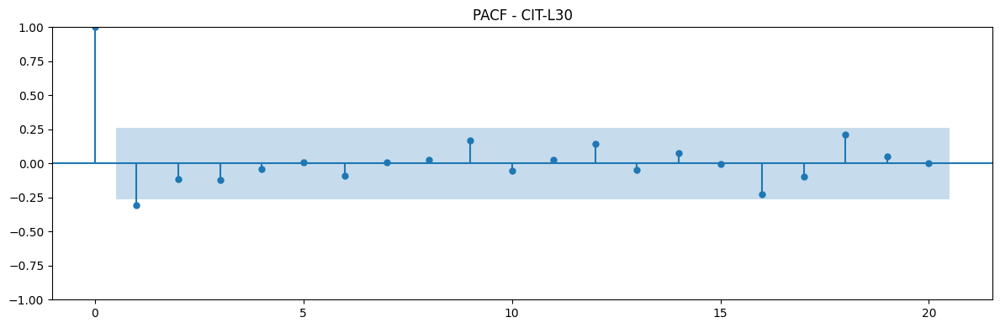

FUN-B05 | d=1 | D=0 | observaciones después de diferenciar=107


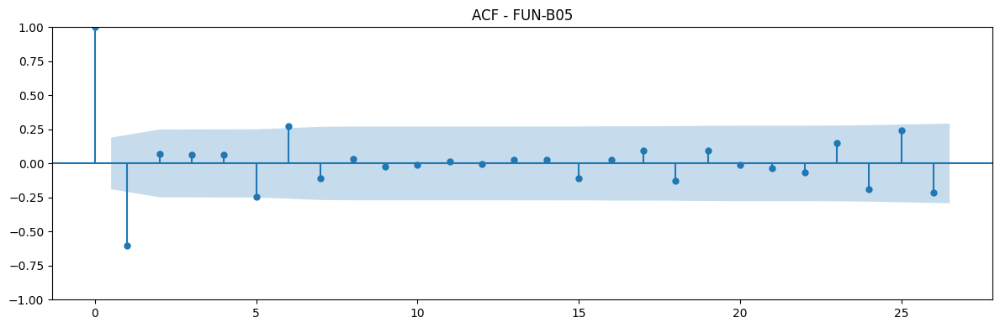

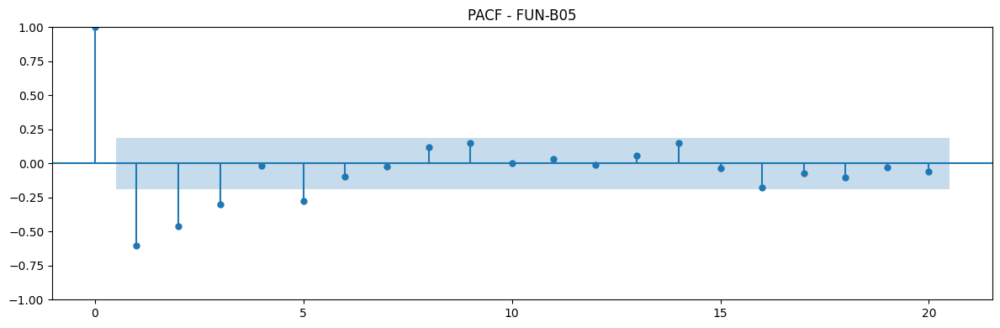

FUN-B15 | d=1 | D=0 | observaciones después de diferenciar=107


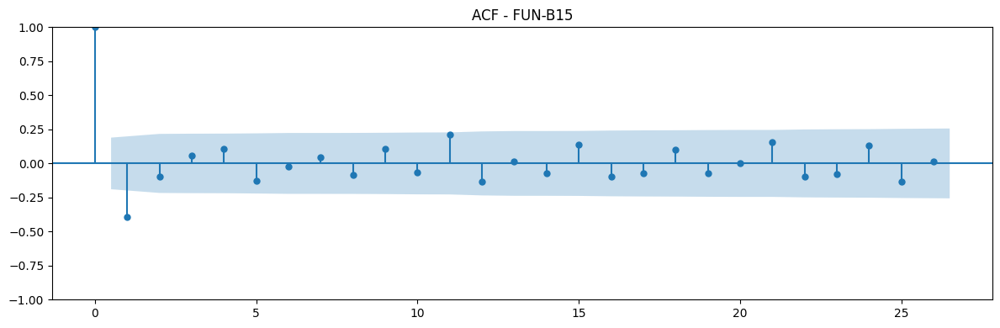

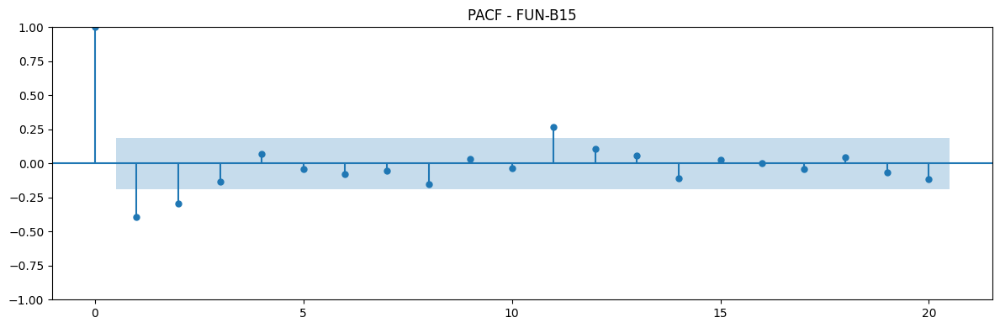

FUN-B30 | d=0 | D=0 | observaciones después de diferenciar=108


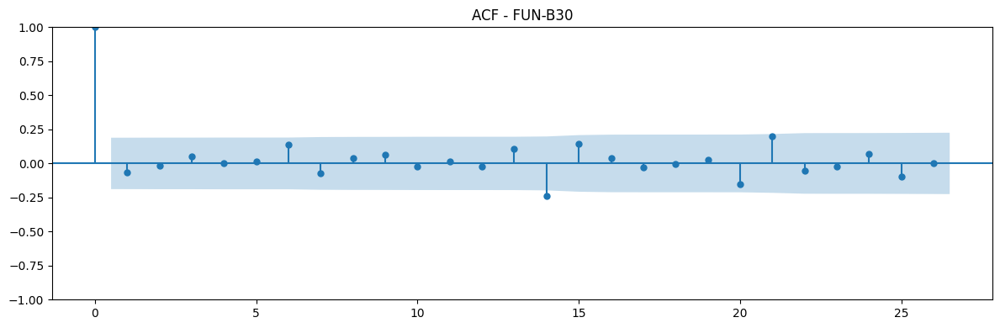

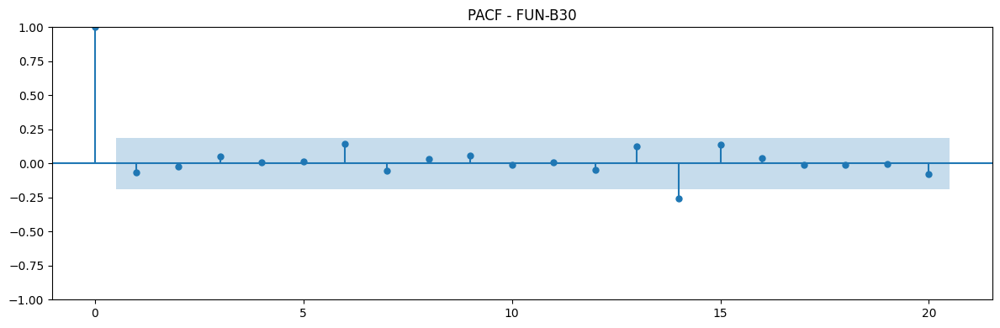

NEC-D05 | d=0 | D=1 | observaciones después de diferenciar=56


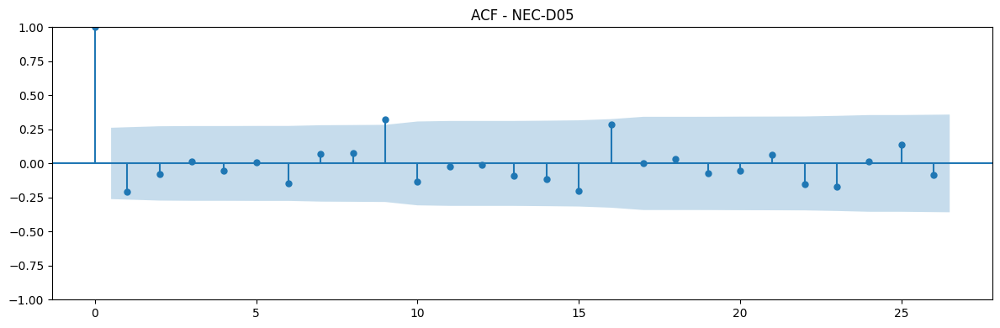

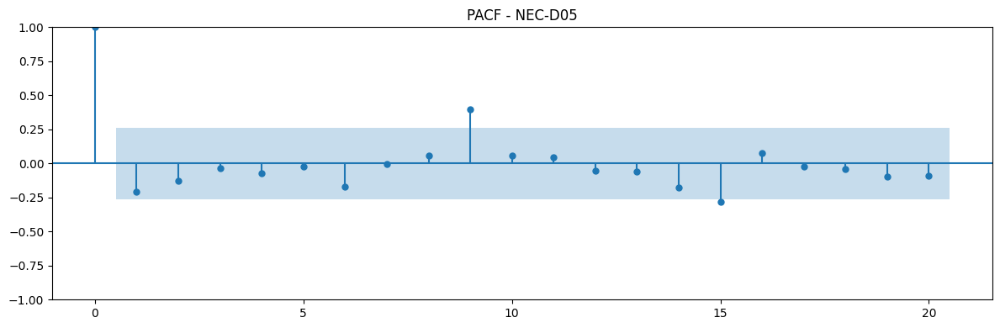

NEC-D15 | d=0 | D=0 | observaciones después de diferenciar=108


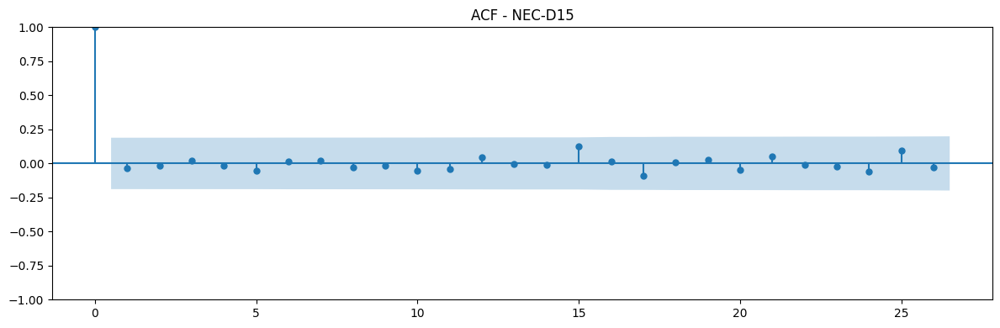

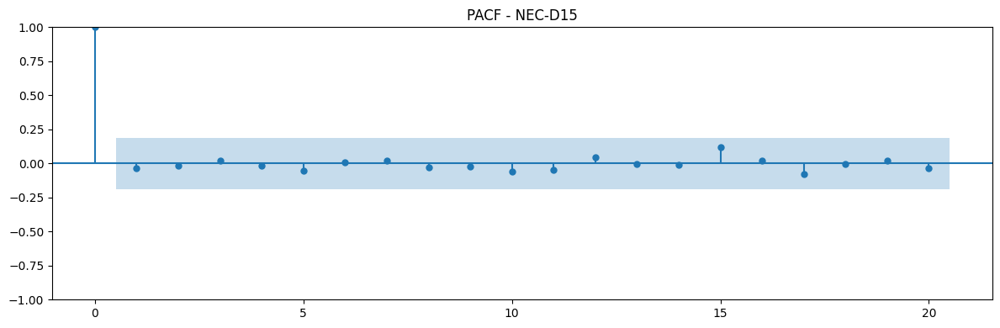

NEC-D30 | d=0 | D=1 | observaciones después de diferenciar=56


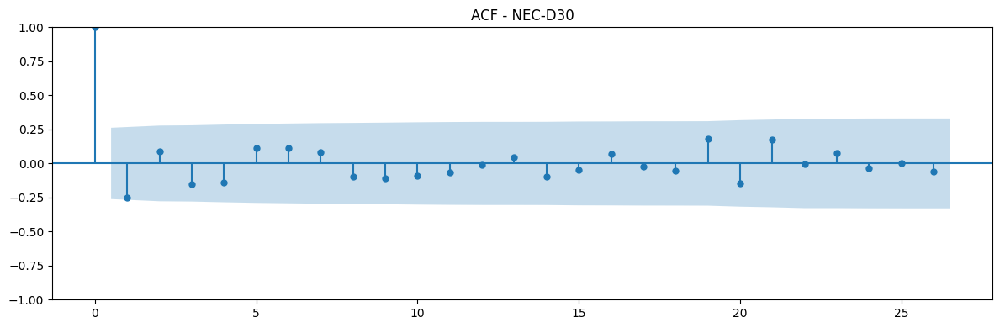

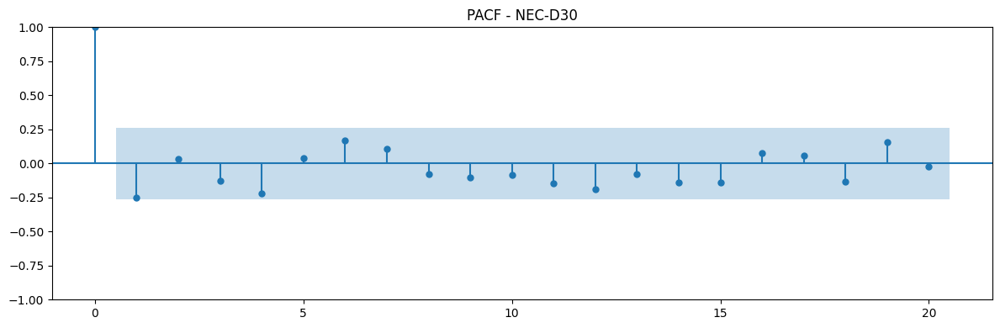

In [117]:
# Graficar ACF y PACF para todos los SKU
for sku in base_modelado["sku"].unique():

    graficar_acf_pacf_sku(sku)

In [118]:
# CANDIDATOS SARIMA DEFINIDOS MANUALMENTE

candidatos_sarima = {

    "CIT-L05": [
        {"nombre": "MA1",   "order": (0,0,1), "seasonal_order": (0,1,0,52), "trend": "n"},
        {"nombre": "AR1",   "order": (1,0,0), "seasonal_order": (0,1,0,52), "trend": "n"},
        {"nombre": "ARMA11","order": (1,0,1), "seasonal_order": (0,1,0,52), "trend": "n"}
    ],

    "CIT-L15": [
        {"nombre": "Base",  "order": (0,0,0), "seasonal_order": (0,1,0,52), "trend": "n"},
        {"nombre": "MA1",   "order": (0,0,1), "seasonal_order": (0,1,0,52), "trend": "n"},
        {"nombre": "AR1",   "order": (1,0,0), "seasonal_order": (0,1,0,52), "trend": "n"}
    ],

    "CIT-L30": [
        {"nombre": "Base",  "order": (0,0,0), "seasonal_order": (0,1,0,52), "trend": "n"},
        {"nombre": "MA1",   "order": (0,0,1), "seasonal_order": (0,1,0,52), "trend": "n"},
        {"nombre": "AR1",   "order": (1,0,0), "seasonal_order": (0,1,0,52), "trend": "n"}
    ],

    "FUN-B05": [
        {"nombre": "MA1",   "order": (0,1,1), "seasonal_order": (0,0,0,52), "trend": "c"},
        {"nombre": "AR1",   "order": (1,1,0), "seasonal_order": (0,0,0,52), "trend": "c"},
        {"nombre": "ARMA11","order": (1,1,1), "seasonal_order": (0,0,0,52), "trend": "c"}
    ],

    "FUN-B15": [
        {"nombre": "MA1",   "order": (0,1,1), "seasonal_order": (0,0,0,52), "trend": "c"},
        {"nombre": "AR1",   "order": (1,1,0), "seasonal_order": (0,0,0,52), "trend": "c"},
        {"nombre": "ARMA11","order": (1,1,1), "seasonal_order": (0,0,0,52), "trend": "c"}
    ],

    "FUN-B30": [
        {"nombre": "Media", "order": (0,0,0), "seasonal_order": (0,0,0,52), "trend": "c"},
        {"nombre": "MA1",   "order": (0,0,1), "seasonal_order": (0,0,0,52), "trend": "c"},
        {"nombre": "AR1",   "order": (1,0,0), "seasonal_order": (0,0,0,52), "trend": "c"}
    ],

    "NEC-D05": [
        {"nombre": "Base",  "order": (0,0,0), "seasonal_order": (0,1,0,52), "trend": "n"},
        {"nombre": "MA1",   "order": (0,0,1), "seasonal_order": (0,1,0,52), "trend": "n"},
        {"nombre": "AR1",   "order": (1,0,0), "seasonal_order": (0,1,0,52), "trend": "n"}
    ],

    "NEC-D15": [
        {"nombre": "Media", "order": (0,0,0), "seasonal_order": (0,0,0,52), "trend": "c"},
        {"nombre": "MA1",   "order": (0,0,1), "seasonal_order": (0,0,0,52), "trend": "c"},
        {"nombre": "AR1",   "order": (1,0,0), "seasonal_order": (0,0,0,52), "trend": "c"}
    ],

    "NEC-D30": [
        {"nombre": "Base",  "order": (0,0,0), "seasonal_order": (0,1,0,52), "trend": "n"},
        {"nombre": "MA1",   "order": (0,0,1), "seasonal_order": (0,1,0,52), "trend": "n"},
        {"nombre": "AR1",   "order": (1,0,0), "seasonal_order": (0,1,0,52), "trend": "n"}
    ]
}

In [119]:


# Comparar candidatos SARIMA mediante AIC, BIC y diagnóstico de residuos

resultados_candidatos = []

for sku, candidatos in candidatos_sarima.items():

    print(f"Procesando {sku}...")

    # Obtener la serie del SKU utilizada para el diagnóstico
    datos_sku = (
        train_diag[
            train_diag["sku"] == sku
        ]
        .sort_values("fecha_lunes")
        .copy()
    )

    # Crear una serie temporal semanal con la fecha como índice
    y = (
        datos_sku
        .set_index("fecha_lunes")["y_modelo"]
        .astype(float)
        .asfreq("W-MON")
    )

    # Evaluar cada candidato definido para el SKU
    for candidato in candidatos:

        try:

            # Crear modelo SARIMA
            modelo = SARIMAX(
                y,
                order=candidato["order"],
                seasonal_order=candidato["seasonal_order"],
                trend=candidato["trend"],
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            # Ajustar el modelo
            ajuste = modelo.fit(
                disp=False,
                maxiter=200
            )

            # Eliminar los residuos iniciales asociados al período de burn-in
            burn = ajuste.loglikelihood_burn

            residuos = (
                pd.Series(ajuste.resid)
                .iloc[burn:]
                .dropna()
            )

            # Obtener los órdenes AR y MA del modelo
            p, d, q = candidato["order"]
            P, D, Q, m = candidato["seasonal_order"]

            # Grados de libertad consumidos por términos AR y MA
            grados_modelo = p + q + P + Q

            # Prueba de Ljung-Box en lag 10
            lb = acorr_ljungbox(
                residuos,
                lags=[10],
                model_df=grados_modelo,
                return_df=True
            )

            p_ljungbox = lb["lb_pvalue"].iloc[0]

            # Verificar convergencia del ajuste
            convergio = ajuste.mle_retvals.get(
                "converged",
                True
            )

            # Guardar resultados
            resultados_candidatos.append({
                "sku": sku,
                "modelo": candidato["nombre"],
                "order": str(candidato["order"]),
                "seasonal_order": str(candidato["seasonal_order"]),
                "AIC": ajuste.aic,
                "BIC": ajuste.bic,
                "burn_in": burn,
                "n_residuos_validos": len(residuos),
                "LjungBox_p10": p_ljungbox,
                "convergio": convergio
            })

        except Exception as e:

            print(
                f"Error en {sku} - "
                f"{candidato['nombre']}: {e}"
            )

            resultados_candidatos.append({
                "sku": sku,
                "modelo": candidato["nombre"],
                "order": str(candidato["order"]),
                "seasonal_order": str(candidato["seasonal_order"]),
                "AIC": np.nan,
                "BIC": np.nan,
                "burn_in": np.nan,
                "n_residuos_validos": np.nan,
                "LjungBox_p10": np.nan,
                "convergio": False
            })

# Convertir los resultados en una tabla
tabla_candidatos_sarima = pd.DataFrame(
    resultados_candidatos
)

# Mostrar los candidatos ordenados por SKU y AIC
display(
    tabla_candidatos_sarima
    .sort_values(["sku", "AIC"])
)

Procesando CIT-L05...
Procesando CIT-L15...
Procesando CIT-L30...
Procesando FUN-B05...
Procesando FUN-B15...
Procesando FUN-B30...
Procesando NEC-D05...
Procesando NEC-D15...
Procesando NEC-D30...


,sku,modelo,order,seasonal_order,AIC,BIC,burn_in,n_residuos_validos,LjungBox_p10,convergio
0,CIT-L05,MA1,"(0, 0, 1)","(0, 1, 0, 52)",876.050802,880.028770,54,54,0.193968,True
2,CIT-L05,ARMA11,"(1, 0, 1)","(0, 1, 0, 52)",877.227605,883.194558,54,54,0.206196,True
1,CIT-L05,AR1,"(1, 0, 0)","(0, 1, 0, 52)",890.403941,894.418607,53,55,0.261784,True
4,CIT-L15,MA1,"(0, 0, 1)","(0, 1, 0, 52)",877.433426,881.411394,54,54,0.219465,True
5,CIT-L15,AR1,"(1, 0, 0)","(0, 1, 0, 52)",892.875813,896.890479,53,55,0.289461,True
3,CIT-L15,Base,"(0, 0, 0)","(0, 1, 0, 52)",894.406480,896.413814,53,55,0.125535,True
7,CIT-L30,MA1,"(0, 0, 1)","(0, 1, 0, 52)",668.944621,672.922590,54,54,0.929424,True
8,CIT-L30,AR1,"(1, 0, 0)","(0, 1, 0, 52)",680.897111,684.911777,53,55,0.844897,True
6,CIT-L30,Base,"(0, 0, 0)","(0, 1, 0, 52)",683.648029,685.655362,53,55,0.450028,True
11,FUN-B05,ARMA11,"(1, 1, 1)","(0, 0, 0, 52)",1581.942017,1592.557859,3,105,0.107021,True


In [120]:
# Comprobar el tipo de índice y su frecuencia semanal
print(type(y.index))
print(y.index.freq)

<class 'pandas.core.indexes.datetimes.DatetimeIndex'>
<Week: weekday=0>


In [121]:
tabla_candidatos_sarima = pd.DataFrame(
    resultados_candidatos
)

display(
    tabla_candidatos_sarima
    .sort_values(["sku", "AIC"])
)

,sku,modelo,order,seasonal_order,AIC,BIC,burn_in,n_residuos_validos,LjungBox_p10,convergio
0,CIT-L05,MA1,"(0, 0, 1)","(0, 1, 0, 52)",876.050802,880.028770,54,54,0.193968,True
2,CIT-L05,ARMA11,"(1, 0, 1)","(0, 1, 0, 52)",877.227605,883.194558,54,54,0.206196,True
1,CIT-L05,AR1,"(1, 0, 0)","(0, 1, 0, 52)",890.403941,894.418607,53,55,0.261784,True
4,CIT-L15,MA1,"(0, 0, 1)","(0, 1, 0, 52)",877.433426,881.411394,54,54,0.219465,True
5,CIT-L15,AR1,"(1, 0, 0)","(0, 1, 0, 52)",892.875813,896.890479,53,55,0.289461,True
3,CIT-L15,Base,"(0, 0, 0)","(0, 1, 0, 52)",894.406480,896.413814,53,55,0.125535,True
7,CIT-L30,MA1,"(0, 0, 1)","(0, 1, 0, 52)",668.944621,672.922590,54,54,0.929424,True
8,CIT-L30,AR1,"(1, 0, 0)","(0, 1, 0, 52)",680.897111,684.911777,53,55,0.844897,True
6,CIT-L30,Base,"(0, 0, 0)","(0, 1, 0, 52)",683.648029,685.655362,53,55,0.450028,True
11,FUN-B05,ARMA11,"(1, 1, 1)","(0, 0, 0, 52)",1581.942017,1592.557859,3,105,0.107021,True


In [122]:
# MODELOS SARIMA DEFINITIVOS

modelos_sarima_finales = {

    "CIT-L05": {
        "order": (0, 0, 1),
        "seasonal_order": (0, 1, 0, 52),
        "trend": "n"
    },

    "CIT-L15": {
        "order": (0, 0, 1),
        "seasonal_order": (0, 1, 0, 52),
        "trend": "n"
    },

    "CIT-L30": {
        "order": (0, 0, 1),
        "seasonal_order": (0, 1, 0, 52),
        "trend": "n"
    },

    "FUN-B05": {
        "order": (1, 1, 1),
        "seasonal_order": (0, 0, 0, 52),
        "trend": "c"
    },

    "FUN-B15": {
        "order": (0, 1, 1),
        "seasonal_order": (0, 0, 0, 52),
        "trend": "c"
    },

    "FUN-B30": {
        "order": (0, 0, 1),
        "seasonal_order": (0, 0, 0, 52),
        "trend": "c"
    },

    "NEC-D05": {
        "order": (0, 0, 1),
        "seasonal_order": (0, 1, 0, 52),
        "trend": "n"
    },

    "NEC-D15": {
        "order": (0, 0, 1),
        "seasonal_order": (0, 0, 0, 52),
        "trend": "c"
    },

    "NEC-D30": {
        "order": (0, 0, 1),
        "seasonal_order": (0, 1, 0, 52),
        "trend": "n"
    }
}

In [123]:
# Rolling-origin con los modelos SARIMA seleccionados

def generar_sarima_manual():

    resultados = []

    # Recorrer las 8 ventanas de validación
    for fold in range(1, n_ventanas + 1):

        print(f"Procesando fold {fold}...")

        # Obtener train preparado y test sin modificar
        train_fold, test_fold = obtener_fold(
            numero_fold=fold,
            corregir_outlier_extremo=True
        )

        # Ajustar el modelo correspondiente a cada SKU
        for sku in modelos_sarima_finales.keys():

            # ---------------------------
            # TRAIN DEL SKU
            # ---------------------------

            train_sku = (
                train_fold[
                    train_fold["sku"] == sku
                ]
                .sort_values("fecha_lunes")
                .copy()
            )

            # Crear la serie temporal semanal
            y_train = (
                train_sku
                .set_index("fecha_lunes")["y_modelo"]
                .astype(float)
                .asfreq("W-MON")
            )

            # Obtener la configuración SARIMA definida para el SKU
            config = modelos_sarima_finales[sku]

            # ---------------------------
            # AJUSTAR SARIMA
            # ---------------------------

            modelo = SARIMAX(
                y_train,
                order=config["order"],
                seasonal_order=config["seasonal_order"],
                trend=config["trend"],
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            ajuste = modelo.fit(
                disp=False,
                maxiter=200
            )

            # ---------------------------
            # PRONÓSTICO
            # ---------------------------

            forecast = ajuste.get_forecast(
                steps=h
            )

            predicciones = (
                forecast.predicted_mean
                .to_numpy()
            )

            # ---------------------------
            # TEST REAL
            # ---------------------------

            test_sku = (
                test_fold[
                    test_fold["sku"] == sku
                ]
                .sort_values("fecha_lunes")
                .copy()
            )

            # Guardar cada horizonte de pronóstico
            for i, (_, fila) in enumerate(
                test_sku.iterrows()
            ):

                resultados.append({
                    "fold": fold,
                    "sku": sku,
                    "fecha_lunes": fila["fecha_lunes"],
                    "horizonte": int(fila["horizonte"]),
                    "y_real": fila["demanda_estimada"],
                    "SARIMA": predicciones[i]
                })

    return pd.DataFrame(resultados)


# Generar pronósticos SARIMA para todos los folds
pred_sarima = generar_sarima_manual()

Procesando fold 1...
Procesando fold 2...
Procesando fold 3...
Procesando fold 4...
Procesando fold 5...
Procesando fold 6...
Procesando fold 7...
Procesando fold 8...


In [124]:
# Comprobar que los pronósticos SARIMA se generaron correctamente

print(
    "Cantidad de predicciones:",
    len(pred_sarima)
)

print(
    "NaN en SARIMA:",
    pred_sarima["SARIMA"].isna().sum()
)

print(
    "Pronósticos negativos:",
    (pred_sarima["SARIMA"] < 0).sum()
)

print(
    "Horizonte mínimo:",
    pred_sarima["horizonte"].min()
)

print(
    "Horizonte máximo:",
    pred_sarima["horizonte"].max()
)

Cantidad de predicciones: 936
NaN en SARIMA: 0
Pronósticos negativos: 0
Horizonte mínimo: 1
Horizonte máximo: 13


In [125]:
# Calcular el WAPE de SARIMA para cada SKU

resultados_wape_sarima = []

for sku, grupo in pred_sarima.groupby("sku"):

    wape = calcular_wape(
        grupo["y_real"],
        grupo["SARIMA"]
    )

    resultados_wape_sarima.append({
        "sku": sku,
        "WAPE_SARIMA": wape
    })

# Crear tabla con los resultados de SARIMA
wape_sarima = pd.DataFrame(
    resultados_wape_sarima
)

wape_sarima["WAPE_SARIMA"] = (
    wape_sarima["WAPE_SARIMA"].round(2)
)

display(wape_sarima)

,sku,WAPE_SARIMA
0,CIT-L05,16.44
1,CIT-L15,22.62
2,CIT-L30,17.68
3,FUN-B05,19.66
4,FUN-B15,25.11
5,FUN-B30,93.40
6,NEC-D05,22.57
7,NEC-D15,23.35
8,NEC-D30,20.26


In [126]:
# Comparar el mejor benchmark vs ETS vs SARIMA para cada SKU

comparacion_modelos = (
    mejor_benchmark_cv
    .rename(
        columns={
            "modelo": "benchmark",
            "WAPE": "WAPE_benchmark"
        }
    )
    .merge(
        wape_ets,
        on="sku",
        how="left"
    )
    .merge(
        wape_sarima,
        on="sku",
        how="left"
    )
)

# Identificar qué tipo de modelo obtiene el menor WAPE
comparacion_modelos["mejor_modelo"] = (
    comparacion_modelos[
        [
            "WAPE_benchmark",
            "WAPE_ETS",
            "WAPE_SARIMA"
        ]
    ]
    .idxmin(axis=1)
    .replace({
        "WAPE_benchmark": "Benchmark",
        "WAPE_ETS": "ETS",
        "WAPE_SARIMA": "SARIMA"
    })
)

# Mostrar el nombre específico del modelo ganador
comparacion_modelos["modelo_ganador"] = np.where(
    comparacion_modelos["mejor_modelo"] == "Benchmark",
    comparacion_modelos["benchmark"],
    comparacion_modelos["mejor_modelo"]
)

display(
    comparacion_modelos.round(2)
)

,sku,benchmark,WAPE_benchmark,WAPE_ETS,WAPE_SARIMA,mejor_modelo,modelo_ganador
0,CIT-L05,SeasonalNaive,16.24,28.92,16.44,Benchmark,SeasonalNaive
1,CIT-L15,SeasonalNaive,22.72,24.52,22.62,SARIMA,SARIMA
2,CIT-L30,SeasonalNaive,17.95,32.25,17.68,SARIMA,SARIMA
3,FUN-B05,Naive,21.59,18.48,19.66,ETS,ETS
4,FUN-B15,Naive,29.15,23.60,25.11,ETS,ETS
5,FUN-B30,SeasonalNaive,98.82,93.24,93.40,ETS,ETS
6,NEC-D05,SeasonalNaive,22.50,19.73,22.57,ETS,ETS
7,NEC-D15,Naive,26.45,39.64,23.35,SARIMA,SARIMA
8,NEC-D30,Naive,19.20,19.27,20.26,Benchmark,Naive


#WAPE, MASE y Bias por horizonte h=13

In [127]:
#19.1 FIJAR EL BENCHMARK OFICIAL
benchmark_oficial = {
    "CIT-L05": "SeasonalNaive",
    "CIT-L15": "SeasonalNaive",
    "CIT-L30": "SeasonalNaive",

    "FUN-B05": "Naive",
    "FUN-B15": "Naive",
    "FUN-B30": "SeasonalNaive",

    "NEC-D05": "SeasonalNaive",
    "NEC-D15": "Naive",
    "NEC-D30": "Naive"
}

In [128]:
# Generar los pronósticos del benchmark oficial para cada SKU

pred_benchmarks = generar_benchmarks(
    corregir_outlier_extremo=True
)

pred_benchmark_oficial = pred_benchmarks.copy()

# Seleccionar para cada SKU el benchmark que obtuvo mejor WAPE
pred_benchmark_oficial["Benchmark"] = (
    pred_benchmark_oficial.apply(
        lambda fila:
            fila[
                benchmark_oficial[
                    fila["sku"]
                ]
            ],
        axis=1
    )
)

In [129]:
pred_evaluacion = (
    pred_benchmark_oficial[
        [
            "fold",
            "sku",
            "fecha_lunes",
            "horizonte",
            "y_real",
            "Benchmark"
        ]
    ]
    .merge(
        pred_ets[
            [
                "fold",
                "sku",
                "fecha_lunes",
                "horizonte",
                "ETS"
            ]
        ],
        on=[
            "fold",
            "sku",
            "fecha_lunes",
            "horizonte"
        ],
        how="left"
    )
    .merge(
        pred_sarima[
            [
                "fold",
                "sku",
                "fecha_lunes",
                "horizonte",
                "SARIMA"
            ]
        ],
        on=[
            "fold",
            "sku",
            "fecha_lunes",
            "horizonte"
        ],
        how="left"
    )
)


# CALCULAR ESCALA MASE PARA CADA FOLD Y SKU

escalas_mase = []

for fold in range(1, n_ventanas + 1):

    train_fold, _ = obtener_fold(
        numero_fold=fold,
        corregir_outlier_extremo=True
    )

    for sku, grupo in train_fold.groupby("sku"):

        y_train = (
            grupo
            .sort_values("fecha_lunes")["y_modelo"]
            .astype(float)
        )

        escala = (
            y_train
            .diff()
            .abs()
            .dropna()
            .mean()
        )

        escalas_mase.append({
            "fold": fold,
            "sku": sku,
            "escala_MASE": escala
        })


escalas_mase = pd.DataFrame(
    escalas_mase
)


# AGREGAR ESCALA MASE A LAS PREDICCIONES

pred_evaluacion = pred_evaluacion.merge(
    escalas_mase,
    on=["fold", "sku"],
    how="left"
)

# PASAR LOS MODELOS A FORMATO LARGO

pred_long = pred_evaluacion.melt(

    id_vars=[
        "fold",
        "sku",
        "fecha_lunes",
        "horizonte",
        "y_real",
        "escala_MASE"
    ],

    value_vars=[
        "Benchmark",
        "ETS",
        "SARIMA"
    ],

    var_name="modelo",
    value_name="y_pred"
)

# CALCULAR ERRORES

# Convención:
# error > 0  -> sobreestimación
# error < 0  -> subestimación

pred_long["error"] = (
    pred_long["y_pred"]
    - pred_long["y_real"]
)

pred_long["error_abs"] = (
    pred_long["error"].abs()
)

pred_long["real_abs"] = (
    pred_long["y_real"].abs()
)

pred_long["error_escalado"] = (
    pred_long["error_abs"]
    / pred_long["escala_MASE"]
)

# CALCULAR MÉTRICAS POR HORIZONTE

metricas_horizonte = (
    pred_long
    .groupby(
        [
            "sku",
            "modelo",
            "horizonte"
        ],
        as_index=False
    )
    .agg(

        suma_error_abs=(
            "error_abs",
            "sum"
        ),

        suma_real_abs=(
            "real_abs",
            "sum"
        ),

        MASE=(
            "error_escalado",
            "mean"
        ),

        Bias=(
            "error",
            "mean"
        ),

        n=(
            "error",
            "size"
        )
    )
)

# CALCULAR WAPE

metricas_horizonte["WAPE"] = (
    100
    * metricas_horizonte["suma_error_abs"]
    / metricas_horizonte["suma_real_abs"]
)

# ORDENAR TABLA FINAL

metricas_horizonte = (
    metricas_horizonte[
        [
            "sku",
            "modelo",
            "horizonte",
            "WAPE",
            "MASE",
            "Bias",
            "n"
        ]
    ]
    .sort_values(
        [
            "sku",
            "modelo",
            "horizonte"
        ]
    )
)

# COMPROBACIONES

print(
    "pred_evaluacion existe:",
    "pred_evaluacion" in globals()
)

print(
    "pred_long existe:",
    "pred_long" in globals()
)

print(
    "metricas_horizonte existe:",
    "metricas_horizonte" in globals()
)

print(
    "\nCantidad de filas de pred_long:",
    len(pred_long)
)

display(
    metricas_horizonte.head(20).round(3)
)

pred_evaluacion existe: True
pred_long existe: True
metricas_horizonte existe: True

Cantidad de filas de pred_long: 2808


,sku,modelo,horizonte,WAPE,MASE,Bias,n
0,CIT-L05,Benchmark,1,21.297,0.823,320.500,8
1,CIT-L05,Benchmark,2,15.898,0.583,19.375,8
2,CIT-L05,Benchmark,3,9.647,0.359,-140.000,8
3,CIT-L05,Benchmark,4,17.920,0.765,57.000,8
4,CIT-L05,Benchmark,5,15.268,0.591,-188.000,8
5,CIT-L05,Benchmark,6,23.305,0.854,297.500,8
6,CIT-L05,Benchmark,7,13.858,0.479,-36.125,8
7,CIT-L05,Benchmark,8,10.234,0.360,-133.250,8
8,CIT-L05,Benchmark,9,18.744,0.714,82.750,8
9,CIT-L05,Benchmark,10,15.577,0.576,-282.125,8


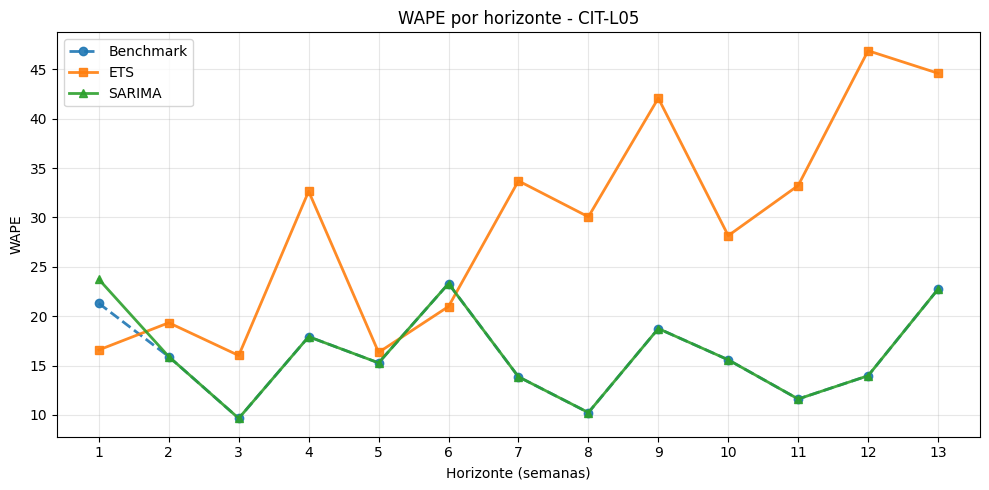

In [130]:
# Función para graficar WAPE, MASE o Bias por horizonte

def graficar_metrica_horizonte(sku, metrica):

    datos = metricas_horizonte[
        metricas_horizonte["sku"] == sku
    ]

    plt.figure(figsize=(10, 5))

    estilos = {
        "Benchmark": {
            "linestyle": "--",
            "marker": "o",
            "linewidth": 2,
            "alpha": 0.9
        },
        "ETS": {
            "linestyle": "-",
            "marker": "s",
            "linewidth": 2,
            "alpha": 0.9
        },
        "SARIMA": {
            "linestyle": "-",
            "marker": "^",
            "linewidth": 2,
            "alpha": 0.9
        }
    }

    # Graficar cada modelo
    for modelo in ["Benchmark", "ETS", "SARIMA"]:

        g = datos[
            datos["modelo"] == modelo
        ]

        plt.plot(
            g["horizonte"],
            g[metrica],
            label=modelo,
            linestyle=estilos[modelo]["linestyle"],
            marker=estilos[modelo]["marker"],
            linewidth=estilos[modelo]["linewidth"],
            alpha=estilos[modelo]["alpha"]
        )

    plt.xlabel("Horizonte (semanas)")
    plt.ylabel(metrica)
    plt.title(f"{metrica} por horizonte - {sku}")

    # Mostrar todos los horizontes evaluados
    plt.xticks(range(1, h + 1))

    # Línea de referencia para Bias
    if metrica == "Bias":
        plt.axhline(y=0, linestyle="--")

    # Línea de referencia para MASE
    if metrica == "MASE":
        plt.axhline(y=1, linestyle="--")

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


# Ejemplo: WAPE por horizonte para CIT-L05
graficar_metrica_horizonte(
    "CIT-L05",
    "WAPE"
)

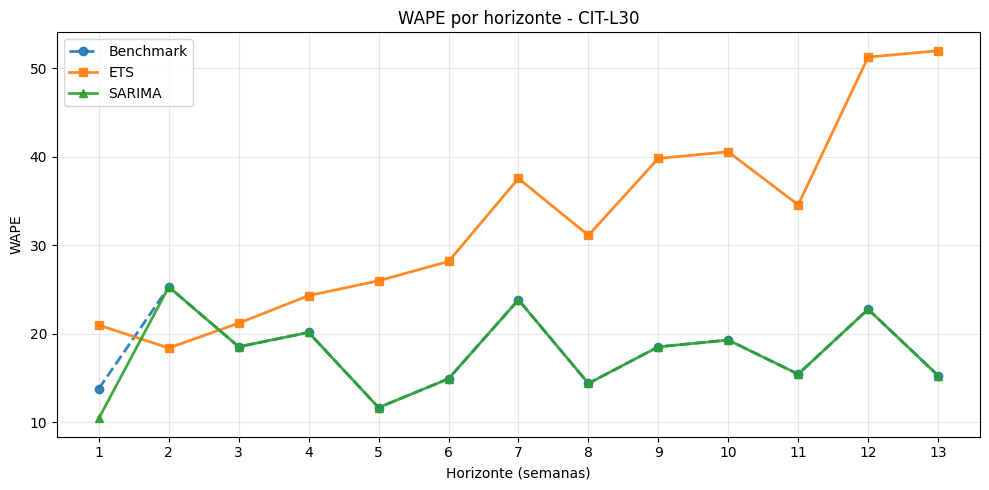

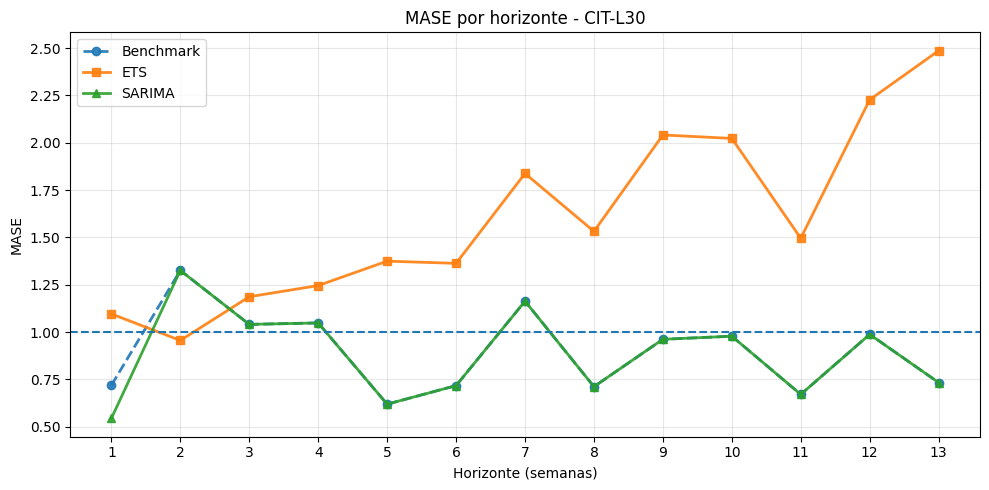

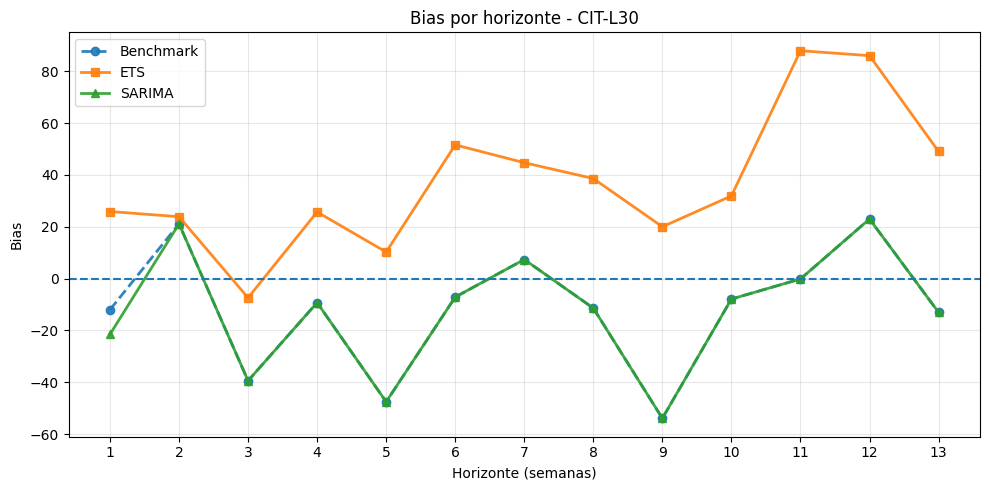

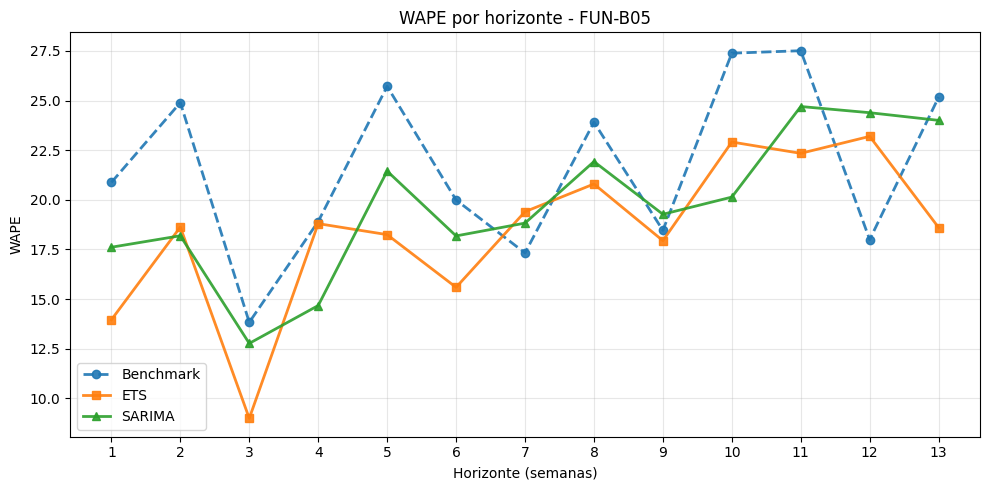

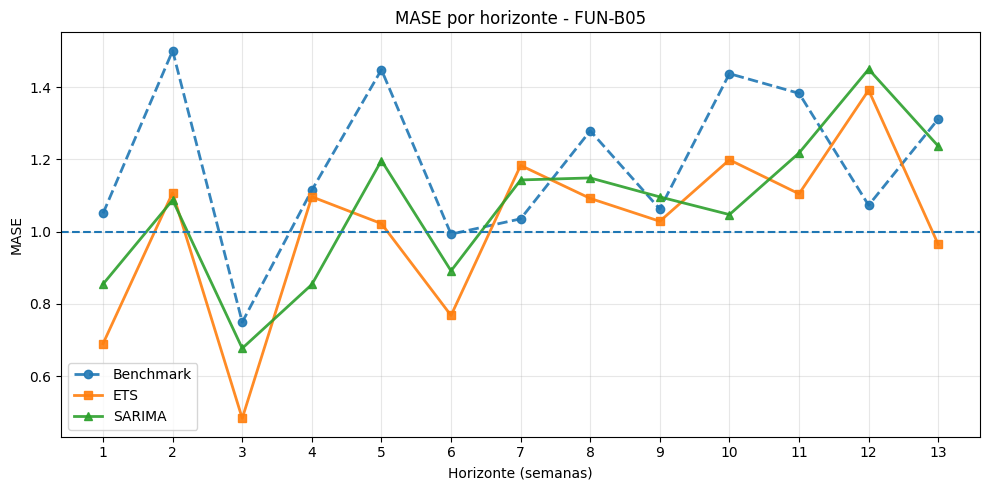

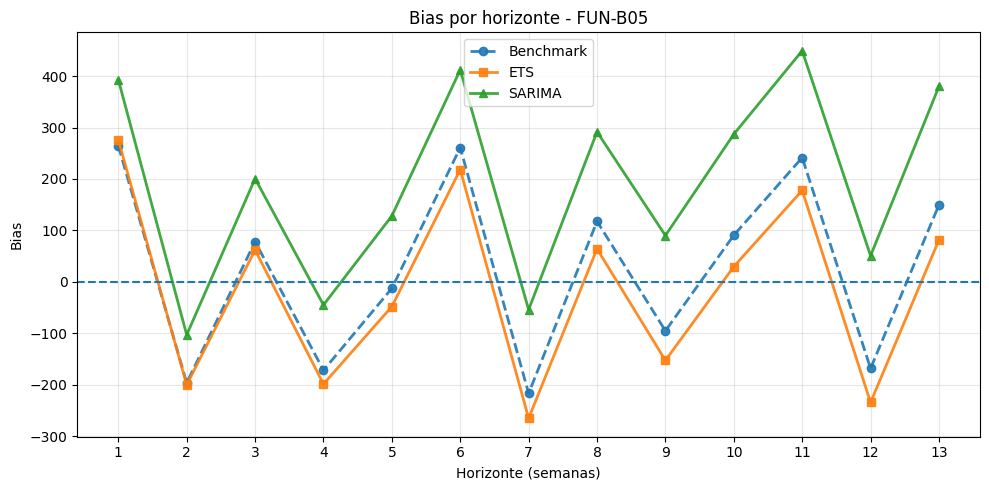

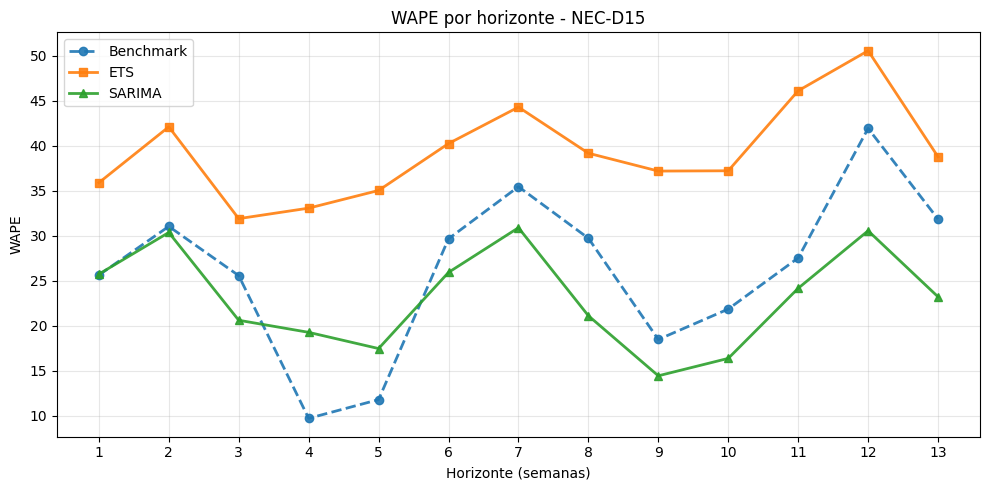

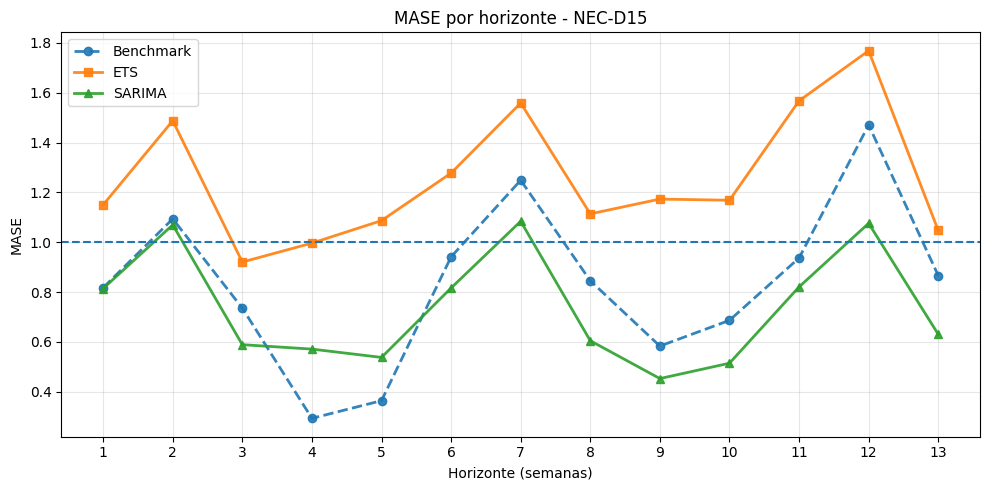

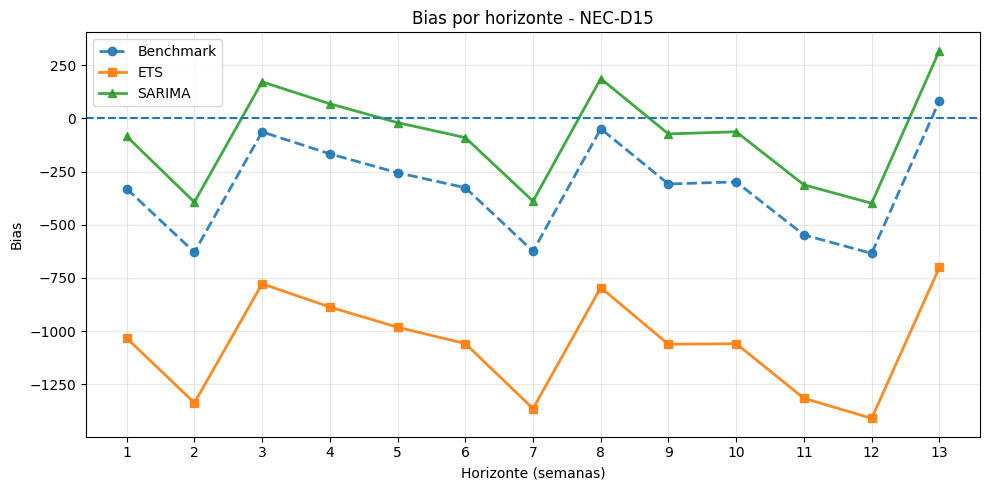

In [131]:
# Revisar WAPE, MASE y Bias por horizonte para SKU seleccionados

# CIT-L30
graficar_metrica_horizonte("CIT-L30", "WAPE")
graficar_metrica_horizonte("CIT-L30", "MASE")
graficar_metrica_horizonte("CIT-L30", "Bias")

# FUN-B05
graficar_metrica_horizonte("FUN-B05", "WAPE")
graficar_metrica_horizonte("FUN-B05", "MASE")
graficar_metrica_horizonte("FUN-B05", "Bias")

# NEC-D15
graficar_metrica_horizonte("NEC-D15", "WAPE")
graficar_metrica_horizonte("NEC-D15", "MASE")
graficar_metrica_horizonte("NEC-D15", "Bias")

In [132]:
# Calcular métricas globales por SKU y modelo

metricas_globales = (
    pred_long
    .groupby(
        ["sku", "modelo"],
        as_index=False
    )
    .agg(
        # Suma de errores absolutos para calcular WAPE
        suma_error_abs=("error_abs", "sum"),

        # Suma de demanda real absoluta para calcular WAPE
        suma_real_abs=("real_abs", "sum"),

        # Promedio del error absoluto escalado
        MASE=("error_escalado", "mean"),

        # Promedio del error con signo
        Bias=("error", "mean")
    )
)

# Calcular WAPE global
metricas_globales["WAPE"] = (
    100
    * metricas_globales["suma_error_abs"]
    / metricas_globales["suma_real_abs"]
)

# Seleccionar únicamente las métricas finales
metricas_globales = metricas_globales[
    [
        "sku",
        "modelo",
        "WAPE",
        "MASE",
        "Bias"
    ]
]

display(
    metricas_globales.round(3)
)

,sku,modelo,WAPE,MASE,Bias
0,CIT-L05,Benchmark,16.240,0.595,8.125
1,CIT-L05,ETS,28.919,1.062,229.135
2,CIT-L05,SARIMA,16.440,0.602,8.237
3,CIT-L15,Benchmark,22.718,0.862,60.913
4,CIT-L15,ETS,24.516,0.932,157.717
5,CIT-L15,SARIMA,22.619,0.858,64.952
6,CIT-L30,Benchmark,17.953,0.898,-11.538
7,CIT-L30,ETS,32.253,1.605,37.539
8,CIT-L30,SARIMA,17.682,0.885,-12.269
9,FUN-B05,Benchmark,21.594,1.188,26.269


In [133]:
# CREAR TABLA DE WAPE POR HORIZONTE

tabla_wape_h = (
    metricas_horizonte
    .pivot(
        index=[
            "sku",
            "horizonte"
        ],
        columns="modelo",
        values="WAPE"
    )
    .reset_index()
)

# Eliminar el nombre asociado al índice de columnas creado por pivot
tabla_wape_h.columns.name = None

display(
    tabla_wape_h.round(2)
)


# IDENTIFICAR EL MODELO CON MENOR WAPE EN CADA HORIZONTE

ganador_horizonte = tabla_wape_h.copy()

ganador_horizonte["ganador"] = (
    ganador_horizonte[
        ["Benchmark", "ETS", "SARIMA"]
    ]
    .idxmin(axis=1)
)

display(
    ganador_horizonte.round(2)
)


# RESUMIR CUÁNTOS HORIZONTES GANA CADA MODELO

resumen_ganadores = (
    ganador_horizonte
    .groupby(
        ["sku", "ganador"]
    )
    .size()
    .reset_index(
        name="horizontes_ganados"
    )
)

display(
    resumen_ganadores
)

,sku,horizonte,Benchmark,ETS,SARIMA
0,CIT-L05,1,21.30,16.58,23.73
1,CIT-L05,2,15.90,19.33,15.90
2,CIT-L05,3,9.65,16.01,9.65
3,CIT-L05,4,17.92,32.65,17.92
4,CIT-L05,5,15.27,16.33,15.27
...,...,...,...,...,...
112,NEC-D30,9,16.52,18.63,14.68
113,NEC-D30,10,18.14,22.87,25.48
114,NEC-D30,11,15.96,17.34,21.39
115,NEC-D30,12,30.88,29.62,24.89


,sku,horizonte,Benchmark,ETS,SARIMA,ganador
0,CIT-L05,1,21.30,16.58,23.73,ETS
1,CIT-L05,2,15.90,19.33,15.90,SARIMA
2,CIT-L05,3,9.65,16.01,9.65,Benchmark
3,CIT-L05,4,17.92,32.65,17.92,Benchmark
4,CIT-L05,5,15.27,16.33,15.27,Benchmark
...,...,...,...,...,...,...
112,NEC-D30,9,16.52,18.63,14.68,SARIMA
113,NEC-D30,10,18.14,22.87,25.48,Benchmark
114,NEC-D30,11,15.96,17.34,21.39,Benchmark
115,NEC-D30,12,30.88,29.62,24.89,SARIMA


,sku,ganador,horizontes_ganados
0,CIT-L05,Benchmark,7
1,CIT-L05,ETS,2
2,CIT-L05,SARIMA,4
3,CIT-L15,Benchmark,6
4,CIT-L15,ETS,6
5,CIT-L15,SARIMA,1
6,CIT-L30,Benchmark,9
7,CIT-L30,ETS,1
8,CIT-L30,SARIMA,3
9,FUN-B05,Benchmark,2


#Elegir modelo por serie/naive

In [134]:
# MODELO FINAL POR SKU

modelo_final_sku = {

    "CIT-L05": "SeasonalNaive",
    "CIT-L15": "SeasonalNaive",
    "CIT-L30": "SeasonalNaive",

    "FUN-B05": "ETS",
    "FUN-B15": "ETS",
    "FUN-B30": "ETS",

    "NEC-D05": "ETS",

    "NEC-D15": "SARIMA",

    "NEC-D30": "Naive"
}

In [135]:
# CREAR TABLA CON EL MODELO FINAL DE CADA SKU

seleccion_final = pd.DataFrame({

    "sku": list(modelo_final_sku.keys()),

    "modelo_final": list(
        modelo_final_sku.values()
    )
})

display(seleccion_final)

,sku,modelo_final
0,CIT-L05,SeasonalNaive
1,CIT-L15,SeasonalNaive
2,CIT-L30,SeasonalNaive
3,FUN-B05,ETS
4,FUN-B15,ETS
5,FUN-B30,ETS
6,NEC-D05,ETS
7,NEC-D15,SARIMA
8,NEC-D30,Naive


In [136]:
# AGREGAR MÉTRICAS DEL MODELO FINAL DE CADA SKU

# Relacionar el nombre del modelo final con el nombre utilizado
# en la tabla de métricas globales
nombre_evaluacion = {
    "SeasonalNaive": "Benchmark",
    "Naive": "Benchmark",
    "ETS": "ETS",
    "SARIMA": "SARIMA"
}

seleccion_final["modelo_evaluacion"] = (
    seleccion_final["modelo_final"]
    .map(nombre_evaluacion)
)

# Agregar WAPE, MASE y Bias correspondientes al modelo seleccionado
seleccion_final = seleccion_final.merge(
    metricas_globales,
    left_on=[
        "sku",
        "modelo_evaluacion"
    ],
    right_on=[
        "sku",
        "modelo"
    ],
    how="left"
)

# Mantener únicamente las columnas relevantes
seleccion_final = seleccion_final[
    [
        "sku",
        "modelo_final",
        "WAPE",
        "MASE",
        "Bias"
    ]
]

display(
    seleccion_final.round(3)
)

,sku,modelo_final,WAPE,MASE,Bias
0,CIT-L05,SeasonalNaive,16.240,0.595,8.125
1,CIT-L15,SeasonalNaive,22.718,0.862,60.913
2,CIT-L30,SeasonalNaive,17.953,0.898,-11.538
3,FUN-B05,ETS,18.478,1.010,-14.633
4,FUN-B15,ETS,23.596,1.574,33.657
5,FUN-B30,ETS,93.236,1.204,-93.043
6,NEC-D05,ETS,19.729,0.950,47.388
7,NEC-D15,SARIMA,23.348,0.737,-83.235
8,NEC-D30,Naive,19.205,0.899,-16.510


### Cobertura de los intervalos de predicción
Se verifica en la validación cruzada si los intervalos del modelo final de cada SKU contienen la proporción esperada de valores reales (80 % y 95 %).

In [137]:
# COBERTURA EMPÍRICA DE LOS INTERVALOS DE PREDICCIÓN EN LA VALIDACIÓN CRUZADA
# Para cada fold se construyen los intervalos del modelo final de cada SKU, con el mismo método del pronóstico final,
# y se cuenta qué proporción de los valores reales cae dentro del intervalo.
import warnings
from scipy.stats import norm

z80 = norm.ppf(0.90)
z95 = norm.ppf(0.975)

filas_cobertura = []

for fold in range(1, n_ventanas + 1):

    train_fold, test_fold = obtener_fold(numero_fold=fold, corregir_outlier_extremo=True)

    # ETS: un solo ajuste para todos los SKU que usan ETS
    skus_ets_cv = [sku for sku, modelo in modelo_final_sku.items() if modelo == 'ETS']
    df_ets_cv = (
        train_fold[train_fold['sku'].isin(skus_ets_cv)][['sku', 'fecha_lunes', 'y_modelo']]
        .rename(columns={'sku': 'unique_id', 'fecha_lunes': 'ds', 'y_modelo': 'y'})
    )
    sf_cv = StatsForecast(models=[AutoETS(season_length=52)], freq='W-MON', n_jobs=-1)
    sf_cv.fit(df_ets_cv)
    fc_ets_cv = sf_cv.predict(h=13, level=[80, 95]).rename(columns={'unique_id': 'sku', 'ds': 'fecha_lunes'})

    for sku, modelo in modelo_final_sku.items():

        train_sku = train_fold[train_fold['sku'] == sku].sort_values('fecha_lunes')
        test_sku = test_fold[test_fold['sku'] == sku].sort_values('fecha_lunes')
        y = train_sku.set_index('fecha_lunes')['y_modelo'].astype(float)
        hs = test_sku['horizonte'].to_numpy()

        if modelo == 'ETS':
            f = test_sku[['fecha_lunes']].merge(fc_ets_cv[fc_ets_cv['sku'] == sku], on='fecha_lunes', how='left')
            pred = f['AutoETS'].to_numpy()
            lo80, hi80 = f['AutoETS-lo-80'].to_numpy(), f['AutoETS-hi-80'].to_numpy()
            lo95, hi95 = f['AutoETS-lo-95'].to_numpy(), f['AutoETS-hi-95'].to_numpy()

        elif modelo == 'SARIMA':
            config = modelos_sarima_finales[sku]
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                ajuste = SARIMAX(y.asfreq('W-MON'), order=config['order'], seasonal_order=config['seasonal_order'],
                                 trend=config['trend'], enforce_stationarity=False,
                                 enforce_invertibility=False).fit(disp=False, maxiter=200)
            fc = ajuste.get_forecast(steps=len(test_sku))
            pred = fc.predicted_mean.to_numpy()
            ic80, ic95 = fc.conf_int(alpha=0.20).to_numpy(), fc.conf_int(alpha=0.05).to_numpy()
            lo80, hi80, lo95, hi95 = ic80[:, 0], ic80[:, 1], ic95[:, 0], ic95[:, 1]

        elif modelo == 'SeasonalNaive':
            sigma = (y - y.shift(52)).dropna().std(ddof=1)
            pred = np.array([y.loc[fecha - pd.Timedelta(weeks=52)] for fecha in test_sku['fecha_lunes']])
            lo80, hi80 = pred - z80 * sigma, pred + z80 * sigma
            lo95, hi95 = pred - z95 * sigma, pred + z95 * sigma

        else:  # Naive
            sigma = y.diff().dropna().std(ddof=1)
            pred = np.repeat(y.iloc[-1], len(test_sku))
            lo80, hi80 = pred - z80 * sigma * np.sqrt(hs), pred + z80 * sigma * np.sqrt(hs)
            lo95, hi95 = pred - z95 * sigma * np.sqrt(hs), pred + z95 * sigma * np.sqrt(hs)

        # Igual que en el pronóstico final: la demanda no puede ser negativa
        lo80, lo95 = np.clip(lo80, 0, None), np.clip(lo95, 0, None)
        y_real = test_sku['demanda_estimada'].to_numpy()

        for i in range(len(test_sku)):
            filas_cobertura.append({
                'fold': fold, 'sku': sku, 'modelo_final': modelo, 'horizonte': hs[i],
                'y_real': y_real[i], 'dentro_80': lo80[i] <= y_real[i] <= hi80[i],
                'dentro_95': lo95[i] <= y_real[i] <= hi95[i]
            })

cobertura = pd.DataFrame(filas_cobertura)

print('COBERTURA GLOBAL (nominal: 80 % y 95 %)')
print(f"Intervalo 80 %: {100 * cobertura['dentro_80'].mean():.1f} %")
print(f"Intervalo 95 %: {100 * cobertura['dentro_95'].mean():.1f} %")

print('\nCOBERTURA POR SKU')
display((100 * cobertura.groupby(['sku', 'modelo_final'])[['dentro_80', 'dentro_95']].mean()).round(1))

print('\nCOBERTURA POR HORIZONTE')
display((100 * cobertura.groupby('horizonte')[['dentro_80', 'dentro_95']].mean()).round(1))

COBERTURA GLOBAL (nominal: 80 % y 95 %)
Intervalo 80 %: 88.0 %
Intervalo 95 %: 94.9 %

COBERTURA POR SKU


,,dentro_80,dentro_95
sku,modelo_final,,
CIT-L05,SeasonalNaive,93.3,97.1
CIT-L15,SeasonalNaive,83.7,99.0
CIT-L30,SeasonalNaive,87.5,94.2
FUN-B05,ETS,83.7,95.2
FUN-B15,ETS,91.3,95.2
FUN-B30,ETS,75.0,83.7
NEC-D05,ETS,81.7,89.4
NEC-D15,SARIMA,97.1,100.0
NEC-D30,Naive,99.0,100.0



COBERTURA POR HORIZONTE


,dentro_80,dentro_95
horizonte,,
1,90.3,97.2
2,83.3,90.3
3,87.5,94.4
4,83.3,95.8
5,87.5,94.4
6,90.3,95.8
7,84.7,93.1
8,93.1,95.8
9,86.1,95.8


#Construir y válidar Bottom-Up

In [138]:
# PREPARAR TODO EL HISTÓRICO PARA EL PRONÓSTICO FINAL

train_final = preparar_train(
    base_modelado,
    corregir_outlier_extremo=True
)

# Comprobar que la base final quedó correctamente preparada
print("Filas:", len(train_final))
print("Semanas:", train_final["fecha_lunes"].nunique())
print("NaN en y_modelo:", train_final["y_modelo"].isna().sum())

print(
    "Periodo:",
    train_final["fecha_lunes"].min(),
    "a",
    train_final["fecha_lunes"].max()
)

Filas: 1404
Semanas: 156
NaN en y_modelo: 0
Periodo: 2023-10-02 00:00:00 a 2026-09-21 00:00:00


In [139]:
# DEFINIR EL HORIZONTE FUTURO DE 13 SEMANAS

# Obtener la última fecha disponible en el histórico
ultima_fecha = train_final["fecha_lunes"].max()

# Crear las 13 semanas siguientes, manteniendo frecuencia semanal los lunes
fechas_futuras = pd.date_range(
    start=ultima_fecha + pd.Timedelta(weeks=1),
    periods=13,
    freq="W-MON"
)

# Comprobar el horizonte generado
print(fechas_futuras)
print("Primera semana:", fechas_futuras.min())
print("Última semana:", fechas_futuras.max())
print("Cantidad:", len(fechas_futuras))

DatetimeIndex(['2026-09-28', '2026-10-05', '2026-10-12', '2026-10-19',
               '2026-10-26', '2026-11-02', '2026-11-09', '2026-11-16',
               '2026-11-23', '2026-11-30', '2026-12-07', '2026-12-14',
               '2026-12-21'],
              dtype='datetime64[ns]', freq='W-MON')
Primera semana: 2026-09-28 00:00:00
Última semana: 2026-12-21 00:00:00
Cantidad: 13


In [140]:
# PRONÓSTICO FINAL SEASONAL NAIVE



# Valores críticos para intervalos de predicción de 80% y 95%
z80 = norm.ppf(0.90)
z95 = norm.ppf(0.975)


def pronosticar_seasonal_naive_final(
    train,
    sku,
    fechas_futuras,
    m=52
):

    # Obtener la serie histórica del SKU
    datos = (
        train[
            train["sku"] == sku
        ]
        .sort_values("fecha_lunes")
        .set_index("fecha_lunes")
    )

    y = datos["y_modelo"].astype(float)

    # Calcular errores históricos del Seasonal Naive
    errores_estacionales = (
        y - y.shift(m)
    ).dropna()

    # Desviación estándar de los errores históricos
    sigma = errores_estacionales.std(ddof=1)

    resultados = []

    # Generar pronóstico para las 13 semanas futuras
    for horizonte, fecha in enumerate(
        fechas_futuras,
        start=1
    ):

        # Utilizar la demanda de la misma semana 52 semanas antes
        fecha_referencia = (
            fecha - pd.Timedelta(weeks=m)
        )

        pronostico = y.loc[
            fecha_referencia
        ]

        resultados.append({

            "sku": sku,
            "fecha_lunes": fecha,
            "horizonte": horizonte,
            "modelo_final": "SeasonalNaive",

            "pronostico": pronostico,

            # Intervalo de predicción del 80%
            "lo80": max(0, pronostico - z80 * sigma),
            "hi80": pronostico + z80 * sigma,

            # Intervalo de predicción del 95%
            "lo95": max(0, pronostico - z95 * sigma),
            "hi95": pronostico + z95 * sigma
        })

    return pd.DataFrame(resultados)

In [141]:
# Generar pronósticos finales Seasonal Naive para los SKU CIT

resultados_sn = []

for sku in [
    "CIT-L05",
    "CIT-L15",
    "CIT-L30"
]:

    resultados_sn.append(
        pronosticar_seasonal_naive_final(
            train_final,
            sku,
            fechas_futuras
        )
    )

# Unir los pronósticos de los tres SKU en una sola tabla
pronostico_sn = pd.concat(
    resultados_sn,
    ignore_index=True
)

display(pronostico_sn.head())

,sku,fecha_lunes,horizonte,modelo_final,pronostico,lo80,hi80,lo95,hi95
0,CIT-L05,2026-09-28,1,SeasonalNaive,1392.0,455.008648,2328.991352,0.000000,2825.004612
1,CIT-L05,2026-10-05,2,SeasonalNaive,1753.0,816.008648,2689.991352,319.995388,3186.004612
2,CIT-L05,2026-10-12,3,SeasonalNaive,2080.0,1143.008648,3016.991352,646.995388,3513.004612
3,CIT-L05,2026-10-19,4,SeasonalNaive,1740.0,803.008648,2676.991352,306.995388,3173.004612
4,CIT-L05,2026-10-26,5,SeasonalNaive,2042.0,1105.008648,2978.991352,608.995388,3475.004612


In [142]:
# PRONÓSTICO FINAL ETS

skus_ets = [
    "FUN-B05",
    "FUN-B15",
    "FUN-B30",
    "NEC-D05"
]

# Preparar los datos en el formato requerido por StatsForecast
df_ets_final = (
    train_final[
        train_final["sku"].isin(skus_ets)
    ][
        [
            "sku",
            "fecha_lunes",
            "y_modelo"
        ]
    ]
    .rename(
        columns={
            "sku": "unique_id",
            "fecha_lunes": "ds",
            "y_modelo": "y"
        }
    )
    .sort_values(["unique_id", "ds"])
    .copy()
)

# Ajustar AutoETS con estacionalidad anual de 52 semanas
sf_ets_final = StatsForecast(
    models=[
        AutoETS(
            season_length=52
        )
    ],
    freq="W-MON",
    n_jobs=-1
)

sf_ets_final.fit(
    df_ets_final
)

# Pronosticar las 13 semanas futuras con intervalos de 80% y 95%
fc_ets = sf_ets_final.predict(
    h=h,
    level=[80, 95]
)

display(fc_ets.head())

print(fc_ets.columns)

# Renombrar las columnas para mantener el formato común
pronostico_ets = (
    fc_ets
    .rename(
        columns={
            "unique_id": "sku",
            "ds": "fecha_lunes",
            "AutoETS": "pronostico",
            "AutoETS-lo-80": "lo80",
            "AutoETS-hi-80": "hi80",
            "AutoETS-lo-95": "lo95",
            "AutoETS-hi-95": "hi95"
        }
    )
    .copy()
)

# Asignar horizonte 1,...,13 a cada fecha futura
mapa_horizonte = {
    fecha: horizonte
    for horizonte, fecha in enumerate(
        fechas_futuras,
        start=1
    )
}

pronostico_ets["horizonte"] = (
    pronostico_ets["fecha_lunes"]
    .map(mapa_horizonte)
)

pronostico_ets["modelo_final"] = "ETS"

# Evitar límites inferiores negativos
pronostico_ets["lo80"] = pronostico_ets["lo80"].clip(lower=0)
pronostico_ets["lo95"] = pronostico_ets["lo95"].clip(lower=0)

# Ordenar las columnas finales
pronostico_ets = pronostico_ets[
    [
        "sku",
        "fecha_lunes",
        "horizonte",
        "modelo_final",
        "pronostico",
        "lo80",
        "hi80",
        "lo95",
        "hi95"
    ]
]

display(pronostico_ets.head())

,unique_id,ds,AutoETS,AutoETS-lo-95,AutoETS-lo-80,AutoETS-hi-80,AutoETS-hi-95
0,FUN-B05,2026-09-28,2210.597175,1310.500639,1622.055685,2799.138665,3110.693711
1,FUN-B05,2026-10-05,2232.843892,1328.730976,1641.676232,2824.011552,3136.956808
2,FUN-B05,2026-10-12,2250.645780,1333.652236,1651.055930,2850.235631,3167.639325
3,FUN-B05,2026-10-19,2264.890903,1324.692513,1650.128220,2879.653586,3205.089292
4,FUN-B05,2026-10-26,2276.289891,1303.123396,1639.970523,2912.609260,3249.456386


Index(['unique_id', 'ds', 'AutoETS', 'AutoETS-lo-95', 'AutoETS-lo-80',
       'AutoETS-hi-80', 'AutoETS-hi-95'],
      dtype='object')


,sku,fecha_lunes,horizonte,modelo_final,pronostico,lo80,hi80,lo95,hi95
0,FUN-B05,2026-09-28,1,ETS,2210.597175,1622.055685,2799.138665,1310.500639,3110.693711
1,FUN-B05,2026-10-05,2,ETS,2232.843892,1641.676232,2824.011552,1328.730976,3136.956808
2,FUN-B05,2026-10-12,3,ETS,2250.645780,1651.055930,2850.235631,1333.652236,3167.639325
3,FUN-B05,2026-10-19,4,ETS,2264.890903,1650.128220,2879.653586,1324.692513,3205.089292
4,FUN-B05,2026-10-26,5,ETS,2276.289891,1639.970523,2912.609260,1303.123396,3249.456386


### Modelo ETS seleccionado
AutoETS no ajusta estacionalidad con período 52 (datos semanales). Por eso el ETS usado en este trabajo es **no estacional**: captura el nivel y, cuando corresponde, la tendencia. La estacionalidad la capturan el Seasonal Naive y el SARIMA con diferencia estacional (D = 1).

In [143]:
# MODELO ETS ELEGIDO POR AutoETS PARA CADA SKU
# Notación ETS(Error, Tendencia, Estacionalidad): N = ninguno, A = aditivo, M = multiplicativo, Ad = tendencia amortiguada.
# Con datos semanales (season_length = 52) AutoETS no puede ajustar la componente estacional,
# por lo que elige modelos sin estacionalidad (tercera letra = N).
skus_ajustados = sorted(df_ets_final['unique_id'].unique())

modelos_ets = []
for i, sku in enumerate(skus_ajustados):
    try:
        modelo = sf_ets_final.fitted_[i, 0].model_['method']
    except Exception:
        modelo = str(sf_ets_final.fitted_[i, 0])
    modelos_ets.append({'sku': sku, 'modelo_ETS': modelo})

tabla_modelos_ets = pd.DataFrame(modelos_ets)
display(tabla_modelos_ets)

,sku,modelo_ETS
0,FUN-B05,"ETS(A,Ad,N)"
1,FUN-B15,"ETS(M,N,N)"
2,FUN-B30,"ETS(A,N,N)"
3,NEC-D05,"ETS(A,Ad,N)"


In [144]:
# PRONÓSTICO FINAL SARIMA PARA NEC-D15

sku_sarima = "NEC-D15"

# Preparar la serie histórica
datos_sarima = (
    train_final[
        train_final["sku"] == sku_sarima
    ]
    .sort_values("fecha_lunes")
)

y_sarima = (
    datos_sarima
    .set_index("fecha_lunes")["y_modelo"]
    .astype(float)
    .asfreq("W-MON")
)

# Obtener la configuración SARIMA definida previamente
config = modelos_sarima_finales[
    sku_sarima
]

# Ajustar el modelo final
modelo_sarima_final = SARIMAX(
    y_sarima,
    order=config["order"],
    seasonal_order=config["seasonal_order"],
    trend=config["trend"],
    enforce_stationarity=False,
    enforce_invertibility=False
)

ajuste_sarima_final = modelo_sarima_final.fit(
    disp=False,
    maxiter=200
)

# Pronosticar las siguientes 13 semanas
fc_sarima = ajuste_sarima_final.get_forecast(
    steps=h
)

# Intervalo de predicción del 80%
intervalo80 = fc_sarima.conf_int(
    alpha=0.20
)

# Intervalo de predicción del 95%
intervalo95 = fc_sarima.conf_int(
    alpha=0.05
)

# Crear tabla final de pronóstico
pronostico_sarima = pd.DataFrame({

    "sku": sku_sarima,

    "fecha_lunes": fechas_futuras,

    "horizonte": range(1, h + 1),

    "modelo_final": "SARIMA",

    "pronostico":
        fc_sarima.predicted_mean.to_numpy(),

    "lo80":
        intervalo80.iloc[:, 0].to_numpy(),

    "hi80":
        intervalo80.iloc[:, 1].to_numpy(),

    "lo95":
        intervalo95.iloc[:, 0].to_numpy(),

    "hi95":
        intervalo95.iloc[:, 1].to_numpy()
})

# Evitar límites inferiores negativos
pronostico_sarima["lo80"] = (
    pronostico_sarima["lo80"]
    .clip(lower=0)
)

pronostico_sarima["lo95"] = (
    pronostico_sarima["lo95"]
    .clip(lower=0)
)

display(
    pronostico_sarima
)

,sku,fecha_lunes,horizonte,modelo_final,pronostico,lo80,hi80,lo95,hi95
0,NEC-D15,2026-09-28,1,SARIMA,2813.725595,770.270159,4857.181031,0.0,5938.920996
1,NEC-D15,2026-10-05,2,SARIMA,2803.937730,760.219099,4847.656360,0.0,5929.535651
2,NEC-D15,2026-10-12,3,SARIMA,2803.937730,760.219099,4847.656360,0.0,5929.535651
3,NEC-D15,2026-10-19,4,SARIMA,2803.937730,760.219099,4847.656360,0.0,5929.535651
4,NEC-D15,2026-10-26,5,SARIMA,2803.937730,760.219099,4847.656360,0.0,5929.535651
5,NEC-D15,2026-11-02,6,SARIMA,2803.937730,760.219099,4847.656360,0.0,5929.535651
6,NEC-D15,2026-11-09,7,SARIMA,2803.937730,760.219099,4847.656360,0.0,5929.535651
7,NEC-D15,2026-11-16,8,SARIMA,2803.937730,760.219099,4847.656360,0.0,5929.535651
8,NEC-D15,2026-11-23,9,SARIMA,2803.937730,760.219099,4847.656360,0.0,5929.535651
9,NEC-D15,2026-11-30,10,SARIMA,2803.937730,760.219099,4847.656360,0.0,5929.535651


In [145]:
# NAIVE FINAL PARA NEC-D30

sku_naive = "NEC-D30"

# Obtener la serie histórica del SKU
datos_naive = (
    train_final[
        train_final["sku"] == sku_naive
    ]
    .sort_values("fecha_lunes")
)

y_naive = (
    datos_naive["y_modelo"]
    .astype(float)
)

# Último valor observado
ultimo_valor = y_naive.iloc[-1]

# Desviación estándar de los cambios semanales
sigma_naive = (
    y_naive
    .diff()
    .dropna()
    .std(ddof=1)
)

resultados_naive = []

# Generar pronóstico para las 13 semanas futuras
for horizonte, fecha in enumerate(
    fechas_futuras,
    start=1
):

    # La incertidumbre aumenta con el horizonte
    se_h = sigma_naive * np.sqrt(horizonte)

    resultados_naive.append({

        "sku": sku_naive,

        "fecha_lunes": fecha,

        "horizonte": horizonte,

        "modelo_final": "Naive",

        "pronostico":
            ultimo_valor,

        "lo80":
            max(0, ultimo_valor - z80 * se_h),

        "hi80":
            ultimo_valor + z80 * se_h,

        "lo95":
            max(0, ultimo_valor - z95 * se_h),

        "hi95":
            ultimo_valor + z95 * se_h
    })

pronostico_naive = pd.DataFrame(
    resultados_naive
)

display(pronostico_naive)

,sku,fecha_lunes,horizonte,modelo_final,pronostico,lo80,hi80,lo95,hi95
0,NEC-D30,2026-09-28,1,Naive,511.0,253.532458,768.467542,117.237375,904.762625
1,NEC-D30,2026-10-05,2,Naive,511.0,146.885911,875.114089,0.000000,1067.864445
2,NEC-D30,2026-10-12,3,Naive,511.0,65.053137,956.946863,0.000000,1193.016873
3,NEC-D30,2026-10-19,4,Naive,511.0,0.000000,1025.935083,0.000000,1298.525250
4,NEC-D30,2026-10-26,5,Naive,511.0,0.000000,1086.714925,0.000000,1391.479997
5,NEC-D30,2026-11-02,6,Naive,511.0,0.000000,1141.664102,0.000000,1475.517512
6,NEC-D30,2026-11-09,7,Naive,511.0,0.000000,1192.195086,0.000000,1552.797982
7,NEC-D30,2026-11-16,8,Naive,511.0,0.000000,1239.228179,0.000000,1624.728890
8,NEC-D30,2026-11-23,9,Naive,511.0,0.000000,1283.402625,0.000000,1692.287876
9,NEC-D30,2026-11-30,10,Naive,511.0,0.000000,1325.183855,0.000000,1756.186753


In [146]:
# UNIR TODOS LOS PRONÓSTICOS BASE

pronostico_base_final = pd.concat(
    [
        pronostico_sn,
        pronostico_ets,
        pronostico_sarima,
        pronostico_naive
    ],
    ignore_index=True
)

# Ordenar por fecha y SKU
pronostico_base_final = (
    pronostico_base_final
    .sort_values(
        [
            "fecha_lunes",
            "sku"
        ]
    )
    .reset_index(drop=True)
)

# Comprobar que estén los 9 SKU y las 13 semanas futuras
print("Filas:", len(pronostico_base_final))
print("SKU:", pronostico_base_final["sku"].nunique())
print("Semanas:", pronostico_base_final["fecha_lunes"].nunique())

display(pronostico_base_final.head(20))

Filas: 117
SKU: 9
Semanas: 13


,sku,fecha_lunes,horizonte,modelo_final,pronostico,lo80,hi80,lo95,hi95
0,CIT-L05,2026-09-28,1,SeasonalNaive,1392.000000,455.008648,2328.991352,0.000000,2825.004612
1,CIT-L15,2026-09-28,1,SeasonalNaive,1837.000000,861.202542,2812.797458,344.646570,3329.353430
2,CIT-L30,2026-09-28,1,SeasonalNaive,372.000000,223.383759,520.616241,144.711073,599.288927
3,FUN-B05,2026-09-28,1,ETS,2210.597175,1622.055685,2799.138665,1310.500639,3110.693711
4,FUN-B15,2026-09-28,1,ETS,1422.118678,925.232326,1919.005031,662.196580,2182.040777
5,FUN-B30,2026-09-28,1,ETS,192.735077,0.000000,482.744349,0.000000,636.265984
6,NEC-D05,2026-09-28,1,ETS,1314.033102,871.583676,1756.482529,637.365098,1990.701107
7,NEC-D15,2026-09-28,1,SARIMA,2813.725595,770.270159,4857.181031,0.000000,5938.920996
8,NEC-D30,2026-09-28,1,Naive,511.000000,253.532458,768.467542,117.237375,904.762625
9,CIT-L05,2026-10-05,2,SeasonalNaive,1753.000000,816.008648,2689.991352,319.995388,3186.004612


In [147]:
# AJUSTAR LÍMITES INFERIORES NEGATIVOS

pronostico_base_final["lo80"] = (
    pronostico_base_final["lo80"]
    .clip(lower=0)
)

pronostico_base_final["lo95"] = (
    pronostico_base_final["lo95"]
    .clip(lower=0)
)

In [148]:
# COMPROBACIONES DEL PRONÓSTICO BASE FINAL

print(
    "Cantidad total:",
    len(pronostico_base_final)
)

print(
    "\nCantidad por SKU:"
)

print(
    pronostico_base_final
    .groupby("sku")
    .size()
)

print(
    "\nNaN:"
)

print(
    pronostico_base_final[
        [
            "pronostico",
            "lo80",
            "hi80",
            "lo95",
            "hi95"
        ]
    ]
    .isna()
    .sum()
)

print(
    "\nPronósticos puntuales negativos:",
    (
        pronostico_base_final["pronostico"] < 0
    ).sum()
)

print(
    "\nPrimera fecha:",
    pronostico_base_final["fecha_lunes"].min()
)

print(
    "Última fecha:",
    pronostico_base_final["fecha_lunes"].max()
)

Cantidad total: 117

Cantidad por SKU:
sku
CIT-L05    13
CIT-L15    13
CIT-L30    13
FUN-B05    13
FUN-B15    13
FUN-B30    13
NEC-D05    13
NEC-D15    13
NEC-D30    13
dtype: int64

NaN:
pronostico    0
lo80          0
hi80          0
lo95          0
hi95          0
dtype: int64

Pronósticos puntuales negativos: 0

Primera fecha: 2026-09-28 00:00:00
Última fecha: 2026-12-21 00:00:00


In [149]:
# MOSTRAR TABLA FINAL DE PRONÓSTICOS BASE

display(
    pronostico_base_final.round(2)
)

,sku,fecha_lunes,horizonte,modelo_final,pronostico,lo80,hi80,lo95,hi95
0,CIT-L05,2026-09-28,1,SeasonalNaive,1392.00,455.01,2328.99,0.00,2825.00
1,CIT-L15,2026-09-28,1,SeasonalNaive,1837.00,861.20,2812.80,344.65,3329.35
2,CIT-L30,2026-09-28,1,SeasonalNaive,372.00,223.38,520.62,144.71,599.29
3,FUN-B05,2026-09-28,1,ETS,2210.60,1622.06,2799.14,1310.50,3110.69
4,FUN-B15,2026-09-28,1,ETS,1422.12,925.23,1919.01,662.20,2182.04
...,...,...,...,...,...,...,...,...,...
112,FUN-B15,2026-12-21,13,ETS,1422.12,773.83,2070.41,430.65,2413.59
113,FUN-B30,2026-12-21,13,ETS,192.74,0.00,482.74,0.00,636.27
114,NEC-D05,2026-12-21,13,ETS,916.30,266.41,1566.20,0.00,1910.24
115,NEC-D15,2026-12-21,13,SARIMA,2803.94,760.22,4847.66,0.00,5929.54


In [150]:
# TABLA DE PRONÓSTICOS PUNTUALES POR SKU

tabla_pronostico_base = (
    pronostico_base_final
    .pivot(
        index="fecha_lunes",
        columns="sku",
        values="pronostico"
    )
)

# Eliminar el nombre del índice de columnas creado por pivot
tabla_pronostico_base.columns.name = None

display(
    tabla_pronostico_base.round(1)
)

,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
fecha_lunes,,,,,,,,,
2026-09-28,1392.0,1837.0,372.0,2210.6,1422.1,192.7,1314.0,2813.7,511.0
2026-10-05,1753.0,2829.0,430.0,2232.8,1422.1,192.7,1250.8,2803.9,511.0
2026-10-12,2080.0,2174.0,318.0,2250.6,1422.1,192.7,1195.7,2803.9,511.0
2026-10-19,1740.0,2226.0,357.0,2264.9,1422.1,192.7,1147.7,2803.9,511.0
2026-10-26,2042.0,2802.0,488.0,2276.3,1422.1,192.7,1105.8,2803.9,511.0
2026-11-02,2097.0,3131.0,447.0,2285.4,1422.1,192.7,1069.3,2803.9,511.0
2026-11-09,2126.0,4147.0,698.0,2292.7,1422.1,192.7,1037.5,2803.9,511.0
2026-11-16,3321.0,2083.0,430.0,2298.6,1422.1,192.7,1009.8,2803.9,511.0
2026-11-23,2326.0,2584.0,499.0,2303.2,1422.1,192.7,985.7,2803.9,511.0


#Reconciliación Jerárquica

In [151]:
# PRONÓSTICO SELECCIONADO DE CADA SKU EN CROSS-VALIDATION

# Relacionar el nombre del modelo final con la columna
# correspondiente dentro de pred_evaluacion
mapa_columna_modelo = {
    "SeasonalNaive": "Benchmark",
    "Naive": "Benchmark",
    "ETS": "ETS",
    "SARIMA": "SARIMA"
}

pred_sku_seleccionado = pred_evaluacion.copy()

# Agregar el modelo final elegido para cada SKU
pred_sku_seleccionado["modelo_final"] = (
    pred_sku_seleccionado["sku"]
    .map(modelo_final_sku)
)

# Obtener el pronóstico correspondiente al modelo final
pred_sku_seleccionado["y_pred"] = (
    pred_sku_seleccionado.apply(
        lambda fila:
        fila[
            mapa_columna_modelo[
                fila["modelo_final"]
            ]
        ],
        axis=1
    )
)

# Crear relación entre SKU y familia
mapa_familia = (
    base_modelado[
        ["sku", "familia"]
    ]
    .drop_duplicates()
    .set_index("sku")["familia"]
    .to_dict()
)

# Agregar la familia correspondiente a cada SKU
pred_sku_seleccionado["familia"] = (
    pred_sku_seleccionado["sku"]
    .map(mapa_familia)
)

# Revisar resultados
display(
    pred_sku_seleccionado[
        [
            "fold",
            "sku",
            "familia",
            "fecha_lunes",
            "horizonte",
            "modelo_final",
            "y_real",
            "y_pred"
        ]
    ].head()
)

print("Filas:", len(pred_sku_seleccionado))

,fold,sku,familia,fecha_lunes,horizonte,modelo_final,y_real,y_pred
0,1,CIT-L05,CIT,2025-10-27,1,SeasonalNaive,2042.0,2063.0
1,1,CIT-L05,CIT,2025-11-03,2,SeasonalNaive,2097.0,2713.0
2,1,CIT-L05,CIT,2025-11-10,3,SeasonalNaive,2126.0,2102.0
3,1,CIT-L05,CIT,2025-11-17,4,SeasonalNaive,3321.0,2916.0
4,1,CIT-L05,CIT,2025-11-24,5,SeasonalNaive,2326.0,2729.0


Filas: 936


In [152]:
# CREAR VALORES REALES POR SKU, FAMILIA Y PLANTA

# Valores reales a nivel SKU
reales_sku = (
    pred_sku_seleccionado[
        [
            "fold",
            "fecha_lunes",
            "horizonte",
            "sku",
            "familia",
            "y_real"
        ]
    ]
    .copy()
)

# Agregar los valores reales a nivel familia
reales_familia = (
    reales_sku
    .groupby(
        [
            "fold",
            "fecha_lunes",
            "horizonte",
            "familia"
        ],
        as_index=False
    )["y_real"]
    .sum()
)

# Agregar los valores reales a nivel planta
reales_planta = (
    reales_sku
    .groupby(
        [
            "fold",
            "fecha_lunes",
            "horizonte"
        ],
        as_index=False
    )["y_real"]
    .sum()
)

# Comprobar cantidad de observaciones en cada nivel
print("SKU:", len(reales_sku))
print("Familia:", len(reales_familia))
print("Planta:", len(reales_planta))

SKU: 936
Familia: 312
Planta: 104


In [153]:
# FUNCIÓN PARA PRONOSTICAR SERIES AGREGADAS
# Se utilizará para los niveles Familia y Planta

def pronosticar_serie_agregada(
    y,
    fechas_test
):

    # Ordenar la serie temporal
    y = y.sort_index().astype(float)

    # -------------------------
    # 1. Seasonal Naive
    # -------------------------

    pred_sn = []

    for fecha in fechas_test:

        # Utilizar el valor de la misma semana 52 semanas antes
        fecha_ref = (
            fecha
            - pd.Timedelta(weeks=52)
        )

        pred_sn.append(
            y.loc[fecha_ref]
        )

    # -------------------------
    # 2. ETS
    # -------------------------

    # Preparar los datos en el formato requerido por StatsForecast
    df_sf = pd.DataFrame({
        "unique_id": "serie",
        "ds": y.index,
        "y": y.values
    })

    # Crear modelo ETS con estacionalidad anual
    sf = StatsForecast(
        models=[
            AutoETS(
                season_length=52
            )
        ],
        freq="W-MON",
        n_jobs=1
    )

    # Ajustar el modelo
    sf.fit(df_sf)

    # Pronosticar la cantidad de semanas del conjunto de prueba
    fc = sf.predict(
        h=len(fechas_test)
    )

    pred_ets = (
        fc["AutoETS"]
        .to_numpy()
    )

    return (
        np.array(pred_sn),
        np.array(pred_ets)
    )

In [154]:
# PRONÓSTICOS DIRECTOS DE FAMILIA Y PLANTA

resultados_directos = []

for fold in range(1, n_ventanas + 1):

    # Obtener el entrenamiento correspondiente al fold
    train_fold, _ = obtener_fold(
        numero_fold=fold,
        corregir_outlier_extremo=True
    )

    # Obtener las 13 fechas del conjunto de prueba
    fechas_test = (
        pred_sku_seleccionado.loc[
            pred_sku_seleccionado["fold"] == fold,
            "fecha_lunes"
        ]
        .drop_duplicates()
        .sort_values()
        .tolist()
    )

    # -------------------------
    # FAMILIAS
    # -------------------------

    for familia in sorted(
        train_fold["familia"]
        .dropna()
        .unique()
    ):

        # Agregar la demanda histórica de los SKU de la familia
        y_familia = (
            train_fold[
                train_fold["familia"] == familia
            ]
            .groupby("fecha_lunes")["y_modelo"]
            .sum()
            .asfreq("W-MON")
        )

        # Generar Seasonal Naive y ETS
        sn, ets = pronosticar_serie_agregada(
            y_familia,
            fechas_test
        )

        # Valores reales de la familia
        real_fam = (
            reales_familia[
                (reales_familia["fold"] == fold)
                &
                (reales_familia["familia"] == familia)
            ]
            .sort_values("fecha_lunes")
        )

        for i, fecha in enumerate(fechas_test):

            resultados_directos.append({
                "fold": fold,
                "nivel": "Familia",
                "nodo": familia,
                "fecha_lunes": fecha,
                "horizonte": i + 1,
                "y_real": real_fam.iloc[i]["y_real"],
                "SeasonalNaive": sn[i],
                "ETS": ets[i]
            })

    # -------------------------
    # PLANTA
    # -------------------------

    # Agregar la demanda histórica de todos los SKU
    y_planta = (
        train_fold
        .groupby("fecha_lunes")["y_modelo"]
        .sum()
        .asfreq("W-MON")
    )

    # Generar Seasonal Naive y ETS
    sn, ets = pronosticar_serie_agregada(
        y_planta,
        fechas_test
    )

    # Valores reales de planta
    real_plant = (
        reales_planta[
            reales_planta["fold"] == fold
        ]
        .sort_values("fecha_lunes")
    )

    for i, fecha in enumerate(fechas_test):

        resultados_directos.append({
            "fold": fold,
            "nivel": "Planta",
            "nodo": "Planta",
            "fecha_lunes": fecha,
            "horizonte": i + 1,
            "y_real": real_plant.iloc[i]["y_real"],
            "SeasonalNaive": sn[i],
            "ETS": ets[i]
        })


# Crear tabla con todos los pronósticos directos
pred_directos = pd.DataFrame(
    resultados_directos
)

print("Filas:", len(pred_directos))

display(
    pred_directos.head()
)

Filas: 416


,fold,nivel,nodo,fecha_lunes,horizonte,y_real,SeasonalNaive,ETS
0,1,Familia,CIT,2025-10-27,1,5332.0,6215.0,4445.025065
1,1,Familia,CIT,2025-11-03,2,5675.0,5207.0,4445.025065
2,1,Familia,CIT,2025-11-10,3,6971.0,4935.0,4445.025065
3,1,Familia,CIT,2025-11-17,4,5834.0,6665.0,4445.025065
4,1,Familia,CIT,2025-11-24,5,5409.0,5981.0,4445.025065


In [155]:
# ELEGIR EL MODELO DIRECTO PARA CADA FAMILIA Y PLANTA

# Pasar los pronósticos directos a formato largo
directos_long = (
    pred_directos
    .melt(
        id_vars=[
            "fold",
            "nivel",
            "nodo",
            "fecha_lunes",
            "horizonte",
            "y_real"
        ],

        value_vars=[
            "SeasonalNaive",
            "ETS"
        ],

        var_name="modelo",
        value_name="y_pred"
    )
)

# Calcular error absoluto
directos_long["error_abs"] = (
    directos_long["y_real"]
    - directos_long["y_pred"]
).abs()


# Calcular WAPE por nivel, nodo y modelo
metricas_directos = (
    directos_long
    .groupby(
        [
            "nivel",
            "nodo",
            "modelo"
        ],
        as_index=False
    )
    .agg(
        suma_error_abs=(
            "error_abs",
            "sum"
        ),

        suma_real=(
            "y_real",
            lambda x: np.abs(x).sum()
        )
    )
)

metricas_directos["WAPE"] = (
    100
    * metricas_directos["suma_error_abs"]
    / metricas_directos["suma_real"]
)

display(
    metricas_directos[
        [
            "nivel",
            "nodo",
            "modelo",
            "WAPE"
        ]
    ].round(3)
)


# Elegir el modelo con menor WAPE para cada nodo
seleccion_directos = (
    metricas_directos
    .loc[
        metricas_directos
        .groupby(
            [
                "nivel",
                "nodo"
            ]
        )["WAPE"]
        .idxmin()
    ][
        [
            "nivel",
            "nodo",
            "modelo",
            "WAPE"
        ]
    ]
    .rename(
        columns={
            "modelo": "modelo_directo"
        }
    )
    .reset_index(drop=True)
)

display(
    seleccion_directos.round(3)
)

,nivel,nodo,modelo,WAPE
0,Familia,CIT,ETS,24.153
1,Familia,CIT,SeasonalNaive,14.364
2,Familia,FUN,ETS,17.083
3,Familia,FUN,SeasonalNaive,36.879
4,Familia,NEC,ETS,28.547
5,Familia,NEC,SeasonalNaive,24.018
6,Planta,Planta,ETS,12.235
7,Planta,Planta,SeasonalNaive,14.542


,nivel,nodo,modelo_directo,WAPE
0,Familia,CIT,SeasonalNaive,14.364
1,Familia,FUN,ETS,17.083
2,Familia,NEC,SeasonalNaive,24.018
3,Planta,Planta,ETS,12.235


In [156]:
# GUARDAR EL PRONÓSTICO DIRECTO SELECCIONADO

# Evitar duplicar la columna si se vuelve a ejecutar esta celda
if "modelo_directo" in pred_directos.columns:
    pred_directos = pred_directos.drop(
        columns="modelo_directo"
    )

# Agregar el modelo directo seleccionado para cada familia y planta
pred_directos = (
    pred_directos
    .merge(
        seleccion_directos[
            [
                "nivel",
                "nodo",
                "modelo_directo"
            ]
        ],
        on=[
            "nivel",
            "nodo"
        ],
        how="left"
    )
)

# Elegir el pronóstico correspondiente al modelo seleccionado
pred_directos["y_pred_directo"] = (
    pred_directos.apply(
        lambda fila:
        fila[
            fila["modelo_directo"]
        ],
        axis=1
    )
)

# Comprobar resultados
display(
    pred_directos[
        [
            "fold",
            "nivel",
            "nodo",
            "fecha_lunes",
            "horizonte",
            "modelo_directo",
            "y_real",
            "y_pred_directo"
        ]
    ].head()
)

,fold,nivel,nodo,fecha_lunes,horizonte,modelo_directo,y_real,y_pred_directo
0,1,Familia,CIT,2025-10-27,1,SeasonalNaive,5332.0,6215.0
1,1,Familia,CIT,2025-11-03,2,SeasonalNaive,5675.0,5207.0
2,1,Familia,CIT,2025-11-10,3,SeasonalNaive,6971.0,4935.0
3,1,Familia,CIT,2025-11-17,4,SeasonalNaive,5834.0,6665.0
4,1,Familia,CIT,2025-11-24,5,SeasonalNaive,5409.0,5981.0


In [157]:
# PROPORCIONES HISTÓRICAS RECIENTES

lista_prop_familia = []
lista_prop_sku = []

for fold in range(1, n_ventanas + 1):

    # Obtener únicamente el entrenamiento del fold
    train_fold, _ = obtener_fold(
        numero_fold=fold,
        corregir_outlier_extremo=True
    )

    # Seleccionar las últimas 52 semanas disponibles del entrenamiento
    fechas_train = (
        train_fold["fecha_lunes"]
        .drop_duplicates()
        .sort_values()
    )

    ultimas_52 = fechas_train.iloc[-52:]

    reciente = (
        train_fold[
            train_fold["fecha_lunes"].isin(ultimas_52)
        ]
        .copy()
    )

    # -------------------------
    # PLANTA -> FAMILIA
    # -------------------------

    total_planta = (
        reciente["y_modelo"].sum()
    )

    totales_familia = (
        reciente
        .groupby("familia")["y_modelo"]
        .sum()
    )

    for familia, total in totales_familia.items():

        lista_prop_familia.append({
            "fold": fold,
            "familia": familia,
            "prop_familia": total / total_planta
        })

    # -------------------------
    # FAMILIA -> SKU
    # -------------------------

    totales_sku = (
        reciente
        .groupby(
            [
                "familia",
                "sku"
            ]
        )["y_modelo"]
        .sum()
        .reset_index()
    )

    # Calcular demanda total de cada familia
    totales_sku["total_familia"] = (
        totales_sku
        .groupby("familia")["y_modelo"]
        .transform("sum")
    )

    # Calcular participación de cada SKU dentro de su familia
    totales_sku["prop_sku"] = (
        totales_sku["y_modelo"]
        / totales_sku["total_familia"]
    )

    for _, fila in totales_sku.iterrows():

        lista_prop_sku.append({
            "fold": fold,
            "familia": fila["familia"],
            "sku": fila["sku"],
            "prop_sku": fila["prop_sku"]
        })


# Crear tablas con las proporciones
prop_familia = pd.DataFrame(
    lista_prop_familia
)

prop_sku = pd.DataFrame(
    lista_prop_sku
)


# Comprobar que las proporciones sumen 1

print("Suma de proporciones de familias por fold:")
print(
    prop_familia
    .groupby("fold")["prop_familia"]
    .sum()
)

print()

print("Suma de proporciones de SKU dentro de cada familia:")
print(
    prop_sku
    .groupby(
        [
            "fold",
            "familia"
        ]
    )["prop_sku"]
    .sum()
)

Suma de proporciones de familias por fold:
fold
1    1.0
2    1.0
3    1.0
4    1.0
5    1.0
6    1.0
7    1.0
8    1.0
Name: prop_familia, dtype: float64

Suma de proporciones de SKU dentro de cada familia:
fold  familia
1     CIT        1.0
      FUN        1.0
      NEC        1.0
2     CIT        1.0
      FUN        1.0
      NEC        1.0
3     CIT        1.0
      FUN        1.0
      NEC        1.0
4     CIT        1.0
      FUN        1.0
      NEC        1.0
5     CIT        1.0
      FUN        1.0
      NEC        1.0
6     CIT        1.0
      FUN        1.0
      NEC        1.0
7     CIT        1.0
      FUN        1.0
      NEC        1.0
8     CIT        1.0
      FUN        1.0
      NEC        1.0
Name: prop_sku, dtype: float64


In [158]:
# BOTTOM-UP

# -------------------------
# NIVEL SKU
# -------------------------

bu_sku = (
    pred_sku_seleccionado[
        [
            "fold",
            "fecha_lunes",
            "horizonte",
            "sku",
            "familia",
            "y_real",
            "y_pred"
        ]
    ]
    .copy()
)

bu_sku["estrategia"] = "Bottom-up"
bu_sku["nivel"] = "SKU"
bu_sku["nodo"] = bu_sku["sku"]


# -------------------------
# NIVEL FAMILIA
# -------------------------

# Sumar los pronósticos de los SKU pertenecientes a cada familia
bu_familia = (
    bu_sku
    .groupby(
        [
            "fold",
            "fecha_lunes",
            "horizonte",
            "familia"
        ],
        as_index=False
    )
    .agg(
        y_real=("y_real", "sum"),
        y_pred=("y_pred", "sum")
    )
)

bu_familia["estrategia"] = "Bottom-up"
bu_familia["nivel"] = "Familia"
bu_familia["nodo"] = bu_familia["familia"]


# -------------------------
# NIVEL PLANTA
# -------------------------

# Sumar los pronósticos de todos los SKU para obtener el total de planta
bu_planta = (
    bu_sku
    .groupby(
        [
            "fold",
            "fecha_lunes",
            "horizonte"
        ],
        as_index=False
    )
    .agg(
        y_real=("y_real", "sum"),
        y_pred=("y_pred", "sum")
    )
)

bu_planta["estrategia"] = "Bottom-up"
bu_planta["nivel"] = "Planta"
bu_planta["nodo"] = "Planta"


# -------------------------
# UNIR LOS TRES NIVELES
# -------------------------

pred_bottom_up = pd.concat(
    [
        bu_sku[
            [
                "fold",
                "fecha_lunes",
                "horizonte",
                "estrategia",
                "nivel",
                "nodo",
                "y_real",
                "y_pred"
            ]
        ],

        bu_familia[
            [
                "fold",
                "fecha_lunes",
                "horizonte",
                "estrategia",
                "nivel",
                "nodo",
                "y_real",
                "y_pred"
            ]
        ],

        bu_planta[
            [
                "fold",
                "fecha_lunes",
                "horizonte",
                "estrategia",
                "nivel",
                "nodo",
                "y_real",
                "y_pred"
            ]
        ]
    ],
    ignore_index=True
)

In [159]:
# TOP-DOWN

# -------------------------
# PRONÓSTICO DIRECTO DE PLANTA
# -------------------------

fc_planta = (
    pred_directos[
        pred_directos["nivel"] == "Planta"
    ][
        [
            "fold",
            "fecha_lunes",
            "horizonte",
            "y_pred_directo"
        ]
    ]
    .rename(
        columns={
            "y_pred_directo": "fc_planta"
        }
    )
)


# -------------------------
# NIVEL PLANTA
# -------------------------

td_planta = (
    reales_planta
    .merge(
        fc_planta,
        on=[
            "fold",
            "fecha_lunes",
            "horizonte"
        ],
        how="left"
    )
)

td_planta["y_pred"] = td_planta["fc_planta"]

td_planta["estrategia"] = "Top-down"
td_planta["nivel"] = "Planta"
td_planta["nodo"] = "Planta"


# -------------------------
# NIVEL FAMILIA
# -------------------------

# Distribuir el pronóstico de planta según la proporción histórica de cada familia
td_familia = (
    reales_familia
    .merge(
        fc_planta,
        on=[
            "fold",
            "fecha_lunes",
            "horizonte"
        ],
        how="left"
    )
    .merge(
        prop_familia,
        on=[
            "fold",
            "familia"
        ],
        how="left"
    )
)

td_familia["y_pred"] = (
    td_familia["fc_planta"]
    * td_familia["prop_familia"]
)

td_familia["estrategia"] = "Top-down"
td_familia["nivel"] = "Familia"
td_familia["nodo"] = td_familia["familia"]


# -------------------------
# NIVEL SKU
# -------------------------

# Distribuir el pronóstico de planta primero a familia
# y luego a cada SKU según sus proporciones históricas
td_sku = (
    reales_sku
    .merge(
        fc_planta,
        on=[
            "fold",
            "fecha_lunes",
            "horizonte"
        ],
        how="left"
    )
    .merge(
        prop_familia,
        on=[
            "fold",
            "familia"
        ],
        how="left"
    )
    .merge(
        prop_sku,
        on=[
            "fold",
            "familia",
            "sku"
        ],
        how="left"
    )
)

td_sku["y_pred"] = (
    td_sku["fc_planta"]
    * td_sku["prop_familia"]
    * td_sku["prop_sku"]
)

td_sku["estrategia"] = "Top-down"
td_sku["nivel"] = "SKU"
td_sku["nodo"] = td_sku["sku"]


# -------------------------
# UNIR LOS TRES NIVELES
# -------------------------

pred_top_down = pd.concat(
    [
        td_sku[
            [
                "fold",
                "fecha_lunes",
                "horizonte",
                "estrategia",
                "nivel",
                "nodo",
                "y_real",
                "y_pred"
            ]
        ],

        td_familia[
            [
                "fold",
                "fecha_lunes",
                "horizonte",
                "estrategia",
                "nivel",
                "nodo",
                "y_real",
                "y_pred"
            ]
        ],

        td_planta[
            [
                "fold",
                "fecha_lunes",
                "horizonte",
                "estrategia",
                "nivel",
                "nodo",
                "y_real",
                "y_pred"
            ]
        ]
    ],

    ignore_index=True
)

In [160]:
# MIDDLE-OUT

# -------------------------
# PRONÓSTICO DIRECTO DE FAMILIA
# -------------------------

fc_familia = (
    pred_directos[
        pred_directos["nivel"] == "Familia"
    ][
        [
            "fold",
            "fecha_lunes",
            "horizonte",
            "nodo",
            "y_pred_directo"
        ]
    ]
    .rename(
        columns={
            "nodo": "familia",
            "y_pred_directo": "fc_familia"
        }
    )
)


# -------------------------
# NIVEL FAMILIA
# -------------------------

mo_familia = (
    reales_familia
    .merge(
        fc_familia,
        on=[
            "fold",
            "fecha_lunes",
            "horizonte",
            "familia"
        ],
        how="left"
    )
)

mo_familia["y_pred"] = (
    mo_familia["fc_familia"]
)

mo_familia["estrategia"] = "Middle-out"
mo_familia["nivel"] = "Familia"
mo_familia["nodo"] = mo_familia["familia"]


# -------------------------
# NIVEL SKU
# -------------------------

# Distribuir el pronóstico de cada familia entre sus SKU
# usando las proporciones históricas
mo_sku = (
    reales_sku
    .merge(
        fc_familia,
        on=[
            "fold",
            "fecha_lunes",
            "horizonte",
            "familia"
        ],
        how="left"
    )
    .merge(
        prop_sku,
        on=[
            "fold",
            "familia",
            "sku"
        ],
        how="left"
    )
)

mo_sku["y_pred"] = (
    mo_sku["fc_familia"]
    * mo_sku["prop_sku"]
)

mo_sku["estrategia"] = "Middle-out"
mo_sku["nivel"] = "SKU"
mo_sku["nodo"] = mo_sku["sku"]


# -------------------------
# NIVEL PLANTA
# -------------------------

# Sumar los pronósticos de las familias para obtener el total de planta
mo_planta = (
    mo_familia
    .groupby(
        [
            "fold",
            "fecha_lunes",
            "horizonte"
        ],
        as_index=False
    )
    .agg(
        y_real=("y_real", "sum"),
        y_pred=("y_pred", "sum")
    )
)

mo_planta["estrategia"] = "Middle-out"
mo_planta["nivel"] = "Planta"
mo_planta["nodo"] = "Planta"


# -------------------------
# UNIR LOS TRES NIVELES
# -------------------------

pred_middle_out = pd.concat(
    [
        mo_sku[
            [
                "fold",
                "fecha_lunes",
                "horizonte",
                "estrategia",
                "nivel",
                "nodo",
                "y_real",
                "y_pred"
            ]
        ],

        mo_familia[
            [
                "fold",
                "fecha_lunes",
                "horizonte",
                "estrategia",
                "nivel",
                "nodo",
                "y_real",
                "y_pred"
            ]
        ],

        mo_planta[
            [
                "fold",
                "fecha_lunes",
                "horizonte",
                "estrategia",
                "nivel",
                "nodo",
                "y_real",
                "y_pred"
            ]
        ]
    ],

    ignore_index=True
)

In [161]:
# UNIR LAS TRES ESTRATEGIAS DE RECONCILIACIÓN

pred_jerarquia = pd.concat(
    [
        pred_bottom_up,
        pred_top_down,
        pred_middle_out
    ],
    ignore_index=True
)

# Comprobar la cantidad de observaciones por estrategia y nivel
print(
    pred_jerarquia
    .groupby(
        [
            "estrategia",
            "nivel"
        ]
    )
    .size()
)

estrategia  nivel  
Bottom-up   Familia    312
            Planta     104
            SKU        936
Middle-out  Familia    312
            Planta     104
            SKU        936
Top-down    Familia    312
            Planta     104
            SKU        936
dtype: int64


In [162]:
# VERIFICAR COHERENCIA DE LAS TRES ESTRATEGIAS

for estrategia in [
    "Bottom-up",
    "Top-down",
    "Middle-out"
]:

    datos = pred_jerarquia[
        pred_jerarquia["estrategia"] == estrategia
    ]

    # Sumar pronósticos a nivel SKU
    suma_sku = (
        datos[
            datos["nivel"] == "SKU"
        ]
        .groupby(
            [
                "fold",
                "fecha_lunes",
                "horizonte"
            ]
        )["y_pred"]
        .sum()
    )

    # Sumar pronósticos a nivel Familia
    suma_familias = (
        datos[
            datos["nivel"] == "Familia"
        ]
        .groupby(
            [
                "fold",
                "fecha_lunes",
                "horizonte"
            ]
        )["y_pred"]
        .sum()
    )

    # Pronóstico a nivel Planta
    planta = (
        datos[
            datos["nivel"] == "Planta"
        ]
        .set_index(
            [
                "fold",
                "fecha_lunes",
                "horizonte"
            ]
        )["y_pred"]
    )

    print(
        "\n",
        estrategia
    )

    print(
        "SKU = Planta:",
        np.allclose(
            suma_sku,
            planta
        )
    )

    print(
        "Familia = Planta:",
        np.allclose(
            suma_familias,
            planta
        )
    )


 Bottom-up
SKU = Planta: True
Familia = Planta: True

 Top-down
SKU = Planta: True
Familia = Planta: True

 Middle-out
SKU = Planta: True
Familia = Planta: True


In [163]:
# CALCULAR LAS ESCALAS MASE PARA CADA NIVEL DE LA JERARQUÍA

escalas_jerarquia = []

for fold in range(1, n_ventanas + 1):

    train_fold, _ = obtener_fold(
        numero_fold=fold,
        corregir_outlier_extremo=True
    )

    # -------------------------
    # NIVEL SKU
    # -------------------------

    for sku, grupo in train_fold.groupby("sku"):

        y = (
            grupo
            .sort_values("fecha_lunes")["y_modelo"]
            .astype(float)
        )

        escala = (
            y.diff()
            .abs()
            .dropna()
            .mean()
        )

        if escala == 0:
            escala = np.nan

        escalas_jerarquia.append({
            "fold": fold,
            "nivel": "SKU",
            "nodo": sku,
            "escala_MASE": escala
        })

    # -------------------------
    # NIVEL FAMILIA
    # -------------------------

    train_fam = (
        train_fold
        .groupby(
            [
                "familia",
                "fecha_lunes"
            ],
            as_index=False
        )["y_modelo"]
        .sum()
    )

    for familia, grupo in train_fam.groupby("familia"):

        y = (
            grupo
            .sort_values("fecha_lunes")["y_modelo"]
            .astype(float)
        )

        escala = (
            y.diff()
            .abs()
            .dropna()
            .mean()
        )

        if escala == 0:
            escala = np.nan

        escalas_jerarquia.append({
            "fold": fold,
            "nivel": "Familia",
            "nodo": familia,
            "escala_MASE": escala
        })

    # -------------------------
    # NIVEL PLANTA
    # -------------------------

    y_planta = (
        train_fold
        .groupby("fecha_lunes")["y_modelo"]
        .sum()
        .sort_index()
        .astype(float)
    )

    escala = (
        y_planta
        .diff()
        .abs()
        .dropna()
        .mean()
    )

    if escala == 0:
        escala = np.nan

    escalas_jerarquia.append({
        "fold": fold,
        "nivel": "Planta",
        "nodo": "Planta",
        "escala_MASE": escala
    })


# Crear tabla con las escalas MASE
escalas_jerarquia = pd.DataFrame(
    escalas_jerarquia
)

# Agregar la escala correspondiente a cada observación
pred_jerarquia = (
    pred_jerarquia
    .merge(
        escalas_jerarquia,
        on=[
            "fold",
            "nivel",
            "nodo"
        ],
        how="left"
    )
)

In [164]:
# PASO 22.13: WAPE, MASE Y BIAS POR NIVEL DE LA JERARQUÍA

# Calcular error con la misma convención utilizada anteriormente:
# error > 0  -> sobreestimación
# error < 0  -> subestimación

pred_jerarquia["error"] = (
    pred_jerarquia["y_pred"]
    - pred_jerarquia["y_real"]
)

pred_jerarquia["error_abs"] = (
    pred_jerarquia["error"].abs()
)

pred_jerarquia["real_abs"] = (
    pred_jerarquia["y_real"].abs()
)

pred_jerarquia["error_escalado"] = (
    pred_jerarquia["error_abs"]
    / pred_jerarquia["escala_MASE"]
)


# Calcular métricas por estrategia de reconciliación y nivel
metricas_jerarquia_nivel = (
    pred_jerarquia
    .groupby(
        [
            "estrategia",
            "nivel"
        ],
        as_index=False
    )
    .agg(
        suma_error_abs=(
            "error_abs",
            "sum"
        ),

        suma_real_abs=(
            "real_abs",
            "sum"
        ),

        MASE=(
            "error_escalado",
            "mean"
        ),

        Bias=(
            "error",
            "mean"
        )
    )
)


# Calcular WAPE
metricas_jerarquia_nivel["WAPE"] = (
    100
    * metricas_jerarquia_nivel["suma_error_abs"]
    / metricas_jerarquia_nivel["suma_real_abs"]
)


# Mantener únicamente las métricas finales
metricas_jerarquia_nivel = (
    metricas_jerarquia_nivel[
        [
            "estrategia",
            "nivel",
            "WAPE",
            "MASE",
            "Bias"
        ]
    ]
)


# Mostrar resultados
display(
    metricas_jerarquia_nivel.round(3)
)

,estrategia,nivel,WAPE,MASE,Bias
0,Bottom-up,Familia,15.025,0.896,-22.959
1,Bottom-up,Planta,8.803,0.769,-68.876
2,Bottom-up,SKU,22.009,0.970,-7.653
3,Middle-out,Familia,18.690,1.066,156.439
4,Middle-out,Planta,12.352,1.079,469.318
5,Middle-out,SKU,22.703,1.007,52.146
6,Top-down,Familia,22.548,1.362,62.465
7,Top-down,Planta,12.235,1.067,187.396
8,Top-down,SKU,26.762,1.199,20.822


In [165]:
# MÉTRICAS POR NODO INDIVIDUAL

# Calcular WAPE, MASE y Bias para cada nodo de la jerarquía
metricas_jerarquia_nodo = (
    pred_jerarquia
    .groupby(
        [
            "estrategia",
            "nivel",
            "nodo"
        ],
        as_index=False
    )
    .agg(
        suma_error_abs=(
            "error_abs",
            "sum"
        ),

        suma_real_abs=(
            "real_abs",
            "sum"
        ),

        MASE=(
            "error_escalado",
            "mean"
        ),

        Bias=(
            "error",
            "mean"
        )
    )
)

# Calcular WAPE
metricas_jerarquia_nodo["WAPE"] = (
    100
    * metricas_jerarquia_nodo["suma_error_abs"]
    / metricas_jerarquia_nodo["suma_real_abs"]
)

# Mantener únicamente las métricas finales
metricas_jerarquia_nodo = (
    metricas_jerarquia_nodo[
        [
            "estrategia",
            "nivel",
            "nodo",
            "WAPE",
            "MASE",
            "Bias"
        ]
    ]
)

display(
    metricas_jerarquia_nodo.round(3)
)

,estrategia,nivel,nodo,WAPE,MASE,Bias
0,Bottom-up,Familia,CIT,14.364,0.784,57.500
1,Bottom-up,Familia,FUN,16.196,1.190,-74.020
2,Bottom-up,Familia,NEC,14.570,0.713,-52.356
3,Bottom-up,Planta,Planta,8.803,0.769,-68.876
4,Bottom-up,SKU,CIT-L05,16.240,0.595,8.125
5,Bottom-up,SKU,CIT-L15,22.718,0.862,60.913
6,Bottom-up,SKU,CIT-L30,17.953,0.898,-11.538
7,Bottom-up,SKU,FUN-B05,18.478,1.010,-14.633
8,Bottom-up,SKU,FUN-B15,23.596,1.574,33.657
9,Bottom-up,SKU,FUN-B30,93.236,1.204,-93.043


In [166]:
#  Y NIVEL

metricas_jerarquia_horizonte = (
    pred_jerarquia
    .groupby(
        [
            "estrategia",
            "nivel",
            "horizonte"
        ],
        as_index=False
    )
    .agg(
        suma_error_abs=(
            "error_abs",
            "sum"
        ),

        suma_real_abs=(
            "real_abs",
            "sum"
        ),

        MASE=(
            "error_escalado",
            "mean"
        ),

        Bias=(
            "error",
            "mean"
        )
    )
)

# Calcular WAPE evitando divisiones por cero
metricas_jerarquia_horizonte["WAPE"] = np.where(
    metricas_jerarquia_horizonte["suma_real_abs"] > 0,

    100
    * metricas_jerarquia_horizonte["suma_error_abs"]
    / metricas_jerarquia_horizonte["suma_real_abs"],

    np.nan
)

# Mantener únicamente las métricas finales
metricas_jerarquia_horizonte = (
    metricas_jerarquia_horizonte[
        [
            "estrategia",
            "nivel",
            "horizonte",
            "WAPE",
            "MASE",
            "Bias"
        ]
    ]
    .sort_values(
        [
            "nivel",
            "estrategia",
            "horizonte"
        ]
    )
)

display(
    metricas_jerarquia_horizonte.round(3)
)


# WAPE POR HORIZONTE - NIVEL SKU

wape_h_sku = (
    metricas_jerarquia_horizonte[
        metricas_jerarquia_horizonte["nivel"] == "SKU"
    ]
    .pivot(
        index="horizonte",
        columns="estrategia",
        values="WAPE"
    )
)

wape_h_sku.columns.name = None

display(
    wape_h_sku.round(2)
)


# WAPE POR HORIZONTE - NIVEL FAMILIA

wape_h_familia = (
    metricas_jerarquia_horizonte[
        metricas_jerarquia_horizonte["nivel"] == "Familia"
    ]
    .pivot(
        index="horizonte",
        columns="estrategia",
        values="WAPE"
    )
)

wape_h_familia.columns.name = None

display(
    wape_h_familia.round(2)
)


# WAPE POR HORIZONTE - NIVEL PLANTA

wape_h_planta = (
    metricas_jerarquia_horizonte[
        metricas_jerarquia_horizonte["nivel"] == "Planta"
    ]
    .pivot(
        index="horizonte",
        columns="estrategia",
        values="WAPE"
    )
)

wape_h_planta.columns.name = None

display(
    wape_h_planta.round(2)
)

,estrategia,nivel,horizonte,WAPE,MASE,Bias
0,Bottom-up,Familia,1,14.771,0.852,211.301
1,Bottom-up,Familia,2,14.970,0.965,-314.108
2,Bottom-up,Familia,3,13.234,0.739,57.035
3,Bottom-up,Familia,4,14.467,0.893,82.535
4,Bottom-up,Familia,5,13.204,0.798,-104.167
...,...,...,...,...,...,...
112,Top-down,SKU,9,29.256,1.336,-19.036
113,Top-down,SKU,10,26.570,1.219,61.541
114,Top-down,SKU,11,25.956,1.096,44.544
115,Top-down,SKU,12,31.600,1.416,4.347


,Bottom-up,Middle-out,Top-down
horizonte,,,
1,19.37,16.97,21.71
2,25.05,34.57,28.06
3,19.10,21.15,22.75
4,21.69,20.04,28.92
5,20.11,18.60,25.68
6,19.70,17.91,22.78
7,23.76,35.10,30.18
8,22.40,23.21,25.63
9,22.28,20.84,29.26


,Bottom-up,Middle-out,Top-down
horizonte,,,
1,14.77,14.72,18.62
2,14.97,30.70,24.28
3,13.23,17.66,17.49
4,14.47,14.32,24.99
5,13.20,14.43,21.87
6,14.98,14.72,19.17
7,15.81,32.04,25.84
8,13.22,18.56,19.80
9,15.12,15.03,24.05


,Bottom-up,Middle-out,Top-down
horizonte,,,
1,8.64,10.32,4.93
2,10.43,23.30,10.75
3,6.81,10.65,9.34
4,9.65,10.71,9.34
5,4.24,4.25,7.26
6,8.14,11.52,10.67
7,10.57,22.92,11.40
8,8.86,12.12,13.94
9,7.22,9.28,15.54


### Evidencia: fases estacionales opuestas entre familias
Las familias no comparten la misma fase estacional: CIT y FUN tienen su peak en verano y NEC sigue el calendario escolar (marzo a junio). Al agregar a nivel de planta los picos se compensan, la estacionalidad se atenúa y las proporciones fijas del top-down no pueden recuperarla.

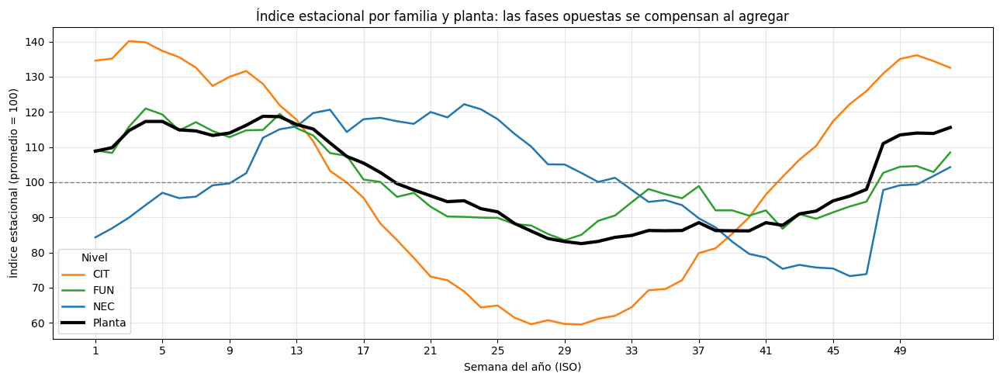

Amplitud estacional por nivel (puntos del índice):


,indice_max,indice_min,amplitud
familia,,,
CIT,140.1,59.5,80.6
FUN,121.0,83.5,37.5
NEC,122.2,73.3,48.9
Planta,118.7,82.5,36.2


In [167]:
# ÍNDICE ESTACIONAL POR FAMILIA Y PLANTA (evidencia de la pista jerárquica)
# Índice = demanda promedio de cada semana del año / promedio anual × 100. Se suaviza con una media móvil de 5 semanas.
serie = train_final.copy()

familias_sem = serie.groupby(['familia', 'fecha_lunes', 'semana_iso'], as_index=False)['y_modelo'].sum()
planta_sem = serie.groupby(['fecha_lunes', 'semana_iso'], as_index=False)['y_modelo'].sum()
planta_sem['familia'] = 'Planta'

niveles = pd.concat([familias_sem, planta_sem], ignore_index=True)
niveles = niveles[niveles['semana_iso'] <= 52]

indice = niveles.groupby(['familia', 'semana_iso'])['y_modelo'].mean().reset_index()
indice['indice'] = indice.groupby('familia')['y_modelo'].transform(lambda x: 100 * x / x.mean())

# Media móvil circular de 5 semanas (la semana 52 conecta con la semana 1)
indice['indice_suavizado'] = indice.groupby('familia')['indice'].transform(
    lambda x: pd.concat([x.iloc[-2:], x, x.iloc[:2]]).rolling(5, center=True).mean().iloc[2:-2].to_numpy()
)

# Gráfico
estilos = {'CIT': ('tab:orange', 1.8), 'FUN': ('tab:green', 1.8), 'NEC': ('tab:blue', 1.8), 'Planta': ('black', 3)}

plt.figure(figsize=(13, 5))
for nivel, (color, grosor) in estilos.items():
    datos = indice[indice['familia'] == nivel]
    plt.plot(datos['semana_iso'], datos['indice_suavizado'], color=color, linewidth=grosor, label=nivel)

plt.axhline(100, color='grey', linestyle='--', linewidth=1)
plt.title('Índice estacional por familia y planta: las fases opuestas se compensan al agregar')
plt.xlabel('Semana del año (ISO)')
plt.ylabel('Índice estacional (promedio = 100)')
plt.xticks(range(1, 53, 4))
plt.legend(title='Nivel')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('indice_estacional_jerarquia.png', dpi=150, bbox_inches='tight')
plt.show()

# Amplitud estacional de cada nivel
amplitud = indice.groupby('familia').agg(
    indice_max=('indice_suavizado', 'max'),
    indice_min=('indice_suavizado', 'min')
)
amplitud['amplitud'] = amplitud['indice_max'] - amplitud['indice_min']

print('Amplitud estacional por nivel (puntos del índice):')
display(amplitud.round(1))

#Aplicar la estrategia Bottom-Up

In [168]:
# PRONÓSTICO FINAL A NIVEL SKU - BOTTOM-UP

# Los pronósticos base de cada SKU constituyen
# el nivel inferior de la reconciliación Bottom-Up
pronostico_final_sku = (
    pronostico_base_final
    .copy()
)

pronostico_final_sku["estrategia_jerarquica"] = "Bottom-up"

# Comprobar resultados
print(
    "Filas:",
    len(pronostico_final_sku)
)

display(
    pronostico_final_sku.head().round(2)
)

Filas: 117


,sku,fecha_lunes,horizonte,modelo_final,pronostico,lo80,hi80,lo95,hi95,estrategia_jerarquica
0,CIT-L05,2026-09-28,1,SeasonalNaive,1392.00,455.01,2328.99,0.00,2825.00,Bottom-up
1,CIT-L15,2026-09-28,1,SeasonalNaive,1837.00,861.20,2812.80,344.65,3329.35,Bottom-up
2,CIT-L30,2026-09-28,1,SeasonalNaive,372.00,223.38,520.62,144.71,599.29,Bottom-up
3,FUN-B05,2026-09-28,1,ETS,2210.60,1622.06,2799.14,1310.50,3110.69,Bottom-up
4,FUN-B15,2026-09-28,1,ETS,1422.12,925.23,1919.01,662.20,2182.04,Bottom-up


In [169]:
# AGREGAR FAMILIA AL PRONÓSTICO FINAL POR SKU

pronostico_final_sku["familia"] = (
    pronostico_final_sku["sku"]
    .map(mapa_familia)
)

# Revisar que cada SKU tenga su familia correctamente asignada
display(
    pronostico_final_sku[
        [
            "sku",
            "familia",
            "fecha_lunes",
            "horizonte",
            "modelo_final",
            "pronostico"
        ]
    ].head(15).round(2)
)

print(
    "Familias faltantes:",
    pronostico_final_sku["familia"]
    .isna()
    .sum()
)

,sku,familia,fecha_lunes,horizonte,modelo_final,pronostico
0,CIT-L05,CIT,2026-09-28,1,SeasonalNaive,1392.00
1,CIT-L15,CIT,2026-09-28,1,SeasonalNaive,1837.00
2,CIT-L30,CIT,2026-09-28,1,SeasonalNaive,372.00
3,FUN-B05,FUN,2026-09-28,1,ETS,2210.60
4,FUN-B15,FUN,2026-09-28,1,ETS,1422.12
5,FUN-B30,FUN,2026-09-28,1,ETS,192.74
6,NEC-D05,NEC,2026-09-28,1,ETS,1314.03
7,NEC-D15,NEC,2026-09-28,1,SARIMA,2813.73
8,NEC-D30,NEC,2026-09-28,1,Naive,511.00
9,CIT-L05,CIT,2026-10-05,2,SeasonalNaive,1753.00


Familias faltantes: 0


In [170]:
# PRONÓSTICO RECONCILIADO POR FAMILIA

# Sumar los pronósticos de los SKU pertenecientes a cada familia
pronostico_final_familia = (
    pronostico_final_sku
    .groupby(
        [
            "fecha_lunes",
            "horizonte",
            "familia"
        ],
        as_index=False
    )
    .agg(
        pronostico=(
            "pronostico",
            "sum"
        )
    )
)

pronostico_final_familia[
    "estrategia_jerarquica"
] = "Bottom-up"

# Revisar resultados
display(
    pronostico_final_familia.round(2)
)

print(
    "Filas familia:",
    len(pronostico_final_familia)
)

,fecha_lunes,horizonte,familia,pronostico,estrategia_jerarquica
0,2026-09-28,1,CIT,3601.00,Bottom-up
1,2026-09-28,1,FUN,3825.45,Bottom-up
2,2026-09-28,1,NEC,4638.76,Bottom-up
3,2026-10-05,2,CIT,5012.00,Bottom-up
4,2026-10-05,2,FUN,3847.70,Bottom-up
5,2026-10-05,2,NEC,4565.75,Bottom-up
6,2026-10-12,3,CIT,4572.00,Bottom-up
7,2026-10-12,3,FUN,3865.50,Bottom-up
8,2026-10-12,3,NEC,4510.64,Bottom-up
9,2026-10-19,4,CIT,4323.00,Bottom-up


Filas familia: 39


In [171]:
# PRONÓSTICO RECONCILIADO DE PLANTA

# Sumar los pronósticos de todos los SKU para obtener el total de planta
pronostico_final_planta = (
    pronostico_final_sku
    .groupby(
        [
            "fecha_lunes",
            "horizonte"
        ],
        as_index=False
    )
    .agg(
        pronostico=(
            "pronostico",
            "sum"
        )
    )
)

pronostico_final_planta["nivel"] = "Planta"

pronostico_final_planta[
    "estrategia_jerarquica"
] = "Bottom-up"

# Revisar resultados
display(
    pronostico_final_planta.round(2)
)

print(
    "Filas planta:",
    len(pronostico_final_planta)
)

,fecha_lunes,horizonte,pronostico,nivel,estrategia_jerarquica
0,2026-09-28,1,12065.21,Planta,Bottom-up
1,2026-10-05,2,13425.45,Planta,Bottom-up
2,2026-10-12,3,12948.14,Planta,Bottom-up
3,2026-10-19,4,12665.36,Planta,Bottom-up
4,2026-10-26,5,13643.90,Planta,Bottom-up
5,2026-11-02,6,13959.53,Planta,Bottom-up
6,2026-11-09,7,15231.03,Planta,Bottom-up
7,2026-11-16,8,14072.15,Planta,Bottom-up
8,2026-11-23,9,13627.67,Planta,Bottom-up
9,2026-11-30,10,14502.35,Planta,Bottom-up


Filas planta: 13


In [172]:
# VERIFICAR COHERENCIA DEL PRONÓSTICO FINAL

suma_sku = (
    pronostico_final_sku
    .groupby(
        [
            "fecha_lunes",
            "horizonte"
        ]
    )["pronostico"]
    .sum()
)

suma_familia = (
    pronostico_final_familia
    .groupby(
        [
            "fecha_lunes",
            "horizonte"
        ]
    )["pronostico"]
    .sum()
)

planta = (
    pronostico_final_planta
    .set_index(
        [
            "fecha_lunes",
            "horizonte"
        ]
    )["pronostico"]
)

print(
    "SKU = Planta:",
    np.allclose(
        suma_sku,
        planta
    )
)

print(
    "Familia = Planta:",
    np.allclose(
        suma_familia,
        planta
    )
)

SKU = Planta: True
Familia = Planta: True


,fecha_lunes,horizonte,sku,familia,modelo_final,pronostico,lo80,hi80,lo95,hi95
0,2026-09-28,1,CIT-L05,CIT,SeasonalNaive,1392.00,455.01,2328.99,0.00,2825.00
1,2026-09-28,1,CIT-L15,CIT,SeasonalNaive,1837.00,861.20,2812.80,344.65,3329.35
2,2026-09-28,1,CIT-L30,CIT,SeasonalNaive,372.00,223.38,520.62,144.71,599.29
3,2026-09-28,1,FUN-B05,FUN,ETS,2210.60,1622.06,2799.14,1310.50,3110.69
4,2026-09-28,1,FUN-B15,FUN,ETS,1422.12,925.23,1919.01,662.20,2182.04
...,...,...,...,...,...,...,...,...,...,...
112,2026-12-21,13,FUN-B15,FUN,ETS,1422.12,773.83,2070.41,430.65,2413.59
113,2026-12-21,13,FUN-B30,FUN,ETS,192.74,0.00,482.74,0.00,636.27
114,2026-12-21,13,NEC-D05,NEC,ETS,916.30,266.41,1566.20,0.00,1910.24
115,2026-12-21,13,NEC-D15,NEC,SARIMA,2803.94,760.22,4847.66,0.00,5929.54


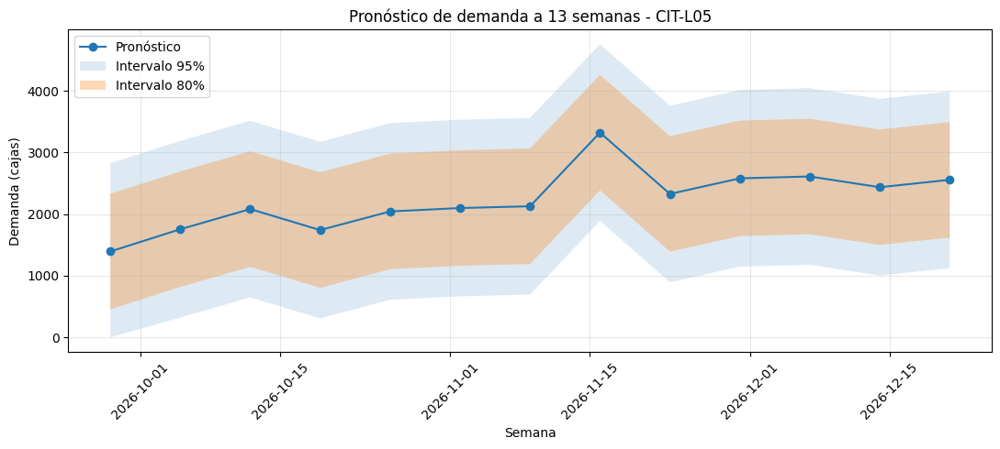

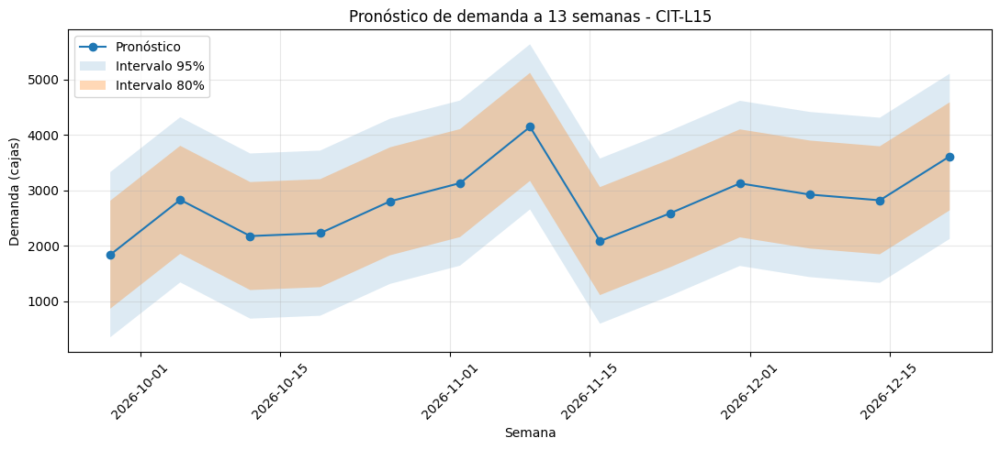

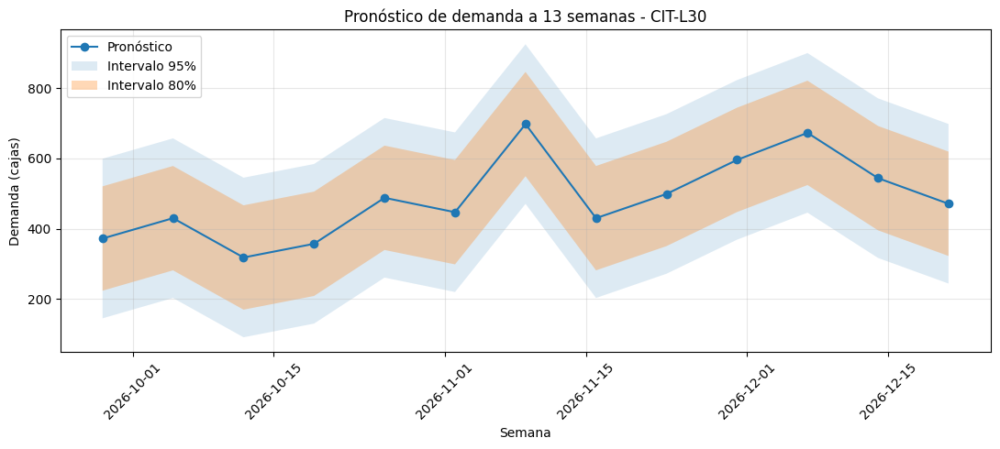

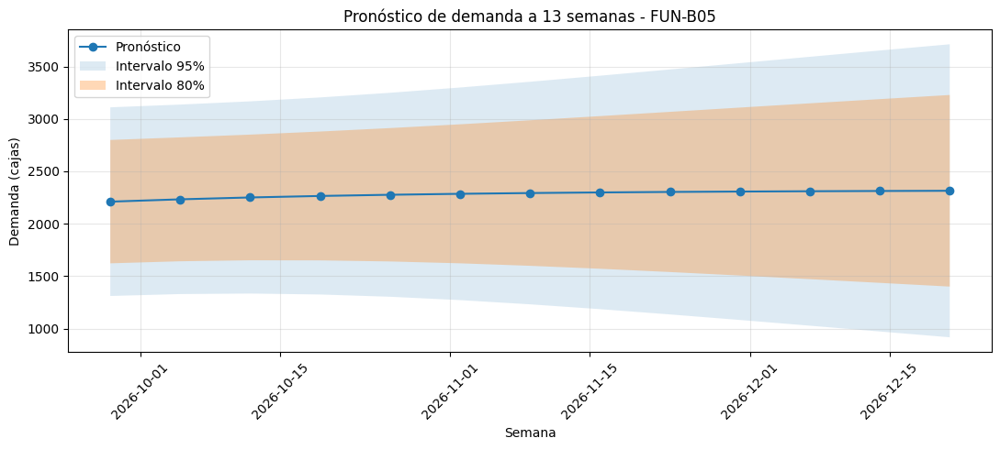

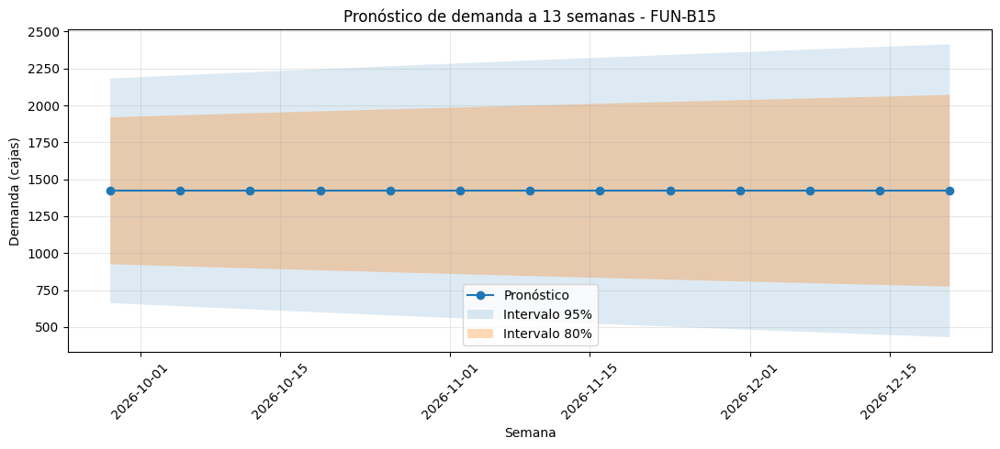

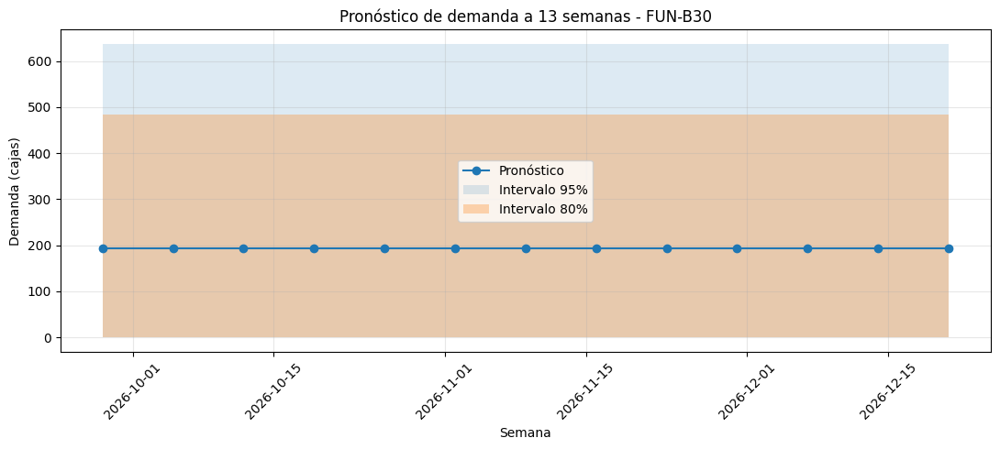

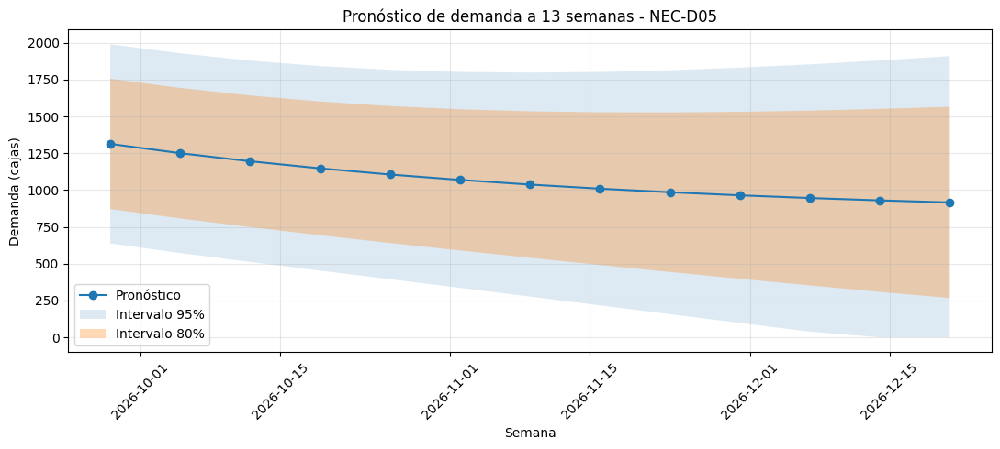

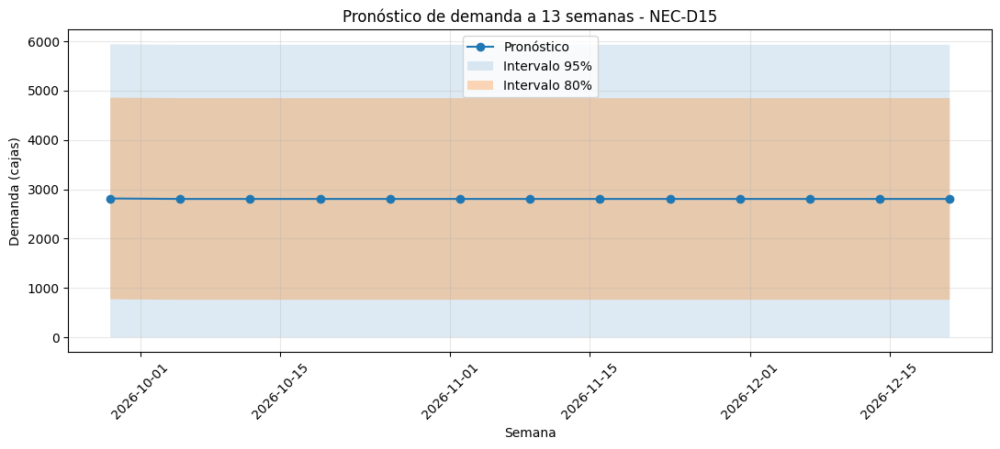

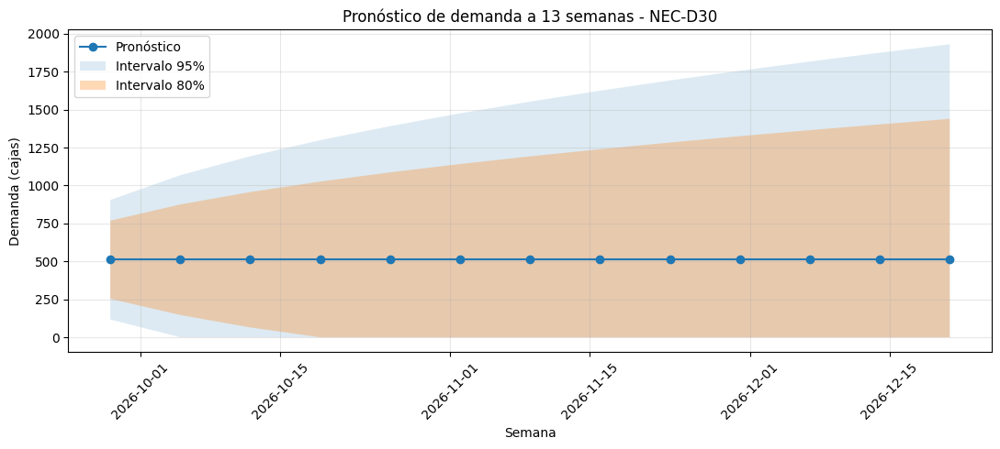

In [173]:
# TABLA FINAL DE PRONÓSTICOS POR SKU

tabla_final_sku = (
    pronostico_final_sku[
        [
            "fecha_lunes",
            "horizonte",
            "sku",
            "familia",
            "modelo_final",
            "pronostico",
            "lo80",
            "hi80",
            "lo95",
            "hi95"
        ]
    ]
    .sort_values(
        [
            "fecha_lunes",
            "sku"
        ]
    )
    .reset_index(drop=True)
)

display(
    tabla_final_sku.round(2)
)


for sku in tabla_final_sku['sku'].unique():

    datos = tabla_final_sku[
        tabla_final_sku['sku'] == sku
    ].sort_values('fecha_lunes')

    plt.figure(figsize=(11, 5))

    plt.plot(
        datos['fecha_lunes'],
        datos['pronostico'],
        marker='o',
        label='Pronóstico'
    )

    plt.fill_between(
        datos['fecha_lunes'],
        datos['lo95'],
        datos['hi95'],
        alpha=0.15,
        label='Intervalo 95%'
    )

    plt.fill_between(
        datos['fecha_lunes'],
        datos['lo80'],
        datos['hi80'],
        alpha=0.30,
        label='Intervalo 80%'
    )

    plt.title(f'Pronóstico de demanda a 13 semanas - {sku}')
    plt.xlabel('Semana')
    plt.ylabel('Demanda (cajas)')
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [174]:
# TABLA ANCHA DE PRONÓSTICOS POR SKU

tabla_sku_ancha = (
    pronostico_final_sku
    .pivot(
        index="fecha_lunes",
        columns="sku",
        values="pronostico"
    )
)

tabla_sku_ancha.columns.name = None

display(
    tabla_sku_ancha.round(1)
)

,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
fecha_lunes,,,,,,,,,
2026-09-28,1392.0,1837.0,372.0,2210.6,1422.1,192.7,1314.0,2813.7,511.0
2026-10-05,1753.0,2829.0,430.0,2232.8,1422.1,192.7,1250.8,2803.9,511.0
2026-10-12,2080.0,2174.0,318.0,2250.6,1422.1,192.7,1195.7,2803.9,511.0
2026-10-19,1740.0,2226.0,357.0,2264.9,1422.1,192.7,1147.7,2803.9,511.0
2026-10-26,2042.0,2802.0,488.0,2276.3,1422.1,192.7,1105.8,2803.9,511.0
2026-11-02,2097.0,3131.0,447.0,2285.4,1422.1,192.7,1069.3,2803.9,511.0
2026-11-09,2126.0,4147.0,698.0,2292.7,1422.1,192.7,1037.5,2803.9,511.0
2026-11-16,3321.0,2083.0,430.0,2298.6,1422.1,192.7,1009.8,2803.9,511.0
2026-11-23,2326.0,2584.0,499.0,2303.2,1422.1,192.7,985.7,2803.9,511.0


In [175]:
# TABLA ANCHA DE PRONÓSTICOS POR FAMILIA

tabla_familia_ancha = (
    pronostico_final_familia
    .pivot(
        index="fecha_lunes",
        columns="familia",
        values="pronostico"
    )
)

tabla_familia_ancha.columns.name = None

display(
    tabla_familia_ancha.round(1)
)

,CIT,FUN,NEC
fecha_lunes,,,
2026-09-28,3601.0,3825.5,4638.8
2026-10-05,5012.0,3847.7,4565.7
2026-10-12,4572.0,3865.5,4510.6
2026-10-19,4323.0,3879.7,4462.6
2026-10-26,5332.0,3891.1,4420.8
2026-11-02,5675.0,3900.3,4384.3
2026-11-09,6971.0,3907.6,4352.5
2026-11-16,5834.0,3913.4,4324.7
2026-11-23,5409.0,3918.1,4300.6


In [176]:
# TABLA FINAL DE PRONÓSTICO DE PLANTA

tabla_planta = (
    pronostico_final_planta[
        [
            "fecha_lunes",
            "horizonte",
            "pronostico"
        ]
    ]
    .copy()
)

display(
    tabla_planta.round(1)
)

,fecha_lunes,horizonte,pronostico
0,2026-09-28,1,12065.2
1,2026-10-05,2,13425.4
2,2026-10-12,3,12948.1
3,2026-10-19,4,12665.4
4,2026-10-26,5,13643.9
5,2026-11-02,6,13959.5
6,2026-11-09,7,15231.0
7,2026-11-16,8,14072.2
8,2026-11-23,9,13627.7
9,2026-11-30,10,14502.4


In [177]:
# COMPROBACIONES FINALES

print(
    "SKU:",
    len(pronostico_final_sku)
)

print(
    "Familia:",
    len(pronostico_final_familia)
)

print(
    "Planta:",
    len(pronostico_final_planta)
)

print(
    "\nNaN pronóstico SKU:",
    pronostico_final_sku[
        "pronostico"
    ].isna().sum()
)

print(
    "Pronósticos SKU negativos:",
    (
        pronostico_final_sku[
            "pronostico"
        ] < 0
    ).sum()
)

print(
    "\nCoherencia SKU-Planta:",
    np.allclose(
        suma_sku,
        planta
    )
)

print(
    "Coherencia Familia-Planta:",
    np.allclose(
        suma_familia,
        planta
    )
)

SKU: 117
Familia: 39
Planta: 13

NaN pronóstico SKU: 0
Pronósticos SKU negativos: 0

Coherencia SKU-Planta: True
Coherencia Familia-Planta: True


# Parte C: Parámetros para la Entrega 2


In [178]:

# PARTE C: PARÁMETROS PARA LA ENTREGA 2

# 1. Merma efectiva por línea (rho = p barra de las 10 semanas, derivada de la carta p)
merma = calidad_atributos.groupby('linea')[['n_defectuosas', 'n_inspeccionadas']].sum()
merma['rho_observada'] = merma['n_defectuosas'] / merma['n_inspeccionadas']
print("--- MERMA EFECTIVA POR LÍNEA ---")
display(merma.reset_index())

# 2. Costo anual de la merma: para vender x botellas hay que producir x/(1-rho),
#    es decir, se desechan x*rho/(1-rho) botellas, valoradas a costo variable
costo_merma = ventas_anuales.merge(maestro_sku[['sku', 'costo_variable_caja_clp']], on='sku')
costo_merma['rho'] = costo_merma['linea'].map(merma['rho_observada'])
costo_merma['costo_por_botella'] = costo_merma['costo_variable_caja_clp'] / costo_merma['botellas_por_caja']
costo_merma['botellas_desechadas'] = costo_merma['volumen_anual_botellas'] * costo_merma['rho'] / (1 - costo_merma['rho'])
costo_merma['costo_merma_CLP'] = costo_merma['botellas_desechadas'] * costo_merma['costo_por_botella']
print("\n--- COSTO ANUAL DE LA MERMA ---")
display(costo_merma.groupby('linea')[['botellas_desechadas', 'costo_merma_CLP']].sum())
print(f"Costo total de la merma: ${costo_merma['costo_merma_CLP'].sum():,.0f} CLP/Año")

# 3. Tabla de traspaso a la Entrega 2
traspaso = medias_reales[['linea', 'formato_L']].copy()
traspaso['sobrellenado_mL_botella'] = medias_reales['Media actual'] - medias_reales['formato_L'] * 1000
traspaso = traspaso.merge(maestro_sku.groupby('formato_L')['botellas_por_caja'].first().reset_index(), on='formato_L')
traspaso['litros_jarabe_extra_por_caja'] = traspaso['sobrellenado_mL_botella'] * traspaso['botellas_por_caja'] / 1000
traspaso['rho_merma_linea'] = traspaso['linea'].map(merma['rho_observada'])
print("\n--- TABLA DE TRASPASO A LA ENTREGA 2 ---")
display(traspaso)


--- MERMA EFECTIVA POR LÍNEA ---


,linea,n_defectuosas,n_inspeccionadas,rho_observada
0,L1,248,12905,0.019217
1,L2,1027,32974,0.031146



--- COSTO ANUAL DE LA MERMA ---


,botellas_desechadas,costo_merma_CLP
linea,,
L1,72981.401596,2.389033e+07
L2,74706.012333,7.725627e+07


Costo total de la merma: $101,146,601 CLP/Año

--- TABLA DE TRASPASO A LA ENTREGA 2 ---


,linea,formato_L,sobrellenado_mL_botella,botellas_por_caja,litros_jarabe_extra_por_caja,rho_merma_linea
0,L1,0.5,5.719767,12,0.068637,0.019217
1,L2,1.5,4.601062,6,0.027606,0.031146
2,L2,3.0,8.501160,4,0.034005,0.031146


In [179]:
pronostico_final_sku.head(120)

,sku,fecha_lunes,horizonte,modelo_final,pronostico,lo80,hi80,lo95,hi95,estrategia_jerarquica,familia
0,CIT-L05,2026-09-28,1,SeasonalNaive,1392.000000,455.008648,2328.991352,0.000000,2825.004612,Bottom-up,CIT
1,CIT-L15,2026-09-28,1,SeasonalNaive,1837.000000,861.202542,2812.797458,344.646570,3329.353430,Bottom-up,CIT
2,CIT-L30,2026-09-28,1,SeasonalNaive,372.000000,223.383759,520.616241,144.711073,599.288927,Bottom-up,CIT
3,FUN-B05,2026-09-28,1,ETS,2210.597175,1622.055685,2799.138665,1310.500639,3110.693711,Bottom-up,FUN
4,FUN-B15,2026-09-28,1,ETS,1422.118678,925.232326,1919.005031,662.196580,2182.040777,Bottom-up,FUN
...,...,...,...,...,...,...,...,...,...,...,...
112,FUN-B15,2026-12-21,13,ETS,1422.118678,773.831487,2070.405870,430.648978,2413.588379,Bottom-up,FUN
113,FUN-B30,2026-12-21,13,ETS,192.735077,0.000000,482.744366,0.000000,636.266010,Bottom-up,FUN
114,NEC-D05,2026-12-21,13,ETS,916.304554,266.405482,1566.203627,0.000000,1910.239414,Bottom-up,NEC
115,NEC-D15,2026-12-21,13,SARIMA,2803.937730,760.219099,4847.656360,0.000000,5929.535651,Bottom-up,NEC


In [180]:
# DESVIACIÓN ESTÁNDAR DEL ERROR DE PRONÓSTICO

# Obtener los errores del modelo seleccionado por SKU
errores_finales = pred_sku_seleccionado[
    ['fold', 'sku', 'fecha_lunes', 'horizonte', 'y_real', 'y_pred']
].copy()

# Error positivo: sobreestimación; negativo: subestimación
errores_finales['error'] = errores_finales['y_pred'] - errores_finales['y_real']

display(errores_finales.head())

print('\n'*3, '='*100)


# Calcular la desviación estándar del error por SKU y horizonte
sigma_sku_h = errores_finales.groupby(['sku', 'horizonte']).agg(
    sigma_error=('error', 'std'),
    error_medio=('error', 'mean'),
    n=('error', 'size')
).reset_index()

display(sigma_sku_h.round(2))

print('\n'*3, '='*100)


# Comprobar las estimaciones
print("Cantidad de filas:", len(sigma_sku_h))
print("Observaciones por estimación:")
display(sigma_sku_h['n'].value_counts().sort_index())

print("Sigma faltantes:", sigma_sku_h['sigma_error'].isna().sum())
print("Sigma negativas:", (sigma_sku_h['sigma_error'] < 0).sum())

print('\n'*3, '='*100)


# Mostrar la desviación estándar por SKU y horizonte
tabla_sigma = sigma_sku_h.pivot(
    index='horizonte',
    columns='sku',
    values='sigma_error'
)

tabla_sigma.columns.name = None

display(tabla_sigma.round(2))

print('\n'*3, '='*100)


# Incorporar la desviación estándar al pronóstico final
# Evitar duplicar la columna si se vuelve a ejecutar este bloque
pronostico_final_sku = pronostico_final_sku.drop(
    columns=['sigma_error'],
    errors='ignore'
)

pronostico_final_sku = pronostico_final_sku.merge(
    sigma_sku_h[['sku', 'horizonte', 'sigma_error']],
    on=['sku', 'horizonte'],
    how='left',
    validate='one_to_one'
)

display(pronostico_final_sku.head(20).round(2))

print('\n'*3, '='*100)




,fold,sku,fecha_lunes,horizonte,y_real,y_pred,error
0,1,CIT-L05,2025-10-27,1,2042.0,2063.0,21.0
1,1,CIT-L05,2025-11-03,2,2097.0,2713.0,616.0
2,1,CIT-L05,2025-11-10,3,2126.0,2102.0,-24.0
3,1,CIT-L05,2025-11-17,4,3321.0,2916.0,-405.0
4,1,CIT-L05,2025-11-24,5,2326.0,2729.0,403.0


,sku,horizonte,sigma_error,error_medio,n
0,CIT-L05,1,912.03,320.50,8
1,CIT-L05,2,419.15,19.38,8
2,CIT-L05,3,228.61,-140.00,8
3,CIT-L05,4,645.23,57.00,8
4,CIT-L05,5,468.36,-188.00,8
...,...,...,...,...,...
112,NEC-D30,9,169.83,-45.25,8
113,NEC-D30,10,173.68,6.88,8
114,NEC-D30,11,133.93,-13.88,8
115,NEC-D30,12,258.25,-50.50,8





Cantidad de filas: 117
Observaciones por estimación:


,count
n,
8,117


Sigma faltantes: 0
Sigma negativas: 0





,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
horizonte,,,,,,,,,
1,912.03,679.52,81.28,365.45,383.35,229.44,98.57,890.84,101.80
2,419.15,718.46,152.48,676.73,823.13,482.97,448.49,1351.94,232.36
3,228.61,988.22,113.15,347.21,221.39,320.93,275.69,614.21,162.90
4,645.23,798.54,130.12,646.54,700.59,228.71,415.41,643.63,158.68
5,468.36,431.45,83.62,679.25,526.33,219.42,659.98,613.84,141.31
6,922.92,572.24,81.89,445.43,312.38,204.62,208.47,895.55,127.59
7,353.05,436.48,145.43,690.70,799.59,455.85,418.61,1366.88,144.25
8,233.27,746.70,73.93,562.07,402.53,341.48,481.63,629.88,204.89
9,628.04,939.67,102.96,543.76,794.98,232.55,578.15,519.96,169.83


,sku,fecha_lunes,horizonte,modelo_final,pronostico,lo80,hi80,lo95,hi95,estrategia_jerarquica,familia,sigma_error
0,CIT-L05,2026-09-28,1,SeasonalNaive,1392.00,455.01,2328.99,0.00,2825.00,Bottom-up,CIT,912.03
1,CIT-L15,2026-09-28,1,SeasonalNaive,1837.00,861.20,2812.80,344.65,3329.35,Bottom-up,CIT,679.52
2,CIT-L30,2026-09-28,1,SeasonalNaive,372.00,223.38,520.62,144.71,599.29,Bottom-up,CIT,81.28
3,FUN-B05,2026-09-28,1,ETS,2210.60,1622.06,2799.14,1310.50,3110.69,Bottom-up,FUN,365.45
4,FUN-B15,2026-09-28,1,ETS,1422.12,925.23,1919.01,662.20,2182.04,Bottom-up,FUN,383.35
5,FUN-B30,2026-09-28,1,ETS,192.74,0.00,482.74,0.00,636.27,Bottom-up,FUN,229.44
6,NEC-D05,2026-09-28,1,ETS,1314.03,871.58,1756.48,637.37,1990.70,Bottom-up,NEC,98.57
7,NEC-D15,2026-09-28,1,SARIMA,2813.73,770.27,4857.18,0.00,5938.92,Bottom-up,NEC,890.84
8,NEC-D30,2026-09-28,1,Naive,511.00,253.53,768.47,117.24,904.76,Bottom-up,NEC,101.80
9,CIT-L05,2026-10-05,2,SeasonalNaive,1753.00,816.01,2689.99,320.00,3186.00,Bottom-up,CIT,419.15


In [181]:
# Construir la tabla de traspaso hacia la Entrega 2
tabla_traspaso_pronostico = pronostico_final_sku[
    ['sku', 'familia', 'fecha_lunes', 'horizonte',
     'modelo_final', 'pronostico', 'sigma_error']
].copy()

tabla_traspaso_pronostico = tabla_traspaso_pronostico.rename(
    columns={
        'pronostico': 'demanda_pronosticada',
        'sigma_error': 'sigma_error_pronostico'
    }
)

tabla_traspaso_pronostico = tabla_traspaso_pronostico.sort_values(
    ['sku', 'horizonte']
).reset_index(drop=True)

print("TABLA DE TRASPASO A LA ENTREGA 2 - PRONÓSTICO")
display(tabla_traspaso_pronostico.round(2))

print('\n'*3, '='*100)


# Comprobaciones finales
print("Filas:", len(tabla_traspaso_pronostico))
print("SKU:", tabla_traspaso_pronostico['sku'].nunique())
print("Horizontes:", tabla_traspaso_pronostico['horizonte'].nunique())
print("NaN demanda:", tabla_traspaso_pronostico['demanda_pronosticada'].isna().sum())
print("NaN sigma:", tabla_traspaso_pronostico['sigma_error_pronostico'].isna().sum())

assert len(tabla_traspaso_pronostico) == 117
assert not tabla_traspaso_pronostico.duplicated(['sku', 'horizonte']).any()
assert tabla_traspaso_pronostico[
    ['demanda_pronosticada', 'sigma_error_pronostico']
].notna().all().all()

print("Tabla de traspaso validada.")

TABLA DE TRASPASO A LA ENTREGA 2 - PRONÓSTICO


,sku,familia,fecha_lunes,horizonte,modelo_final,demanda_pronosticada,sigma_error_pronostico
0,CIT-L05,CIT,2026-09-28,1,SeasonalNaive,1392.0,912.03
1,CIT-L05,CIT,2026-10-05,2,SeasonalNaive,1753.0,419.15
2,CIT-L05,CIT,2026-10-12,3,SeasonalNaive,2080.0,228.61
3,CIT-L05,CIT,2026-10-19,4,SeasonalNaive,1740.0,645.23
4,CIT-L05,CIT,2026-10-26,5,SeasonalNaive,2042.0,468.36
...,...,...,...,...,...,...,...
112,NEC-D30,NEC,2026-11-23,9,Naive,511.0,169.83
113,NEC-D30,NEC,2026-11-30,10,Naive,511.0,173.68
114,NEC-D30,NEC,2026-12-07,11,Naive,511.0,133.93
115,NEC-D30,NEC,2026-12-14,12,Naive,511.0,258.25





Filas: 117
SKU: 9
Horizontes: 13
NaN demanda: 0
NaN sigma: 0
Tabla de traspaso validada.


In [182]:
# TABLA DEFINITIVA DE TRASPASO A LA ENTREGA 2

# 1. Obtener la línea y el formato correspondiente a cada SKU
datos_sku = maestro_sku[
    ['sku', 'linea_envasado', 'formato_L']
].drop_duplicates().copy()

# Unificar el nombre de la columna para realizar el cruce
datos_sku = datos_sku.rename(
    columns={'linea_envasado': 'linea'}
)

# 2. Incorporar los datos productivos a cada SKU
parametros_calidad = datos_sku.merge(
    traspaso[
        ['linea', 'formato_L', 'sobrellenado_mL_botella',
         'litros_jarabe_extra_por_caja', 'rho_merma_linea']
    ],
    on=['linea', 'formato_L'],
    how='left',
    validate='many_to_one'
)

# 3. Unir los parámetros de calidad y pronóstico
tabla_traspaso_definitiva = tabla_traspaso_pronostico.merge(
    parametros_calidad,
    on='sku',
    how='left',
    validate='many_to_one'
)

# 4. Ordenar las columnas
tabla_traspaso_definitiva = tabla_traspaso_definitiva[
    [
        'sku',
        'familia',
        'linea',
        'formato_L',
        'fecha_lunes',
        'horizonte',
        'modelo_final',
        'demanda_pronosticada',
        'sigma_error_pronostico',
        'rho_merma_linea',
        'sobrellenado_mL_botella',
        'litros_jarabe_extra_por_caja'
    ]
].sort_values(
    ['sku', 'horizonte']
).reset_index(drop=True)

print("\n--- TABLA DEFINITIVA DE TRASPASO A LA ENTREGA 2 ---")
display(tabla_traspaso_definitiva.round(4))

print('\n'*3, '='*100)

# 5. Comprobaciones finales
print("Filas:", len(tabla_traspaso_definitiva))
print("SKU:", tabla_traspaso_definitiva['sku'].nunique())
print("Horizontes:", tabla_traspaso_definitiva['horizonte'].nunique())
print("Valores faltantes:", tabla_traspaso_definitiva.isna().sum().sum())

assert len(tabla_traspaso_definitiva) == 117

assert not tabla_traspaso_definitiva.duplicated(
    ['sku', 'horizonte']
).any()

assert tabla_traspaso_definitiva.notna().all().all()

assert tabla_traspaso_definitiva.groupby(
    'sku'
)['horizonte'].nunique().eq(13).all()

assert tabla_traspaso_definitiva['rho_merma_linea'].between(
    0, 1, inclusive='left'
).all()

assert (tabla_traspaso_definitiva[
    'sigma_error_pronostico'
] >= 0).all()

print("Tabla definitiva validada.")

# 6. Exportar resultados
tabla_traspaso_definitiva.to_csv(
    'tabla_traspaso_entrega2.csv',
    index=False
)


--- TABLA DEFINITIVA DE TRASPASO A LA ENTREGA 2 ---


,sku,familia,linea,formato_L,fecha_lunes,horizonte,modelo_final,demanda_pronosticada,sigma_error_pronostico,rho_merma_linea,sobrellenado_mL_botella,litros_jarabe_extra_por_caja
0,CIT-L05,CIT,L1,0.5,2026-09-28,1,SeasonalNaive,1392.0,912.0318,0.0192,5.7198,0.0686
1,CIT-L05,CIT,L1,0.5,2026-10-05,2,SeasonalNaive,1753.0,419.1512,0.0192,5.7198,0.0686
2,CIT-L05,CIT,L1,0.5,2026-10-12,3,SeasonalNaive,2080.0,228.6088,0.0192,5.7198,0.0686
3,CIT-L05,CIT,L1,0.5,2026-10-19,4,SeasonalNaive,1740.0,645.2326,0.0192,5.7198,0.0686
4,CIT-L05,CIT,L1,0.5,2026-10-26,5,SeasonalNaive,2042.0,468.3625,0.0192,5.7198,0.0686
...,...,...,...,...,...,...,...,...,...,...,...,...
112,NEC-D30,NEC,L2,3.0,2026-11-23,9,Naive,511.0,169.8308,0.0311,8.5012,0.0340
113,NEC-D30,NEC,L2,3.0,2026-11-30,10,Naive,511.0,173.6782,0.0311,8.5012,0.0340
114,NEC-D30,NEC,L2,3.0,2026-12-07,11,Naive,511.0,133.9322,0.0311,8.5012,0.0340
115,NEC-D30,NEC,L2,3.0,2026-12-14,12,Naive,511.0,258.2540,0.0311,8.5012,0.0340





Filas: 117
SKU: 9
Horizontes: 13
Valores faltantes: 0
Tabla definitiva validada.


In [183]:
tabla_traspaso_definitiva.head(117)

,sku,familia,linea,formato_L,fecha_lunes,horizonte,modelo_final,demanda_pronosticada,sigma_error_pronostico,rho_merma_linea,sobrellenado_mL_botella,litros_jarabe_extra_por_caja
0,CIT-L05,CIT,L1,0.5,2026-09-28,1,SeasonalNaive,1392.0,912.031798,0.019217,5.719767,0.068637
1,CIT-L05,CIT,L1,0.5,2026-10-05,2,SeasonalNaive,1753.0,419.151162,0.019217,5.719767,0.068637
2,CIT-L05,CIT,L1,0.5,2026-10-12,3,SeasonalNaive,2080.0,228.608836,0.019217,5.719767,0.068637
3,CIT-L05,CIT,L1,0.5,2026-10-19,4,SeasonalNaive,1740.0,645.232627,0.019217,5.719767,0.068637
4,CIT-L05,CIT,L1,0.5,2026-10-26,5,SeasonalNaive,2042.0,468.362497,0.019217,5.719767,0.068637
...,...,...,...,...,...,...,...,...,...,...,...,...
112,NEC-D30,NEC,L2,3.0,2026-11-23,9,Naive,511.0,169.830798,0.031146,8.501160,0.034005
113,NEC-D30,NEC,L2,3.0,2026-11-30,10,Naive,511.0,173.678223,0.031146,8.501160,0.034005
114,NEC-D30,NEC,L2,3.0,2026-12-07,11,Naive,511.0,133.932219,0.031146,8.501160,0.034005
115,NEC-D30,NEC,L2,3.0,2026-12-14,12,Naive,511.0,258.254028,0.031146,8.501160,0.034005


#Exportar Tabla de resultados y descargar.

In [184]:
import os

# Crear carpeta de resultados
os.makedirs("Entrega1Resultado", exist_ok=True)

# Definir rutas
ruta_excel = "Entrega1Resultado/tabla_traspaso_entrega2.xlsx"
ruta_csv = "Entrega1Resultado/tabla_traspaso_entrega2.csv"

# Exportar Excel
tabla_traspaso_definitiva.to_excel(
    ruta_excel,
    index=False
)

# Exportar CSV
tabla_traspaso_definitiva.to_csv(
    ruta_csv,
    index=False,
    encoding="utf-8-sig"
)

print("Archivos generados correctamente en Entrega1Resultado/")

# Descarga automática únicamente en Google Colab
try:
    from google.colab import files

    files.download(ruta_excel)
    files.download(ruta_csv)

except ImportError:
    print("Archivos guardados localmente. Descarga automática no disponible fuera de Colab.")

Archivos generados correctamente en Entrega1Resultado/


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>